In [ ]:

# ============================================================
# CRDL C3-03 — DRIVE MOUNT REPAIR & PATH VERIFICATION
# READ-ONLY: DOES NOT CREATE OR MODIFY RESEARCH DATA
# ============================================================

from google.colab import drive
from pathlib import Path

# Refresh Colab's connection to Google Drive.
drive.mount("/content/drive", force_remount=True)

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

BATCH = PROJECT / (
    "04_geometry_targets/"
    "C3-02_section04_BATCH_20261020T064109_316286Z"
)

HANDOFF = PROJECT / (
    "04_geometry_targets/"
    "C3-02_section05_HANDOFF_20261020T065059_185606Z"
)

CHECKPOINT_ROOT = PROJECT / "06_model_checkpoints"
TRAINING_ROOT = PROJECT / "05_training_runs"

print("\nPROJECT EXISTS:", PROJECT.is_dir())
print("BATCH EXISTS:", BATCH.is_dir())
print("HANDOFF EXISTS:", HANDOFF.is_dir())
print("CHECKPOINT ROOT:", CHECKPOINT_ROOT.is_dir())
print("TRAINING ROOT:", TRAINING_ROOT.is_dir())

if PROJECT.is_dir():
    target_root = PROJECT / "04_geometry_targets"

    if target_root.is_dir():
        print("\nGeometry-target folders visible to Colab:")
        for p in sorted(target_root.iterdir()):
            if p.is_dir():
                print("  ", p.name)

if BATCH.is_dir():

    npz_folder = BATCH / "diagnostic_pass_npz"

    files = (
        list(npz_folder.glob("*.npz"))
        if npz_folder.is_dir()
        else []
    )

    print("\nSaved diagnostic NPZ files:", len(files))

    assert len(files) == 16, (
        "Expected 16 previously verified NPZ files"
    )

if HANDOFF.is_dir():
    assert (
        HANDOFF / "diagnostic_handoff_report.json"
    ).is_file()

print("\n" + "=" * 55)

if BATCH.is_dir() and HANDOFF.is_dir():
    print("DRIVE PATH REPAIR: SUCCESS")
    print("You can rerun C3-03 Section 1.")
else:
    print("DRIVE PATH REPAIR: STILL INCOMPLETE")
    print("Check the Google account used in Colab.")
    print("Do not create replacement folders.")

print("=" * 55)


Mounted at /content/drive

PROJECT EXISTS: True
BATCH EXISTS: True
HANDOFF EXISTS: True
CHECKPOINT ROOT: True
TRAINING ROOT: True

Geometry-target folders visible to Colab:
   C3-02_section03_PROTOTYPE_20261020T063328_275847Z
   C3-02_section04_BATCH_20261020T064109_316286Z
   C3-02_section05_HANDOFF_20261020T065059_185606Z
   C3-02_section11_PothRGBD_ReferenceQA_20261020T075404_802070Z
   C3-02_section14_PothRGBD_PILOT_20261020T081321_368363Z
   C3-02_section16_AFFINE_EXPANSION_20261020T082927_408953Z
   C3-04_section01_FAN_3D_REFERENCE_20261020T120546_737207Z

Saved diagnostic NPZ files: 16

DRIVE PATH REPAIR: SUCCESS
You can rerun C3-03 Section 1.


In [ ]:

# C3-05 environment setup
%pip install -q --upgrade "transformers==4.48.3" "huggingface_hub>=0.28,<1"


In [ ]:
import torch
import transformers

print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU fallback")

assert transformers.__version__ == "4.48.3"

print("ZoeDepth environment ready!")


Transformers: 4.48.3
PyTorch: 2.11.0+cpu
CUDA build: None
CUDA available: False
Using CPU fallback
ZoeDepth environment ready!


Research handoff verification: PASS
Source sample: dataset1/01
Training status: ENGINEERING SMOKE ONLY

PyTorch: 2.11.0+cpu
Training device: cpu
Smoke optimization steps: 45

Model input shape: (1, 5, 160, 160)
Reference target shape: (1, 1, 160, 160)
Valid supervised pixels: 2381
Physical target units: UNVERIFIED


/tmp/ipykernel_7904/3104790765.py:381: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(


Step 001/45 | masked SmoothL1: 0.84690
Step 010/45 | masked SmoothL1: 0.14235
Step 020/45 | masked SmoothL1: 0.12324
Step 030/45 | masked SmoothL1: 0.07389
Step 040/45 | masked SmoothL1: 0.10241
Step 045/45 | masked SmoothL1: 0.11133

TRAINING-ONLY RECONSTRUCTION CHECK
Initial masked MAE (normalized): 0.918761
Final masked MAE (normalized): 0.158085
Same-sample loss improved: True

Trained checkpoint saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-03_section01_SMOKE_20261020T124405_660575Z/model_smoke_only.pt
Fresh model load: PASS
Reloaded output equivalence: PASS


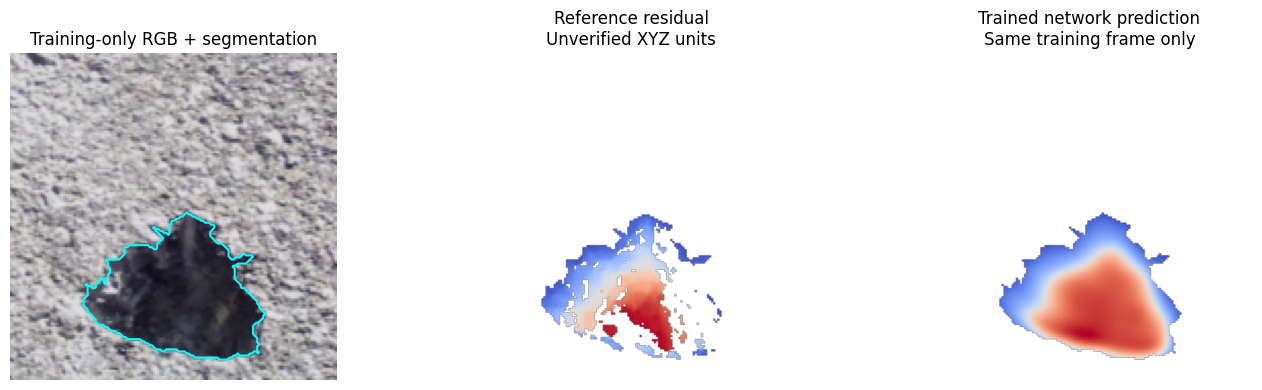


C3-03 SECTION 1 — TRAINED CRDL ENGINEERING SMOKE
Architecture: CRDLSmokeUNet
Device: cpu
Optimization steps: 45
Supervised frames: 1
Initial train-only MAE: 0.918761
Final train-only MAE: 0.158085
Same-sample optimization improved: True
Checkpoint loading: PASS
Independent validation performed: NO
Metric units verified: NO
Physical severity prediction: DISABLED
Backend release authorized: NO

Training run: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-03_section01_SMOKE_20261020T124405_660575Z
Model checkpoint: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-03_section01_SMOKE_20261020T124405_660575Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-03 SECTION 1
# SINGLE-FRAME NEURAL NETWORK OVERFITTING SMOKE TEST
# Version 1.0
#
# ENGINEERING SMOKE TEST ONLY
# No independent validation
# No metric depth claims
# No severity prediction
# No backend release
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image
import numpy as np
import torch
import torch.nn.functional as F
import hashlib
import json
import csv
import importlib.util
import matplotlib.pyplot as plt

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

FAN = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "fan_stereo_pothole/"
    "stereo_pothole_datasets-master"
)

BATCH = PROJECT / (
    "04_geometry_targets/"
    "C3-02_section04_BATCH_20261020T064109_316286Z"
)

HANDOFF = PROJECT / (
    "04_geometry_targets/"
    "C3-02_section05_HANDOFF_20261020T065059_185606Z"
)

for directory in [
    BATCH,
    HANDOFF,
    PROJECT / "05_training_runs",
    PROJECT / "06_model_checkpoints"
]:
    assert directory.is_dir(), str(directory)

# ------------------------------------------------------------
# 1. VERIFY RESEARCH HANDOFF AND SOURCE TARGET
# ------------------------------------------------------------

def digest(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


def verify(folder):
    entries = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        sha, name = line.split(None, 1)
        name = name.strip()
        p = Path(name)

        assert not p.is_absolute()
        assert ".." not in p.parts
        assert name not in entries

        assert (folder / p).is_file()
        assert digest(folder / p) == sha

        entries[name] = sha

    assert entries
    return entries


verify(HANDOFF)
batch_checks = verify(BATCH)

handoff_report = json.loads(
    (
        HANDOFF / "diagnostic_handoff_report.json"
    ).read_text()
)

assert handoff_report["verified_npz_count"] == 16

assert handoff_report[
    "engineering_smoke_test_possible"
] is True

assert handoff_report[
    "metric_model_training_authorized"
] is False

with (
    HANDOFF / "diagnostic_target_manifest.csv"
).open(newline="", encoding="utf-8") as f:
    manifest = list(csv.DictReader(f))

row = next(
    r for r in manifest
    if r["sample_id"] == "dataset1/01"
)

assert row["diagnostic_status"] == "DIAGNOSTIC_PASS"
assert row["npz_integrity"] == "PASS"
assert row["training_approved"].lower() == "false"
assert row["capture_group"] == "FAN_D1_ALL_FRAMES"

source_npz = BATCH / row["npz_path"]
assert row["npz_path"] in batch_checks

rgb_path = FAN / "dataset1/rgb/01.png"
assert rgb_path.is_file()

print("Research handoff verification: PASS")
print("Source sample: dataset1/01")
print("Training status: ENGINEERING SMOKE ONLY")

# ------------------------------------------------------------
# 2. DEFINE SAVABLE MODEL ARCHITECTURE + PREPROCESSING
# ------------------------------------------------------------

# We save exactly this source file with the checkpoint.
# The same code will be re-imported to test model loading.

ARCH_SOURCE = '''
import numpy as np
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, incoming, outgoing):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(incoming, outgoing, 3, padding=1),
            nn.GroupNorm(4, outgoing),
            nn.SiLU(),
            nn.Conv2d(outgoing, outgoing, 3, padding=1),
            nn.GroupNorm(4, outgoing),
            nn.SiLU()
        )

    def forward(self, x):
        return self.seq(x)


class CRDLSmokeUNet(nn.Module):
    def __init__(self, width=12):
        super().__init__()

        self.e1 = ConvBlock(5, width)
        self.e2 = ConvBlock(width, width * 2)
        self.b = ConvBlock(width * 2, width * 4)

        self.d2 = ConvBlock(width * 6, width * 2)
        self.d1 = ConvBlock(width * 3, width)

        self.out = nn.Conv2d(width, 1, 1)

    def forward(self, x):
        a = self.e1(x)
        b = self.e2(F.avg_pool2d(a, 2))

        c = self.b(F.avg_pool2d(b, 2))

        u = F.interpolate(
            c, size=b.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        u = self.d2(torch.cat([u, b], dim=1))

        u = F.interpolate(
            u, size=a.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        u = self.d1(torch.cat([u, a], dim=1))

        return self.out(u)


def prepare_rgb_mask(
    rgb, mask, confidence=1.0, size=160
):
    rgb = np.asarray(rgb)
    mask = np.asarray(mask, dtype=bool)

    if (
        rgb.ndim != 3
        or rgb.shape[-1] != 3
        or rgb.dtype != np.uint8
    ):
        raise ValueError("Expected RGB uint8 [H,W,3]")

    if mask.shape != rgb.shape[:2] or not mask.any():
        raise ValueError("Invalid damage mask")

    if not 0 <= float(confidence) <= 1 or size % 4:
        raise ValueError("Invalid confidence or resolution")

    ys, xs = np.where(mask)

    cx = int(round((int(xs.min()) + int(xs.max())) / 2))
    cy = int(round((int(ys.min()) + int(ys.max())) / 2))

    width = int(xs.max() - xs.min() + 1)
    height = int(ys.max() - ys.min() + 1)

    side = min(
        max(rgb.shape[:2]),
        max(224, int(1.8 * max(width, height)))
    )

    x0 = max(0, cx - side // 2)
    x1 = min(rgb.shape[1], x0 + side)
    x0 = max(0, x1 - side)

    y0 = max(0, cy - side // 2)
    y1 = min(rgb.shape[0], y0 + side)
    y0 = max(0, y1 - side)

    rgb_small = np.asarray(
        Image.fromarray(
            rgb[y0:y1, x0:x1]
        ).resize(
            (size, size),
            Image.Resampling.BILINEAR
        ),
        dtype=np.float32
    ) / 255.0

    mask_small = np.asarray(
        Image.fromarray(
            mask[y0:y1, x0:x1].astype("uint8")
        ).resize(
            (size, size),
            Image.Resampling.NEAREST
        ),
        dtype=np.float32
    )

    confidence_map = np.full(
        (size, size, 1),
        float(confidence),
        dtype=np.float32
    )

    x = np.concatenate(
        [
            rgb_small,
            mask_small[..., None],
            confidence_map
        ],
        axis=2
    )

    return (
        x.transpose(2, 0, 1).copy(),
        mask_small.astype(bool),
        (x0, y0, x1, y1)
    )
'''

exec(ARCH_SOURCE, globals())

# ------------------------------------------------------------
# 3. LOAD RGB + NONMETRIC SIGNED REFERENCE
# ------------------------------------------------------------

with Image.open(rgb_path) as im:
    rgb = np.asarray(im.convert("RGB"))

with np.load(
    source_npz, allow_pickle=False
) as source:

    mask = source["damage_mask"].astype(bool)

    valid = source[
        "valid_target_mask"
    ].astype(bool)

    raw = source[
        "inward_signed_raw"
    ].copy()

assert rgb.shape[:2] == mask.shape == raw.shape

assert np.array_equal(
    np.isfinite(raw), valid
)

assert np.all(valid <= mask)

# ------------------------------------------------------------
# 4. CONFIGURE THE ENGINEERING SMOKE TEST
# ------------------------------------------------------------

CFG = {
    "model": "CRDLSmokeUNet",
    "width": 12,
    "input_channels": 5,
    "input_size": 160,
    "confidence_default": 1.0,
    "reference_scale_raw": 25.0,
    "seed": 20261020,
    "lr": 0.003,
    "smoke_sample": "dataset1/01",
    "capture_group": "FAN_D1_ALL_FRAMES",
    "unit_status": "UNVERIFIED_XYZ",
    "trained_for": "SINGLE_FRAME_ENGINEERING_OVERFIT_ONLY"
}

np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CFG["seed"])

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

steps = 90 if device.type == "cuda" else 45

print("\nPyTorch:", torch.__version__)
print("Training device:", device)
print("Smoke optimization steps:", steps)

# ------------------------------------------------------------
# 5. PREPARE INPUT AND MASKED TARGET
# ------------------------------------------------------------

x, small_mask, box = prepare_rgb_mask(
    rgb,
    mask,
    confidence=1.0,
    size=CFG["input_size"]
)

x0, y0, x1, y1 = box

# Weighted interpolation prevents invalid XYZ
# pixels from becoming artificial zero-depth labels.

weighted = np.where(
    valid, raw, 0.0
).astype(np.float32)[y0:y1, x0:x1]

weights = valid[
    y0:y1, x0:x1
].astype(np.float32)

def resize_float(array):
    return np.asarray(
        Image.fromarray(
            array, mode="F"
        ).resize(
            (
                CFG["input_size"],
                CFG["input_size"]
            ),
            Image.Resampling.BILINEAR
        ),
        dtype=np.float32
    )

vsmall = resize_float(weights)

ysmall = (
    resize_float(weighted)
    / np.maximum(vsmall, 1e-6)
)

keep = (
    (vsmall >= 0.5)
    & small_mask
)

assert int(keep.sum()) >= 100

# Fixed numerical conditioning for smoke training.
# 25 is NOT a millimetre conversion.
target = (
    ysmall / CFG["reference_scale_raw"]
)

xt = torch.from_numpy(
    x[None]
).float().to(device)

yt = torch.from_numpy(
    target[None, None]
).float().to(device)

wt = torch.from_numpy(
    keep[None, None].astype(np.float32)
).to(device)

print("\nModel input shape:", tuple(xt.shape))
print("Reference target shape:", tuple(yt.shape))
print("Valid supervised pixels:", int(keep.sum()))
print("Physical target units: UNVERIFIED")

# ------------------------------------------------------------
# 6. CREATE AND TRAIN THE PYTORCH MODEL
# ------------------------------------------------------------

model = CRDLSmokeUNet(
    width=CFG["width"]
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CFG["lr"]
)

model.eval()

with torch.no_grad():

    initial_mae = float(
        (
            (model(xt) - yt).abs() * wt
        ).sum() / wt.sum()
    )

losses = []

model.train()

for step in range(steps):

    optimizer.zero_grad(set_to_none=True)

    prediction = model(xt)

    element_loss = F.smooth_l1_loss(
        prediction,
        yt,
        beta=0.15,
        reduction="none"
    )

    loss = (
        (element_loss * wt).sum()
        / wt.sum()
    )

    if not torch.isfinite(loss):
        raise RuntimeError(
            "Nonfinite neural-network loss"
        )

    loss.backward()
    optimizer.step()

    losses.append(
        float(loss.detach().cpu())
    )

    if (
        step == 0
        or (step + 1) % 10 == 0
        or step + 1 == steps
    ):
        print(
            f"Step {step+1:03}/{steps} "
            f"| masked SmoothL1: "
            f"{losses[-1]:.5f}"
        )

# ------------------------------------------------------------
# 7. CHECK SAME-SAMPLE OPTIMIZATION
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    prediction = model(xt)

    final_mae = float(
        (
            (prediction - yt).abs() * wt
        ).sum() / wt.sum()
    )

    predicted_raw = (
        prediction[0, 0]
        * CFG["reference_scale_raw"]
    ).detach().cpu().numpy().astype(np.float32)

print("\nTRAINING-ONLY RECONSTRUCTION CHECK")

print(
    "Initial masked MAE (normalized):",
    round(initial_mae, 6)
)

print(
    "Final masked MAE (normalized):",
    round(final_mae, 6)
)

print(
    "Same-sample loss improved:",
    final_mae < initial_mae
)

# This is NOT validation accuracy.
# There is no held-out sample.

# ------------------------------------------------------------
# 8. CREATE TRAINING AND CHECKPOINT DIRECTORIES
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

RUN = (
    PROJECT / "05_training_runs"
    / f"C3-03_section01_SMOKE_{stamp}"
)

CKPT = (
    PROJECT / "06_model_checkpoints"
    / f"C3-03_section01_SMOKE_{stamp}"
)

RUN.mkdir(exist_ok=False)
CKPT.mkdir(exist_ok=False)

(RUN / "crdl_smoke_arch.py").write_text(
    ARCH_SOURCE, encoding="utf-8"
)

(CKPT / "crdl_smoke_arch.py").write_text(
    ARCH_SOURCE, encoding="utf-8"
)

# ------------------------------------------------------------
# 9. SAVE THE ACTUAL TRAINED MODEL CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = CKPT / "model_smoke_only.pt"

cpu_weights = {
    name: value.detach().cpu()
    for name, value in model.state_dict().items()
}

torch.save(
    {
        "state_dict": cpu_weights,
        "architecture": CFG["model"],
        "width": CFG["width"],
        "input_channels": 5,
        "reference_scale_raw":
            CFG["reference_scale_raw"],
        "training_steps": steps,
        "sample_id": "dataset1/01",
        "unit_status": "UNVERIFIED_XYZ",
        "purpose": (
            "ENGINEERING_SMOKE_NOT_DEPLOYABLE"
        )
    },
    checkpoint_path
)

print("\nTrained checkpoint saved:", checkpoint_path)

# ------------------------------------------------------------
# 10. INDEPENDENT CHECKPOINT RELOAD TEST
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "crdl_smoke_arch_loaded",
    str(CKPT / "crdl_smoke_arch.py")
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

saved = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

fresh = module.CRDLSmokeUNet(
    width=saved["width"]
).eval()

fresh.load_state_dict(
    saved["state_dict"],
    strict=True
)

reference_cpu = module.CRDLSmokeUNet(
    width=CFG["width"]
).eval()

reference_cpu.load_state_dict(cpu_weights)

with torch.no_grad():

    cpu_input = torch.from_numpy(
        x[None]
    ).float()

    expected_output = reference_cpu(cpu_input)
    reloaded_output = fresh(cpu_input)

    torch.testing.assert_close(
        expected_output,
        reloaded_output,
        atol=1e-6,
        rtol=1e-6
    )

print("Fresh model load: PASS")
print("Reloaded output equivalence: PASS")

# ------------------------------------------------------------
# 11. SAVE INFERENCE PREVIEW ARRAYS
# ------------------------------------------------------------

np.savez_compressed(
    RUN / "same_sample_preview.npz",
    predicted_signed_raw=np.where(
        small_mask,
        predicted_raw,
        np.nan
    ).astype(np.float32),

    reference_signed_raw=np.where(
        keep,
        ysmall,
        np.nan
    ).astype(np.float32),

    valid_reference_mask=keep.astype(np.uint8),
    damage_mask=small_mask.astype(np.uint8),
    roi_xyxy=np.asarray(box, dtype=np.int32)
)

# ------------------------------------------------------------
# 12. VISUALIZE THE FIRST TRAINED NETWORK OUTPUT
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3, figsize=(14, 4)
)

axes[0].imshow(
    np.transpose(x[:3], (1, 2, 0))
)

axes[0].contour(
    small_mask,
    levels=[0.5],
    colors=["cyan"]
)

axes[0].set_title(
    "Training-only RGB + segmentation"
)

axes[1].imshow(
    np.ma.masked_invalid(
        np.where(keep, ysmall, np.nan)
    ),
    cmap="coolwarm"
)

axes[1].set_title(
    "Reference residual\nUnverified XYZ units"
)

axes[2].imshow(
    np.ma.masked_invalid(
        np.where(
            small_mask,
            predicted_raw,
            np.nan
        )
    ),
    cmap="coolwarm"
)

axes[2].set_title(
    "Trained network prediction\n"
    "Same training frame only"
)

for ax in axes:
    ax.axis("off")

fig.tight_layout()

fig.savefig(
    RUN / "one_frame_overfit.png",
    dpi=140
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 13. SAVE LOSS HISTORY
# ------------------------------------------------------------

with (
    RUN / "loss_history.csv"
).open("w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "step",
        "masked_smoothl1_normalized"
    ])

    writer.writerows(
        (i + 1, value)
        for i, value in enumerate(losses)
    )

# ------------------------------------------------------------
# 14. SAVE CONFIGURATION, CALIBRATION STATUS & API CONTRACT
# ------------------------------------------------------------

config = {
    "milestone": "C3-03",
    "stage": "engineering_smoke",
    "source_handoff": HANDOFF.name,
    "source_handoff_sha256": digest(
        HANDOFF / "diagnostic_handoff_report.json"
    ),
    "source_npz_sha256": digest(source_npz),
    "source_rgb_sha256": digest(rgb_path),

    "architecture_and_preprocess":
        "crdl_smoke_arch.py",

    "training": {
        **CFG,
        "steps": steps,
        "device": str(device),
        "initial_train_mae_normalized":
            initial_mae,
        "final_train_mae_normalized":
            final_mae,
        "loss_improved":
            final_mae < initial_mae
    },

    "input_contract": {
        "rgb": "uint8 [H,W,3]",
        "damage_mask": (
            "bool [H,W] from teammate segmentation"
        ),
        "confidence": (
            "optional scalar [0,1]; "
            "fixed 1.0 in smoke training"
        )
    },

    "output_contract": {
        "signed_residual_roi": (
            "float32 [160,160] in UNVERIFIED_XYZ units"
        ),
        "crop_box": "xyxy source-image pixels",
        "physical_depth_mm": None,
        "severity": "DISABLED"
    },

    "restrictions": {
        "single_frame_overfit_only": True,
        "independent_validation": False,
        "metric_training": False,
        "backend_release": False,
        "confidence_calibration": False,
        "physical_accuracy_claim": False,
        "checkpoint_location": str(checkpoint_path)
    }
}

for folder in [RUN, CKPT]:
    (
        folder / "training_config_and_contract.json"
    ).write_text(
        json.dumps(config, indent=2),
        encoding="utf-8"
    )

# ------------------------------------------------------------
# 15. SAVE STANDALONE INFERENCE SMOKE SCRIPT
# ------------------------------------------------------------

INFERENCE_SOURCE = '''
from pathlib import Path
import argparse
import numpy as np
import torch
from PIL import Image

from crdl_smoke_arch import (
    CRDLSmokeUNet,
    prepare_rgb_mask
)

parser = argparse.ArgumentParser()

parser.add_argument("--checkpoint", required=True)
parser.add_argument("--rgb", required=True)
parser.add_argument("--mask", required=True)
parser.add_argument("--out", required=True)

args = parser.parse_args()

with Image.open(args.rgb) as im:
    rgb = np.asarray(im.convert("RGB"))

with Image.open(args.mask) as im:
    mask = np.any(
        np.asarray(im.convert("RGB")) != 0,
        axis=2
    )

x, small_mask, box = prepare_rgb_mask(
    rgb, mask, confidence=1.0, size=160
)

saved = torch.load(
    args.checkpoint,
    map_location="cpu",
    weights_only=True
)

model = CRDLSmokeUNet(
    width=saved["width"]
).eval()

model.load_state_dict(saved["state_dict"])

with torch.no_grad():
    prediction = (
        model(
            torch.from_numpy(x[None]).float()
        )[0, 0].numpy()
        * float(saved["reference_scale_raw"])
    )

output = np.where(
    small_mask,
    prediction,
    np.nan
).astype(np.float32)

np.savez_compressed(
    args.out,
    signed_raw_roi=output,
    damage_mask_roi=small_mask.astype("uint8"),
    roi_xyxy=np.array(box, dtype="int32"),
    units="UNVERIFIED_XYZ",
    status="SMOKE_ONLY_NOT_METRIC"
)

print("Saved nonmetric inference:", args.out)
'''

(CKPT / "inference_smoke.py").write_text(
    INFERENCE_SOURCE,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 16. EXPORT CHECKSUMS FOR BOTH ARTIFACT DIRECTORIES
# ------------------------------------------------------------

for folder in [RUN, CKPT]:

    checksum_lines = []

    for path in sorted(folder.iterdir()):

        if (
            path.is_file()
            and path.name != "checksums.sha256"
        ):
            checksum_lines.append(
                f"{digest(path)}  {path.name}"
            )

    (folder / "checksums.sha256").write_text(
        "\n".join(checksum_lines) + "\n",
        encoding="utf-8"
    )

# ------------------------------------------------------------
# 17. FINAL ENGINEERING RESULT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-03 SECTION 1 — TRAINED CRDL ENGINEERING SMOKE")
print("=" * 65)

print("Architecture:", CFG["model"])
print("Device:", device)
print("Optimization steps:", steps)
print("Supervised frames: 1")
print(
    "Initial train-only MAE:",
    round(initial_mae, 6)
)
print(
    "Final train-only MAE:",
    round(final_mae, 6)
)

print(
    "Same-sample optimization improved:",
    final_mae < initial_mae
)

print("Checkpoint loading: PASS")
print("Independent validation performed: NO")
print("Metric units verified: NO")
print("Physical severity prediction: DISABLED")
print("Backend release authorized: NO")

print("\nTraining run:", RUN)
print("Model checkpoint:", CKPT)

print("=" * 65)


Prior research integrity: PASS
Development images approved for this smoke run: 33
Scientific metric training approved: NO
Training samples: 33 | Numerical target scale: 54.520 raw units


/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-03_section02_MULTIIMAGE_NONMETRIC_20261020T124409_389343Z/crdl_dev_model.py:92: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  rgb_t = torch.from_numpy(


Network input: (33, 5, 160, 160)
Target tensor: (33, 1, 160, 160)
Loss weights: (33, 1, 160, 160)
Epoch 01/12 | TRAIN-ONLY normalized MAE: 0.4258
Epoch 02/12 | TRAIN-ONLY normalized MAE: 0.2719
Epoch 03/12 | TRAIN-ONLY normalized MAE: 0.2672
Epoch 04/12 | TRAIN-ONLY normalized MAE: 0.3182
Epoch 05/12 | TRAIN-ONLY normalized MAE: 0.2529
Epoch 06/12 | TRAIN-ONLY normalized MAE: 0.2486
Epoch 07/12 | TRAIN-ONLY normalized MAE: 0.2472
Epoch 08/12 | TRAIN-ONLY normalized MAE: 0.2435
Epoch 09/12 | TRAIN-ONLY normalized MAE: 0.2410
Epoch 10/12 | TRAIN-ONLY normalized MAE: 0.2443
Epoch 11/12 | TRAIN-ONLY normalized MAE: 0.2395
Epoch 12/12 | TRAIN-ONLY normalized MAE: 0.2373

Fresh checkpoint load: PASS
Reloaded outputs equivalent: PASS
Standalone inference: PASS


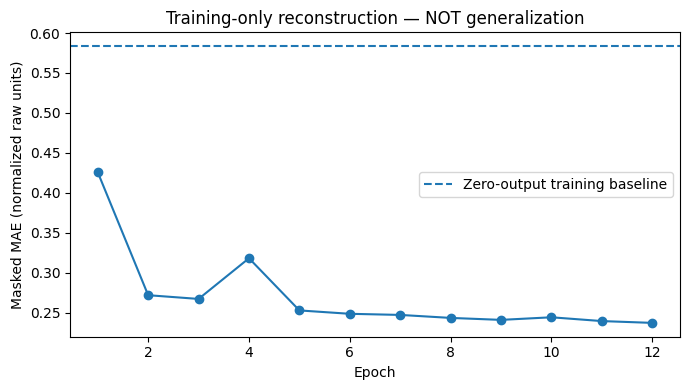


C3-03 SECTION 2 — MULTI-IMAGE NONMETRIC MODEL
Training-only source images: 33
Zero-output train MAE: 0.58354
Best trained-model MAE: 0.23727
Best training epoch: 12
Fresh checkpoint load: PASS
Standalone inference: PASS
Independent validation: NOT PERFORMED
Metric depth accuracy: NOT VERIFIED
Physical severity prediction: DISABLED
Backend release: NOT AUTHORIZED

Training run: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-03_section02_MULTIIMAGE_NONMETRIC_20261020T124409_389343Z
Model checkpoint: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-03_section02_MULTIIMAGE_NONMETRIC_20261020T124409_389343Z


Saved research and checkpoint integrity: PASS
POTHRGBD_BURST_0002 | available: 191 | selected: 16
POTHRGBD_BURST_0003 | available: 247 | selected: 16
POTHRGBD_BURST_0004 | available: 13 | selected: 13
POTHRGBD_BURST_0005 | available: 420 | selected: 15

Corrected evaluation selection: PASS
New unseen filenames: 60
Overlap with previous development: 0
Overlap with model training: 0
Physical pothole independence: UNVERIFIED
Frozen model load: PASS
Checkpoint scale: 54.5197
Train-derived constant baseline: 0.53015 normalized units
Frozen selection saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-03_section03_FROZEN_UNSEEN_PROBE_20261020T125058_809338Z/selected_unseen_samples.csv
10/60 | {'DIAGNOSTIC_FAIL': 8, 'DIAGNOSTIC_PASS': 2}
20/60 | {'DIAGNOSTIC_FAIL': 13, 'DIAGNOSTIC_PASS': 7}
30/60 | {'DIAGNOSTIC_FAIL': 19, 'DIAGNOSTIC_PASS': 10, 'ERROR': 1}
40/60 | {'DIAGNOSTIC_FAIL': 29, 'DIAGNOSTIC_PASS': 10, 'ERROR': 1}
50/60 | {'DIAGNOSTIC_FAIL': 38, 'DIAGNO

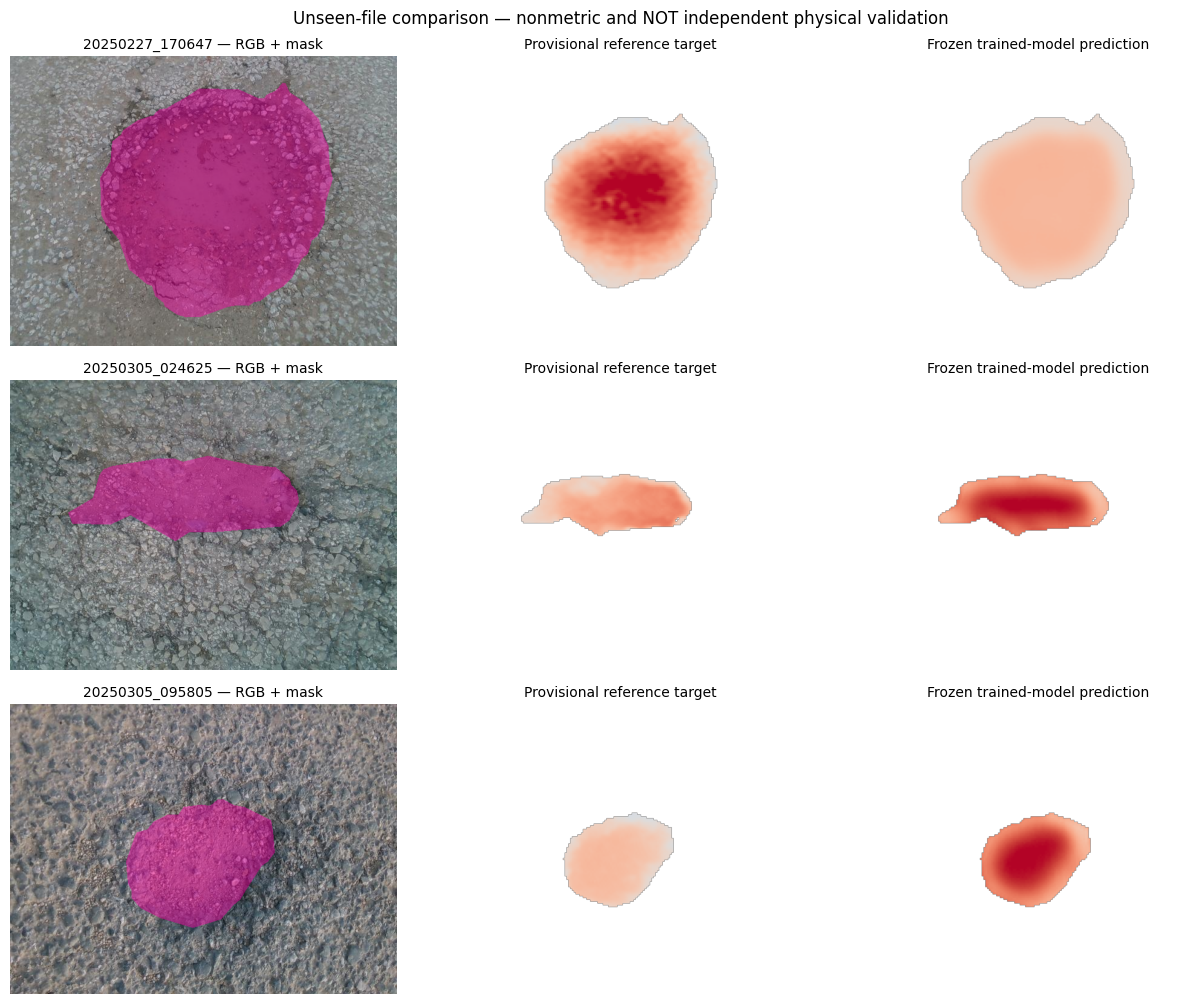


C3-03 SECTION 3 — COMPLETE
Frozen checkpoint integrity: PASS
Checkpoint modified: NO
New candidate filenames: 60
Accepted comparisons: 13
Independent scientific validation: NO
Metric-depth evaluation: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-03_section03_FROZEN_UNSEEN_PROBE_20261020T125058_809338Z


In [ ]:

# ============================================================
# CRDL C3-03 SECTION 3 — FROZEN MODEL UNSEEN-FILE PROBE
# Version 1.0
#
# Frozen model: 33-image nonmetric development checkpoint
# New files: 60, not used in Sections 13/14/16
# No retraining, tuning, physical units, or severity claims
#
# IMPORTANT:
# Unseen filenames != independent physical potholes.
# This is NOT scientific or metric validation.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict, Counter
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import importlib.util
import hashlib
import csv
import json

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)
DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

S12 = BASE / (
    "03_splits_manifests/"
    "C3-02_section12_PothRGBD_Groups_20261020T075921_028539Z"
)
S14 = BASE / (
    "04_geometry_targets/"
    "C3-02_section14_PothRGBD_PILOT_20261020T081321_368363Z"
)
S16 = BASE / (
    "04_geometry_targets/"
    "C3-02_section16_AFFINE_EXPANSION_20261020T082927_408953Z"
)

NAME = (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)

RUN = BASE / "05_training_runs" / NAME
CKPT = BASE / "06_model_checkpoints" / NAME

OUTROOT = BASE / "07_evaluation"

for folder in (
    S12, S14, S16, RUN, CKPT, OUTROOT
):
    assert folder.is_dir(), folder


# ------------------------------------------------------------
# 1. VERIFY EXPERIMENT INTEGRITY
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(1024*1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def verify(folder, required):
    hashes = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, relative = line.split(None, 1)
        relative = relative.strip()
        p = Path(relative)

        assert not p.is_absolute()
        assert ".." not in p.parts

        hashes[relative] = digest

    for filename in required:
        assert filename in hashes
        assert sha(folder / filename) == hashes[filename], filename

    return hashes


h12 = verify(S12, [
    "capture_group_readiness.json",
    "pothrgbd_filename_capture_manifest.csv"
])

h14 = verify(S14, [
    "pilot_quality_report.json"
])

h16 = verify(S16, [
    "expansion_quality_report.json"
])

h_run = verify(RUN, [
    "training_config.json",
    "train_only_manifest.csv",
    "epoch_metrics.csv"
])

h_ckpt = verify(CKPT, [
    "model_development_only.pt",
    "crdl_dev_model.py",
    "crdl_dev_infer.py",
    "smoke_test.json",
    "api_contract.json"
])

p14 = json.loads(
    (S14 / "pilot_quality_report.json").read_text()
)
p16 = json.loads(
    (S16 / "expansion_quality_report.json").read_text()
)
train_cfg = json.loads(
    (RUN / "training_config.json").read_text()
)

assert p14["configuration"] == p16["config"]
assert train_cfg["source_count"] == 33
assert train_cfg["validation_performed"] is False
assert train_cfg["metric_units_verified"] is False

CFG = p14["configuration"]

print("Saved research and checkpoint integrity: PASS")


# ------------------------------------------------------------
# 2. LOAD ORIGINAL TRAINING AND CANDIDATE MANIFESTS
# ------------------------------------------------------------

with (
    S12 / "pothrgbd_filename_capture_manifest.csv"
).open(newline="") as f:
    full_manifest = list(csv.DictReader(f))

with (
    RUN / "train_only_manifest.csv"
).open(newline="") as f:
    train_manifest = list(csv.DictReader(f))

assert len(train_manifest) == 33

used_ids = {
    r["sample_id"]
    for r in p14["records"] + p16["records"]
}

assert len(used_ids) == 125

train_ids = {
    r["sample_id"]
    for r in train_manifest
}

assert len(train_ids) == 33
assert train_ids.issubset(used_ids)

# Select from 4 bursts because all 13 filenames
# in burst 0001 were used in previous development.

by_burst = defaultdict(list)

for row in full_manifest:

    if (
        row["strict_pair_verified"] == "True"
        and row["sample_id"] not in used_ids
    ):
        by_burst[
            row["provisional_burst"]
        ].append(row)

assert set(by_burst) == {
    f"POTHRGBD_BURST_{i:04d}"
    for i in range(2, 6)
}


# ------------------------------------------------------------
# C3-03 SECTION 3 — CORRECTED UNSEEN SAMPLE SELECTION
# Version 1.1
# Exactly 60 unused images, respecting burst capacity
# ------------------------------------------------------------

TARGET_TOTAL = 60
INITIAL_PER_BURST = 15

bursts = sorted(by_burst)

assert len(bursts) == 4

# Begin with up to 15 per burst, but never
# request more than the actual unused capacity.
quotas = {
    burst: min(
        INITIAL_PER_BURST,
        len(by_burst[burst])
    )
    for burst in bursts
}

remaining = TARGET_TOTAL - sum(quotas.values())

# Redistribute any shortfall to other bursts
# with unused capacity, deterministically.
while remaining > 0:

    allocated = False

    for burst in bursts:

        if quotas[burst] < len(by_burst[burst]):

            quotas[burst] += 1
            remaining -= 1
            allocated = True

            if remaining == 0:
                break

    if not allocated:
        raise RuntimeError(
            "Fewer than 60 eligible unused images. "
            "Do not sample duplicates."
        )

assert sum(quotas.values()) == TARGET_TOTAL

selected = []

for burst in bursts:

    candidates = sorted(
        by_burst[burst],
        key=lambda row: row["sample_id"]
    )

    count = quotas[burst]

    assert len(candidates) >= count

    indices = np.linspace(
        0,
        len(candidates) - 1,
        count,
        dtype=int
    )

    assert len(set(indices.tolist())) == count

    selected.extend(
        candidates[int(i)]
        for i in indices
    )

    print(
        burst,
        "| available:", len(candidates),
        "| selected:", count
    )

# Verify exact selection and training exclusion.
selected_ids = {
    row["sample_id"]
    for row in selected
}

assert len(selected) == TARGET_TOTAL
assert len(selected_ids) == TARGET_TOTAL
assert selected_ids.isdisjoint(used_ids)
assert selected_ids.isdisjoint(train_ids)

print("\nCorrected evaluation selection: PASS")
print("New unseen filenames:", len(selected))
print("Overlap with previous development:", 0)
print("Overlap with model training:", 0)
print("Physical pothole independence: UNVERIFIED")



# ------------------------------------------------------------
# 3. LOAD THE SAVED TRAINED MODEL WITHOUT RETRAINING
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "crdl_sec02_frozen_architecture",
    CKPT / "crdl_dev_model.py"
)

arch = importlib.util.module_from_spec(spec)
spec.loader.exec_module(arch)

package = torch.load(
    CKPT / "model_development_only.pt",
    map_location="cpu",
    weights_only=True
)

assert package["contract_version"] == (
    "C3_DEV_NONMETRIC_V1"
)
assert package["training_only"] is True
assert package["metric_units_verified"] is False

SCALE = float(package["raw_target_scale"])

assert np.isclose(
    SCALE,
    train_cfg["raw_target_normalizer"],
    atol=1e-5
)

model = arch.CRDLDevUNet()
model.load_state_dict(
    package["state_dict"],
    strict=True
)

model.eval()

print("Frozen model load: PASS")
print("Checkpoint scale:", round(SCALE, 4))


# ------------------------------------------------------------
# 4. ORIGINAL YOLO POLYGON READER
# ------------------------------------------------------------

def read_mask(path, w, h):
    canvas = Image.new("L", (w, h), 0)
    drawer = ImageDraw.Draw(canvas)

    count = 0

    for line in path.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        vals = np.array(
            [float(x) for x in line.split()],
            dtype=np.float64
        )

        if (
            not np.isfinite(vals).all()
            or vals[0] != 0
            or len(vals) < 7
            or (len(vals)-1) % 2 != 0
        ):
            raise ValueError("Invalid YOLO polygon")

        xy = vals[1:].reshape(-1, 2)

        if (
            (xy < -0.001).any()
            or (xy > 1.001).any()
        ):
            raise ValueError("Invalid polygon coordinates")

        xy = np.clip(xy, 0, 1)

        drawer.polygon(
            [
                (
                    round(x*(w-1)),
                    round(y*(h-1))
                )
                for x, y in xy
            ],
            fill=1
        )

        count += 1

    mask = np.asarray(canvas, dtype=bool)

    if count == 0 or not mask.any():
        raise ValueError("Empty polygon")

    return mask


# ------------------------------------------------------------
# 5. ORIGINAL AFFINE INVERSE-DEPTH MODEL
# ------------------------------------------------------------

def basis(xs, ys, w, h):
    return np.column_stack([
        (xs-(w-1)/2)/w,
        (ys-(h-1)/2)/h,
        np.ones(len(xs))
    ])


def irls(A, b):
    beta = np.linalg.lstsq(
        A, b, rcond=None
    )[0]

    for _ in range(CFG["irls_iterations"]):
        e = b - A @ beta
        med = np.median(e)

        mad = 1.4826 * np.median(
            np.abs(e-med)
        )

        cutoff = max(
            1.5*mad, 1e-6
        )

        weights = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(e-med), 1e-12
                )
            )
        )

        new_beta = np.linalg.lstsq(
            A*weights[:, None],
            b*weights,
            rcond=None
        )[0]

        if np.max(
            np.abs(new_beta-beta)
        ) < 1e-9:
            beta = new_beta
            break

        beta = new_beta

    return beta


# ------------------------------------------------------------
# 6. RESIZE TARGETS EXACTLY AS TRAINING DID
# ------------------------------------------------------------

def encode_supervision(rgb, mask, valid, raw_target):

    x, g = arch.encode_input(
        rgb,
        mask,
        confidence=1.0,
        size=160
    )

    nh, nw = g["resized_hw"]
    top = g["pad_top"]
    left = g["pad_left"]

    valid_small = F.interpolate(
        torch.from_numpy(
            valid.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(
            np.where(
                valid,
                raw_target,
                0.0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    target = (
        numerator
        / valid_small.clamp_min(1e-8)
    ) / SCALE

    mask_small = x[
        3, top:top+nh, left:left+nw
    ][None, None]

    weight = (
        (valid_small >= 0.90).float()
        * mask_small
    )

    target = torch.where(
        weight > 0,
        target,
        torch.zeros_like(target)
    )

    padding = (
        left, 160-nw-left,
        top, 160-nh-top
    )

    y = F.pad(
        target, padding
    ).squeeze(0)

    w = F.pad(
        weight, padding
    ).squeeze(0)

    assert torch.isfinite(y).all()

    return x, y, w


# ------------------------------------------------------------
# 7. CALCULATE STRONGER CONSTANT BASELINE
# USING TRAINING EXAMPLES ONLY
# ------------------------------------------------------------

training_pixels = []

for item in train_manifest:

    stage = item["source_stage"]

    assert stage in {S14.name, S16.name}

    folder = (
        S14 if stage == S14.name
        else S16
    )

    relative = item["npz_relative"]
    assert relative.startswith(
        "diagnostic_pass_npz/"
    )

    expected = (
        h14 if folder == S14
        else h16
    )

    # Verify the saved NPZ hash from its original
    # stage and from the frozen training manifest.
    if relative not in expected:
        raise RuntimeError(
            "Training NPZ missing from source checksums"
        )

    path = folder / relative

    assert sha(path) == expected[relative]
    assert sha(path) == item["npz_sha256"]

    rgb_path = (
        DATA / "images"
        / item["rgb_filename"]
    )

    assert sha(rgb_path) == item["rgb_sha256"]

    with Image.open(rgb_path) as im:
        # Writable copy avoids the earlier warning.
        rgb = np.array(
            im.convert("RGB"),
            copy=True
        )

    with np.load(
        path, allow_pickle=False
    ) as p:
        target = p["signed_axial_raw"].astype(
            np.float32
        )
        mask = p["damage_mask"].astype(bool)
        valid = p[
            "valid_target_mask"
        ].astype(bool)

    assert np.array_equal(
        np.isfinite(target), valid
    )

    _, y, w = encode_supervision(
        rgb, mask, valid, target
    )

    training_pixels.append(
        y[w > 0].numpy()
    )

# Best one-value predictor under MAE.
# Estimated exclusively from the 33 training images.
CONSTANT = float(
    np.median(
        np.concatenate(training_pixels)
    )
)

print(
    "Train-derived constant baseline:",
    round(CONSTANT, 5),
    "normalized units"
)


# ------------------------------------------------------------
# 8. VERSIONED OUTPUT + FROZEN SELECTION
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUTROOT / (
    f"C3-03_section03_FROZEN_UNSEEN_PROBE_{stamp}"
)

OUT.mkdir(exist_ok=False)

selection_file = OUT / "selected_unseen_samples.csv"

with selection_file.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "sample_id",
            "provisional_burst",
            "rgb_filename",
            "label_filename",
            "depth_filename"
        ]
    )

    writer.writeheader()

    for row in selected:
        writer.writerow({
            key: row[key]
            for key in writer.fieldnames
        })

print("Frozen selection saved:", selection_file)


# ------------------------------------------------------------
# 9. RECREATE UNCHANGED TARGET QA ON 60 NEW FILES
# ------------------------------------------------------------

results = []
visuals = {}

for index, row in enumerate(selected, 1):

    sid = row["sample_id"]
    burst = row["provisional_burst"]

    record = {
        "sample_id": sid,
        "burst": burst,
        "status": "ERROR",
        "flags": [],
        "model_trained_on_this_filename": False,
        "physical_scene_independent": False
    }

    try:
        paths = {
            key: DATA / folder / row[name]
            for key, folder, name in [
                ("rgb", "images", "rgb_filename"),
                ("label", "labels", "label_filename"),
                ("depth", "depths", "depth_filename")
            ]
        }

        for p in paths.values():
            assert p.is_file()
            assert not p.is_symlink()

        with Image.open(paths["rgb"]) as im:
            rgb = np.array(
                im.convert("RGB"),
                copy=True
            )

        depth = np.load(
            paths["depth"],
            allow_pickle=False
        )

        assert depth.dtype == np.uint16
        assert depth.ndim == 2
        assert rgb.shape[:2] == depth.shape

        h, w = depth.shape

        mask = read_mask(
            paths["label"], w, h
        )

        finite = depth > 0

        distance = distance_transform_edt(
            ~mask
        )

        ring = (
            finite
            & (distance >= CFG["ring_min_px"])
            & (distance <= CFG["ring_max_px"])
        )

        ry, rx = np.nonzero(ring)

        if len(rx) < CFG["min_support_pixels"]:
            raise ValueError(
                "Insufficient healthy-road support"
            )

        rng = np.random.default_rng(
            CFG["seed"] + int(sid[-6:])
        )

        chosen = rng.choice(
            len(rx),
            min(
                CFG["max_ring_samples"],
                len(rx)
            ),
            replace=False
        )

        ry = ry[chosen]
        rx = rx[chosen]

        z = depth[
            ry, rx
        ].astype(np.float64)

        low, high = np.quantile(
            z, [0.001, 0.999]
        )

        keep = (
            (z >= low)
            & (z <= high)
        )

        ry, rx, z = (
            ry[keep],
            rx[keep],
            z[keep]
        )

        A = basis(rx, ry, w, h)

        # Numerical conditioning only.
        inv = 1000.0 / z

        beta = irls(A, inv)

        fit = A @ beta

        if (fit <= 0).any():
            raise ValueError(
                "Invalid inverse-depth reference"
            )

        road_p95 = float(
            np.percentile(
                np.abs(z-1000.0/fit), 95
            )
        )

        # Original four-sector held-out road QA.
        cy, cx = np.mean(
            np.nonzero(mask),
            axis=1
        )

        angles = np.mod(
            np.arctan2(
                ry-cy, rx-cx
            ) + 2*np.pi,
            2*np.pi
        )

        sectors = np.minimum(
            (angles/(np.pi/2)).astype(int),
            3
        )

        holdouts = []

        for sector in range(4):
            test = sectors == sector
            train = ~test

            if (
                test.sum() < CFG["min_sector_test_pixels"]
                or train.sum() < CFG["min_support_pixels"]
            ):
                holdouts.append(None)
                continue

            cv_beta = irls(
                A[train], inv[train]
            )

            pred = A[test] @ cv_beta

            if (pred <= 0).any():
                holdouts.append(None)
                continue

            holdouts.append(
                float(
                    np.percentile(
                        np.abs(
                            z[test] - 1000.0/pred
                        ),
                        95
                    )
                )
            )

        yy, xx = np.nonzero(
            mask & finite
        )

        inverse_prediction = (
            basis(xx, yy, w, h) @ beta
        )

        okay = inverse_prediction > 0

        reference = np.full(
            len(inverse_prediction),
            np.nan,
            dtype=np.float64
        )

        reference[okay] = (
            1000.0 / inverse_prediction[okay]
        )

        observed = depth[
            yy, xx
        ].astype(np.float64)

        plausible = (
            okay
            & (
                observed >= CFG["sensor_ratio_min"]
                * reference
            )
            & (
                observed <= CFG["sensor_ratio_max"]
                * reference
            )
        )

        residual = np.full(
            (h, w),
            np.nan,
            dtype=np.float32
        )

        residual[
            yy[plausible],
            xx[plausible]
        ] = (
            observed[plausible]
            - reference[plausible]
        ).astype(np.float32)

        valid = np.isfinite(residual)
        values = residual[valid]

        if len(values) < 100:
            raise ValueError(
                "Insufficient valid residual pixels"
            )

        coverage = float(
            valid.sum() / mask.sum()
        )

        magnitude = float(
            np.median(np.abs(values))
        )

        positive = float(
            np.mean(values > 0)
        )

        signal = float(
            magnitude / max(road_p95, 1e-9)
        )

        worst = (
            max(holdouts)
            if all(v is not None for v in holdouts)
            else None
        )

        ratio = (
            worst / max(magnitude, 1e-9)
            if worst is not None
            else None
        )

        # Exactly the locked Section 14 gates.
        flags = []

        if coverage < CFG["min_valid_target_fraction"]:
            flags.append("LOW_VALID_GEOMETRY")

        if positive < CFG["min_positive_fraction"]:
            flags.append("AMBIGUOUS_RESIDUAL_SIGN")

        if signal < CFG["min_signal_to_road_p95"]:
            flags.append("LOW_GEOMETRY_SIGNAL")

        if worst is None:
            flags.append("INCOMPLETE_SPATIAL_HOLDOUT")

        elif ratio > CFG["max_worst_holdout_to_signal"]:
            flags.append("WEAK_SPATIAL_HOLDOUT")

        record.update({
            "status": (
                "DIAGNOSTIC_PASS"
                if not flags
                else "DIAGNOSTIC_FAIL"
            ),
            "flags": flags,
            "coverage": coverage,
            "road_p95_raw": road_p95,
            "signal_to_road_p95": signal,
            "holdout_to_signal": ratio,
            "rgb_sha256": sha(paths["rgb"]),
            "label_sha256": sha(paths["label"]),
            "depth_sha256": sha(paths["depth"])
        })

        # Score only cases passing original geometry QA.
        # Failed cases remain documented, not silently dropped.
        if record["status"] == "DIAGNOSTIC_PASS":

            x, y, weight = encode_supervision(
                rgb, mask, valid, residual
            )

            if weight.sum().item() <= 5:
                raise ValueError(
                    "Insufficient resized supervision"
                )

            with torch.no_grad():
                prediction = model(
                    x.unsqueeze(0)
                ).squeeze(0)

            use = weight > 0

            actual = y[use].numpy()
            predicted = prediction[use].numpy()

            zero_mae = float(
                np.mean(np.abs(actual))
            )

            constant_mae = float(
                np.mean(
                    np.abs(actual-CONSTANT)
                )
            )

            model_mae = float(
                np.mean(
                    np.abs(actual-predicted)
                )
            )

            record.update({
                "zero_mae_norm": zero_mae,
                "constant_mae_norm": constant_mae,
                "model_mae_norm": model_mae,
                "model_beats_constant":
                    bool(model_mae < constant_mae),
            })

            # One deterministic accepted preview per burst.
            if burst not in visuals:

                visuals[burst] = {
                    "sample_id": sid,
                    "rgb": rgb,
                    "mask": mask,
                    "target": y[0].numpy(),
                    "prediction": prediction[0].numpy(),
                    "weight": weight[0].numpy()
                }

    except Exception as e:

        record["status"] = "ERROR"
        record["flags"] = [
            f"{type(e).__name__}: {e}"
        ]

    results.append(record)

    if index % 10 == 0:
        print(
            f"{index}/60 |",
            dict(
                Counter(
                    r["status"] for r in results
                )
            )
        )


# ------------------------------------------------------------
# 10. COMPARE FROZEN MODEL AGAINST BASELINES
# ------------------------------------------------------------

accepted = [
    r for r in results
    if (
        r["status"] == "DIAGNOSTIC_PASS"
        and "model_mae_norm" in r
    )
]

def mean_metric(key):
    if not accepted:
        return None

    return float(
        np.mean([r[key] for r in accepted])
    )

summary = {
    "attempted": len(results),
    "diagnostic_status_counts": dict(
        Counter(r["status"] for r in results)
    ),
    "accepted_evaluation_count": len(accepted),
    "mean_zero_mae_norm":
        mean_metric("zero_mae_norm"),
    "mean_training_constant_mae_norm":
        mean_metric("constant_mae_norm"),
    "mean_frozen_model_mae_norm":
        mean_metric("model_mae_norm"),
    "frames_model_beats_constant": sum(
        r["model_beats_constant"]
        for r in accepted
    ),
    "training_constant_value_norm": CONSTANT,
    "target_scale_raw": SCALE,
    "evaluation_source": (
        "Unseen filenames from same PothRGBD collection; "
        "physical-scene independence not verified."
    ),
    "physical_accuracy_validated": False
}

print("\n" + "="*65)
print("FROZEN DEVELOPMENT MODEL — UNSEEN-FILE PROBE")
print("="*65)
print("Selected filenames:", len(results))
print("QA status:", summary["diagnostic_status_counts"])
print("Accepted comparisons:", len(accepted))
print(
    "Mean zero baseline MAE:",
    summary["mean_zero_mae_norm"]
)
print(
    "Mean constant baseline MAE:",
    summary["mean_training_constant_mae_norm"]
)
print(
    "Mean frozen-model MAE:",
    summary["mean_frozen_model_mae_norm"]
)
print(
    "Frames beating constant:",
    summary["frames_model_beats_constant"]
)
print("Independent physical-scene evaluation: NO")
print("Physical unit accuracy: NOT VERIFIED")


# ------------------------------------------------------------
# 11. SAVE VISUALS FOR THE ACCEPTED EXAMPLES
# ------------------------------------------------------------

if visuals:

    fig, axes = plt.subplots(
        len(visuals), 3,
        figsize=(13, 3.4*len(visuals)),
        squeeze=False
    )

    for i, (burst, ex) in enumerate(
        sorted(visuals.items())
    ):

        rgb = ex["rgb"]
        mask = ex["mask"]

        overlay = rgb.copy()
        overlay[mask] = (
            0.55 * rgb[mask].astype(float)
            + 0.45 * np.array([255, 0, 170])
        ).astype(np.uint8)

        true = np.where(
            ex["weight"] > 0,
            ex["target"],
            np.nan
        )

        pred = np.where(
            ex["weight"] > 0,
            ex["prediction"],
            np.nan
        )

        limit = max(
            float(np.nanpercentile(
                np.abs(true), 95
            )),
            float(np.nanpercentile(
                np.abs(pred), 95
            )),
            0.1
        )

        axes[i, 0].imshow(overlay)
        axes[i, 0].set_title(
            ex["sample_id"] + " — RGB + mask",
            fontsize=10
        )

        axes[i, 1].imshow(
            np.ma.masked_invalid(true),
            cmap="coolwarm",
            vmin=-limit,
            vmax=limit
        )

        axes[i, 1].set_title(
            "Provisional reference target",
            fontsize=10
        )

        axes[i, 2].imshow(
            np.ma.masked_invalid(pred),
            cmap="coolwarm",
            vmin=-limit,
            vmax=limit
        )

        axes[i, 2].set_title(
            "Frozen trained-model prediction",
            fontsize=10
        )

        for ax in axes[i]:
            ax.axis("off")

    fig.suptitle(
        "Unseen-file comparison — nonmetric and "
        "NOT independent physical validation"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / "frozen_model_unseen_previews.png",
        dpi=135,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 12. SAVE VERSIONED EVIDENCE
# ------------------------------------------------------------

report = {
    "milestone": "C3-03",
    "section": 3,
    "version": "1.0",
    "checkpoint_sha256": sha(
        CKPT / "model_development_only.pt"
    ),
    "source_training_config_sha256": sha(
        RUN / "training_config.json"
    ),
    "source_affine_config": CFG,
    "selection_file_sha256": sha(selection_file),
    "summary": summary,
    "records": results,
    "checkpoint_frozen": True,
    "model_retrained": False,
    "quality_thresholds_changed": False,
    "constant_baseline_fitted_on_training_only": True,
    "same_capture_collection_as_training": True,
    "physical_pothole_independence_verified": False,
    "metric_scale_certified": False,
    "severity_model_validated": False,
    "scientific_test_set_used": False,
    "future_training_use_of_selected_frames":
        "RESERVED_DEVELOPMENT_PROBE_DO_NOT_REUSE_FOR_TRAINING"
}

report_file = OUT / "frozen_unseen_probe_report.json"

report_file.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

fields = [
    "sample_id",
    "burst",
    "status",
    "flags",
    "coverage",
    "road_p95_raw",
    "signal_to_road_p95",
    "holdout_to_signal",
    "zero_mae_norm",
    "constant_mae_norm",
    "model_mae_norm",
    "model_beats_constant",
]

with (
    OUT / "evaluation_summary.csv"
).open("w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fields,
        extrasaction="ignore"
    )
    writer.writeheader()

    for r in results:
        writer.writerow({
            key: (
                json.dumps(value)
                if isinstance(value, (list, dict))
                else value
            )
            for key, value in r.items()
        })


# ------------------------------------------------------------
# 13. FINAL CHECKSUMS AND SMOKE CHECK
# ------------------------------------------------------------

assert sha(
    CKPT / "model_development_only.pt"
) == h_ckpt["model_development_only.pt"]

lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        lines.append(
            f"{sha(path)}  {path.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

print("\n" + "="*65)
print("C3-03 SECTION 3 — COMPLETE")
print("="*65)
print("Frozen checkpoint integrity: PASS")
print("Checkpoint modified: NO")
print("New candidate filenames:", len(results))
print("Accepted comparisons:", len(accepted))
print("Independent scientific validation: NO")
print("Metric-depth evaluation: NO")
print("Saved:", OUT)
print("="*65)


In [ ]:

# ------------------------------------------------------------
# C3-03 SECTION 3 — CORRECTED UNSEEN SAMPLE SELECTION
# Version 1.1
# Exactly 60 unused images, respecting burst capacity
# ------------------------------------------------------------

TARGET_TOTAL = 60
INITIAL_PER_BURST = 15

bursts = sorted(by_burst)

assert len(bursts) == 4

# Begin with up to 15 per burst, but never
# request more than the actual unused capacity.
quotas = {
    burst: min(
        INITIAL_PER_BURST,
        len(by_burst[burst])
    )
    for burst in bursts
}

remaining = TARGET_TOTAL - sum(quotas.values())

# Redistribute any shortfall to other bursts
# with unused capacity, deterministically.
while remaining > 0:

    allocated = False

    for burst in bursts:

        if quotas[burst] < len(by_burst[burst]):

            quotas[burst] += 1
            remaining -= 1
            allocated = True

            if remaining == 0:
                break

    if not allocated:
        raise RuntimeError(
            "Fewer than 60 eligible unused images. "
            "Do not sample duplicates."
        )

assert sum(quotas.values()) == TARGET_TOTAL

selected = []

for burst in bursts:

    candidates = sorted(
        by_burst[burst],
        key=lambda row: row["sample_id"]
    )

    count = quotas[burst]

    assert len(candidates) >= count

    indices = np.linspace(
        0,
        len(candidates) - 1,
        count,
        dtype=int
    )

    assert len(set(indices.tolist())) == count

    selected.extend(
        candidates[int(i)]
        for i in indices
    )

    print(
        burst,
        "| available:", len(candidates),
        "| selected:", count
    )

# Verify exact selection and training exclusion.
selected_ids = {
    row["sample_id"]
    for row in selected
}

assert len(selected) == TARGET_TOTAL
assert len(selected_ids) == TARGET_TOTAL
assert selected_ids.isdisjoint(used_ids)
assert selected_ids.isdisjoint(train_ids)

print("\nCorrected evaluation selection: PASS")
print("New unseen filenames:", len(selected))
print("Overlap with previous development:", 0)
print("Overlap with model training:", 0)
print("Physical pothole independence: UNVERIFIED")


POTHRGBD_BURST_0002 | available: 191 | selected: 16
POTHRGBD_BURST_0003 | available: 247 | selected: 16
POTHRGBD_BURST_0004 | available: 13 | selected: 13
POTHRGBD_BURST_0005 | available: 420 | selected: 15

Corrected evaluation selection: PASS
New unseen filenames: 60
Overlap with previous development: 0
Overlap with model training: 0
Physical pothole independence: UNVERIFIED


Google Drive project paths: VERIFIED
Research provenance: PASS
Training images: 33
Reserved evaluation images: 60
Train/evaluation filename overlap: ZERO
Original architecture: LOADED
Target normalization: 54.5197
Original input tensors: (33, 5, 160, 160)
Original target tensors: (33, 1, 160, 160)
Mask-only input preparation: PASS
RGB features: DISABLED
Segmentation masks: PRESERVED
Confidence channel: FIXED AT 1.0

Original RGB experiment reproduced: PASS
RGB model TRAIN-ONLY MAE: 0.23727
Zero baseline TRAIN-ONLY MAE: 0.58354

Starting matched mask-only training...
Device: cpu
Epoch 01/12 | MASK-ONLY TRAIN MAE: 0.32315
Epoch 02/12 | MASK-ONLY TRAIN MAE: 0.24057
Epoch 03/12 | MASK-ONLY TRAIN MAE: 0.23405
Epoch 04/12 | MASK-ONLY TRAIN MAE: 0.22963
Epoch 05/12 | MASK-ONLY TRAIN MAE: 0.29482
Epoch 06/12 | MASK-ONLY TRAIN MAE: 0.25536
Epoch 07/12 | MASK-ONLY TRAIN MAE: 0.24132
Epoch 08/12 | MASK-ONLY TRAIN MAE: 0.23652
Epoch 09/12 | MASK-ONLY TRAIN MAE: 0.25278
Epoch 10/12 | MASK-ONLY TRAI

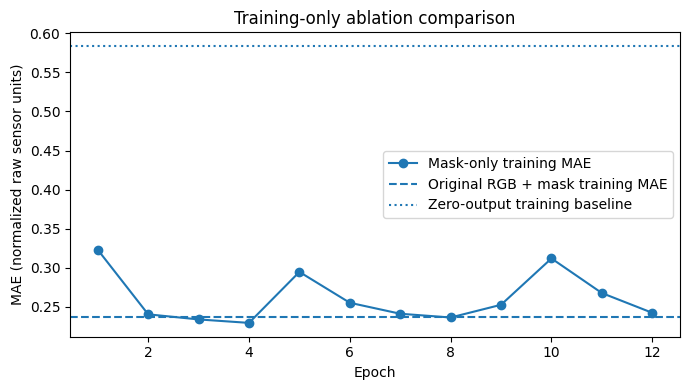


C3-03 SECTION 4A — MASK-ONLY TRAINING COMPLETE
Training images: 33
Original RGB TRAIN-ONLY MAE: 0.23727
Mask-only TRAIN-ONLY MAE: 0.22963
Mask-only best epoch: 4
Saved checkpoint reload: PASS
Standalone inference: PASS
Section 3 evaluation reused for training: NO
Held-out ablation evaluation completed: NO
Metric depth accuracy: NOT VERIFIED
Physical severity: NOT AUTHORIZED

Training output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-03_section04_MASK_ONLY_ABLATION_20261020T125207_426908Z
Checkpoint output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-03_section04_MASK_ONLY_ABLATION_20261020T125207_426908Z


In [ ]:

# ============================================================
# CRDL C3-03 SECTION 4A — MASK-ONLY MODEL ABLATION
#
# SELF-CONTAINED COLAB CELL
# No downloaded script / no file upload required
#
# Trains a mask-only model using the same 33 examples,
# architecture, loss and training schedule as Section 2.
#
# Nonmetric engineering experiment only.
# No physical-depth or independent-validation claims.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image
import csv
import json
import hashlib
import shutil
import sys
import random
import importlib.util

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. GOOGLE DRIVE AND EXISTING PROJECT PATHS
# ------------------------------------------------------------

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

S14 = BASE / (
    "04_geometry_targets/"
    "C3-02_section14_PothRGBD_PILOT_20261020T081321_368363Z"
)

S16 = BASE / (
    "04_geometry_targets/"
    "C3-02_section16_AFFINE_EXPANSION_20261020T082927_408953Z"
)

SECTION2_NAME = (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)

OLD_RUN = (
    BASE / "05_training_runs" / SECTION2_NAME
)

OLD_CKPT = (
    BASE / "06_model_checkpoints" / SECTION2_NAME
)

S3 = BASE / (
    "07_evaluation/"
    "C3-03_section03_FROZEN_UNSEEN_PROBE_"
    "20261020T091805_609498Z"
)

for folder in (
    S14,
    S16,
    OLD_RUN,
    OLD_CKPT,
    S3,
    DATA / "images"
):
    assert folder.is_dir(), (
        f"Missing project folder: {folder}"
    )

print("Google Drive project paths: VERIFIED")


# ------------------------------------------------------------
# 2. VERIFY EXISTING RESEARCH FILES
# ------------------------------------------------------------

def sha256(path):

    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def verify_checksums(folder, required):

    expected = {}

    path = folder / "checksums.sha256"

    assert path.is_file(), path

    for line in path.read_text().splitlines():

        if not line.strip():
            continue

        digest, relative = line.split(None, 1)
        relative = relative.strip()

        rel = Path(relative)

        assert not rel.is_absolute()
        assert ".." not in rel.parts
        assert relative not in expected

        expected[relative] = digest

    for name in required:

        assert name in expected, (
            f"Missing checksum for {name}"
        )

        assert sha256(folder / name) == expected[name], (
            f"Checksum mismatch: {folder / name}"
        )

    return expected


h14 = verify_checksums(
    S14, ["pilot_quality_report.json"]
)

h16 = verify_checksums(
    S16, ["expansion_quality_report.json"]
)

h2run = verify_checksums(
    OLD_RUN,
    [
        "training_config.json",
        "train_only_manifest.csv"
    ]
)

h2ckpt = verify_checksums(
    OLD_CKPT,
    [
        "model_development_only.pt",
        "crdl_dev_model.py",
        "crdl_dev_infer.py",
        "api_contract.json"
    ]
)

h3 = verify_checksums(
    S3,
    [
        "frozen_unseen_probe_report.json",
        "selected_unseen_samples.csv"
    ]
)

p14 = json.loads(
    (S14 / "pilot_quality_report.json").read_text()
)

p16 = json.loads(
    (S16 / "expansion_quality_report.json").read_text()
)

old_config = json.loads(
    (OLD_RUN / "training_config.json").read_text()
)

s3_report = json.loads(
    (S3 / "frozen_unseen_probe_report.json").read_text()
)

assert p14["configuration"] == p16["config"]

assert old_config["source_count"] == 33
assert old_config["epochs"] == 12

assert old_config["validation_performed"] is False

assert s3_report["summary"]["attempted"] == 60
assert (
    s3_report["summary"]["accepted_evaluation_count"]
    == 13
)

assert (
    s3_report["checkpoint_sha256"]
    == h2ckpt["model_development_only.pt"]
)

with (
    OLD_RUN / "train_only_manifest.csv"
).open(newline="") as f:

    manifest = list(csv.DictReader(f))

assert len(manifest) == 33

train_ids = {
    row["sample_id"]
    for row in manifest
}

assert len(train_ids) == 33

approved_ids = {
    row["sample_id"]
    for row in (
        p14["records"] + p16["records"]
    )
    if row["status"] == "DIAGNOSTIC_PASS"
}

assert train_ids == approved_ids

reserved_ids = {
    row["sample_id"]
    for row in s3_report["records"]
}

assert len(reserved_ids) == 60
assert train_ids.isdisjoint(reserved_ids)

print("Research provenance: PASS")
print("Training images:", len(train_ids))
print("Reserved evaluation images:", len(reserved_ids))
print("Train/evaluation filename overlap: ZERO")


# ------------------------------------------------------------
# 3. LOAD ORIGINAL NETWORK ARCHITECTURE
# DIRECTLY FROM THE EXISTING DRIVE CHECKPOINT
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "crdl_section04_original_arch",
    OLD_CKPT / "crdl_dev_model.py"
)

arch = importlib.util.module_from_spec(spec)
spec.loader.exec_module(arch)

CRDLDevUNet = arch.CRDLDevUNet
encode_input = arch.encode_input

original = torch.load(
    OLD_CKPT / "model_development_only.pt",
    map_location="cpu",
    weights_only=True
)

assert (
    original["contract_version"]
    == "C3_DEV_NONMETRIC_V1"
)

assert original["metric_units_verified"] is False

SCALE = float(original["raw_target_scale"])

assert np.isclose(
    SCALE,
    old_config["raw_target_normalizer"],
    atol=1e-6
)

print("Original architecture: LOADED")
print("Target normalization:", round(SCALE, 4))


# ------------------------------------------------------------
# 4. RECONSTRUCT THE EXACT 33 TRAINING TENSORS
# ------------------------------------------------------------

X = []
Y = []
W = []

for row in manifest:

    stage_name = row["source_stage"]

    assert stage_name in {
        S14.name,
        S16.name
    }

    if stage_name == S14.name:
        source_folder = S14
        hashes = h14
    else:
        source_folder = S16
        hashes = h16

    relative = row["npz_relative"]

    assert relative.startswith(
        "diagnostic_pass_npz/"
    )

    assert relative in hashes

    target_file = source_folder / relative

    rgb_file = (
        DATA / "images" / row["rgb_filename"]
    )

    assert target_file.is_file()
    assert rgb_file.is_file()

    assert (
        sha256(target_file)
        == hashes[relative]
        == row["npz_sha256"]
    )

    assert (
        sha256(rgb_file)
        == row["rgb_sha256"]
    )

    with Image.open(rgb_file) as im:

        # A writable copy prevents the earlier
        # NumPy / PyTorch read-only array warning.
        rgb = np.array(
            im.convert("RGB"),
            copy=True
        )

    with np.load(
        target_file,
        allow_pickle=False
    ) as z:

        target_raw = z[
            "signed_axial_raw"
        ].astype(np.float32)

        damage_mask = z[
            "damage_mask"
        ].astype(bool)

        valid_mask = z[
            "valid_target_mask"
        ].astype(bool)

    assert (
        target_raw.shape
        == damage_mask.shape
        == valid_mask.shape
        == rgb.shape[:2]
    )

    assert np.array_equal(
        np.isfinite(target_raw),
        valid_mask
    )

    assert np.all(
        ~valid_mask | damage_mask
    )

    x, geom = encode_input(
        rgb,
        damage_mask,
        confidence=1.0,
        size=160
    )

    nh, nw = geom["resized_hw"]

    top = geom["pad_top"]
    left = geom["pad_left"]

    # Same validity-aware resizing
    # as the original Section 2 model.

    valid_small = F.interpolate(
        torch.from_numpy(
            valid_mask.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(
            np.where(
                valid_mask,
                target_raw,
                0.0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    resized_mask = x[
        3,
        top:top + nh,
        left:left + nw
    ][None, None]

    weight = (
        (valid_small >= 0.90).float()
        * resized_mask
    )

    y = torch.where(
        weight > 0,
        (
            numerator
            / valid_small.clamp_min(1e-8)
        ) / SCALE,
        torch.zeros_like(numerator)
    )

    padding = (
        left,
        160 - nw - left,
        top,
        160 - nh - top
    )

    y = F.pad(
        y,
        padding
    ).squeeze(0)

    weight = F.pad(
        weight,
        padding
    ).squeeze(0)

    assert float(weight.sum()) > 5
    assert torch.isfinite(y).all()

    X.append(x)
    Y.append(y)
    W.append(weight)


X = torch.stack(X)
Y = torch.stack(Y)
W = torch.stack(W)

assert X.shape == (33, 5, 160, 160)
assert Y.shape == (33, 1, 160, 160)
assert W.shape == (33, 1, 160, 160)

print("Original input tensors:", tuple(X.shape))
print("Original target tensors:", tuple(Y.shape))


# ------------------------------------------------------------
# 5. CREATE MASK-ONLY INPUTS
# ------------------------------------------------------------

X_MASK = X.clone()

# RGB information is removed.
X_MASK[:, 0:3, :, :] = 0.0

# Pothole mask and confidence are unchanged.
assert torch.count_nonzero(
    X_MASK[:, 0:3]
) == 0

assert torch.equal(
    X_MASK[:, 3:],
    X[:, 3:]
)

print("Mask-only input preparation: PASS")
print("RGB features: DISABLED")
print("Segmentation masks: PRESERVED")
print("Confidence channel: FIXED AT 1.0")


# ------------------------------------------------------------
# 6. REPRODUCE ORIGINAL RGB MODEL TRAINING ERROR
# ------------------------------------------------------------

rgb_model = CRDLDevUNet()

rgb_model.load_state_dict(
    original["state_dict"],
    strict=True
)

rgb_model.eval()

with torch.no_grad():

    error_sum = 0.0

    for ids in torch.arange(33).split(4):

        pred = rgb_model(X[ids])

        error_sum += float(
            (
                (pred - Y[ids]).abs()
                * W[ids]
            ).sum()
        )

    rgb_train_mae = (
        error_sum / float(W.sum())
    )

zero_baseline = float(
    (Y.abs() * W).sum() / W.sum()
)

assert abs(
    rgb_train_mae
    - old_config["best_train_mae_norm"]
) < 1e-4

assert abs(
    zero_baseline
    - old_config["baseline_zero_train_mae_norm"]
) < 1e-4

print("\nOriginal RGB experiment reproduced: PASS")
print(
    "RGB model TRAIN-ONLY MAE:",
    round(rgb_train_mae, 5)
)
print(
    "Zero baseline TRAIN-ONLY MAE:",
    round(zero_baseline, 5)
)


# ------------------------------------------------------------
# 7. CREATE NEW VERSIONED OUTPUT FOLDERS
# ------------------------------------------------------------

timestamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

name = (
    "C3-03_section04_MASK_ONLY_ABLATION_"
    + timestamp
)

RUN = (
    BASE / "05_training_runs" / name
)

CKPT = (
    BASE / "06_model_checkpoints" / name
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

CKPT.mkdir(
    parents=True,
    exist_ok=False
)

# Copy original architecture to the new
# checkpoint for reproducible inference.
shutil.copy2(
    OLD_CKPT / "crdl_dev_model.py",
    CKPT / "crdl_dev_model.py"
)


# ------------------------------------------------------------
# 8. MATCHED MASK-ONLY NETWORK TRAINING
# ------------------------------------------------------------

SEED = 20261020
EPOCHS = 12
BATCH_SIZE = 4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    torch.set_num_threads(
        min(4, torch.get_num_threads())
    )
except RuntimeError:
    pass

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

mask_model = CRDLDevUNet().to(device)

optimizer = torch.optim.AdamW(
    mask_model.parameters(),
    lr=7e-4,
    weight_decay=1e-4
)

history = []

best_mae = float("inf")
best_epoch = None

print("\nStarting matched mask-only training...")
print("Device:", device)

for epoch in range(1, EPOCHS + 1):

    mask_model.train()

    order = torch.randperm(
        len(X_MASK),
        generator=(
            torch.Generator().manual_seed(
                SEED + epoch
            )
        )
    )

    train_loss_sum = 0.0
    train_weight_sum = 0.0

    for ids in order.split(BATCH_SIZE):

        xb = X_MASK[ids].to(device)
        yb = Y[ids].to(device)
        wb = W[ids].to(device)

        optimizer.zero_grad(
            set_to_none=True
        )

        predictions = mask_model(xb)

        loss = (
            F.smooth_l1_loss(
                predictions,
                yb,
                reduction="none",
                beta=0.2
            ) * wb
        ).sum() / wb.sum().clamp_min(1)

        if not torch.isfinite(loss):
            raise RuntimeError(
                "Nonfinite training loss"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            mask_model.parameters(),
            1.0
        )

        optimizer.step()

        batch_weight = float(
            wb.sum()
        )

        train_loss_sum += (
            float(loss.detach())
            * batch_weight
        )

        train_weight_sum += batch_weight

    # TRAINING-ONLY assessment.
    # No reserved evaluation frame is accessed.

    mask_model.eval()

    with torch.no_grad():

        absolute_error = 0.0

        for ids in torch.arange(
            len(X_MASK)
        ).split(BATCH_SIZE):

            prediction = mask_model(
                X_MASK[ids].to(device)
            ).cpu()

            absolute_error += float(
                (
                    (prediction - Y[ids]).abs()
                    * W[ids]
                ).sum()
            )

    mae = (
        absolute_error
        / float(W.sum())
    )

    history.append({
        "epoch": epoch,
        "train_smoothl1": (
            train_loss_sum
            / max(train_weight_sum, 1.0)
        ),
        "train_masked_mae_norm": mae
    })

    if mae < best_mae:

        best_mae = mae
        best_epoch = epoch

        torch.save(
            {
                "state_dict": (
                    mask_model.state_dict()
                ),
                "contract_version": (
                    "C3_MASK_ONLY_ABLATION_V1"
                ),
                "raw_target_scale": SCALE,
                "training_only": True,
                "rgb_channels_disabled": True,
                "confidence_training_value": 1.0,
                "best_training_epoch": epoch,
                "metric_units_verified": False
            },
            CKPT / "mask_only_ablation.pt"
        )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"MASK-ONLY TRAIN MAE: {mae:.5f}"
    )


# ------------------------------------------------------------
# 9. RELOAD SAVED MASK-ONLY CHECKPOINT
# ------------------------------------------------------------

saved = torch.load(
    CKPT / "mask_only_ablation.pt",
    map_location="cpu",
    weights_only=True
)

reloaded = CRDLDevUNet()

reloaded.load_state_dict(
    saved["state_dict"],
    strict=True
)

reloaded.eval()

duplicate = CRDLDevUNet()

duplicate.load_state_dict(
    saved["state_dict"],
    strict=True
)

duplicate.eval()

with torch.no_grad():

    prediction_a = reloaded(
        X_MASK[0:1]
    ).numpy()

    prediction_b = duplicate(
        X_MASK[0:1]
    ).numpy()

assert np.allclose(
    prediction_a,
    prediction_b,
    rtol=1e-6,
    atol=1e-6
)

print("\nCheckpoint reload: PASS")


# ------------------------------------------------------------
# 10. SAVE STANDALONE MASK-ONLY INFERENCE CODE
# ------------------------------------------------------------

INFERENCE_CODE = '''
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F

from crdl_dev_model import (
    CRDLDevUNet,
    encode_input
)


def predict_mask_only(
    rgb,
    damage_mask,
    checkpoint_dir,
    confidence=1.0
):

    checkpoint_dir = Path(checkpoint_dir)

    package = torch.load(
        checkpoint_dir / "mask_only_ablation.pt",
        map_location="cpu",
        weights_only=True
    )

    assert (
        package["contract_version"]
        == "C3_MASK_ONLY_ABLATION_V1"
    )

    model = CRDLDevUNet()

    model.load_state_dict(
        package["state_dict"],
        strict=True
    )

    model.eval()

    rgb = np.array(
        rgb,
        copy=True
    )

    x, geometry = encode_input(
        rgb,
        damage_mask,
        confidence=confidence,
        size=160
    )

    # Remove RGB information.
    x[:3].zero_()

    with torch.no_grad():

        result = model(
            x.unsqueeze(0)
        )

    top = geometry["pad_top"]
    left = geometry["pad_left"]

    nh, nw = geometry["resized_hw"]
    h, w = geometry["original_hw"]

    crop = result[
        ...,
        top:top+nh,
        left:left+nw
    ]

    resized = F.interpolate(
        crop,
        size=(h, w),
        mode="bilinear",
        align_corners=False
    )

    residual = (
        resized[0, 0].numpy().astype(np.float32)
        * float(package["raw_target_scale"])
    )

    mask = np.asarray(
        damage_mask,
        dtype=bool
    )

    residual[~mask] = np.nan

    return {
        "signed_axial_residual_raw": residual,
        "units": "UNVERIFIED_RAW_SENSOR",
        "status": "MASK_ONLY_ABLATION_NONMETRIC",
        "physical_severity_available": False,
        "confidence_is_calibrated": False
    }
'''

(CKPT / "mask_only_infer.py").write_text(
    INFERENCE_CODE,
    encoding="utf-8"
)

# Test the saved inference implementation
# without opening reserved evaluation images.

if str(CKPT) not in sys.path:
    sys.path.insert(0, str(CKPT))

infer_spec = importlib.util.spec_from_file_location(
    "crdl_section04_mask_infer",
    CKPT / "mask_only_infer.py"
)

infer_module = importlib.util.module_from_spec(
    infer_spec
)

infer_spec.loader.exec_module(
    infer_module
)

demo_rgb = np.zeros(
    (480, 640, 3),
    dtype=np.uint8
)

demo_mask = np.zeros(
    (480, 640),
    dtype=bool
)

demo_mask[90:280, 150:390] = True

demo = infer_module.predict_mask_only(
    demo_rgb,
    demo_mask,
    CKPT
)

demo_map = demo[
    "signed_axial_residual_raw"
]

assert demo_map.shape == demo_mask.shape

assert np.isnan(
    demo_map[~demo_mask]
).all()

assert np.isfinite(
    demo_map[demo_mask]
).all()

print("Standalone inference: PASS")


# ------------------------------------------------------------
# 11. SAVE EXPERIMENT CONFIGURATION AND HISTORY
# ------------------------------------------------------------

with (
    RUN / "epoch_metrics.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(history[0])
    )

    writer.writeheader()
    writer.writerows(history)

shutil.copy2(
    OLD_RUN / "train_only_manifest.csv",
    RUN / "train_only_manifest.csv"
)

config = {
    "milestone": "C3-03",
    "section": "4A",
    "role": "MASK_ONLY_MATCHED_TRAINING_ABLATION",
    "source_count": 33,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "optimizer": (
        "AdamW lr=7e-4 weight_decay=1e-4"
    ),
    "loss": "Masked SmoothL1 beta=0.2",
    "architecture": (
        "CRDLDevUNet, identical to Section 2"
    ),
    "ablation": (
        "RGB channels forced to zero; "
        "segmentation and confidence unchanged"
    ),
    "confidence_training_value": 1.0,
    "target_units": "UNVERIFIED_RAW_SENSOR",
    "raw_target_scale": SCALE,
    "original_rgb_training_mae_norm": rgb_train_mae,
    "mask_only_best_training_mae_norm": best_mae,
    "mask_only_best_epoch": best_epoch,
    "zero_training_baseline_mae_norm": zero_baseline,
    "original_rgb_checkpoint_sha256": (
        h2ckpt["model_development_only.pt"]
    ),
    "original_training_manifest_sha256": (
        h2run["train_only_manifest.csv"]
    ),
    "reserved_evaluation_manifest_sha256": (
        h3["selected_unseen_samples.csv"]
    ),
    "section3_used_for_training": False,
    "independent_validation_performed": False,
    "metric_units_verified": False,
    "severity_authorized": False,
    "torch_version": torch.__version__,
    "device": str(device)
}

(RUN / "training_config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8"
)

api_contract = {
    "version": "C3_MASK_ONLY_ABLATION_V1",
    "input_rgb": (
        "HxWx3 uint8 RGB; spatial dimensions only"
    ),
    "input_mask": "HxW binary segmentation",
    "input_confidence": (
        "Scalar; training used only 1.0"
    ),
    "effective_features": (
        "Mask + constant confidence; "
        "all RGB channels zero"
    ),
    "output": (
        "HxW signed_axial_residual_raw; "
        "NaN outside the mask"
    ),
    "units": "UNVERIFIED_RAW_SENSOR",
    "physical_depth_available": False,
    "physical_severity_available": False,
    "backend_release_authorized": False
}

(CKPT / "api_contract.json").write_text(
    json.dumps(api_contract, indent=2),
    encoding="utf-8"
)

smoke = {
    "checkpoint_reload": "PASS",
    "repeat_forward_equivalence": "PASS",
    "standalone_inference": "PASS",
    "section3_used_for_training": False,
    "physical_validation": "NOT PERFORMED"
}

(CKPT / "smoke_test.json").write_text(
    json.dumps(smoke, indent=2),
    encoding="utf-8"
)


# ------------------------------------------------------------
# 12. TRAINING-ONLY COMPARISON CHART
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.plot(
    [r["epoch"] for r in history],
    [
        r["train_masked_mae_norm"]
        for r in history
    ],
    marker="o",
    label="Mask-only training MAE"
)

ax.axhline(
    rgb_train_mae,
    linestyle="--",
    label="Original RGB + mask training MAE"
)

ax.axhline(
    zero_baseline,
    linestyle=":",
    label="Zero-output training baseline"
)

ax.set_xlabel("Epoch")

ax.set_ylabel(
    "MAE (normalized raw sensor units)"
)

ax.set_title(
    "Training-only ablation comparison"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    RUN / "training_only_mask_ablation.png",
    dpi=140
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 13. VERSIONED CHECKSUMS
# ------------------------------------------------------------

for folder in (RUN, CKPT):

    checksum_lines = []

    for path in sorted(
        folder.rglob("*")
    ):

        if not path.is_file():
            continue

        if path.name == "checksums.sha256":
            continue

        if "__pycache__" in path.parts:
            continue

        relative = (
            path.relative_to(folder).as_posix()
        )

        checksum_lines.append(
            f"{sha256(path)}  {relative}"
        )

    (
        folder / "checksums.sha256"
    ).write_text(
        "\n".join(checksum_lines) + "\n",
        encoding="utf-8"
    )


# ------------------------------------------------------------
# 14. FINAL EXPERIMENT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-03 SECTION 4A — MASK-ONLY TRAINING COMPLETE")
print("=" * 65)

print("Training images:", len(train_ids))

print(
    "Original RGB TRAIN-ONLY MAE:",
    round(rgb_train_mae, 5)
)

print(
    "Mask-only TRAIN-ONLY MAE:",
    round(best_mae, 5)
)

print("Mask-only best epoch:", best_epoch)

print("Saved checkpoint reload: PASS")
print("Standalone inference: PASS")

print("Section 3 evaluation reused for training: NO")
print("Held-out ablation evaluation completed: NO")

print("Metric depth accuracy: NOT VERIFIED")
print("Physical severity: NOT AUTHORIZED")

print("\nTraining output:", RUN)
print("Checkpoint output:", CKPT)

print("=" * 65)


Research integrity: PASS
Reserved evaluation filenames: 60
QA-passing paired examples: 13
Training/evaluation overlap: ZERO
RGB model loaded: PASS
Mask-only model loaded: PASS
Original normalization: 54.5197
01/13 | 20250227_170647 | RGB: 0.4597 | Mask-only: 0.3549 | Winner: MASK
02/13 | 20250227_175724 | RGB: 0.2783 | Mask-only: 0.3062 | Winner: RGB
03/13 | 20250227_183800 | RGB: 0.1075 | Mask-only: 0.1336 | Winner: RGB
04/13 | 20250227_185027 | RGB: 0.2277 | Mask-only: 0.1878 | Winner: MASK
05/13 | 20250227_191936 | RGB: 0.2361 | Mask-only: 0.1735 | Winner: MASK
06/13 | 20250305_024625 | RGB: 0.2731 | Mask-only: 0.3481 | Winner: RGB
07/13 | 20250305_034328 | RGB: 0.5458 | Mask-only: 0.4546 | Winner: MASK
08/13 | 20250305_053636 | RGB: 0.2932 | Mask-only: 0.3298 | Winner: RGB
09/13 | 20250305_054104 | RGB: 0.2919 | Mask-only: 0.3655 | Winner: RGB
10/13 | 20250305_055425 | RGB: 0.1505 | Mask-only: 0.0979 | Winner: MASK
11/13 | 20250305_095805 | RGB: 0.3972 | Mask-only: 0.4435 | Winner:

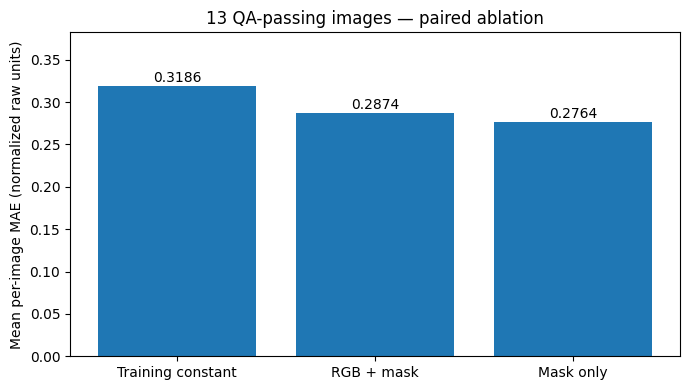

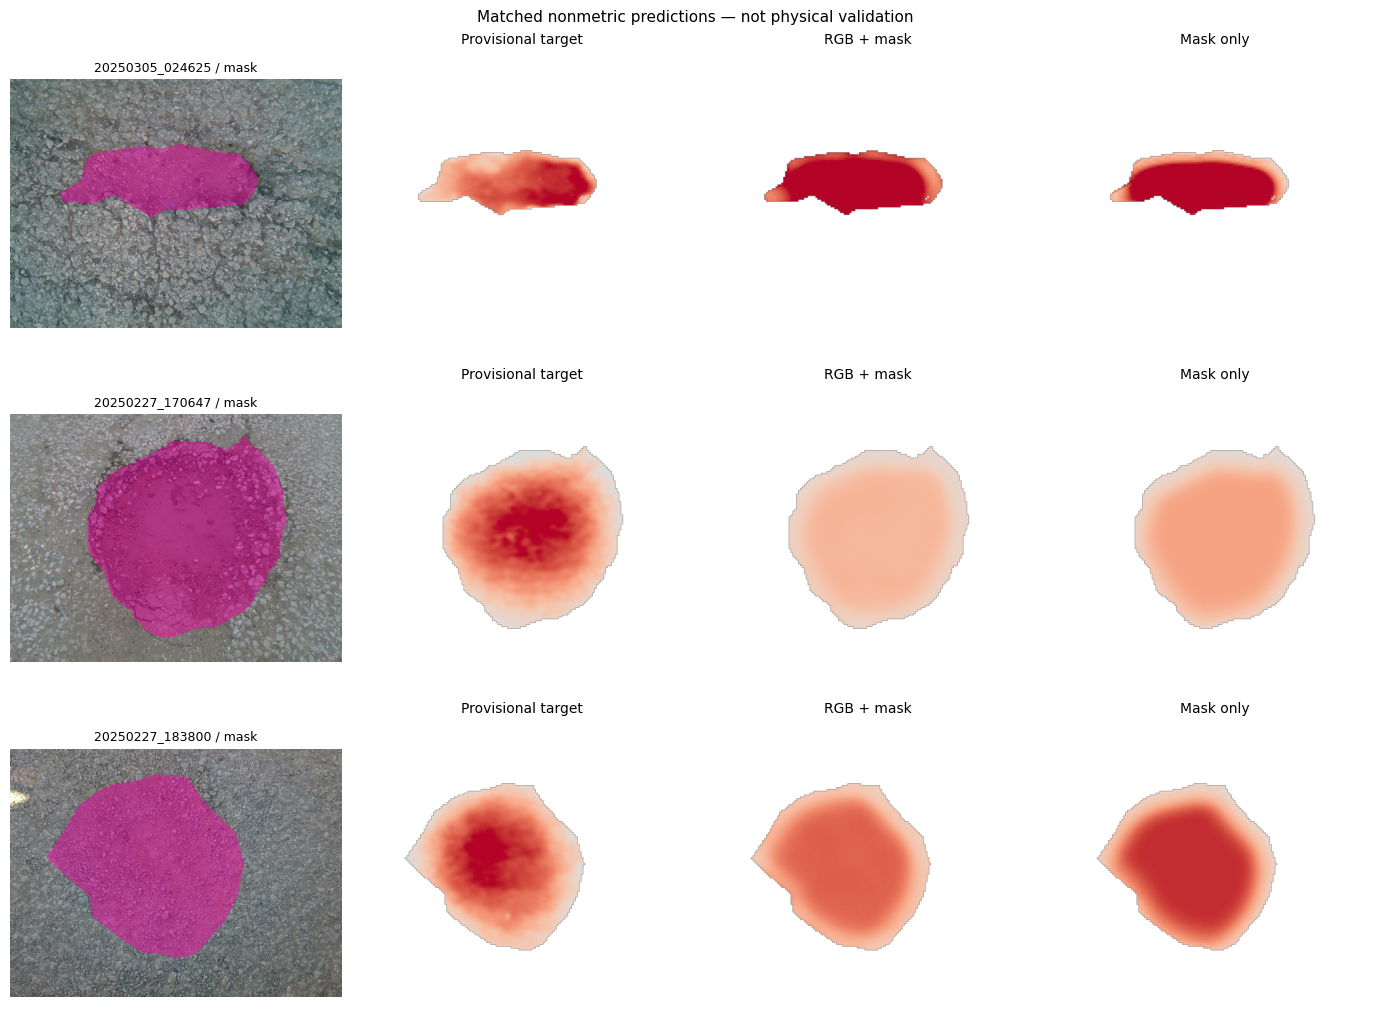


C3-03 SECTION 4B — PAIRED ABLATION COMPLETE
Compared QA-passing images: 13
RGB + mask mean MAE: 0.28736
Mask-only mean MAE: 0.27643
Training constant mean MAE: 0.31864
RGB wins: 7 | Mask-only wins: 6
Mask improvement over RGB (%): 3.8
Section 3 RGB score reproduction: PASS
Weights changed: NO
Independent metric validation: NO

Saved results: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-03_section04B_PAIRED_ABLATION_20261020T125351_159416Z


In [ ]:

# ============================================================
# C3-03 SECTION 4B — RGB vs MASK-ONLY PAIRED ABLATION
# Both trained checkpoints remain frozen.
# Uses only the 13 existing QA-passing evaluation frames.
# NO downloads, uploads, retraining, or metric-depth claims.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import hashlib, json, csv, importlib.util

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

RGBNAME = (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)
MASKNAME = (
    "C3-03_section04_MASK_ONLY_ABLATION_"
    "20261020T101207_202510Z"
)
PROBENAME = (
    "C3-03_section03_FROZEN_UNSEEN_PROBE_"
    "20261020T091805_609498Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

RGBDIR = BASE / "06_model_checkpoints" / RGBNAME
MASKDIR = BASE / "06_model_checkpoints" / MASKNAME
MASKRUN = BASE / "05_training_runs" / MASKNAME
PROBEDIR = BASE / "07_evaluation" / PROBENAME

for d in (
    RGBDIR, MASKDIR, MASKRUN, PROBEDIR,
    DATA / "images", DATA / "labels", DATA / "depths"
):
    assert d.is_dir(), f"Missing directory: {d}"


# ------------------------------------------------------------
# 1. VERIFY SAVED RESEARCH SOURCES
# ------------------------------------------------------------

def digest(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


def verify(folder, required):
    hashes = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        value, name = line.split(None, 1)
        name = name.strip()
        p = Path(name)

        assert not p.is_absolute()
        assert ".." not in p.parts

        hashes[name] = value

    for name in required:
        assert name in hashes
        assert digest(folder / name) == hashes[name], name

    return hashes


hrgb = verify(RGBDIR, [
    "crdl_dev_model.py",
    "model_development_only.pt"
])

hmask = verify(MASKDIR, [
    "crdl_dev_model.py",
    "mask_only_ablation.pt",
    "api_contract.json"
])

hmaskrun = verify(MASKRUN, [
    "training_config.json",
    "train_only_manifest.csv"
])

hprobe = verify(PROBEDIR, [
    "frozen_unseen_probe_report.json",
    "selected_unseen_samples.csv"
])

probe = json.loads(
    (PROBEDIR / "frozen_unseen_probe_report.json").read_text()
)

maskcfg = json.loads(
    (MASKRUN / "training_config.json").read_text()
)

assert probe["summary"]["attempted"] == 60
assert probe["summary"]["accepted_evaluation_count"] == 13

assert (
    probe["checkpoint_sha256"]
    == hrgb["model_development_only.pt"]
)

assert (
    maskcfg["original_rgb_checkpoint_sha256"]
    == hrgb["model_development_only.pt"]
)

assert (
    maskcfg["reserved_evaluation_manifest_sha256"]
    == hprobe["selected_unseen_samples.csv"]
)

assert maskcfg["section3_used_for_training"] is False
assert maskcfg["source_count"] == 33

assert (
    hrgb["crdl_dev_model.py"]
    == hmask["crdl_dev_model.py"]
)

accepted = [
    r for r in probe["records"]
    if r["status"] == "DIAGNOSTIC_PASS"
]

assert len(accepted) == 13

assert all(
    "model_mae_norm" in r
    and not r["model_trained_on_this_filename"]
    for r in accepted
)

with (
    PROBEDIR / "selected_unseen_samples.csv"
).open(newline="") as f:

    selection = {
        r["sample_id"]: r
        for r in csv.DictReader(f)
    }

with (
    MASKRUN / "train_only_manifest.csv"
).open(newline="") as f:

    training = {
        r["sample_id"]
        for r in csv.DictReader(f)
    }

assert len(selection) == 60
assert len(training) == 33
assert training.isdisjoint(selection)

assert {
    r["sample_id"] for r in accepted
}.issubset(selection)

print("Research integrity: PASS")
print("Reserved evaluation filenames:", len(selection))
print("QA-passing paired examples:", len(accepted))
print("Training/evaluation overlap: ZERO")


# ------------------------------------------------------------
# 2. LOAD BOTH FROZEN MODELS
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "c3_s04b_arch",
    RGBDIR / "crdl_dev_model.py"
)

arch = importlib.util.module_from_spec(spec)
spec.loader.exec_module(arch)

rgbpackage = torch.load(
    RGBDIR / "model_development_only.pt",
    map_location="cpu",
    weights_only=True
)

maskpackage = torch.load(
    MASKDIR / "mask_only_ablation.pt",
    map_location="cpu",
    weights_only=True
)

assert (
    rgbpackage["contract_version"]
    == "C3_DEV_NONMETRIC_V1"
)

assert (
    maskpackage["contract_version"]
    == "C3_MASK_ONLY_ABLATION_V1"
)

assert maskpackage["rgb_channels_disabled"] is True
assert rgbpackage["metric_units_verified"] is False
assert maskpackage["metric_units_verified"] is False

SCALE = float(rgbpackage["raw_target_scale"])

assert np.isclose(
    SCALE,
    float(maskpackage["raw_target_scale"]),
    atol=1e-6
)

RGBMODEL = arch.CRDLDevUNet()
RGBMODEL.load_state_dict(
    rgbpackage["state_dict"],
    strict=True
)
RGBMODEL.eval()

MASKMODEL = arch.CRDLDevUNet()
MASKMODEL.load_state_dict(
    maskpackage["state_dict"],
    strict=True
)
MASKMODEL.eval()

CFG = probe["source_affine_config"]

CONSTANT = float(
    probe["summary"]["training_constant_value_norm"]
)

print("RGB model loaded: PASS")
print("Mask-only model loaded: PASS")
print("Original normalization:", round(SCALE, 4))


# ------------------------------------------------------------
# 3. REPRODUCE ORIGINAL POLYGON MASK PROCESSING
# ------------------------------------------------------------

def polygon_mask(path, w, h):
    canvas = Image.new("L", (w, h), 0)
    drawer = ImageDraw.Draw(canvas)

    count = 0

    for line in path.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        vals = np.array(
            [float(x) for x in line.split()],
            dtype=np.float64
        )

        if (
            not np.isfinite(vals).all()
            or vals[0] != 0
            or len(vals) < 7
            or (len(vals) - 1) % 2
        ):
            raise ValueError("Invalid YOLO polygon")

        xy = vals[1:].reshape(-1, 2)

        if (
            (xy < -0.001).any()
            or (xy > 1.001).any()
        ):
            raise ValueError("Invalid polygon range")

        xy = np.clip(xy, 0, 1)

        drawer.polygon(
            [
                (
                    round(x * (w - 1)),
                    round(y * (h - 1))
                )
                for x, y in xy
            ],
            fill=1
        )

        count += 1

    result = np.asarray(canvas, dtype=bool)

    if count == 0 or not result.any():
        raise ValueError("Empty polygon")

    return result


# ------------------------------------------------------------
# 4. REPRODUCE THE LOCKED AFFINE REFERENCE METHOD
# ------------------------------------------------------------

def basis(xs, ys, w, h):
    return np.column_stack([
        (xs - (w-1)/2) / w,
        (ys - (h-1)/2) / h,
        np.ones(len(xs))
    ])


def irls(A, b):
    beta = np.linalg.lstsq(
        A, b, rcond=None
    )[0]

    for _ in range(CFG["irls_iterations"]):
        e = b - A @ beta
        med = np.median(e)

        mad = 1.4826 * np.median(
            np.abs(e-med)
        )

        cutoff = max(
            1.5 * mad, 1e-6
        )

        weights = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(e-med), 1e-12
                )
            )
        )

        new_beta = np.linalg.lstsq(
            A * weights[:, None],
            b * weights,
            rcond=None
        )[0]

        if np.max(
            np.abs(new_beta-beta)
        ) < 1e-9:
            beta = new_beta
            break

        beta = new_beta

    return beta


def reconstruct_reference(rgb, depth, mask, sid):
    h, w = depth.shape

    assert rgb.shape[:2] == (h, w)
    assert depth.dtype == np.uint16

    distance = distance_transform_edt(~mask)

    ring = (
        (depth > 0)
        & (distance >= CFG["ring_min_px"])
        & (distance <= CFG["ring_max_px"])
    )

    ry, rx = np.nonzero(ring)

    assert len(rx) >= CFG["min_support_pixels"]

    rng = np.random.default_rng(
        CFG["seed"] + int(sid[-6:])
    )

    chosen = rng.choice(
        len(rx),
        min(CFG["max_ring_samples"], len(rx)),
        replace=False
    )

    ry = ry[chosen]
    rx = rx[chosen]

    z = depth[ry, rx].astype(np.float64)

    low, high = np.quantile(
        z, [0.001, 0.999]
    )

    keep = (z >= low) & (z <= high)

    ry = ry[keep]
    rx = rx[keep]
    z = z[keep]

    A = basis(rx, ry, w, h)
    inv = 1000.0 / z

    beta = irls(A, inv)
    fit = A @ beta

    assert (fit > 0).all()

    road_p95 = float(
        np.percentile(
            np.abs(z - 1000.0/fit),
            95
        )
    )

    yy, xx = np.nonzero(
        mask & (depth > 0)
    )

    predicted_inv = (
        basis(xx, yy, w, h) @ beta
    )

    okay = predicted_inv > 0

    reference = np.full(
        len(predicted_inv),
        np.nan
    )

    reference[okay] = (
        1000.0 / predicted_inv[okay]
    )

    observed = depth[
        yy, xx
    ].astype(np.float64)

    plausible = (
        okay
        & (
            observed
            >= CFG["sensor_ratio_min"] * reference
        )
        & (
            observed
            <= CFG["sensor_ratio_max"] * reference
        )
    )

    residual = np.full(
        (h, w),
        np.nan,
        dtype=np.float32
    )

    residual[
        yy[plausible],
        xx[plausible]
    ] = (
        observed[plausible]
        - reference[plausible]
    ).astype(np.float32)

    return (
        residual,
        np.isfinite(residual),
        road_p95
    )


# ------------------------------------------------------------
# 5. MATCH ORIGINAL SUPERVISION PREPROCESSING
# ------------------------------------------------------------

def encode_supervision(rgb, mask, valid, target):
    x, g = arch.encode_input(
        rgb, mask,
        confidence=1.0,
        size=160
    )

    nh, nw = g["resized_hw"]
    top = g["pad_top"]
    left = g["pad_left"]

    vs = F.interpolate(
        torch.from_numpy(
            valid.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(
            np.where(
                valid, target, 0.0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    m = x[
        3,
        top:top+nh,
        left:left+nw
    ][None, None]

    weight = (
        (vs >= 0.90).float() * m
    )

    y = torch.where(
        weight > 0,
        (
            numerator
            / vs.clamp_min(1e-8)
        ) / SCALE,
        torch.zeros_like(numerator)
    )

    pad = (
        left, 160-nw-left,
        top, 160-nh-top
    )

    return (
        x,
        F.pad(y, pad).squeeze(0),
        F.pad(weight, pad).squeeze(0)
    )


# ------------------------------------------------------------
# 6. EVALUATE BOTH MODELS ON IDENTICAL IMAGES
# ------------------------------------------------------------

outrows = []
preview = []

with torch.no_grad():

    for k, old in enumerate(accepted, 1):

        sid = old["sample_id"]
        row = selection[sid]

        paths = {
            kind: DATA / folder / row[filename]
            for kind, folder, filename in [
                ("rgb", "images", "rgb_filename"),
                ("label", "labels", "label_filename"),
                ("depth", "depths", "depth_filename")
            ]
        }

        for path in paths.values():
            assert path.is_file()
            assert not path.is_symlink()

        for kind in ("rgb", "label", "depth"):
            assert (
                digest(paths[kind])
                == old[f"{kind}_sha256"]
            ), f"Modified source: {sid} {kind}"

        with Image.open(paths["rgb"]) as img:
            rgb = np.array(
                img.convert("RGB"),
                copy=True
            )

        depth = np.load(
            paths["depth"],
            allow_pickle=False
        )

        assert depth.dtype == np.uint16
        assert depth.ndim == 2
        assert depth.shape == rgb.shape[:2]

        mask = polygon_mask(
            paths["label"],
            depth.shape[1],
            depth.shape[0]
        )

        target, valid, road_p95 = (
            reconstruct_reference(
                rgb, depth, mask, sid
            )
        )

        # Verify the regenerated target reproduces
        # the original Section 3 evaluation evidence.
        assert np.isclose(
            road_p95,
            float(old["road_p95_raw"]),
            atol=0.0002
        ), f"Reference mismatch: {sid}"

        x, y, w = encode_supervision(
            rgb, mask, valid, target
        )

        assert w.sum().item() > 5

        xr = x.unsqueeze(0)

        xm = xr.clone()

        # The only model-input difference:
        # mask-only receives zero RGB channels.
        xm[:, :3, :, :] = 0.0

        pr = RGBMODEL(xr).squeeze(0)
        pm = MASKMODEL(xm).squeeze(0)

        idx = w > 0

        true = y[idx].numpy()
        pred_rgb = pr[idx].numpy()
        pred_mask = pm[idx].numpy()

        rgb_mae = float(
            np.mean(np.abs(true-pred_rgb))
        )

        mask_mae = float(
            np.mean(np.abs(true-pred_mask))
        )

        const_mae = float(
            np.mean(np.abs(true-CONSTANT))
        )

        zero_mae = float(
            np.mean(np.abs(true))
        )

        # Exact paired-evaluation integrity check.
        assert abs(
            rgb_mae - float(old["model_mae_norm"])
        ) < 2e-5, f"RGB reproduction failure: {sid}"

        assert abs(
            const_mae - float(old["constant_mae_norm"])
        ) < 2e-5

        assert abs(
            zero_mae - float(old["zero_mae_norm"])
        ) < 2e-5

        winner = (
            "RGB" if rgb_mae < mask_mae
            else "MASK" if mask_mae < rgb_mae
            else "TIE"
        )

        outrows.append({
            "sample_id": sid,
            "burst": old["burst"],
            "source_QA": "DIAGNOSTIC_PASS",
            "valid_resized_pixels": int(idx.sum()),
            "rgb_mae_norm": rgb_mae,
            "mask_only_mae_norm": mask_mae,
            "constant_mae_norm": const_mae,
            "zero_mae_norm": zero_mae,
            "rgb_minus_mask_mae": rgb_mae-mask_mae,
            "winner": winner
        })

        preview.append({
            "sid": sid,
            "rgb": rgb,
            "mask": mask,
            "target": y[0].numpy(),
            "rgb_pred": pr[0].numpy(),
            "mask_pred": pm[0].numpy(),
            "valid": w[0].numpy()
        })

        print(
            f"{k:02d}/13 | {sid} | "
            f"RGB: {rgb_mae:.4f} | "
            f"Mask-only: {mask_mae:.4f} | "
            f"Winner: {winner}"
        )


# ------------------------------------------------------------
# 7. COMPUTE PAIRED COMPARISON METRICS
# ------------------------------------------------------------

rgb_scores = np.array([
    r["rgb_mae_norm"] for r in outrows
])

mask_scores = np.array([
    r["mask_only_mae_norm"] for r in outrows
])

constant_scores = np.array([
    r["constant_mae_norm"] for r in outrows
])

difference = rgb_scores - mask_scores

assert len(outrows) == 13

assert abs(
    rgb_scores.mean()
    - probe["summary"]["mean_frozen_model_mae_norm"]
) < 2e-5

assert abs(
    constant_scores.mean()
    - probe["summary"]["mean_training_constant_mae_norm"]
) < 2e-5

# Descriptive bootstrap, NOT an independent-scene
# statistical confidence interval.
rng = np.random.default_rng(20261020)

indices = rng.integers(
    0,
    len(difference),
    size=(10000, len(difference))
)

interval = np.percentile(
    difference[indices].mean(axis=1),
    [2.5, 97.5]
).tolist()

summary = {
    "compared_frames": 13,
    "mean_rgb_mae_norm": float(rgb_scores.mean()),
    "mean_mask_only_mae_norm": float(mask_scores.mean()),
    "mean_train_constant_mae_norm":
        float(constant_scores.mean()),
    "mean_rgb_minus_mask_mae":
        float(difference.mean()),
    "mask_improvement_over_rgb_percent":
        float(
            100 * difference.mean()
            / rgb_scores.mean()
        ),
    "rgb_wins": int(
        (rgb_scores < mask_scores).sum()
    ),
    "mask_wins": int(
        (mask_scores < rgb_scores).sum()
    ),
    "ties": int(
        (rgb_scores == mask_scores).sum()
    ),
    "rgb_beats_constant": int(
        (rgb_scores < constant_scores).sum()
    ),
    "mask_beats_constant": int(
        (mask_scores < constant_scores).sum()
    ),
    "descriptive_frame_bootstrap_95pct_for_RGB_minus_MASK":
        interval,
    "units": "NORMALIZED_UNVERIFIED_RAW_SENSOR",
    "independent_physical_scene_validation": False
}


# ------------------------------------------------------------
# 8. CREATE VERSIONED REPORT DIRECTORY
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = (
    BASE / "07_evaluation"
    / f"C3-03_section04B_PAIRED_ABLATION_{stamp}"
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

with (
    OUT / "paired_per_image.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(outrows[0])
    )

    writer.writeheader()
    writer.writerows(outrows)

report = {
    "milestone": "C3-03",
    "section": "4B",
    "version": "1.0",
    "rgb_checkpoint_sha256":
        hrgb["model_development_only.pt"],
    "mask_checkpoint_sha256":
        hmask["mask_only_ablation.pt"],
    "section3_report_sha256":
        hprobe["frozen_unseen_probe_report.json"],
    "same_13_previously_QA_accepted_frames": True,
    "new_training_performed": False,
    "reference_reconstructed_and_matched_to_section3": True,
    "reserved_evaluation_samples_used_for_training": False,
    "physical_units_verified": False,
    "severity_authorized": False,
    "interpretation": (
        "Paired exploratory comparison on 13 "
        "pseudo-label QA-passing images from the "
        "same collection. Not independent validation."
    ),
    "summary": summary,
    "per_image": outrows
}

(
    OUT / "paired_ablation_report.json"
).write_text(
    json.dumps(report, indent=2)
)


# ------------------------------------------------------------
# 9. COMPARE THE MEAN ERRORS VISUALLY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4))

values = [
    constant_scores.mean(),
    rgb_scores.mean(),
    mask_scores.mean()
]

ax.bar(
    [
        "Training constant",
        "RGB + mask",
        "Mask only"
    ],
    values
)

ax.set_ylabel(
    "Mean per-image MAE (normalized raw units)"
)

ax.set_title(
    "13 QA-passing images — paired ablation"
)

for i, v in enumerate(values):
    ax.text(
        i, v+0.005,
        f"{v:.4f}",
        ha="center"
    )

ax.set_ylim(0, max(values)*1.2)

fig.tight_layout()

fig.savefig(
    OUT / "paired_mean_mae.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 10. VISUALIZE BOTH PREDICTIONS SIDE BY SIDE
# ------------------------------------------------------------

# Select largest RGB advantage, largest mask
# advantage, and median paired difference.
chosen = [
    int(np.argmin(difference)),
    int(np.argmax(difference)),
    int(
        np.argsort(difference)[
            len(difference)//2
        ]
    )
]

chosen = list(dict.fromkeys(chosen))

fig, axes = plt.subplots(
    len(chosen),
    4,
    figsize=(14, 3.5*len(chosen)),
    squeeze=False
)

for i, j in enumerate(chosen):

    ex = preview[j]

    good = ex["valid"] > 0

    target = np.where(
        good, ex["target"], np.nan
    )

    pred_rgb = np.where(
        good, ex["rgb_pred"], np.nan
    )

    pred_mask = np.where(
        good, ex["mask_pred"], np.nan
    )

    color_scale = max(
        0.15,
        float(
            np.nanpercentile(
                np.abs(target), 95
            )
        )
    )

    overlay = ex["rgb"].copy()

    overlay[ex["mask"]] = (
        0.55 * overlay[ex["mask"]]
        + 0.45 * np.array([255, 0, 170])
    ).astype(np.uint8)

    axes[i, 0].imshow(overlay)

    axes[i, 0].set_title(
        ex["sid"] + " / mask",
        fontsize=9
    )

    for col, (arr, title) in enumerate([
        (target, "Provisional target"),
        (pred_rgb, "RGB + mask"),
        (pred_mask, "Mask only")
    ], 1):

        axes[i, col].imshow(
            np.ma.masked_invalid(arr),
            cmap="coolwarm",
            vmin=-color_scale,
            vmax=color_scale
        )

        axes[i, col].set_title(
            title,
            fontsize=10
        )

    for a in axes[i]:
        a.axis("off")

fig.suptitle(
    "Matched nonmetric predictions — "
    "not physical validation",
    fontsize=11
)

fig.tight_layout()

fig.savefig(
    OUT / "paired_spatial_previews.png",
    dpi=140
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 11. SAVE CHECKSUMS
# ------------------------------------------------------------

lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        lines.append(
            f"{digest(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 12. FINAL RESEARCH SUMMARY
# ------------------------------------------------------------

print("\n" + "="*65)
print("C3-03 SECTION 4B — PAIRED ABLATION COMPLETE")
print("="*65)

print("Compared QA-passing images:", len(outrows))

print(
    "RGB + mask mean MAE:",
    round(summary["mean_rgb_mae_norm"], 5)
)

print(
    "Mask-only mean MAE:",
    round(summary["mean_mask_only_mae_norm"], 5)
)

print(
    "Training constant mean MAE:",
    round(summary["mean_train_constant_mae_norm"], 5)
)

print(
    "RGB wins:", summary["rgb_wins"],
    "| Mask-only wins:", summary["mask_wins"]
)

print(
    "Mask improvement over RGB (%):",
    round(
        summary["mask_improvement_over_rgb_percent"],
        2
    )
)

print("Section 3 RGB score reproduction: PASS")
print("Weights changed: NO")
print("Independent metric validation: NO")
print("\nSaved results:", OUT)

print("="*65)


In [ ]:

# C3-05 — Repair Transformers environment

import sys
import subprocess

print("Notebook Python:", sys.executable)

subprocess.check_call([
    sys.executable,
    "-m", "pip", "install",
    "--upgrade",
    "--no-cache-dir",
    "transformers==4.48.3",
    "tokenizers>=0.21,<0.22",
    "huggingface_hub>=0.28,<1"
])

print("\nInstalled package information:")

subprocess.run([
    sys.executable,
    "-m", "pip", "show",
    "transformers"
], check=True)

print("\nInstallation finished.")
print("RESTART THE SESSION before importing Transformers.")


Notebook Python: /usr/bin/python3

Installed package information:

Installation finished.
RESTART THE SESSION before importing Transformers.


Research source integrity: PASS
Training-only examples:
POTHRGBD_BURST_0001 | 20250227_141418
POTHRGBD_BURST_0002 | 20250227_184609
POTHRGBD_BURST_0003 | 20250305_053907
POTHRGBD_BURST_0004 | 20250305_082854
POTHRGBD_BURST_0005 | 20250305_132248
Selected device: cpu
CPU fallback activated.
ZoeDepth inference will be slower.

Official ZoeDepth checkpoint: LOADED
Pinned model revision: f364d4c7936e91f465abba182208dd68142bf0ca
1/5 | 20250227_141418 | REFERENCE_COMPUTED | rank correlation=-0.23462540529469406 | signal/road=0.17832037559186498
2/5 | 20250227_184609 | REFERENCE_COMPUTED | rank correlation=0.2310998488417936 | signal/road=0.6683233702967781
3/5 | 20250305_053907 | REFERENCE_COMPUTED | rank correlation=0.27084334269966404 | signal/road=2.021092290877073
4/5 | 20250305_082854 | REFERENCE_COMPUTED | rank correlation=0.49389602088434076 | signal/road=0.6956510131617588
5/5 | 20250305_132248 | REFERENCE_COMPUTED | rank correlation=0.6030849498911426 | signal/road=0.817417609015631

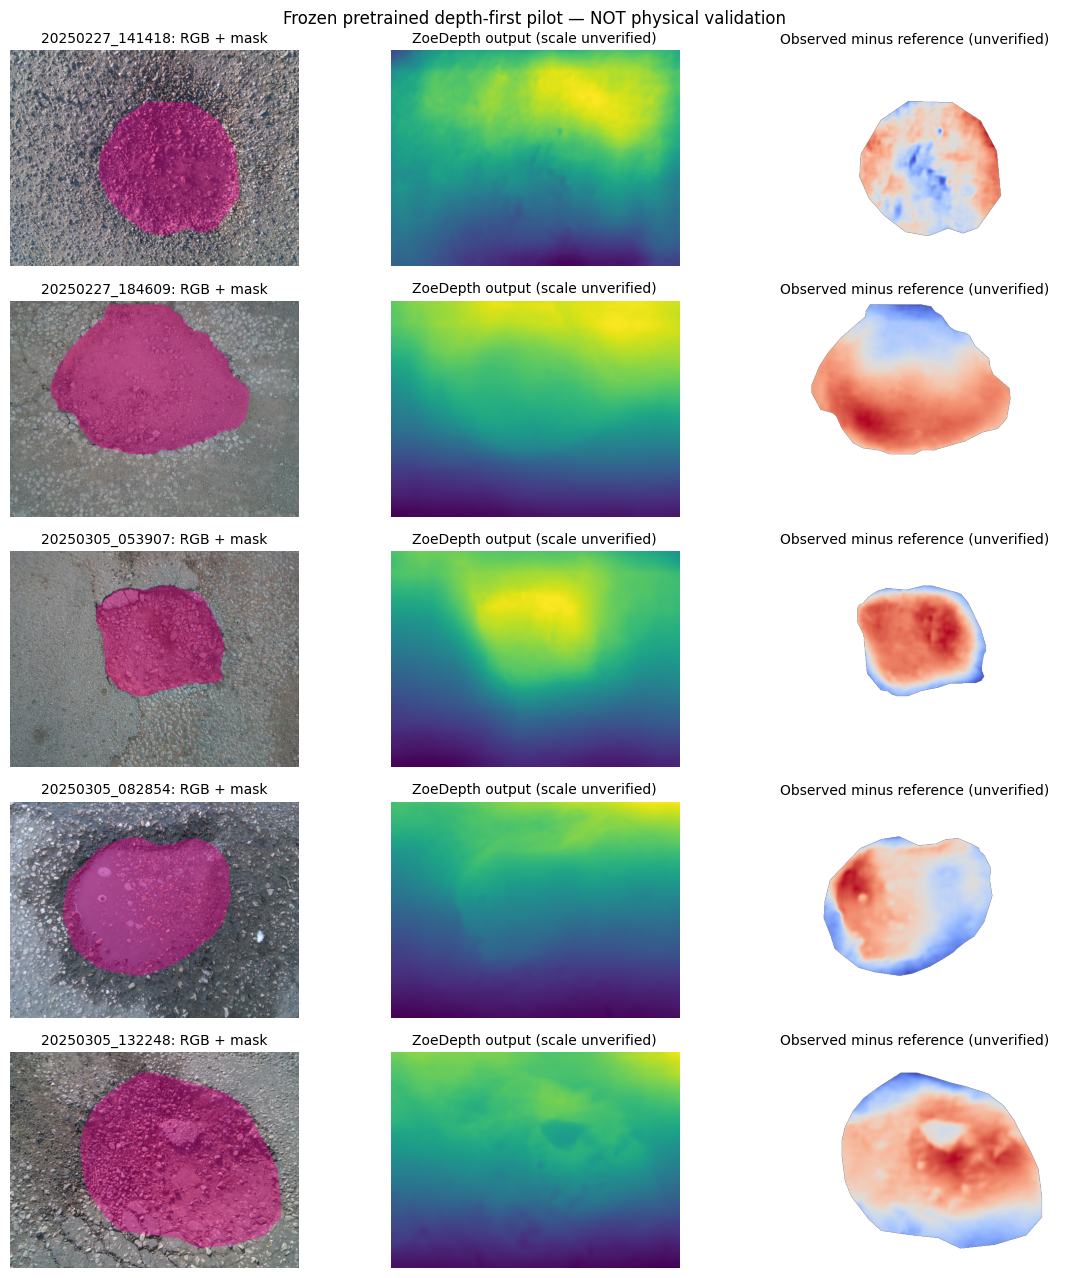


C3-05 SECTION 1 — ZOEDEPTH DEPTH-FIRST PILOT
Frames: 5
Reference statuses: {'REFERENCE_COMPUTED': 5}
Pretrained model weights updated: NO
Physical units certified: NO
Independent evaluation: NO
Reserved evaluation inputs accessed: NO

Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-05_section01_ZOE_DEPTH_FIRST_PILOT_20261020T130025_354347Z


In [ ]:

# =============================================================
# C3-05 SECTION 1: ZOEDEPTH DEPTH-FIRST BASELINE PILOT
# TRAINING-ONLY FRAMES; MODEL FROZEN; NONMETRIC REPORT ONLY
# =============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from PIL import Image
from scipy.ndimage import distance_transform_edt
from scipy.stats import spearmanr
import csv, json, hashlib, importlib, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
import torch

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)
DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)
SRC = BASE / "05_training_runs" / (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)
P14 = BASE / "04_geometry_targets" / (
    "C3-02_section14_PothRGBD_PILOT_"
    "20261020T081321_368363Z"
)
P16 = BASE / "04_geometry_targets" / (
    "C3-02_section16_AFFINE_EXPANSION_"
    "20261020T082927_408953Z"
)
P3 = BASE / "07_evaluation" / (
    "C3-03_section03_FROZEN_UNSEEN_PROBE_"
    "20261020T091805_609498Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for p in [SRC, P14, P16, P3, DATA / "images"]:
    assert p.is_dir(), f"Missing project folder: {p}"


# -------------------------------------------------------------
# 1. SOURCE INTEGRITY
# -------------------------------------------------------------

def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1024*1024), b""):
            h.update(b)
    return h.hexdigest()


def verify(root, names):
    hashes = {}

    for line in (
        root / "checksums.sha256"
    ).read_text().splitlines():
        if not line.strip():
            continue

        digest, name = line.split(None, 1)
        name = name.strip()
        q = Path(name)

        assert not q.is_absolute()
        assert ".." not in q.parts

        hashes[name] = digest

    for name in names:
        assert name in hashes
        assert sha(root / name) == hashes[name], (
            f"Checksum error: {root / name}"
        )

    return hashes


h2 = verify(SRC, [
    "train_only_manifest.csv",
    "training_config.json"
])
h3 = verify(P3, [
    "frozen_unseen_probe_report.json"
])
h14 = verify(P14, ["pilot_quality_report.json"])
h16 = verify(P16, ["expansion_quality_report.json"])

with (
    SRC / "train_only_manifest.csv"
).open(newline="") as f:
    training = list(csv.DictReader(f))

probe = json.loads(
    (P3 / "frozen_unseen_probe_report.json").read_text()
)
pilot = json.loads(
    (P14 / "pilot_quality_report.json").read_text()
)
exp = json.loads(
    (P16 / "expansion_quality_report.json").read_text()
)

assert len(training) == 33
assert len({
    x["sample_id"] for x in training
}) == 33
assert len(probe["records"]) == 60

assert {
    r["sample_id"] for r in training
}.isdisjoint({
    r["sample_id"] for r in probe["records"]
})

assert pilot["configuration"] == exp["config"]
CFG = pilot["configuration"]


# -------------------------------------------------------------
# 2. SELECT FIVE TRAINING-ONLY FRAMES
# -------------------------------------------------------------

selected = []

for burst in sorted({
    r["burst"] for r in training
}):
    options = sorted(
        (r for r in training if r["burst"] == burst),
        key=lambda r: r["sample_id"]
    )
    selected.append(options[len(options)//2])

assert len(selected) == 5

for row in selected:
    folder = (
        P14 if row["source_stage"] == P14.name
        else P16
    )

    assert row["source_stage"] in {
        P14.name, P16.name
    }

    src = folder / row["npz_relative"]
    hashes = h14 if folder == P14 else h16

    assert row["npz_relative"] in hashes
    assert sha(src) == hashes[row["npz_relative"]]
    assert sha(src) == row["npz_sha256"]

    rgb_path = DATA / "images" / row["rgb_filename"]
    assert sha(rgb_path) == row["rgb_sha256"]

print("Research source integrity: PASS")
print("Training-only examples:")

for r in selected:
    print(r["burst"], "|", r["sample_id"])


# -------------------------------------------------------------
# 3. LOAD FROZEN PRETRAINED DEPTH MODEL
# -------------------------------------------------------------


# Automatically use GPU when available, otherwise CPU.

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(
        min(4, torch.get_num_threads())
    )

print("Selected device:", DEVICE)

if DEVICE.type == "cpu":
    print("CPU fallback activated.")
    print("ZoeDepth inference will be slower.")
else:
    print("GPU:", torch.cuda.get_device_name(0))


try:
    import transformers
    if transformers.__version__ != "4.48.3":
        raise ImportError("Pin Transformers")
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "-q", "install",
        "transformers==4.48.3",
        "huggingface_hub>=0.28,<1"
    ])
    importlib.invalidate_caches()
    import transformers

    assert transformers.__version__ == "4.48.3", (
        "Restart the Colab runtime after installation, "
        "then rerun this cell."
    )

from huggingface_hub import model_info
from transformers import (
    AutoImageProcessor,
    AutoModelForDepthEstimation
)

MODEL_ID = "Intel/zoedepth-nyu-kitti"
MODEL_REV = model_info(MODEL_ID).sha

processor = AutoImageProcessor.from_pretrained(
    MODEL_ID,
    revision=MODEL_REV
)

model = AutoModelForDepthEstimation.from_pretrained(
    MODEL_ID,
    revision=MODEL_REV,
    use_safetensors=True
).to(DEVICE).eval()

print("\nOfficial ZoeDepth checkpoint: LOADED")
print("Pinned model revision:", MODEL_REV)


# -------------------------------------------------------------
# 4. ROAD-REFERENCE RECONSTRUCTION
# -------------------------------------------------------------

def ref_plane_from_depth(z, mask, sid):
    assert z.ndim == 2
    assert z.shape == mask.shape

    h, w = z.shape
    good = np.isfinite(z) & (z > 0)

    dist = distance_transform_edt(~mask)

    ring = (
        (~mask) & good
        & (dist >= CFG["ring_min_px"])
        & (dist <= CFG["ring_max_px"])
    )

    yy, xx = np.nonzero(ring)

    if len(xx) < CFG["min_support_pixels"]:
        raise ValueError(
            "Not enough healthy-road support"
        )

    rng = np.random.default_rng(
        CFG["seed"] + int(sid[-6:])
    )

    ids = rng.choice(
        len(xx),
        size=min(
            len(xx),
            CFG["max_ring_samples"]
        ),
        replace=False
    )

    yy, xx = yy[ids], xx[ids]

    zz = z[yy, xx].astype(np.float64)

    lo, hi = np.quantile(
        zz, [0.001, 0.999]
    )

    take = (zz >= lo) & (zz <= hi)

    xx, yy, zz = (
        xx[take], yy[take], zz[take]
    )

    def design_matrix(x, y):
        return np.column_stack([
            (x-(w-1)/2)/w,
            (y-(h-1)/2)/h,
            np.ones(np.size(x))
        ])

    A = design_matrix(xx, yy)

    # The factor 1000 is numerical conditioning;
    # it is not a unit conversion.
    b = 1000.0 / zz

    beta = np.linalg.lstsq(
        A, b, rcond=None
    )[0]

    for _ in range(CFG["irls_iterations"]):
        error = b - A @ beta
        med = np.median(error)

        mad = 1.4826 * np.median(
            np.abs(error-med)
        )

        cutoff = max(
            1.5*mad, 1e-6
        )

        weights = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(error-med), 1e-12
                )
            )
        )

        new_beta = np.linalg.lstsq(
            A*weights[:, None],
            b*weights,
            rcond=None
        )[0]

        if np.max(
            np.abs(new_beta-beta)
        ) < 1e-9:
            beta = new_beta
            break

        beta = new_beta

    Y, X = np.indices(z.shape)

    inv = (
        beta[0] * (X-(w-1)/2)/w
        + beta[1] * (Y-(h-1)/2)/h
        + beta[2]
    )

    reference = np.full(
        z.shape,
        np.nan,
        dtype=np.float32
    )

    valid = good & (inv > 0)

    reference[valid] = (
        1000.0 / inv[valid]
    ).astype(np.float32)

    residual = np.where(
        valid,
        z-reference,
        np.nan
    ).astype(np.float32)

    road = np.abs(
        residual[ring & valid]
    )

    hole = residual[mask & valid]

    if len(road) < 100 or len(hole) < 100:
        raise ValueError(
            "Insufficient residual support"
        )

    road_p95 = float(
        np.percentile(road, 95)
    )

    mag = float(
        np.median(np.abs(hole))
    )

    qa = {
        "road_p95_model_units": road_p95,
        "hole_median_abs_model_units": mag,
        "signal_to_road_p95": float(
            mag / max(road_p95, 1e-9)
        ),
        "positive_fraction": float(
            np.mean(hole > 0)
        )
    }

    return reference, residual, qa


# -------------------------------------------------------------
# 5. CREATE VERSIONED OUTPUT
# -------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = (
    BASE / "07_evaluation"
    / f"C3-05_section01_ZOE_DEPTH_FIRST_PILOT_{stamp}"
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

(OUT / "depth_maps_npz").mkdir(
    exist_ok=False
)


# -------------------------------------------------------------
# 6. RUN DEPTH-FIRST BASELINE ON FIVE FRAMES
# -------------------------------------------------------------

rows = []

fig, axs = plt.subplots(
    len(selected),
    3,
    figsize=(12, 2.6*len(selected)),
    squeeze=False
)

for k, row in enumerate(selected):
    sid = row["sample_id"]

    with Image.open(
        DATA / "images" / row["rgb_filename"]
    ) as im:
        rgb = np.array(
            im.convert("RGB"),
            copy=True
        )

    folder = (
        P14 if row["source_stage"] == P14.name
        else P16
    )

    with np.load(
        folder / row["npz_relative"],
        allow_pickle=False
    ) as p:
        mask = p["damage_mask"].astype(bool)
        sensor = p[
            "signed_axial_raw"
        ].astype(np.float32)
        sensor_valid = p[
            "valid_target_mask"
        ].astype(bool)

    assert mask.shape == rgb.shape[:2]

    inputs = processor(
        images=Image.fromarray(rgb),
        return_tensors="pt"
    ).to(DEVICE)

    with torch.inference_mode():
        outputs = model(**inputs)

    processed = (
        processor.post_process_depth_estimation(
            outputs,
            source_sizes=[
                (rgb.shape[0], rgb.shape[1])
            ]
        )
    )

    depth = (
        processed[0]["predicted_depth"]
        .detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    assert depth.shape == mask.shape
    assert np.isfinite(depth).all()
    assert (depth > 0).all()

    try:
        reference, residual, qa = (
            ref_plane_from_depth(
                depth, mask, sid
            )
        )

        compare = (
            mask
            & sensor_valid
            & np.isfinite(residual)
        )

        if compare.sum() > 100:
            corr = spearmanr(
                sensor[compare],
                residual[compare]
            ).statistic

            corr = (
                float(corr)
                if np.isfinite(corr)
                else None
            )
        else:
            corr = None

        status = "REFERENCE_COMPUTED"

    except ValueError as e:
        reference = np.full_like(
            depth, np.nan
        )
        residual = np.full_like(
            depth, np.nan
        )

        qa = {"error": str(e)}
        corr = None

        status = "REFERENCE_UNAVAILABLE"

    image_rel = (
        f"depth_maps_npz/"
        f"{sid}_zoe_nominal_depth.npz"
    )

    np.savez_compressed(
        OUT / image_rel,
        depth_model_output=depth,
        reference_model_output=reference,
        camera_axial_residual_model_output=residual,
        damage_mask=mask.astype(np.uint8)
    )

    rows.append({
        "sample_id": sid,
        "burst": row["burst"],
        "status": status,
        "model_depth_min": float(
            np.min(depth)
        ),
        "model_depth_max": float(
            np.max(depth)
        ),
        "sensor_vs_model_residual_spearman": corr,
        **qa,
        "npz": image_rel,
        "rgb_sha256": row["rgb_sha256"]
    })

    overlay = rgb.copy()

    overlay[mask] = (
        .60*overlay[mask]
        + .40*np.array([255, 0, 150])
    ).astype(np.uint8)

    axs[k, 0].imshow(overlay)
    axs[k, 0].set_title(
        f"{sid}: RGB + mask",
        fontsize=10
    )

    axs[k, 1].imshow(
        depth,
        cmap="viridis"
    )
    axs[k, 1].set_title(
        "ZoeDepth output (scale unverified)",
        fontsize=10
    )

    axs[k, 2].imshow(
        np.ma.masked_invalid(
            np.where(
                mask, residual, np.nan
            )
        ),
        cmap="coolwarm"
    )
    axs[k, 2].set_title(
        "Observed minus reference (unverified)",
        fontsize=10
    )

    for ax in axs[k]:
        ax.axis("off")

    print(
        f"{k+1}/{len(selected)} | {sid}"
        f" | {status}"
        f" | rank correlation={corr}"
        f" | signal/road={qa.get('signal_to_road_p95')}"
    )

fig.suptitle(
    "Frozen pretrained depth-first pilot "
    "— NOT physical validation",
    fontsize=12
)

fig.tight_layout()

fig.savefig(
    OUT / "depth_first_previews.png",
    dpi=140,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# -------------------------------------------------------------
# 7. SAVE EXPERIMENT CONFIGURATION
# -------------------------------------------------------------

config = {
    "stage": "C3-05_section01",
    "model_id": MODEL_ID,
    "revision_commit": MODEL_REV,
    "transformers_version":
        transformers.__version__,
    "torch_version": torch.__version__,
    "preprocessing":
        "Official Hugging Face AutoImageProcessor",
    "depth_first_method": (
        "Frozen ZoeDepth camera-depth prediction, "
        "followed by robust affine inverse-depth "
        "road reference and camera-axial residual"
    ),
    "road_reference_config": CFG,
    "source_training_manifest_sha256":
        h2["train_only_manifest.csv"],
    "source_probe_sha256":
        h3["frozen_unseen_probe_report.json"],
    "source_policy":
        "33-image development training pool only",
    "model_weights_modified": False,
    "physical_units_certified": False,
    "independent_test_performed": False,
    "note": (
        "ZoeDepth may produce nominal metric "
        "predictions, but physical scale is "
        "not certified on these road scenes."
    )
}

(
    OUT / "config_and_provenance.json"
).write_text(
    json.dumps(config, indent=2)
)

(
    OUT / "results.json"
).write_text(
    json.dumps({
        "records": rows,
        "sample_count": len(rows),
        "status_counts": dict(
            Counter(r["status"] for r in rows)
        )
    }, indent=2)
)

with (
    OUT / "per_image.csv"
).open("w", newline="") as f:
    keys = list(dict.fromkeys(
        k for r in rows for k in r
    ))

    writer = csv.DictWriter(
        f,
        fieldnames=keys
    )

    writer.writeheader()
    writer.writerows(rows)


# -------------------------------------------------------------
# 8. CHECKSUMS AND FINAL SUMMARY
# -------------------------------------------------------------

lines = []

for p in sorted(OUT.rglob("*")):
    if (
        p.is_file()
        and p.name != "checksums.sha256"
    ):
        lines.append(
            f"{sha(p)}  "
            f"{p.relative_to(OUT).as_posix()}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)

print("\n" + "="*65)
print("C3-05 SECTION 1 — ZOEDEPTH DEPTH-FIRST PILOT")
print("="*65)

print("Frames:", len(rows))
print(
    "Reference statuses:",
    dict(Counter(r["status"] for r in rows))
)

print("Pretrained model weights updated: NO")
print("Physical units certified: NO")
print("Independent evaluation: NO")
print("Reserved evaluation inputs accessed: NO")

print("\nOutput:", OUT)
print("="*65)


Research integrity: PASS
Training images: 33
Reserved evaluation images excluded: 60
Frozen ZoeDepth device: cpu
01/33 | 20250227_135438 | new_frozen_zoe_inference
02/33 | 20250227_141738 | new_frozen_zoe_inference
03/33 | 20250227_184251 | new_frozen_zoe_inference
04/33 | 20250305_054953 | new_frozen_zoe_inference
05/33 | 20250305_073146 | new_frozen_zoe_inference
06/33 | 20250305_110414 | new_frozen_zoe_inference
07/33 | 20250227_135652 | new_frozen_zoe_inference
08/33 | 20250227_141418 | verified_section01_cache
09/33 | 20250227_163135 | new_frozen_zoe_inference
10/33 | 20250227_175242 | new_frozen_zoe_inference
11/33 | 20250227_180722 | new_frozen_zoe_inference
12/33 | 20250227_182831 | new_frozen_zoe_inference
13/33 | 20250227_183642 | new_frozen_zoe_inference
14/33 | 20250227_184609 | verified_section01_cache
15/33 | 20250227_185135 | new_frozen_zoe_inference
16/33 | 20250227_185406 | new_frozen_zoe_inference
17/33 | 20250227_185645 | new_frozen_zoe_inference
18/33 | 20250227_190

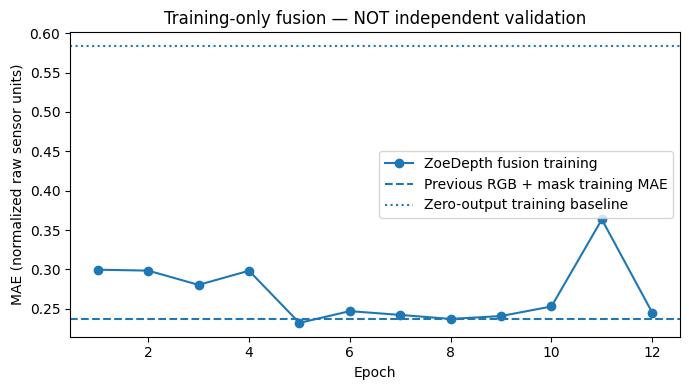


C3-05 SECTION 2 — LEARNED ZOEDEPTH-CRDL FUSION
Training images: 33
Reused ZoeDepth maps: 5
New ZoeDepth maps: 28
Previous RGB + mask training MAE: 0.23727
Fusion training MAE: 0.2322
Best training epoch: 5
Checkpoint reload and inference: PASS
Independent validation: NOT PERFORMED
Physical metric units: UNVERIFIED
Severity prediction: DISABLED

Training folder: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-05_section02_ZOE_FUSION_TRAIN_20261020T131335_245452Z
Checkpoint folder: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-05_section02_ZOE_FUSION_TRAIN_20261020T131335_245452Z


In [ ]:

# ============================================================
# C3-05 SECTION 2 — TRAINED ZOEDEPTH-CRDL FUSION
# ONE COLAB CELL — DIRECT GOOGLE DRIVE PATHS
#
# 33 previously accepted training images only.
# Frozen ZoeDepth supplies an auxiliary geometry feature.
# A separate CRDL network learns the depression target.
# No metric depth certification or independent validation.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image
import csv, json, hashlib, random, shutil, sys
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)
DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

OLD = (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)
PRE = (
    "C3-05_section01_ZOE_DEPTH_FIRST_PILOT_"
    "20261020T130025_354347Z"
)
PROBE = (
    "C3-03_section03_FROZEN_UNSEEN_PROBE_"
    "20261020T091805_609498Z"
)

S14 = BASE / (
    "04_geometry_targets/"
    "C3-02_section14_PothRGBD_PILOT_20261020T081321_368363Z"
)
S16 = BASE / (
    "04_geometry_targets/"
    "C3-02_section16_AFFINE_EXPANSION_20261020T082927_408953Z"
)

TRAIN = BASE / "05_training_runs" / OLD
ORIG = BASE / "06_model_checkpoints" / OLD
PILOT = BASE / "07_evaluation" / PRE
RESERVED = BASE / "07_evaluation" / PROBE

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for root in (
    DATA / "images",
    TRAIN, ORIG, PILOT, RESERVED, S14, S16
):
    assert root.is_dir(), f"Missing {root}"


# ------------------------------------------------------------
# 1. VERIFY ORIGINAL SOURCES
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def validate(root, names):
    hashes = {}

    for line in (
        root / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, name = line.split(None, 1)
        name = name.strip()
        p = Path(name)

        assert not p.is_absolute()
        assert ".." not in p.parts
        assert name not in hashes

        hashes[name] = digest

    for name in names:
        assert name in hashes
        assert sha(root / name) == hashes[name], name

    return hashes


htr = validate(TRAIN, [
    "training_config.json",
    "train_only_manifest.csv"
])

ho = validate(ORIG, [
    "model_development_only.pt",
    "crdl_dev_model.py"
])

hp = validate(PILOT, [
    "config_and_provenance.json",
    "results.json"
])

hr = validate(RESERVED, [
    "frozen_unseen_probe_report.json"
])

h14 = validate(S14, ["pilot_quality_report.json"])
h16 = validate(S16, ["expansion_quality_report.json"])

with (
    TRAIN / "train_only_manifest.csv"
).open(newline="") as f:
    manifest = list(csv.DictReader(f))

assert len(manifest) == 33
assert len({
    r["sample_id"] for r in manifest
}) == 33

held = json.loads(
    (RESERVED / "frozen_unseen_probe_report.json").read_text()
)

assert len(held["records"]) == 60

assert {
    r["sample_id"] for r in manifest
}.isdisjoint({
    r["sample_id"] for r in held["records"]
})

config = json.loads(
    (TRAIN / "training_config.json").read_text()
)

assert config["source_count"] == 33
assert config["epochs"] == 12

p14 = json.loads(
    (S14 / "pilot_quality_report.json").read_text()
)

p16 = json.loads(
    (S16 / "expansion_quality_report.json").read_text()
)

assert p14["configuration"] == p16["config"]
REF_CFG = p14["configuration"]

prior_cfg = json.loads(
    (PILOT / "config_and_provenance.json").read_text()
)

MODEL_ID = "Intel/zoedepth-nyu-kitti"
REV = "f364d4c7936e91f465abba182208dd68142bf0ca"

assert prior_cfg["model_id"] == MODEL_ID
assert prior_cfg["revision_commit"] == REV
assert (
    prior_cfg["source_training_manifest_sha256"]
    == htr["train_only_manifest.csv"]
)

prior_records = json.loads(
    (PILOT / "results.json").read_text()
)["records"]

prior_map = {
    r["sample_id"]: r
    for r in prior_records
}

assert len(prior_map) == 5

print("Research integrity: PASS")
print("Training images:", len(manifest))
print("Reserved evaluation images excluded: 60")


# ------------------------------------------------------------
# 2. DEFINE REPRODUCIBLE GEOMETRY PREPROCESSING
# ------------------------------------------------------------

FEATURE_CODE = r'''
import numpy as np
from scipy.ndimage import distance_transform_edt
import torch
import torch.nn.functional as F
from crdl_dev_model import encode_input


def _irls(A, b, loops):
    beta = np.linalg.lstsq(A, b, rcond=None)[0]

    for _ in range(loops):
        e = b - A @ beta
        med = np.median(e)

        mad = 1.4826 * np.median(
            np.abs(e-med)
        )

        cutoff = max(1.5*mad, 1e-6)

        weight = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(e-med), 1e-12
                )
            )
        )

        newer = np.linalg.lstsq(
            A * weight[:, None],
            b * weight,
            rcond=None
        )[0]

        if np.max(np.abs(newer-beta)) < 1e-9:
            beta = newer
            break

        beta = newer

    return beta


def feature_from_depth(depth, mask, cfg):
    depth = np.asarray(
        depth, dtype=np.float32
    )

    mask = np.asarray(
        mask, dtype=bool
    )

    if depth.ndim != 2 or mask.shape != depth.shape:
        raise ValueError(
            "Aligned 2D depth and mask required"
        )

    h, w = depth.shape

    good = np.isfinite(depth) & (depth > 0)

    distance = distance_transform_edt(~mask)

    ring = (
        good & (~mask)
        & (distance >= cfg["ring_min_px"])
        & (distance <= cfg["ring_max_px"])
    )

    yy, xx = np.nonzero(ring)

    if len(xx) < cfg["min_support_pixels"]:
        raise ValueError(
            "Insufficient healthy-road support"
        )

    rng = np.random.default_rng(
        int(cfg["seed"])
    )

    ids = rng.choice(
        len(xx),
        min(cfg["max_ring_samples"], len(xx)),
        replace=False
    )

    yy, xx = yy[ids], xx[ids]

    z = depth[
        yy, xx
    ].astype(np.float64)

    low, high = np.quantile(
        z, [0.001, 0.999]
    )

    keep = (z >= low) & (z <= high)

    yy, xx, z = (
        yy[keep], xx[keep], z[keep]
    )

    A = np.column_stack([
        (xx-(w-1)/2)/w,
        (yy-(h-1)/2)/h,
        np.ones(len(xx))
    ])

    beta = _irls(
        A,
        1000.0/z,
        int(cfg["irls_iterations"])
    )

    gy, gx = np.indices((h, w))

    inverse = (
        beta[0]*(gx-(w-1)/2)/w
        + beta[1]*(gy-(h-1)/2)/h
        + beta[2]
    )

    good = good & (inverse > 0)

    reference = np.full(
        (h, w),
        np.nan,
        dtype=np.float32
    )

    reference[good] = (
        1000.0/inverse[good]
    ).astype(np.float32)

    relative = np.zeros(
        (h, w), dtype=np.float32
    )

    relative[good] = (
        (depth[good]-reference[good])
        / reference[good]
    ).astype(np.float32)

    # Fixed dimensionless numerical encoding,
    # not a physical metric conversion.
    relative = np.clip(
        relative, -0.30, 0.30
    ) / 0.10

    return relative, good


def encode_fusion(rgb, mask, depth, cfg, size=160):
    x, g = encode_input(
        rgb, mask,
        confidence=1.0,
        size=size
    )

    feature, valid = feature_from_depth(
        depth, mask, cfg
    )

    nh, nw = g["resized_hw"]
    top = g["pad_top"]
    left = g["pad_left"]

    t = torch.from_numpy(
        feature.copy()
    )[None, None]

    v = torch.from_numpy(
        valid.astype(np.float32)
    )[None, None]

    validity = F.interpolate(
        v,
        size=(nh, nw),
        mode="area"
    )

    weighted = F.interpolate(
        t*v,
        size=(nh, nw),
        mode="area"
    )

    small = (
        weighted
        / validity.clamp_min(1e-8)
    )

    small = torch.where(
        validity >= 0.90,
        small,
        torch.zeros_like(small)
    )

    validity_small = (
        validity >= 0.90
    ).float()

    padding = (
        left, size-nw-left,
        top, size-nh-top
    )

    feature_channel = F.pad(
        small, padding
    )[0]

    validity_channel = F.pad(
        validity_small, padding
    )[0]

    fused = torch.cat([
        x,
        feature_channel,
        validity_channel
    ], dim=0)

    assert fused.shape == (7, size, size)

    return fused, g
'''


# ------------------------------------------------------------
# 3. DEFINE THE NEW TRAINABLE FUSION NETWORK
# ------------------------------------------------------------

ARCH_CODE = r'''
from crdl_dev_model import (
    CRDLDevUNet,
    DoubleConv
)


class CRDLZoeFusionUNet(CRDLDevUNet):
    def __init__(self):
        super().__init__()

        # Original architecture, extended from
        # 5 to 7 input channels.
        self.e1 = DoubleConv(7, 16)
'''


INFER_CODE = r'''
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F

from crdl_fusion_model import CRDLZoeFusionUNet
from crdl_fusion_preprocess import encode_fusion


def load_fusion_model(checkpoint_dir, device="cpu"):
    root = Path(checkpoint_dir)

    package = torch.load(
        root / "crdl_zoe_fusion_nonmetric.pt",
        map_location=device,
        weights_only=True
    )

    assert (
        package["contract_version"]
        == "C3_ZOE_FUSION_NONMETRIC_V1"
    )

    model = CRDLZoeFusionUNet().to(device)

    model.load_state_dict(
        package["state_dict"],
        strict=True
    )

    return model.eval(), package


def predict_from_zoe_depth(
    rgb,
    damage_mask,
    zoe_depth,
    checkpoint_dir,
    device="cpu"
):
    model, package = load_fusion_model(
        checkpoint_dir, device
    )

    x, g = encode_fusion(
        np.array(rgb, copy=True),
        np.asarray(damage_mask, dtype=bool),
        zoe_depth,
        package["reference_config"]
    )

    with torch.inference_mode():
        prediction = model(
            x[None].to(device)
        ).cpu()

    top = g["pad_top"]
    left = g["pad_left"]

    nh, nw = g["resized_hw"]
    h, w = g["original_hw"]

    crop = prediction[
        ...,
        top:top+nh,
        left:left+nw
    ]

    resized = F.interpolate(
        crop,
        size=(h, w),
        mode="bilinear",
        align_corners=False
    )

    raw = (
        resized[0, 0].numpy()
        * float(package["raw_target_scale"])
    ).astype(np.float32)

    mask = np.asarray(
        damage_mask, dtype=bool
    )

    raw[~mask] = np.nan

    return {
        "signed_axial_residual_raw": raw,
        "units": "UNVERIFIED_POTHRGBD_RAW",
        "physical_severity_available": False,
        "calibrated_confidence": False,
        "status": "ENGINEERING_NONMETRIC"
    }
'''


# ------------------------------------------------------------
# 4. CREATE VERSIONED ARTIFACT DIRECTORIES
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

name = (
    "C3-05_section02_ZOE_FUSION_TRAIN_"
    + stamp
)

RUN = BASE / "05_training_runs" / name
CKPT = BASE / "06_model_checkpoints" / name

RUN.mkdir(parents=True, exist_ok=False)
CKPT.mkdir(parents=True, exist_ok=False)

CACHE = RUN / "zoe_training_feature_cache"
CACHE.mkdir()

shutil.copy2(
    ORIG / "crdl_dev_model.py",
    CKPT / "crdl_dev_model.py"
)

(
    CKPT / "crdl_fusion_model.py"
).write_text(ARCH_CODE)

(
    CKPT / "crdl_fusion_preprocess.py"
).write_text(FEATURE_CODE)

(
    CKPT / "crdl_fusion_infer.py"
).write_text(INFER_CODE)

if str(CKPT) not in sys.path:
    sys.path.insert(0, str(CKPT))

from crdl_fusion_model import CRDLZoeFusionUNet
from crdl_fusion_preprocess import encode_fusion


# ------------------------------------------------------------
# 5. LOAD FROZEN ZOEDEPTH WITH CPU FALLBACK
# ------------------------------------------------------------

import transformers

assert transformers.__version__ == "4.48.3", (
    "Restart Colab with Transformers 4.48.3. "
    "Current version: " + transformers.__version__
)

from transformers import (
    AutoImageProcessor,
    AutoModelForDepthEstimation
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(
        min(4, torch.get_num_threads())
    )

print("Frozen ZoeDepth device:", DEVICE)

processor = AutoImageProcessor.from_pretrained(
    MODEL_ID,
    revision=REV
)

zoe = AutoModelForDepthEstimation.from_pretrained(
    MODEL_ID,
    revision=REV,
    use_safetensors=True
).to(DEVICE).eval()


# ------------------------------------------------------------
# 6. BUILD FEATURE TENSORS FOR THE 33 TRAINING IMAGES
# ------------------------------------------------------------

X, Y, W = [], [], []
feature_rows = []

for i, row in enumerate(manifest, 1):

    sid = row["sample_id"]

    assert row["source_stage"] in {
        S14.name, S16.name
    }

    source = (
        S14 if row["source_stage"] == S14.name
        else S16
    )

    hashes = h14 if source == S14 else h16
    relative = row["npz_relative"]

    assert relative in hashes

    target_path = source / relative
    rgb_path = DATA / "images" / row["rgb_filename"]

    assert (
        sha(target_path)
        == hashes[relative]
        == row["npz_sha256"]
    )

    assert sha(rgb_path) == row["rgb_sha256"]

    with Image.open(rgb_path) as im:
        rgb = np.array(
            im.convert("RGB"),
            copy=True
        )

    with np.load(
        target_path,
        allow_pickle=False
    ) as p:

        mask = p["damage_mask"].astype(bool)

        valid = p[
            "valid_target_mask"
        ].astype(bool)

        target = p[
            "signed_axial_raw"
        ].astype(np.float32)

    assert (
        mask.shape == valid.shape
        == target.shape == rgb.shape[:2]
    )

    assert np.array_equal(
        valid, np.isfinite(target)
    )

    cache = CACHE / f"{sid}_zoe_depth.npz"

    # Reuse the five verified maps from Section 1.
    if sid in prior_map:

        old_relative = prior_map[sid]["npz"]

        assert old_relative in hp

        old_file = PILOT / old_relative

        assert sha(old_file) == hp[old_relative]

        with np.load(
            old_file,
            allow_pickle=False
        ) as p:
            depth = p[
                "depth_model_output"
            ].astype(np.float32)

        origin = "verified_section01_cache"

    else:

        # Frozen pretrained inference:
        # no gradients and no ZoeDepth training.
        with torch.inference_mode():

            inputs = processor(
                images=Image.fromarray(rgb),
                return_tensors="pt"
            ).to(DEVICE)

            outputs = zoe(**inputs)

            processed = (
                processor.post_process_depth_estimation(
                    outputs,
                    source_sizes=[rgb.shape[:2]]
                )
            )

            depth = (
                processed[0]["predicted_depth"]
                .detach()
                .cpu()
                .numpy()
                .astype(np.float32)
            )

        origin = "new_frozen_zoe_inference"

    assert depth.shape == mask.shape
    assert np.isfinite(depth).all()
    assert (depth > 0).all()

    np.savez_compressed(
        cache,
        depth=depth
    )

    fused, g = encode_fusion(
        rgb, mask, depth, REF_CFG,
        size=160
    )

    nh, nw = g["resized_hw"]
    top = g["pad_top"]
    left = g["pad_left"]

    # The same ground-truth-target resizing
    # used by the earlier RGB development model.
    v = F.interpolate(
        torch.from_numpy(
            valid.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    t = F.interpolate(
        torch.from_numpy(
            np.where(
                valid, target, 0.0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    mask_small = fused[
        3, top:top+nh, left:left+nw
    ][None, None]

    weight = (
        (v >= 0.90).float()
        * mask_small
    )

    y_small = torch.where(
        weight > 0,
        (
            t / v.clamp_min(1e-8)
        ) / float(config["raw_target_normalizer"]),
        torch.zeros_like(t)
    )

    padding = (
        left, 160-nw-left,
        top, 160-nh-top
    )

    Y.append(
        F.pad(y_small, padding).squeeze(0)
    )

    W.append(
        F.pad(weight, padding).squeeze(0)
    )

    X.append(fused)

    assert W[-1].sum() > 5
    assert torch.isfinite(Y[-1]).all()
    assert torch.isfinite(fused).all()

    feature_rows.append({
        "sample_id": sid,
        "burst": row["burst"],
        "feature_origin": origin,
        "feature_cache_path": cache.name,
        "feature_sha256": sha(cache),
        "rgb_sha256": row["rgb_sha256"],
        "npz_sha256": row["npz_sha256"],
        "split": "TRAIN_ONLY"
    })

    print(
        f"{i:02d}/33 | {sid} | {origin}"
    )

X = torch.stack(X)
Y = torch.stack(Y)
W = torch.stack(W)

assert X.shape == (33, 7, 160, 160)
assert Y.shape == (33, 1, 160, 160)
assert W.shape == (33, 1, 160, 160)

del zoe

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

print("\nFusion input tensor:", tuple(X.shape))


# ------------------------------------------------------------
# 7. TRAIN THE NEW SEVEN-CHANNEL CRDL NETWORK
# ------------------------------------------------------------

SEED = 20261020

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

net = CRDLZoeFusionUNet().to(DEVICE)

optimizer = torch.optim.AdamW(
    net.parameters(),
    lr=7e-4,
    weight_decay=1e-4
)

EPOCHS = 12
BATCH_SIZE = 4

history = []
best_mae = float("inf")
best_epoch = None

zero_mae = float(
    (Y.abs()*W).sum() / W.sum()
)

assert abs(
    zero_mae
    - config["baseline_zero_train_mae_norm"]
) < 1e-5

print("\nStarting fusion model training...")

for epoch in range(1, EPOCHS+1):

    net.train()

    order = torch.randperm(
        33,
        generator=(
            torch.Generator().manual_seed(
                SEED + epoch
            )
        )
    )

    running_loss = 0.0
    running_weight = 0.0

    for ids in order.split(BATCH_SIZE):

        xb = X[ids].to(DEVICE)
        yb = Y[ids].to(DEVICE)
        wb = W[ids].to(DEVICE)

        optimizer.zero_grad(
            set_to_none=True
        )

        prediction = net(xb)

        loss = (
            F.smooth_l1_loss(
                prediction,
                yb,
                reduction="none",
                beta=0.2
            ) * wb
        ).sum() / wb.sum().clamp_min(1)

        assert torch.isfinite(loss)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            net.parameters(), 1.0
        )

        optimizer.step()

        batch_weight = float(wb.sum())

        running_loss += (
            float(loss.item())*batch_weight
        )
        running_weight += batch_weight

    # Training-only evaluation.
    net.eval()

    absolute_error = 0.0

    with torch.inference_mode():

        for ids in torch.arange(
            33
        ).split(BATCH_SIZE):

            predicted = net(
                X[ids].to(DEVICE)
            ).cpu()

            absolute_error += float(
                (
                    (predicted-Y[ids]).abs()
                    * W[ids]
                ).sum()
            )

    train_mae = (
        absolute_error / float(W.sum())
    )

    history.append({
        "epoch": epoch,
        "training_smoothl1": (
            running_loss / running_weight
        ),
        "training_masked_mae_norm": train_mae
    })

    if train_mae < best_mae:

        best_mae = train_mae
        best_epoch = epoch

        torch.save({
            "contract_version":
                "C3_ZOE_FUSION_NONMETRIC_V1",
            "state_dict": net.state_dict(),
            "raw_target_scale":
                float(config["raw_target_normalizer"]),
            "reference_config": REF_CFG,
            "zoe_model_id": MODEL_ID,
            "zoe_revision": REV,
            "train_only": True,
            "metric_units_certified": False,
            "best_training_epoch": epoch
        }, CKPT / "crdl_zoe_fusion_nonmetric.pt")

    print(
        f"Epoch {epoch:02d}/12 | "
        f"TRAIN-ONLY MAE: {train_mae:.5f}"
    )


# ------------------------------------------------------------
# 8. CHECKPOINT RELOAD + INFERENCE SMOKE TEST
# ------------------------------------------------------------

from crdl_fusion_infer import (
    predict_from_zoe_depth,
    load_fusion_model
)

reloaded, package = load_fusion_model(
    CKPT, "cpu"
)

first = manifest[0]

with np.load(
    CACHE / (
        first["sample_id"] + "_zoe_depth.npz"
    ),
    allow_pickle=False
) as p:
    depth = p["depth"]

source = (
    S14 if first["source_stage"] == S14.name
    else S16
)

with np.load(
    source / first["npz_relative"],
    allow_pickle=False
) as p:
    mask = p["damage_mask"].astype(bool)

with Image.open(
    DATA / "images" / first["rgb_filename"]
) as im:
    rgb = np.array(
        im.convert("RGB"),
        copy=True
    )

smoke = predict_from_zoe_depth(
    rgb, mask, depth, CKPT
)

residual = smoke[
    "signed_axial_residual_raw"
]

assert residual.shape == mask.shape
assert np.isnan(residual[~mask]).all()
assert np.isfinite(residual[mask]).all()

print("\nCheckpoint reload: PASS")
print("Standalone feature inference: PASS")


# ------------------------------------------------------------
# 9. SAVE RESEARCH MANIFESTS AND API CONTRACT
# ------------------------------------------------------------

with (
    RUN / "feature_training_manifest.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(feature_rows[0])
    )

    writer.writeheader()
    writer.writerows(feature_rows)

with (
    RUN / "epoch_metrics.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(history[0])
    )

    writer.writeheader()
    writer.writerows(history)

reused_count = sum(
    r["feature_origin"] == "verified_section01_cache"
    for r in feature_rows
)

inferred_count = sum(
    r["feature_origin"] == "new_frozen_zoe_inference"
    for r in feature_rows
)

report = {
    "stage": "C3-05_section02",
    "mode": "ENGINEERING_NONMETRIC_TRAIN_ONLY",
    "zoe_pretrained_id": MODEL_ID,
    "zoe_revision": REV,
    "training_images": 33,
    "cached_pilot_maps_reused": reused_count,
    "inferred_new_maps": inferred_count,
    "input_channels": [
        "R", "G", "B",
        "damage_mask",
        "constant_confidence",
        "ZoeDepth_road_relative_dimensionless",
        "ZoeDepth_validity"
    ],
    "best_epoch": best_epoch,
    "best_train_mae_norm": best_mae,
    "previous_rgb_train_mae_norm":
        config["best_train_mae_norm"],
    "zero_train_baseline_mae_norm": zero_mae,
    "physical_metric_accuracy": False,
    "independent_validation": False,
    "source_probe_report_sha":
        hr["frozen_unseen_probe_report.json"],
    "source_training_manifest_sha":
        htr["train_only_manifest.csv"],
    "source_zoe_pilot_config_sha":
        hp["config_and_provenance.json"],
    "original_checkpoint_sha":
        ho["model_development_only.pt"],
    "environment": {
        "torch": torch.__version__,
        "device": str(DEVICE)
    }
}

(
    RUN / "config_and_results.json"
).write_text(
    json.dumps(report, indent=2)
)

api_contract = {
    "version": "C3_ZOE_FUSION_NONMETRIC_V1",
    "inputs": (
        "RGB uint8, aligned binary damage mask, "
        "ZoeDepth float32 HxW, confidence fixed at 1.0"
    ),
    "output": (
        "HxW signed axial residual in unverified "
        "PothRGBD raw units; NaN outside mask"
    ),
    "dependency": (
        "Frozen pretrained ZoeDepth feature service; "
        "revision pinned in checkpoint"
    ),
    "unit_status": "UNVERIFIED",
    "severity_enabled": False,
    "confidence_calibrated": False,
    "backend_metric_release": False
}

(
    CKPT / "api_contract.json"
).write_text(
    json.dumps(api_contract, indent=2)
)

(
    CKPT / "smoke_test.json"
).write_text(
    json.dumps({
        "checkpoint_reload": "PASS",
        "preprocessed_feature_inference": "PASS",
        "independent_validation": "NOT_PERFORMED",
        "metric_units": "UNVERIFIED"
    }, indent=2)
)


# ------------------------------------------------------------
# 10. VISUALIZE TRAINING-ONLY RESULTS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    [r["epoch"] for r in history],
    [r["training_masked_mae_norm"] for r in history],
    marker="o",
    label="ZoeDepth fusion training"
)

ax.axhline(
    config["best_train_mae_norm"],
    linestyle="--",
    label="Previous RGB + mask training MAE"
)

ax.axhline(
    zero_mae,
    linestyle=":",
    label="Zero-output training baseline"
)

ax.set_xlabel("Epoch")
ax.set_ylabel(
    "MAE (normalized raw sensor units)"
)
ax.set_title(
    "Training-only fusion — NOT independent validation"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    RUN / "train_only_loss_curve.png",
    dpi=140
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 11. CHECKSUMS
# ------------------------------------------------------------

for folder in (RUN, CKPT):

    lines = []

    for path in sorted(folder.rglob("*")):

        if (
            path.is_file()
            and path.name != "checksums.sha256"
            and "__pycache__" not in path.parts
        ):
            lines.append(
                f"{sha(path)}  "
                f"{path.relative_to(folder).as_posix()}"
            )

    (
        folder / "checksums.sha256"
    ).write_text(
        "\n".join(lines) + "\n"
    )


# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*65)
print("C3-05 SECTION 2 — LEARNED ZOEDEPTH-CRDL FUSION")
print("="*65)

print("Training images:", len(manifest))
print("Reused ZoeDepth maps:", reused_count)
print("New ZoeDepth maps:", inferred_count)

print(
    "Previous RGB + mask training MAE:",
    round(config["best_train_mae_norm"], 5)
)

print(
    "Fusion training MAE:",
    round(best_mae, 5)
)

print("Best training epoch:", best_epoch)
print("Checkpoint reload and inference: PASS")

print("Independent validation: NOT PERFORMED")
print("Physical metric units: UNVERIFIED")
print("Severity prediction: DISABLED")

print("\nTraining folder:", RUN)
print("Checkpoint folder:", CKPT)

print("="*65)


Research provenance: PASS
Training examples: 33
Paired development examples: 13
Training/evaluation filename overlap: ZERO
All three frozen CRDL checkpoints: LOADED
Previous RGB/mask scores reproduced: PASS (13/13)
ZoeDepth inference device: cpu
01/13 | 20250227_170647 | Fusion: 0.4373 | RGB: 0.4597 | Mask: 0.3549
02/13 | 20250227_175724 | Fusion: 0.2548 | RGB: 0.2783 | Mask: 0.3062
03/13 | 20250227_183800 | Fusion: 0.1054 | RGB: 0.1075 | Mask: 0.1336
04/13 | 20250227_185027 | Fusion: 0.2196 | RGB: 0.2277 | Mask: 0.1878
05/13 | 20250227_191936 | Fusion: 0.2278 | RGB: 0.2361 | Mask: 0.1735
06/13 | 20250305_024625 | Fusion: 0.3115 | RGB: 0.2731 | Mask: 0.3481
07/13 | 20250305_034328 | Fusion: 0.5356 | RGB: 0.5458 | Mask: 0.4546
08/13 | 20250305_053636 | Fusion: 0.3305 | RGB: 0.2932 | Mask: 0.3298
09/13 | 20250305_054104 | Fusion: 0.3885 | RGB: 0.2919 | Mask: 0.3655
10/13 | 20250305_055425 | Fusion: 0.1255 | RGB: 0.1505 | Mask: 0.0979
11/13 | 20250305_095805 | Fusion: 0.4232 | RGB: 0.3972

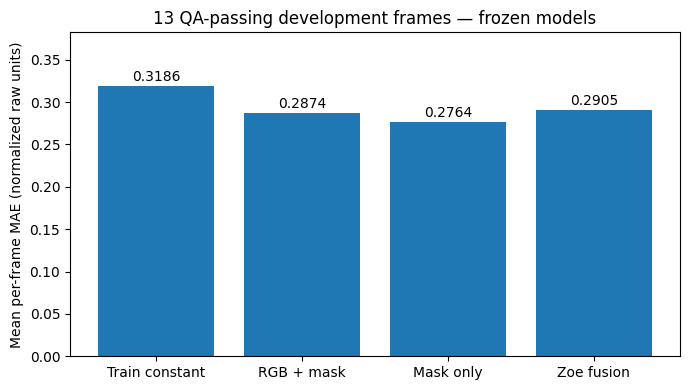

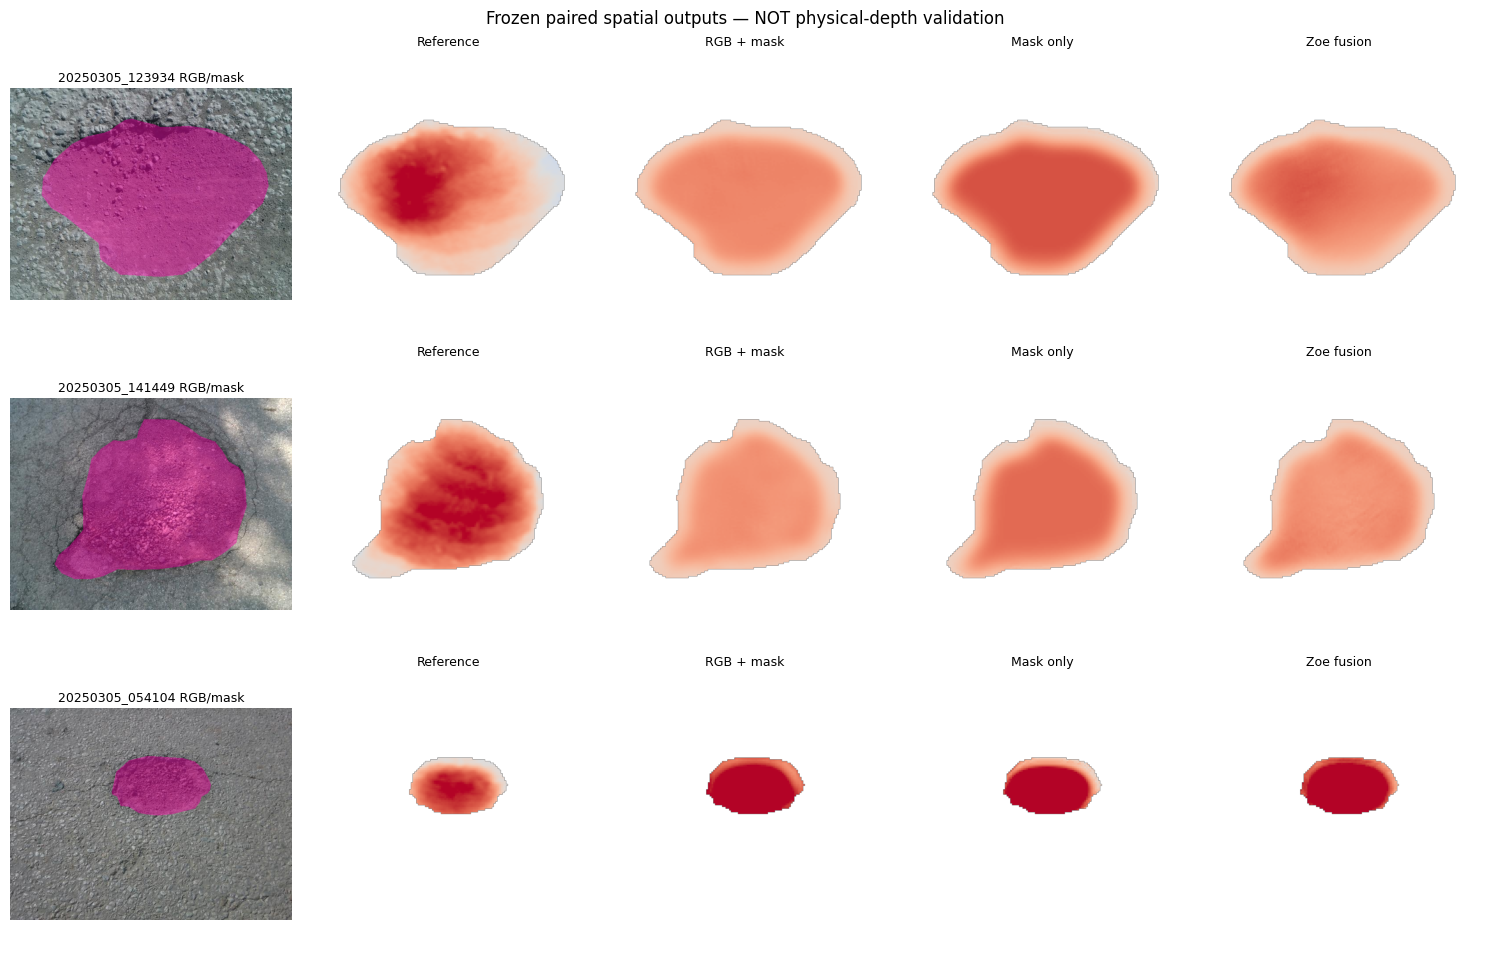


C3-05 SECTION 3 — FROZEN FUSION COMPARISON
mean_constant_mae_norm : 0.31864
mean_rgb_mae_norm : 0.28736
mean_mask_mae_norm : 0.27643
mean_fusion_mae_norm : 0.29045
fusion_beats_rgb_frames : 9
fusion_beats_mask_frames : 5
fusion_beats_constant_frames : 8
Models retrained: NO
Physical metric accuracy validated: NO
Independent physical scenes verified: NO

Saved evaluation: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-05_section03_FROZEN_FUSION_PAIRED_20261020T133140_378968Z


In [ ]:

# ============================================================
# C3-05 SECTION 3 — FROZEN FUSION PAIRED EVALUATION
#
# Compare:
#   1. Train-derived constant predictor
#   2. RGB + mask CRDL
#   3. Mask-only CRDL
#   4. ZoeDepth-assisted CRDL
#
# All trained weights FROZEN.
# Same 13 QA-passing development examples.
# No metric or independent-test claims.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import csv
import json
import hashlib
import sys

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)
DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

RGBNAME = (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)
MASKNAME = (
    "C3-03_section04_MASK_ONLY_ABLATION_"
    "20261020T101207_202510Z"
)
FUSIONNAME = (
    "C3-05_section02_ZOE_FUSION_TRAIN_"
    "20261020T131335_245452Z"
)
PNAME = (
    "C3-03_section03_FROZEN_UNSEEN_PROBE_"
    "20261020T091805_609498Z"
)
ABNAME = (
    "C3-03_section04B_PAIRED_ABLATION_"
    "20261020T115539_608453Z"
)

R = BASE / "06_model_checkpoints" / RGBNAME
M = BASE / "06_model_checkpoints" / MASKNAME
FZ = BASE / "06_model_checkpoints" / FUSIONNAME
FR = BASE / "05_training_runs" / FUSIONNAME
P = BASE / "07_evaluation" / PNAME
A = BASE / "07_evaluation" / ABNAME

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for root in (
    R, M, FZ, FR, P, A,
    DATA / "images",
    DATA / "labels",
    DATA / "depths"
):
    assert root.is_dir(), f"Missing: {root}"


# ------------------------------------------------------------
# 1. VERIFY SOURCE REPORTS AND CHECKPOINT CHECKSUMS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()


def check(folder, names):
    hashes = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, rel = line.split(None, 1)
        rel = rel.strip()
        path = Path(rel)

        assert not path.is_absolute()
        assert ".." not in path.parts
        assert rel not in hashes

        hashes[rel] = digest

    for rel in names:
        assert rel in hashes
        assert sha(folder / rel) == hashes[rel], rel

    return hashes


hr = check(R, [
    "model_development_only.pt",
    "crdl_dev_model.py"
])
hm = check(M, [
    "mask_only_ablation.pt",
    "crdl_dev_model.py"
])
hf = check(FZ, [
    "crdl_zoe_fusion_nonmetric.pt",
    "crdl_fusion_model.py",
    "crdl_fusion_preprocess.py",
    "crdl_dev_model.py"
])
hfr = check(FR, [
    "config_and_results.json",
    "feature_training_manifest.csv"
])
hp = check(P, [
    "frozen_unseen_probe_report.json",
    "selected_unseen_samples.csv"
])
ha = check(A, [
    "paired_ablation_report.json"
])

assert (
    hr["crdl_dev_model.py"]
    == hm["crdl_dev_model.py"]
    == hf["crdl_dev_model.py"]
)

probe = json.loads(
    (P / "frozen_unseen_probe_report.json").read_text()
)
paired = json.loads(
    (A / "paired_ablation_report.json").read_text()
)
fusion_cfg = json.loads(
    (FR / "config_and_results.json").read_text()
)

assert (
    paired["section3_report_sha256"]
    == hp["frozen_unseen_probe_report.json"]
)
assert (
    paired["rgb_checkpoint_sha256"]
    == hr["model_development_only.pt"]
)
assert (
    paired["mask_checkpoint_sha256"]
    == hm["mask_only_ablation.pt"]
)
assert (
    fusion_cfg["source_probe_report_sha"]
    == hp["frozen_unseen_probe_report.json"]
)
assert fusion_cfg["training_images"] == 33
assert fusion_cfg["physical_metric_accuracy"] is False

with (
    FR / "feature_training_manifest.csv"
).open(newline="") as file:
    training = list(csv.DictReader(file))

with (
    P / "selected_unseen_samples.csv"
).open(newline="") as file:
    selected = {
        row["sample_id"]: row
        for row in csv.DictReader(file)
    }

assert len(training) == 33
assert len(selected) == 60

assert {
    row["sample_id"] for row in training
}.isdisjoint(selected)

passed = {
    row["sample_id"]: row
    for row in probe["records"]
    if row["status"] == "DIAGNOSTIC_PASS"
}

old = {
    row["sample_id"]: row
    for row in paired["per_image"]
}

assert len(passed) == len(old) == 13
assert set(old) == set(passed)
assert set(old).issubset(selected)

print("Research provenance: PASS")
print("Training examples:", len(training))
print("Paired development examples:", len(old))
print("Training/evaluation filename overlap: ZERO")


# ------------------------------------------------------------
# 2. LOAD THREE EXISTING TRAINED NETWORKS
# ------------------------------------------------------------

sys.path.insert(0, str(FZ))

for name in (
    "crdl_dev_model",
    "crdl_fusion_model",
    "crdl_fusion_preprocess"
):
    sys.modules.pop(name, None)

from crdl_dev_model import (
    CRDLDevUNet,
    encode_input
)
from crdl_fusion_model import CRDLZoeFusionUNet
from crdl_fusion_preprocess import encode_fusion

pr = torch.load(
    R / "model_development_only.pt",
    map_location="cpu",
    weights_only=True
)
pm = torch.load(
    M / "mask_only_ablation.pt",
    map_location="cpu",
    weights_only=True
)
pf = torch.load(
    FZ / "crdl_zoe_fusion_nonmetric.pt",
    map_location="cpu",
    weights_only=True
)

assert pr["contract_version"] == "C3_DEV_NONMETRIC_V1"
assert pm["contract_version"] == "C3_MASK_ONLY_ABLATION_V1"
assert pf["contract_version"] == "C3_ZOE_FUSION_NONMETRIC_V1"

SCALE = float(pr["raw_target_scale"])

assert np.isclose(
    SCALE, float(pm["raw_target_scale"])
)
assert np.isclose(
    SCALE, float(pf["raw_target_scale"])
)

assert pf["zoe_model_id"] == fusion_cfg["zoe_pretrained_id"]
assert pf["zoe_revision"] == fusion_cfg["zoe_revision"]

RGB = CRDLDevUNet()
RGB.load_state_dict(pr["state_dict"])
RGB.eval()

MASK = CRDLDevUNet()
MASK.load_state_dict(pm["state_dict"])
MASK.eval()

FUSION = CRDLZoeFusionUNet()
FUSION.load_state_dict(pf["state_dict"])
FUSION.eval()

CFG = probe["source_affine_config"]
CONSTANT = float(
    probe["summary"]["training_constant_value_norm"]
)

print("All three frozen CRDL checkpoints: LOADED")


# ------------------------------------------------------------
# 3. ORIGINAL SEGMENTATION AND REFERENCE PROCESSING
# ------------------------------------------------------------

def make_mask(path, width, height):
    img = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(img)
    count = 0

    for line in path.read_text().splitlines():

        if not line.strip():
            continue

        vals = np.array(
            [float(v) for v in line.split()],
            dtype=np.float64
        )

        if (
            len(vals) < 7
            or (len(vals)-1) % 2 != 0
            or not np.isfinite(vals).all()
            or vals[0] != 0
        ):
            raise ValueError("Invalid mask polygon")

        xy = vals[1:].reshape(-1, 2)

        if (
            (xy < -0.001).any()
            or (xy > 1.001).any()
        ):
            raise ValueError("Invalid polygon positions")

        xy = np.clip(xy, 0, 1)

        draw.polygon(
            [
                (
                    round(x*(width-1)),
                    round(y*(height-1))
                )
                for x, y in xy
            ],
            fill=1
        )

        count += 1

    result = np.asarray(img, dtype=bool)

    assert count > 0 and result.any()

    return result


def basis(x, y, width, height):
    return np.column_stack([
        (x-(width-1)/2)/width,
        (y-(height-1)/2)/height,
        np.ones(len(x))
    ])


def irls(A, b):
    beta = np.linalg.lstsq(
        A, b, rcond=None
    )[0]

    for _ in range(CFG["irls_iterations"]):

        error = b - A @ beta
        med = np.median(error)

        mad = 1.4826 * np.median(
            np.abs(error-med)
        )

        cutoff = max(1.5*mad, 1e-6)

        weights = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(error-med), 1e-12
                )
            )
        )

        newer = np.linalg.lstsq(
            A*weights[:, None],
            b*weights,
            rcond=None
        )[0]

        if np.max(
            np.abs(newer-beta)
        ) < 1e-9:
            beta = newer
            break

        beta = newer

    return beta


def original_target(depth, mask, sid):
    h, w = depth.shape

    distance = distance_transform_edt(~mask)

    ring = (
        (depth > 0)
        & (distance >= CFG["ring_min_px"])
        & (distance <= CFG["ring_max_px"])
    )

    yy, xx = np.nonzero(ring)

    assert len(xx) >= CFG["min_support_pixels"]

    rng = np.random.default_rng(
        CFG["seed"] + int(sid[-6:])
    )

    ids = rng.choice(
        len(xx),
        min(CFG["max_ring_samples"], len(xx)),
        replace=False
    )

    yy, xx = yy[ids], xx[ids]
    z = depth[yy, xx].astype(np.float64)

    low, high = np.quantile(
        z, [0.001, 0.999]
    )

    keep = (z >= low) & (z <= high)

    yy, xx, z = (
        yy[keep],
        xx[keep],
        z[keep]
    )

    A = basis(xx, yy, w, h)
    inv = 1000.0 / z
    beta = irls(A, inv)

    road_prediction = A @ beta

    assert (road_prediction > 0).all()

    road_p95 = float(
        np.percentile(
            np.abs(
                z - 1000.0/road_prediction
            ),
            95
        )
    )

    ys, xs = np.nonzero(
        mask & (depth > 0)
    )

    reference_inv = (
        basis(xs, ys, w, h) @ beta
    )

    positive = reference_inv > 0

    reference = np.full(
        len(reference_inv),
        np.nan
    )

    reference[positive] = (
        1000.0/reference_inv[positive]
    )

    observed = depth[
        ys, xs
    ].astype(np.float64)

    plausible = (
        positive
        & (
            observed
            >= CFG["sensor_ratio_min"]*reference
        )
        & (
            observed
            <= CFG["sensor_ratio_max"]*reference
        )
    )

    target = np.full(
        (h, w),
        np.nan,
        dtype=np.float32
    )

    target[
        ys[plausible],
        xs[plausible]
    ] = (
        observed[plausible]
        - reference[plausible]
    ).astype(np.float32)

    return (
        target,
        np.isfinite(target),
        road_p95
    )


def supervised(rgb, mask, target, valid):
    x, geometry = encode_input(
        rgb, mask, 1.0, size=160
    )

    nh, nw = geometry["resized_hw"]
    top = geometry["pad_top"]
    left = geometry["pad_left"]

    valid_small = F.interpolate(
        torch.from_numpy(
            valid.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(
            np.where(
                valid, target, 0.0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    weight = (
        (valid_small >= 0.90).float()
        * x[
            3,
            top:top+nh,
            left:left+nw
        ][None, None]
    )

    y = torch.where(
        weight > 0,
        (
            numerator
            / valid_small.clamp_min(1e-8)
        ) / SCALE,
        torch.zeros_like(numerator)
    )

    padding = (
        left,
        160-nw-left,
        top,
        160-nh-top
    )

    return (
        x,
        F.pad(y, padding).squeeze(0),
        F.pad(weight, padding).squeeze(0)
    )


# ------------------------------------------------------------
# 4. REPRODUCE PREVIOUS MODEL SCORES FIRST
# ------------------------------------------------------------

items = []

with torch.inference_mode():

    for sid in sorted(old):

        record = passed[sid]
        row = selected[sid]
        previous = old[sid]

        paths = {
            kind: DATA / folder / row[field]
            for kind, folder, field in [
                ("rgb", "images", "rgb_filename"),
                ("label", "labels", "label_filename"),
                ("depth", "depths", "depth_filename")
            ]
        }

        for kind, path in paths.items():
            assert path.is_file()
            assert not path.is_symlink()

            assert sha(path) == record[
                f"{kind}_sha256"
            ], f"Source changed: {sid} {kind}"

        with Image.open(paths["rgb"]) as im:
            rgb = np.array(
                im.convert("RGB"),
                copy=True
            )

        depth = np.load(
            paths["depth"],
            allow_pickle=False
        )

        assert depth.dtype == np.uint16
        assert depth.shape == rgb.shape[:2]

        mask = make_mask(
            paths["label"],
            depth.shape[1],
            depth.shape[0]
        )

        target, valid, road_p95 = original_target(
            depth, mask, sid
        )

        assert abs(
            road_p95 - record["road_p95_raw"]
        ) < 2e-4

        x, y, weight = supervised(
            rgb, mask, target, valid
        )

        idx = weight > 0

        assert int(idx.sum()) == int(
            previous["valid_resized_pixels"]
        )

        true = y[idx].numpy()

        pred_rgb = RGB(
            x.unsqueeze(0)
        ).squeeze(0)

        xm = x.clone()
        xm[:3] = 0.0

        pred_mask = MASK(
            xm.unsqueeze(0)
        ).squeeze(0)

        rgb_mae = float(
            np.abs(
                true - pred_rgb[idx].numpy()
            ).mean()
        )

        mask_mae = float(
            np.abs(
                true - pred_mask[idx].numpy()
            ).mean()
        )

        baseline_mae = float(
            np.abs(true-CONSTANT).mean()
        )

        for current, saved in [
            (rgb_mae, previous["rgb_mae_norm"]),
            (mask_mae, previous["mask_only_mae_norm"]),
            (baseline_mae, previous["constant_mae_norm"])
        ]:
            assert abs(current-saved) < 2e-5, (
                f"Evaluation reproduction mismatch: {sid}"
            )

        items.append({
            "sid": sid,
            "rgb": rgb,
            "mask": mask,
            "x": x,
            "y": y,
            "weight": weight,
            "rgb_mae": rgb_mae,
            "mask_mae": mask_mae,
            "baseline_mae": baseline_mae,
            "rgb_pred": pred_rgb[0].numpy(),
            "mask_pred": pred_mask[0].numpy()
        })

print("Previous RGB/mask scores reproduced: PASS (13/13)")


# ------------------------------------------------------------
# 5. LOAD FROZEN ZOEDEPTH WITH CPU FALLBACK
# ------------------------------------------------------------

import transformers

assert transformers.__version__ == "4.48.3", (
    "Transformers 4.48.3 required. Current: "
    + transformers.__version__
)

from transformers import (
    AutoImageProcessor,
    AutoModelForDepthEstimation
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(
        min(4, torch.get_num_threads())
    )

print("ZoeDepth inference device:", DEVICE)

processor = AutoImageProcessor.from_pretrained(
    pf["zoe_model_id"],
    revision=pf["zoe_revision"]
)

ZOE = AutoModelForDepthEstimation.from_pretrained(
    pf["zoe_model_id"],
    revision=pf["zoe_revision"],
    use_safetensors=True
).to(DEVICE).eval()


# ------------------------------------------------------------
# 6. FROZEN FUSION EVALUATION
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = (
    BASE / "07_evaluation"
    / f"C3-05_section03_FROZEN_FUSION_PAIRED_{stamp}"
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

(OUT / "zoe_frozen_maps").mkdir()

records = []
previews = []

with torch.inference_mode():

    for i, item in enumerate(items, 1):

        inputs = processor(
            images=Image.fromarray(item["rgb"]),
            return_tensors="pt"
        ).to(DEVICE)

        output = ZOE(**inputs)

        processed = (
            processor.post_process_depth_estimation(
                output,
                source_sizes=[
                    item["rgb"].shape[:2]
                ]
            )
        )

        zoe_depth = (
            processed[0]["predicted_depth"]
            .detach()
            .cpu()
            .numpy()
            .astype(np.float32)
        )

        assert zoe_depth.shape == item["mask"].shape
        assert np.isfinite(zoe_depth).all()
        assert (zoe_depth > 0).all()

        fused, geometry = encode_fusion(
            item["rgb"],
            item["mask"],
            zoe_depth,
            pf["reference_config"],
            size=160
        )

        assert fused.shape == (7, 160, 160)

        assert torch.allclose(
            fused[:5],
            item["x"],
            atol=1e-6
        )

        prediction = (
            FUSION(fused.unsqueeze(0))
            [0, 0]
            .cpu()
            .numpy()
        )

        good = (
            item["weight"][0].numpy() > 0
        )

        actual = item["y"][0].numpy()

        fusion_mae = float(
            np.abs(
                actual[good] - prediction[good]
            ).mean()
        )

        filename = (
            f"zoe_frozen_maps/{item['sid']}.npz"
        )

        np.savez_compressed(
            OUT / filename,
            zoe_depth=zoe_depth
        )

        records.append({
            "sample_id": item["sid"],
            "fusion_mae_norm": fusion_mae,
            "rgb_mae_norm": item["rgb_mae"],
            "mask_only_mae_norm": item["mask_mae"],
            "constant_mae_norm": item["baseline_mae"],
            "valid_pixels": int(good.sum()),
            "zoe_cache": filename
        })

        previews.append({
            "sid": item["sid"],
            "rgb": item["rgb"],
            "mask": item["mask"],
            "true": actual,
            "valid": good,
            "fusion": prediction,
            "rgb_pred": item["rgb_pred"],
            "mask_pred": item["mask_pred"]
        })

        print(
            f"{i:02d}/13 | {item['sid']} "
            f"| Fusion: {fusion_mae:.4f} "
            f"| RGB: {item['rgb_mae']:.4f} "
            f"| Mask: {item['mask_mae']:.4f}"
        )

del ZOE

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 7. COMPUTE FOUR-MODEL PAIRED STATISTICS
# ------------------------------------------------------------

fusion_scores = np.array([
    r["fusion_mae_norm"] for r in records
])

rgb_scores = np.array([
    r["rgb_mae_norm"] for r in records
])

mask_scores = np.array([
    r["mask_only_mae_norm"] for r in records
])

constant_scores = np.array([
    r["constant_mae_norm"] for r in records
])

assert len(records) == 13

assert abs(
    rgb_scores.mean()
    - paired["summary"]["mean_rgb_mae_norm"]
) < 2e-5

assert abs(
    mask_scores.mean()
    - paired["summary"]["mean_mask_only_mae_norm"]
) < 2e-5

# Descriptive bootstrap only:
# not an independent scene-level confidence interval.
rng = np.random.default_rng(20261020)

indices = rng.integers(
    0, 13, size=(10000, 13)
)

def descriptive_interval(x):
    return np.percentile(
        x[indices].mean(axis=1),
        [2.5, 97.5]
    ).tolist()


summary = {
    "compared_frames": 13,
    "mean_constant_mae_norm":
        float(constant_scores.mean()),
    "mean_rgb_mae_norm":
        float(rgb_scores.mean()),
    "mean_mask_mae_norm":
        float(mask_scores.mean()),
    "mean_fusion_mae_norm":
        float(fusion_scores.mean()),
    "fusion_beats_rgb_frames":
        int((fusion_scores < rgb_scores).sum()),
    "fusion_beats_mask_frames":
        int((fusion_scores < mask_scores).sum()),
    "fusion_beats_constant_frames":
        int((fusion_scores < constant_scores).sum()),
    "mean_rgb_minus_fusion":
        float(np.mean(rgb_scores-fusion_scores)),
    "mean_mask_minus_fusion":
        float(np.mean(mask_scores-fusion_scores)),
    "descriptive_bootstrap_95_rgb_minus_fusion":
        descriptive_interval(rgb_scores-fusion_scores),
    "descriptive_bootstrap_95_mask_minus_fusion":
        descriptive_interval(mask_scores-fusion_scores),
    "units": "NORMALIZED_UNVERIFIED_POTHRGBD_RAW",
    "physically_independent_test": False,
    "metric_depth_validated": False,
    "severity_validated": False
}


# ------------------------------------------------------------
# 8. SAVE VERSIONED EVALUATION REPORT
# ------------------------------------------------------------

with (
    OUT / "paired_13_results.csv"
).open("w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(records[0])
    )

    writer.writeheader()
    writer.writerows(records)


report = {
    "stage": "C3-05_section03",
    "model_frozen": True,
    "zoe_frozen": True,
    "no_training": True,
    "original_QA_gates_unchanged": True,
    "provenance_sha": {
        "fusion_checkpoint":
            hf["crdl_zoe_fusion_nonmetric.pt"],
        "RGB_checkpoint":
            hr["model_development_only.pt"],
        "mask_checkpoint":
            hm["mask_only_ablation.pt"],
        "probe":
            hp["frozen_unseen_probe_report.json"],
        "matched_ablation":
            ha["paired_ablation_report.json"],
        "fusion_training_config":
            hfr["config_and_results.json"]
    },
    "zoe_model_id": pf["zoe_model_id"],
    "zoe_revision": pf["zoe_revision"],
    "note": (
        "Development comparison only. "
        "Possible related physical potholes; "
        "no certified physical reference."
    ),
    "summary": summary,
    "per_image": records
}

(
    OUT / "paired_fusion_report.json"
).write_text(
    json.dumps(report, indent=2)
)


# ------------------------------------------------------------
# 9. VISUAL COMPARISON
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 4)
)

values = [
    constant_scores.mean(),
    rgb_scores.mean(),
    mask_scores.mean(),
    fusion_scores.mean()
]

ax.bar(
    [
        "Train constant",
        "RGB + mask",
        "Mask only",
        "Zoe fusion"
    ],
    values
)

for j, value in enumerate(values):
    ax.text(
        j,
        value + 0.006,
        f"{value:.4f}",
        ha="center"
    )

ax.set_ylabel(
    "Mean per-frame MAE (normalized raw units)"
)

ax.set_title(
    "13 QA-passing development frames — frozen models"
)

ax.set_ylim(
    0,
    max(values)*1.2
)

fig.tight_layout()

fig.savefig(
    OUT / "paired_4model_mae.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 10. SAVE REPRESENTATIVE SPATIAL COMPARISONS
# ------------------------------------------------------------

difference = mask_scores - fusion_scores

chosen = list(dict.fromkeys([
    int(np.argmax(difference)),
    int(np.argmin(difference)),
    int(
        np.argsort(difference)[
            len(difference)//2
        ]
    )
]))

fig, axes = plt.subplots(
    len(chosen),
    5,
    figsize=(15, 3.3*len(chosen)),
    squeeze=False
)

for i, j in enumerate(chosen):

    ex = previews[j]

    overlay = ex["rgb"].copy()

    overlay[ex["mask"]] = (
        0.55*overlay[ex["mask"]]
        + 0.45*np.array([255, 0, 170])
    ).astype(np.uint8)

    axes[i, 0].imshow(overlay)

    axes[i, 0].set_title(
        ex["sid"] + " RGB/mask",
        fontsize=9
    )

    limit = max(
        0.15,
        float(
            np.percentile(
                np.abs(
                    ex["true"][ex["valid"]]
                ),
                95
            )
        )
    )

    for k, (array, title) in enumerate([
        (ex["true"], "Reference"),
        (ex["rgb_pred"], "RGB + mask"),
        (ex["mask_pred"], "Mask only"),
        (ex["fusion"], "Zoe fusion")
    ], 1):

        image = np.where(
            ex["valid"],
            array,
            np.nan
        )

        axes[i, k].imshow(
            np.ma.masked_invalid(image),
            cmap="coolwarm",
            vmin=-limit,
            vmax=limit
        )

        axes[i, k].set_title(
            title,
            fontsize=9
        )

    for subplot in axes[i]:
        subplot.axis("off")

fig.suptitle(
    "Frozen paired spatial outputs — "
    "NOT physical-depth validation"
)

fig.tight_layout()

fig.savefig(
    OUT / "four_model_spatial_previews.png",
    dpi=140
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 11. SAVE CHECKSUMS
# ------------------------------------------------------------

lines = []

for path in sorted(OUT.rglob("*")):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        lines.append(
            f"{sha(path)}  "
            f"{path.relative_to(OUT).as_posix()}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 12. FINAL RESEARCH SUMMARY
# ------------------------------------------------------------

print("\n" + "="*65)
print("C3-05 SECTION 3 — FROZEN FUSION COMPARISON")
print("="*65)

for key in [
    "mean_constant_mae_norm",
    "mean_rgb_mae_norm",
    "mean_mask_mae_norm",
    "mean_fusion_mae_norm",
    "fusion_beats_rgb_frames",
    "fusion_beats_mask_frames",
    "fusion_beats_constant_frames"
]:
    value = summary[key]

    print(
        key, ":",
        round(value, 5)
        if isinstance(value, float)
        else value
    )

print("Models retrained: NO")
print("Physical metric accuracy validated: NO")
print("Independent physical scenes verified: NO")
print("\nSaved evaluation:", OUT)
print("="*65)


Previous research integrity: PASS
Training examples: 33
Development comparison examples: 13
Training/evaluation filename overlap: ZERO
Frozen mask-only geometry model: LOADED
Numerical raw-target scale: 54.5197

Training preparation: PASS
Frozen prior training MAE: 0.22963

Training new boundary-residual CRDL...
Device: cpu
Epoch 01/24 | TRAIN-ONLY MAE: 0.22963
Epoch 02/24 | TRAIN-ONLY MAE: 0.22950
Epoch 03/24 | TRAIN-ONLY MAE: 0.22879
Epoch 04/24 | TRAIN-ONLY MAE: 0.22700
Epoch 05/24 | TRAIN-ONLY MAE: 0.22590
Epoch 06/24 | TRAIN-ONLY MAE: 0.22443
Epoch 07/24 | TRAIN-ONLY MAE: 0.22302
Epoch 08/24 | TRAIN-ONLY MAE: 0.22223
Epoch 09/24 | TRAIN-ONLY MAE: 0.22235
Epoch 10/24 | TRAIN-ONLY MAE: 0.23147
Epoch 11/24 | TRAIN-ONLY MAE: 0.22410
Epoch 12/24 | TRAIN-ONLY MAE: 0.22402
Epoch 13/24 | TRAIN-ONLY MAE: 0.22302
Epoch 14/24 | TRAIN-ONLY MAE: 0.22189
Epoch 15/24 | TRAIN-ONLY MAE: 0.22144
Epoch 16/24 | TRAIN-ONLY MAE: 0.22061
Epoch 17/24 | TRAIN-ONLY MAE: 0.22199
Epoch 18/24 | TRAIN-ONLY MAE

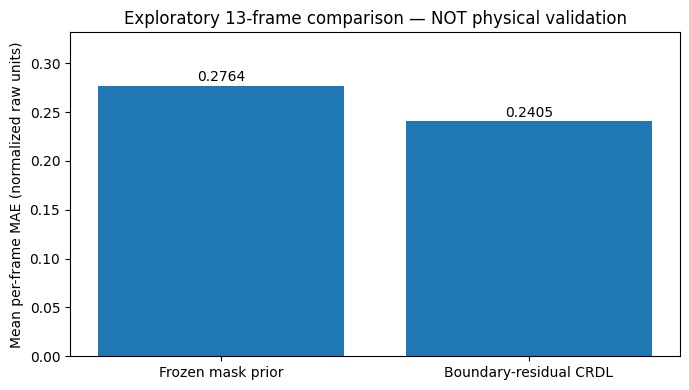

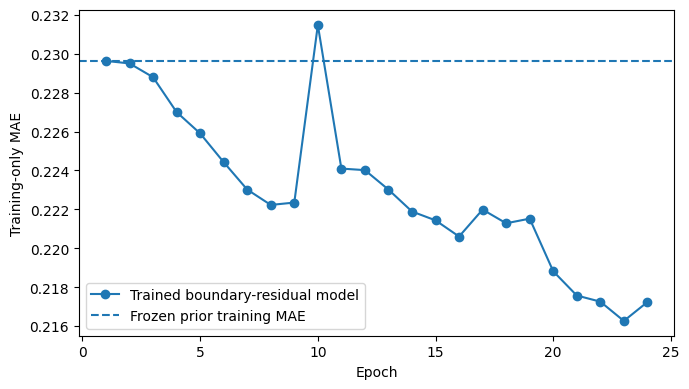

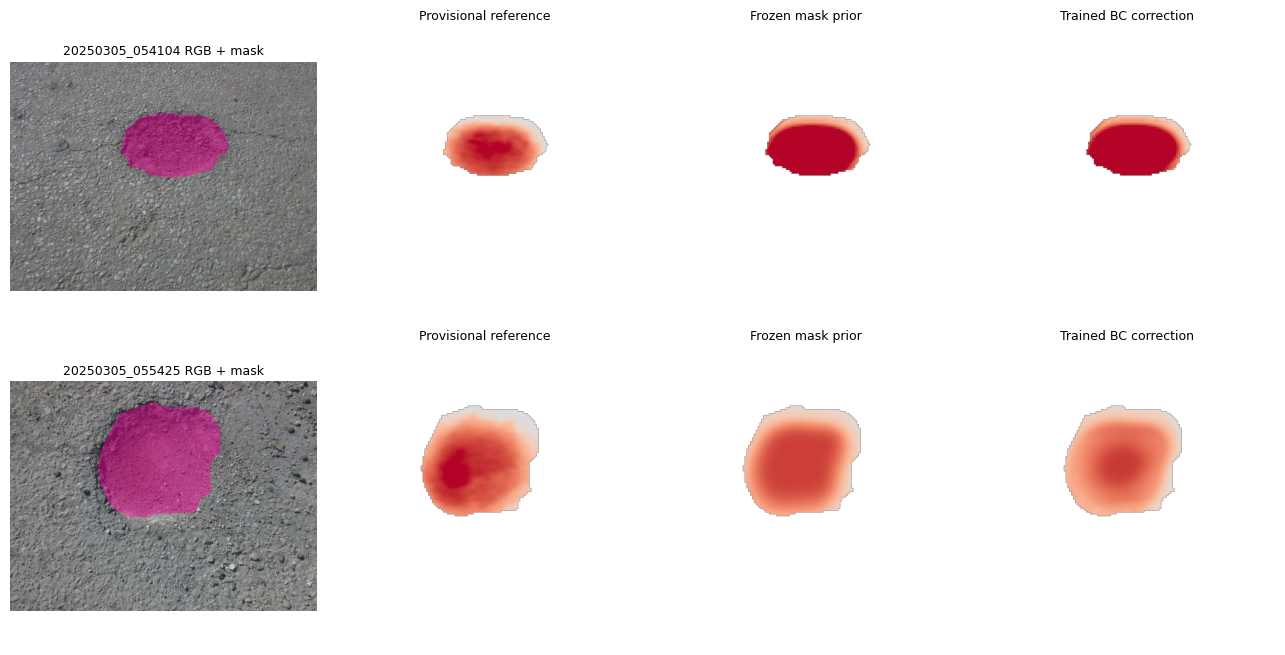


C3-06 SECTION 1 — BOUNDARY-RESIDUAL CRDL
Mask-only baseline MAE: 0.27643
New model MAE: 0.24049
Relative improvement (%): 13.0
New model wins: 10 /13
Development success gate: True
Checkpoint reload: PASS
Standalone inference: PASS
Independent physical validation: NO
Metric depth accuracy: UNVERIFIED
Severity prediction: NOT AUTHORIZED

Training: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-06_section01_BOUNDARY_RESIDUAL_20261020T135719_275138Z
Checkpoint: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-06_section01_BOUNDARY_RESIDUAL_20261020T135719_275138Z
Evaluation: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-06_section01_BOUNDARY_RESIDUAL_20261020T135719_275138Z


In [ ]:

# ============================================================
# C3-06 SECTION 1 — BOUNDARY-CONDITIONED RESIDUAL CRDL
#
# New trained ML approach:
# Frozen mask-only geometry prior + learned RGB correction
#
# TRAIN: 33 PothRGBD diagnostic-pass examples
# EVALUATE: Same 13 previously examined development frames
#
# NOT physically calibrated; NOT independent validation.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import csv, json, hashlib, shutil, importlib.util, sys, random


# ------------------------------------------------------------
# 1. EXISTING PROJECT PATHS
# ------------------------------------------------------------

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

N2 = (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)
NM = (
    "C3-03_section04_MASK_ONLY_ABLATION_"
    "20261020T101207_202510Z"
)
NP = (
    "C3-03_section03_FROZEN_UNSEEN_PROBE_"
    "20261020T091805_609498Z"
)
NA = (
    "C3-03_section04B_PAIRED_ABLATION_"
    "20261020T115539_608453Z"
)
N14 = (
    "C3-02_section14_PothRGBD_PILOT_"
    "20261020T081321_368363Z"
)
N16 = (
    "C3-02_section16_AFFINE_EXPANSION_"
    "20261020T082927_408953Z"
)

R2 = BASE / "05_training_runs" / N2
RM = BASE / "05_training_runs" / NM
M = BASE / "06_model_checkpoints" / NM
P = BASE / "07_evaluation" / NP
A = BASE / "07_evaluation" / NA
S14 = BASE / "04_geometry_targets" / N14
S16 = BASE / "04_geometry_targets" / N16

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for d in (
    R2, RM, M, P, A, S14, S16,
    DATA / "images",
    DATA / "labels",
    DATA / "depths"
):
    assert d.is_dir(), f"Missing folder: {d}"


# ------------------------------------------------------------
# 2. VERIFY SOURCE DATA AND PREVIOUS CHECKPOINTS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


def verified(root, names):
    hashes = {}

    for line in (
        root / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, rel = line.split(None, 1)
        rel = rel.strip()
        path = Path(rel)

        assert not path.is_absolute()
        assert ".." not in path.parts
        assert rel not in hashes

        hashes[rel] = digest

    for name in names:
        assert name in hashes
        assert (root / name).is_file()
        assert sha(root / name) == hashes[name], name

    return hashes


h2 = verified(R2, [
    "training_config.json",
    "train_only_manifest.csv"
])
hm = verified(M, [
    "crdl_dev_model.py",
    "mask_only_ablation.pt"
])
hmr = verified(RM, [
    "training_config.json",
    "train_only_manifest.csv"
])
hp = verified(P, [
    "frozen_unseen_probe_report.json",
    "selected_unseen_samples.csv"
])
ha = verified(A, [
    "paired_ablation_report.json"
])
h14 = verified(S14, ["pilot_quality_report.json"])
h16 = verified(S16, ["expansion_quality_report.json"])

oldconf = json.loads(
    (R2 / "training_config.json").read_text()
)
maskconf = json.loads(
    (RM / "training_config.json").read_text()
)
probe = json.loads(
    (P / "frozen_unseen_probe_report.json").read_text()
)
paired = json.loads(
    (A / "paired_ablation_report.json").read_text()
)

assert (
    paired["section3_report_sha256"]
    == hp["frozen_unseen_probe_report.json"]
)
assert (
    paired["mask_checkpoint_sha256"]
    == hm["mask_only_ablation.pt"]
)

assert oldconf["source_count"] == 33
assert maskconf["source_count"] == 33
assert oldconf["validation_performed"] is False
assert maskconf["independent_validation_performed"] is False

with (
    R2 / "train_only_manifest.csv"
).open(newline="") as f:
    train = list(csv.DictReader(f))

with (
    P / "selected_unseen_samples.csv"
).open(newline="") as f:
    selection = {
        r["sample_id"]: r
        for r in csv.DictReader(f)
    }

assert len(train) == 33
assert len({
    r["sample_id"] for r in train
}) == 33

assert len(selection) == 60
assert {
    r["sample_id"] for r in train
}.isdisjoint(selection)

accepted = {
    r["sample_id"]: r
    for r in probe["records"]
    if r["status"] == "DIAGNOSTIC_PASS"
}

comparison = {
    r["sample_id"]: r
    for r in paired["per_image"]
}

assert len(accepted) == len(comparison) == 13
assert set(accepted) == set(comparison)
assert set(accepted).issubset(selection)

print("Previous research integrity: PASS")
print("Training examples:", len(train))
print("Development comparison examples:", len(accepted))
print("Training/evaluation filename overlap: ZERO")


# ------------------------------------------------------------
# 3. LOAD THE FROZEN MASK-ONLY GEOMETRY PRIOR
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "crdl_bc_original_base",
    M / "crdl_dev_model.py"
)

base = importlib.util.module_from_spec(spec)
spec.loader.exec_module(base)

prior_pkg = torch.load(
    M / "mask_only_ablation.pt",
    weights_only=True,
    map_location="cpu"
)

assert (
    prior_pkg["contract_version"]
    == "C3_MASK_ONLY_ABLATION_V1"
)
assert prior_pkg["rgb_channels_disabled"] is True

SCALE = float(prior_pkg["raw_target_scale"])

assert abs(
    SCALE - float(oldconf["raw_target_normalizer"])
) < 1e-5

PRIOR = base.CRDLDevUNet().cpu().eval()

PRIOR.load_state_dict(
    prior_pkg["state_dict"],
    strict=True
)

for parameter in PRIOR.parameters():
    parameter.requires_grad_(False)

print("Frozen mask-only geometry model: LOADED")
print("Numerical raw-target scale:", round(SCALE, 4))


# ------------------------------------------------------------
# 4. DEFINE THE NEW BOUNDARY-RESIDUAL ARCHITECTURE
# ------------------------------------------------------------

ARCH = r'''
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.ndimage import distance_transform_edt
from crdl_dev_model import encode_input


def build_features(rgb, mask, prior):

    rgb = np.asarray(rgb)
    mask = np.asarray(mask, dtype=bool)

    x, g = encode_input(
        np.array(rgb, copy=True),
        mask,
        confidence=1.0,
        size=160
    )

    m = x[3:4].clone()

    distance = distance_transform_edt(
        m[0].numpy() > 0.5
    ).astype(np.float32)

    maximum = max(float(distance.max()), 1.0)

    radial = torch.from_numpy(
        distance / maximum
    )[None]

    gate = torch.from_numpy(
        np.clip(distance / 6.0, 0.0, 1.0)
    )[None]

    gray = (
        0.299 * x[0:1]
        + 0.587 * x[1:2]
        + 0.114 * x[2:3]
    ).unsqueeze(0)

    texture = (
        gray
        - F.avg_pool2d(
            gray, 7, stride=1, padding=3
        )
    )[0]

    features = torch.cat([
        x[:3],
        m,
        radial,
        gate,
        prior.detach().cpu(),
        texture
    ], dim=0)

    assert features.shape == (8, 160, 160)

    return features, g


class Block(nn.Module):

    def __init__(self, channels_in, channels_out):
        super().__init__()

        self.seq = nn.Sequential(
            nn.Conv2d(
                channels_in, channels_out,
                3, padding=1
            ),
            nn.GroupNorm(4, channels_out),
            nn.SiLU(),
            nn.Conv2d(
                channels_out, channels_out,
                3, padding=1
            ),
            nn.GroupNorm(4, channels_out),
            nn.SiLU()
        )

    def forward(self, x):
        return self.seq(x)


class BoundaryResidualCRDL(nn.Module):

    def __init__(self):
        super().__init__()

        self.e1 = Block(8, 16)
        self.e2 = Block(16, 32)
        self.b = Block(32, 64)
        self.d2 = Block(96, 32)
        self.d1 = Block(48, 16)

        self.head = nn.Conv2d(16, 1, 1)

        # Initially predict zero correction.
        # The model starts from the frozen prior.
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):

        a = self.e1(x)

        b = self.e2(
            F.avg_pool2d(a, 2)
        )

        z = self.b(
            F.avg_pool2d(b, 2)
        )

        z = self.d2(
            torch.cat([
                F.interpolate(
                    z,
                    size=b.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                ),
                b
            ], dim=1)
        )

        z = self.d1(
            torch.cat([
                F.interpolate(
                    z,
                    size=a.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                ),
                a
            ], dim=1)
        )

        # Bounded learned geometry correction.
        # The gate reduces correction near the rim.
        correction = (
            1.5
            * torch.tanh(self.head(z))
            * x[:, 5:6]
        )

        # Initial road-relative prediction
        # plus trainable spatial correction.
        result = x[:, 6:7] + correction

        return result, correction
'''


# ------------------------------------------------------------
# 5. STANDALONE INFERENCE IMPLEMENTATION
# ------------------------------------------------------------

INFERENCE = r'''
from pathlib import Path
import sys
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path(__file__).resolve().parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from crdl_dev_model import (
    CRDLDevUNet,
    encode_input
)

from bc_residual_model import (
    BoundaryResidualCRDL,
    build_features
)


def load_models(checkpoint_dir):

    folder = Path(checkpoint_dir)

    prior_pkg = torch.load(
        folder / "frozen_mask_prior.pt",
        map_location="cpu",
        weights_only=True
    )

    package = torch.load(
        folder / "bc_residual.pt",
        map_location="cpu",
        weights_only=True
    )

    assert (
        package["contract_version"]
        == "C3_BC_RESIDUAL_V1"
    )
    assert (
        prior_pkg["contract_version"]
        == "C3_MASK_ONLY_ABLATION_V1"
    )

    assert np.isclose(
        package["raw_target_scale"],
        prior_pkg["raw_target_scale"]
    )

    prior = CRDLDevUNet().eval()

    prior.load_state_dict(
        prior_pkg["state_dict"],
        strict=True
    )

    model = BoundaryResidualCRDL().eval()

    model.load_state_dict(
        package["state_dict"],
        strict=True
    )

    return prior, model, package


def predict(
    rgb,
    damage_mask,
    checkpoint_dir,
    confidence=1.0
):

    if float(confidence) != 1.0:
        raise ValueError(
            "Only fixed confidence=1.0 was "
            "exercised in development"
        )

    prior, model, package = load_models(
        checkpoint_dir
    )

    image = np.array(rgb, copy=True)

    mask = np.asarray(
        damage_mask,
        dtype=bool
    )

    with torch.inference_mode():

        original, g = encode_input(
            image,
            mask,
            1.0,
            size=160
        )

        mask_input = original.clone()
        mask_input[:3] = 0

        prior_map = prior(
            mask_input[None]
        )[0]

        features, _ = build_features(
            image,
            mask,
            prior_map
        )

        result, _ = model(
            features[None]
        )

        top = g["pad_top"]
        left = g["pad_left"]

        nh, nw = g["resized_hw"]
        h, w = g["original_hw"]

        cropped = result[
            ...,
            top:top+nh,
            left:left+nw
        ]

        array = F.interpolate(
            cropped,
            size=(h, w),
            mode="bilinear",
            align_corners=False
        )[0, 0].numpy().astype(np.float32)

    array *= float(
        package["raw_target_scale"]
    )

    array[~mask] = np.nan

    return {
        "signed_axial_residual_raw": array,
        "status": "NONMETRIC_ENGINEERING_ONLY",
        "units": "UNVERIFIED_POTHRGBD_RAW",
        "metric_severity_available": False,
        "confidence_calibrated": False
    }
'''


# ------------------------------------------------------------
# 6. CREATE VERSIONED OUTPUT FOLDERS
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

name = (
    "C3-06_section01_BOUNDARY_RESIDUAL_"
    + stamp
)

RUN = BASE / "05_training_runs" / name
CKPT = BASE / "06_model_checkpoints" / name
EV = BASE / "07_evaluation" / name

for folder in (RUN, CKPT, EV):
    folder.mkdir(
        parents=True,
        exist_ok=False
    )

shutil.copy2(
    M / "crdl_dev_model.py",
    CKPT / "crdl_dev_model.py"
)

shutil.copy2(
    M / "mask_only_ablation.pt",
    CKPT / "frozen_mask_prior.pt"
)

assert (
    sha(CKPT / "frozen_mask_prior.pt")
    == hm["mask_only_ablation.pt"]
)

(CKPT / "bc_residual_model.py").write_text(
    ARCH
)

(CKPT / "bc_residual_infer.py").write_text(
    INFERENCE
)

if str(CKPT) not in sys.path:
    sys.path.insert(0, str(CKPT))

sys.modules.pop("crdl_dev_model", None)
sys.modules.pop("bc_residual_model", None)

from bc_residual_model import (
    BoundaryResidualCRDL,
    build_features
)


# ------------------------------------------------------------
# 7. MATCH PREVIOUS TRAINING TARGET PREPROCESSING
# ------------------------------------------------------------

def encode_target(rgb, mask, target, valid):

    x, g = base.encode_input(
        np.array(rgb, copy=True),
        mask,
        1.0,
        size=160
    )

    nh, nw = g["resized_hw"]
    top = g["pad_top"]
    left = g["pad_left"]

    v = F.interpolate(
        torch.from_numpy(
            valid.astype(np.float32)
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(
            np.where(
                valid,
                target,
                0.0
            ).astype(np.float32)
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    region = x[
        3,
        top:top+nh,
        left:left+nw
    ][None, None]

    weight = (
        (v >= 0.90).float()
        * region
    )

    value = torch.where(
        weight > 0,
        numerator / v.clamp_min(1e-8) / SCALE,
        torch.zeros_like(numerator)
    )

    padding = (
        left,
        160-nw-left,
        top,
        160-nh-top
    )

    return (
        x,
        F.pad(value, padding)[0],
        F.pad(weight, padding)[0]
    )


# ------------------------------------------------------------
# 8. PREPARE EXACTLY THE SAME 33 TRAINING EXAMPLES
# ------------------------------------------------------------

xs, ys, ws = [], [], []

for index, row in enumerate(train, 1):

    source = (
        S14 if row["source_stage"] == S14.name
        else S16
    )

    assert row["source_stage"] in {
        S14.name, S16.name
    }

    hashes = h14 if source == S14 else h16

    relative = row["npz_relative"]
    target_path = source / relative

    assert relative in hashes
    assert (
        sha(target_path)
        == hashes[relative]
        == row["npz_sha256"]
    )

    rgb_path = (
        DATA / "images" / row["rgb_filename"]
    )

    assert sha(rgb_path) == row["rgb_sha256"]

    with Image.open(rgb_path) as im:
        rgb = np.array(
            im.convert("RGB"),
            copy=True
        )

    with np.load(
        target_path,
        allow_pickle=False
    ) as package:

        mask = package[
            "damage_mask"
        ].astype(bool)

        target = package[
            "signed_axial_raw"
        ].astype(np.float32)

        valid = package[
            "valid_target_mask"
        ].astype(bool)

    assert (
        target.shape
        == mask.shape
        == valid.shape
        == rgb.shape[:2]
    )

    assert np.array_equal(
        valid,
        np.isfinite(target)
    )

    assert np.all(
        ~valid | mask
    )

    x, y, weight = encode_target(
        rgb,
        mask,
        target,
        valid
    )

    with torch.inference_mode():

        mask_input = x.clone()
        mask_input[:3] = 0

        prior = PRIOR(
            mask_input[None]
        )[0]

        features, _ = build_features(
            rgb,
            mask,
            prior
        )

    assert float(weight.sum()) > 5
    assert torch.isfinite(y).all()

    xs.append(features)
    ys.append(y)
    ws.append(weight)

X = torch.stack(xs)
Y = torch.stack(ys)
W = torch.stack(ws)

assert X.shape == (33, 8, 160, 160)
assert Y.shape == (33, 1, 160, 160)
assert W.shape == (33, 1, 160, 160)

with torch.inference_mode():

    prior_train_mae = float(
        (
            (X[:, 6:7]-Y).abs() * W
        ).sum() / W.sum()
    )

assert abs(
    prior_train_mae
    - float(
        maskconf[
            "mask_only_best_training_mae_norm"
        ]
    )
) < 2e-4

print("\nTraining preparation: PASS")
print(
    "Frozen prior training MAE:",
    round(prior_train_mae, 5)
)


# ------------------------------------------------------------
# 9. DEFINE GEOMETRY-AWARE SUPERVISED LOSS
# ------------------------------------------------------------

def geometry_loss(prediction, correction, y, weight):

    pixel_loss = (
        F.smooth_l1_loss(
            prediction,
            y,
            reduction="none",
            beta=0.2
        ) * weight
    ).sum() / weight.sum().clamp_min(1)

    wx = (
        weight[:, :, :, 1:]
        * weight[:, :, :, :-1]
    )

    wy = (
        weight[:, :, 1:, :]
        * weight[:, :, :-1, :]
    )

    dx_error = (
        (
            prediction[:, :, :, 1:]
            - prediction[:, :, :, :-1]
        )
        -
        (
            y[:, :, :, 1:]
            - y[:, :, :, :-1]
        )
    ).abs()

    dy_error = (
        (
            prediction[:, :, 1:, :]
            - prediction[:, :, :-1, :]
        )
        -
        (
            y[:, :, 1:, :]
            - y[:, :, :-1, :]
        )
    ).abs()

    grad_x = (
        (dx_error*wx).sum()
        / wx.sum().clamp_min(1)
    )

    grad_y = (
        (dy_error*wy).sum()
        / wy.sum().clamp_min(1)
    )

    correction_reg = (
        (correction.square()*weight).sum()
        / weight.sum().clamp_min(1)
    )

    # Fixed loss composition.
    return (
        pixel_loss
        + 0.12*(grad_x+grad_y)/2
        + 0.01*correction_reg
    )


# ------------------------------------------------------------
# 10. TRAIN THE RESIDUAL-CORRECTION NETWORK
# ------------------------------------------------------------

SEED = 20261020
EPOCHS = 24
BATCH_SIZE = 4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

if DEVICE.type == "cpu":
    try:
        torch.set_num_threads(
            min(4, torch.get_num_threads())
        )
    except RuntimeError:
        pass

net = BoundaryResidualCRDL().to(DEVICE)

optimizer = torch.optim.AdamW(
    net.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

history = []
best_mae = float("inf")
best_epoch = None

print("\nTraining new boundary-residual CRDL...")
print("Device:", DEVICE)

for epoch in range(1, EPOCHS+1):

    net.train()

    order = torch.randperm(
        33,
        generator=(
            torch.Generator().manual_seed(
                SEED + epoch
            )
        )
    )

    for ids in order.split(BATCH_SIZE):

        xb = X[ids].to(DEVICE)
        yb = Y[ids].to(DEVICE)
        wb = W[ids].to(DEVICE)

        optimizer.zero_grad(
            set_to_none=True
        )

        prediction, correction = net(xb)

        loss = geometry_loss(
            prediction,
            correction,
            yb,
            wb
        )

        assert torch.isfinite(loss)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            net.parameters(),
            1.0
        )

        optimizer.step()

    # Training-only assessment.
    net.eval()

    absolute_error = 0.0

    with torch.inference_mode():

        for ids in torch.arange(
            33
        ).split(BATCH_SIZE):

            prediction, _ = net(
                X[ids].to(DEVICE)
            )

            absolute_error += float(
                (
                    (prediction.cpu()-Y[ids]).abs()
                    * W[ids]
                ).sum()
            )

    mae = (
        absolute_error / float(W.sum())
    )

    history.append({
        "epoch": epoch,
        "train_mae_norm": mae
    })

    # Select by training reconstruction only.
    # Development examples are not used here.
    if mae < best_mae:

        best_mae = mae
        best_epoch = epoch

        torch.save(
            {
                "contract_version":
                    "C3_BC_RESIDUAL_V1",
                "state_dict": net.state_dict(),
                "raw_target_scale": SCALE,
                "frozen_prior_sha256":
                    hm["mask_only_ablation.pt"],
                "best_training_epoch": epoch,
                "metric_units_verified": False,
                "validation_performed": False
            },
            CKPT / "bc_residual.pt"
        )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"TRAIN-ONLY MAE: {mae:.5f}"
    )


# ------------------------------------------------------------
# 11. RELOAD THE TRAINED RESIDUAL CHECKPOINT
# ------------------------------------------------------------

saved = torch.load(
    CKPT / "bc_residual.pt",
    map_location="cpu",
    weights_only=True
)

model = BoundaryResidualCRDL().eval()

model.load_state_dict(
    saved["state_dict"],
    strict=True
)

with torch.inference_mode():

    smoke_prediction, _ = model(
        X[0:1]
    )

assert np.isfinite(
    smoke_prediction.numpy()
).all()

print("\nLearned correction checkpoint reload: PASS")


# ------------------------------------------------------------
# 12. PREPARE PREVIOUSLY ACCEPTED DEVELOPMENT TARGETS
# ------------------------------------------------------------

CFG = probe["source_affine_config"]


def mask_from_polygon(path, width, height):

    canvas = Image.new(
        "L", (width, height), 0
    )

    drawer = ImageDraw.Draw(canvas)
    count = 0

    for line in path.read_text().splitlines():

        if not line.strip():
            continue

        values = np.array(
            [float(v) for v in line.split()],
            dtype=np.float64
        )

        assert (
            len(values) >= 7
            and (len(values)-1) % 2 == 0
            and values[0] == 0
            and np.isfinite(values).all()
        )

        polygon = values[1:].reshape(-1, 2)

        assert (polygon >= -0.001).all()
        assert (polygon <= 1.001).all()

        drawer.polygon(
            [
                (
                    round(x*(width-1)),
                    round(y*(height-1))
                )
                for x, y in np.clip(polygon, 0, 1)
            ],
            fill=1
        )

        count += 1

    result = np.asarray(
        canvas, dtype=bool
    )

    assert count > 0 and result.any()

    return result


def affine_basis(x, y, width, height):

    return np.column_stack([
        (x-(width-1)/2)/width,
        (y-(height-1)/2)/height,
        np.ones(len(x))
    ])


def reconstruct_target(depth, mask, sid):

    h, w = depth.shape

    distance = distance_transform_edt(
        ~mask
    )

    ring = (
        (depth > 0)
        & (distance >= CFG["ring_min_px"])
        & (distance <= CFG["ring_max_px"])
    )

    ry, rx = np.nonzero(ring)

    assert len(rx) >= CFG["min_support_pixels"]

    rng = np.random.default_rng(
        CFG["seed"] + int(sid[-6:])
    )

    ids = rng.choice(
        len(rx),
        min(
            CFG["max_ring_samples"],
            len(rx)
        ),
        replace=False
    )

    ry, rx = ry[ids], rx[ids]

    z = depth[
        ry, rx
    ].astype(np.float64)

    low, high = np.quantile(
        z, [0.001, 0.999]
    )

    use = (
        (z >= low)
        & (z <= high)
    )

    ry, rx, z = (
        ry[use],
        rx[use],
        z[use]
    )

    A = affine_basis(
        rx, ry, w, h
    )

    b = 1000.0/z

    beta = np.linalg.lstsq(
        A, b, rcond=None
    )[0]

    for _ in range(CFG["irls_iterations"]):

        error = b - A @ beta
        median = np.median(error)

        mad = 1.4826 * np.median(
            np.abs(error-median)
        )

        cutoff = max(
            1.5*mad, 1e-6
        )

        weight = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(error-median),
                    1e-12
                )
            )
        )

        newer = np.linalg.lstsq(
            A*weight[:, None],
            b*weight,
            rcond=None
        )[0]

        if np.max(
            np.abs(newer-beta)
        ) < 1e-9:
            beta = newer
            break

        beta = newer

    fitted = A @ beta

    assert (fitted > 0).all()

    road_p95 = float(
        np.percentile(
            np.abs(z-1000.0/fitted),
            95
        )
    )

    yy, xx = np.nonzero(
        mask & (depth > 0)
    )

    inverse = (
        affine_basis(xx, yy, w, h)
        @ beta
    )

    okay = inverse > 0

    reference = np.full(
        inverse.shape,
        np.nan
    )

    reference[okay] = (
        1000.0/inverse[okay]
    )

    observed = depth[
        yy, xx
    ].astype(np.float64)

    okay = (
        okay
        & (
            observed
            >= CFG["sensor_ratio_min"]*reference
        )
        & (
            observed
            <= CFG["sensor_ratio_max"]*reference
        )
    )

    target = np.full(
        (h, w),
        np.nan,
        dtype=np.float32
    )

    target[
        yy[okay],
        xx[okay]
    ] = (
        observed[okay]
        - reference[okay]
    ).astype(np.float32)

    return (
        target,
        np.isfinite(target),
        road_p95
    )


# ------------------------------------------------------------
# 13. EVALUATE ON THE SAME 13 DEVELOPMENT FRAMES
# ------------------------------------------------------------

results = []
previews = []

with torch.inference_mode():

    for sid in sorted(comparison):

        rec = accepted[sid]
        source = selection[sid]

        paths = {
            kind: DATA / folder / source[column]
            for kind, folder, column in [
                ("rgb", "images", "rgb_filename"),
                ("label", "labels", "label_filename"),
                ("depth", "depths", "depth_filename")
            ]
        }

        for kind, path in paths.items():

            assert path.is_file()

            assert sha(path) == rec[
                kind + "_sha256"
            ], (sid, kind)

        with Image.open(paths["rgb"]) as im:
            rgb = np.array(
                im.convert("RGB"),
                copy=True
            )

        depth = np.load(
            paths["depth"],
            allow_pickle=False
        )

        assert depth.dtype == np.uint16
        assert depth.shape == rgb.shape[:2]

        mask = mask_from_polygon(
            paths["label"],
            depth.shape[1],
            depth.shape[0]
        )

        target, valid, road_p95 = (
            reconstruct_target(
                depth, mask, sid
            )
        )

        assert abs(
            road_p95
            - float(rec["road_p95_raw"])
        ) < 2e-4

        x, y, weight = encode_target(
            rgb, mask, target, valid
        )

        mask_input = x.clone()
        mask_input[:3] = 0

        prior = PRIOR(
            mask_input[None]
        )[0]

        features, _ = build_features(
            rgb,
            mask,
            prior
        )

        refined, correction = model(
            features[None]
        )

        idx = weight > 0

        actual = y[idx].numpy()
        prior_pixels = prior[idx].numpy()
        refined_pixels = (
            refined[0][idx].numpy()
        )

        prior_mae = float(
            np.mean(
                np.abs(actual-prior_pixels)
            )
        )

        # Reproduce original mask-only result
        # before scoring the proposed approach.
        assert abs(
            prior_mae
            - float(
                comparison[sid][
                    "mask_only_mae_norm"
                ]
            )
        ) < 2e-5, sid

        new_mae = float(
            np.mean(
                np.abs(
                    actual-refined_pixels
                )
            )
        )

        results.append({
            "sample_id": sid,
            "burst": rec["burst"],
            "mask_prior_mae_norm": prior_mae,
            "boundary_residual_mae_norm": new_mae,
            "improvement_norm": prior_mae-new_mae,
            "valid_pixels": int(idx.sum())
        })

        previews.append({
            "sid": sid,
            "rgb": rgb,
            "mask": mask,
            "target": y[0].numpy(),
            "prior": prior[0].numpy(),
            "refined": refined[0, 0].numpy(),
            "valid": weight[0].numpy() > 0
        })

        print(
            sid,
            "| Prior:", round(prior_mae, 4),
            "| New:", round(new_mae, 4)
        )


# ------------------------------------------------------------
# 14. SUMMARY AND FIXED DEVELOPMENT SUCCESS CHECK
# ------------------------------------------------------------

prior_scores = np.array([
    r["mask_prior_mae_norm"]
    for r in results
])

new_scores = np.array([
    r["boundary_residual_mae_norm"]
    for r in results
])

assert len(results) == 13

assert abs(
    float(prior_scores.mean())
    - float(
        paired["summary"][
            "mean_mask_only_mae_norm"
        ]
    )
) < 2e-5

summary = {
    "compared_frames": 13,
    "mask_prior_mae_norm": float(
        prior_scores.mean()
    ),
    "boundary_residual_mae_norm": float(
        new_scores.mean()
    ),
    "mean_improvement_norm": float(
        (prior_scores-new_scores).mean()
    ),
    "model_wins_frames": int(
        (new_scores < prior_scores).sum()
    ),
    "relative_mean_improvement_pct": float(
        100 * (
            prior_scores.mean()
            - new_scores.mean()
        ) / prior_scores.mean()
    ),
    "fixed_development_gate_met": bool(
        new_scores.mean() < prior_scores.mean()
    ),
    "metric_depth_validation": False,
    "independent_scene_validation": False
}


# ------------------------------------------------------------
# 15. SAVE TRAINING, API AND EVALUATION REPORTS
# ------------------------------------------------------------

(CKPT / "api_contract.json").write_text(
    json.dumps({
        "version": "C3_BC_RESIDUAL_V1",
        "inputs": (
            "RGB uint8 HxWx3, aligned binary "
            "pothole mask, fixed confidence=1.0"
        ),
        "output": (
            "signed_axial_residual_raw HxW float32, "
            "NaN outside mask"
        ),
        "physical_units": "UNVERIFIED",
        "trained_metric_model": False,
        "metric_severity_available": False,
        "calibrated_confidence": False,
        "model_weights": (
            "Frozen mask-only prior and trained "
            "boundary-conditioned correction"
        )
    }, indent=2)
)

with (
    RUN / "train_manifest.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(train[0])
    )

    writer.writeheader()
    writer.writerows(train)

with (
    RUN / "epoch_metrics.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(history[0])
    )

    writer.writeheader()
    writer.writerows(history)

(RUN / "config_and_results.json").write_text(
    json.dumps({
        "stage": "C3-06_section01",
        "hypothesis": (
            "RGB-conditioned, boundary-constrained "
            "learned correction of frozen mask-only "
            "road-relative geometry"
        ),
        "train_images": 33,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "seed": SEED,
        "learning_rate": 5e-4,
        "optimizer": "AdamW weight_decay=1e-4",
        "gradient_loss_weight": 0.12,
        "correction_L2_weight": 0.01,
        "correction_bound_normalized": 1.5,
        "boundary_gate_px": 6,
        "best_train_epoch": best_epoch,
        "best_train_mae_norm": best_mae,
        "frozen_prior_train_mae_norm":
            prior_train_mae,
        "original_prior_checkpoint_sha256":
            hm["mask_only_ablation.pt"],
        "source_train_manifest_sha256":
            h2["train_only_manifest.csv"],
        "source_development_report_sha256":
            ha["paired_ablation_report.json"],
        "model_selected_using_training_only": True,
        "development_set_previously_consulted": True,
        "physically_independent_test": False,
        "metric_units_verified": False,
        "torch_version": torch.__version__
    }, indent=2)
)

with (
    EV / "paired_development.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(results[0])
    )

    writer.writeheader()
    writer.writerows(results)

(EV / "paired_development_report.json").write_text(
    json.dumps({
        "summary": summary,
        "per_image": results,
        "note": (
            "Previously used development pool; "
            "13 geometry-QA-passing files. "
            "Not an independent scientific test."
        )
    }, indent=2)
)


# ------------------------------------------------------------
# 16. VISUALIZE MAE COMPARISON
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4))

values = [
    float(prior_scores.mean()),
    float(new_scores.mean())
]

ax.bar(
    [
        "Frozen mask prior",
        "Boundary-residual CRDL"
    ],
    values
)

for i, value in enumerate(values):

    ax.text(
        i,
        value+0.005,
        f"{value:.4f}",
        ha="center"
    )

ax.set_ylabel(
    "Mean per-frame MAE (normalized raw units)"
)

ax.set_ylim(
    0,
    max(values)*1.2
)

ax.set_title(
    "Exploratory 13-frame comparison — "
    "NOT physical validation"
)

fig.tight_layout()

fig.savefig(
    EV / "mean_mae.png",
    dpi=140
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 17. TRAINING-ONLY LOSS CURVE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    [r["epoch"] for r in history],
    [r["train_mae_norm"] for r in history],
    marker="o",
    label="Trained boundary-residual model"
)

ax.axhline(
    prior_train_mae,
    linestyle="--",
    label="Frozen prior training MAE"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Training-only MAE")
ax.legend()

fig.tight_layout()

fig.savefig(
    RUN / "train_only_curve.png",
    dpi=140
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 18. SPATIAL COMPARISONS
# ------------------------------------------------------------

gains = prior_scores - new_scores

chosen = list(dict.fromkeys([
    int(np.argmax(gains)),
    int(np.argmin(gains))
]))

fig, axes = plt.subplots(
    len(chosen),
    4,
    figsize=(13, 3.3*len(chosen)),
    squeeze=False
)

for i, j in enumerate(chosen):

    ex = previews[j]

    overlay = ex["rgb"].copy()

    overlay[ex["mask"]] = (
        overlay[ex["mask"]]*0.55
        + np.array([255, 0, 160])*0.45
    ).astype(np.uint8)

    axes[i, 0].imshow(overlay)

    axes[i, 0].set_title(
        ex["sid"] + " RGB + mask",
        fontsize=9
    )

    limit = max(
        0.15,
        float(
            np.percentile(
                np.abs(
                    ex["target"][ex["valid"]]
                ),
                95
            )
        )
    )

    titles = {
        "target": "Provisional reference",
        "prior": "Frozen mask prior",
        "refined": "Trained BC correction"
    }

    for k, key in enumerate(
        ["target", "prior", "refined"],
        1
    ):

        array = np.where(
            ex["valid"],
            ex[key],
            np.nan
        )

        axes[i, k].imshow(
            np.ma.masked_invalid(array),
            cmap="coolwarm",
            vmin=-limit,
            vmax=limit
        )

        axes[i, k].set_title(
            titles[key],
            fontsize=9
        )

    for axis in axes[i]:
        axis.axis("off")

fig.tight_layout()

fig.savefig(
    EV / "spatial_comparison.png",
    dpi=140
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 19. STANDALONE LOAD / INFERENCE SMOKE TEST
# ------------------------------------------------------------

from bc_residual_infer import predict as api_predict

first = train[0]

folder = (
    S14 if first["source_stage"] == S14.name
    else S16
)

with Image.open(
    DATA / "images" / first["rgb_filename"]
) as im:

    rgb = np.array(
        im.convert("RGB"),
        copy=True
    )

with np.load(
    folder / first["npz_relative"],
    allow_pickle=False
) as package:

    mask = package[
        "damage_mask"
    ].astype(bool)

test = api_predict(
    rgb,
    mask,
    CKPT
)

output = test[
    "signed_axial_residual_raw"
]

assert output.shape == mask.shape
assert np.isfinite(output[mask]).all()
assert np.isnan(output[~mask]).all()

(CKPT / "smoke_test.json").write_text(
    json.dumps({
        "checkpoint_reload": "PASS",
        "standalone_inference": "PASS",
        "source_role": "TRAIN_ONLY",
        "physical_depth_validation": False
    }, indent=2)
)


# ------------------------------------------------------------
# 20. EXPORT SHA-256 CHECKSUMS
# ------------------------------------------------------------

for folder in (RUN, CKPT, EV):

    lines = []

    for path in sorted(
        folder.rglob("*")
    ):

        if (
            path.is_file()
            and path.name != "checksums.sha256"
            and "__pycache__" not in path.parts
        ):

            relative = (
                path.relative_to(folder).as_posix()
            )

            lines.append(
                f"{sha(path)}  {relative}"
            )

    (
        folder / "checksums.sha256"
    ).write_text(
        "\n".join(lines) + "\n"
    )


# ------------------------------------------------------------
# 21. FINAL RESEARCH SUMMARY
# ------------------------------------------------------------

print("\n" + "="*65)
print("C3-06 SECTION 1 — BOUNDARY-RESIDUAL CRDL")
print("="*65)

print(
    "Mask-only baseline MAE:",
    round(
        summary["mask_prior_mae_norm"],
        5
    )
)

print(
    "New model MAE:",
    round(
        summary["boundary_residual_mae_norm"],
        5
    )
)

print(
    "Relative improvement (%):",
    round(
        summary[
            "relative_mean_improvement_pct"
        ],
        2
    )
)

print(
    "New model wins:",
    summary["model_wins_frames"],
    "/13"
)

print(
    "Development success gate:",
    summary["fixed_development_gate_met"]
)

print("Checkpoint reload: PASS")
print("Standalone inference: PASS")
print("Independent physical validation: NO")
print("Metric depth accuracy: UNVERIFIED")
print("Severity prediction: NOT AUTHORIZED")

print("\nTraining:", RUN)
print("Checkpoint:", CKPT)
print("Evaluation:", EV)

print("="*65)


POTHRGBD_BURST_0002 | eligible: 175 | selected: 40
POTHRGBD_BURST_0003 | eligible: 231 | selected: 40
POTHRGBD_BURST_0005 | eligible: 405 | selected: 40

Selection integrity: PASS
New previously unused filenames: 120
Earlier 185 examples excluded: YES
Independent pothole identities: UNVERIFIED

Both trained models: FROZEN AND LOADED
Frozen evaluation protocol: SAVED
20/120 | {'DIAGNOSTIC_FAIL': 17, 'DIAGNOSTIC_PASS': 2, 'ERROR': 1}
40/120 | {'DIAGNOSTIC_FAIL': 26, 'DIAGNOSTIC_PASS': 10, 'ERROR': 4}
60/120 | {'DIAGNOSTIC_FAIL': 41, 'DIAGNOSTIC_PASS': 14, 'ERROR': 5}
80/120 | {'DIAGNOSTIC_FAIL': 57, 'DIAGNOSTIC_PASS': 18, 'ERROR': 5}
100/120 | {'DIAGNOSTIC_FAIL': 73, 'DIAGNOSTIC_PASS': 22, 'ERROR': 5}
120/120 | {'DIAGNOSTIC_FAIL': 89, 'DIAGNOSTIC_PASS': 26, 'ERROR': 5}


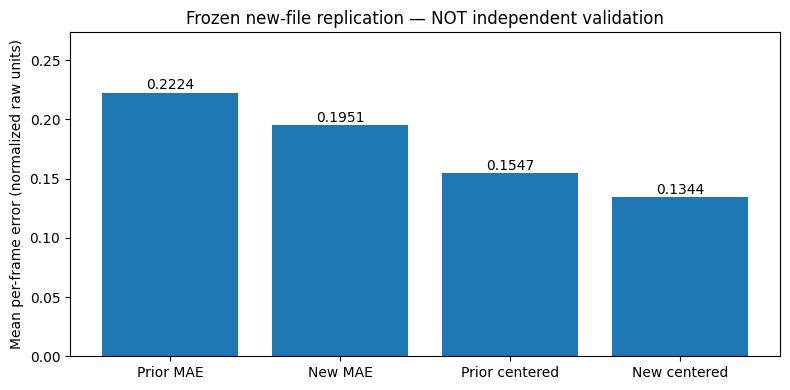

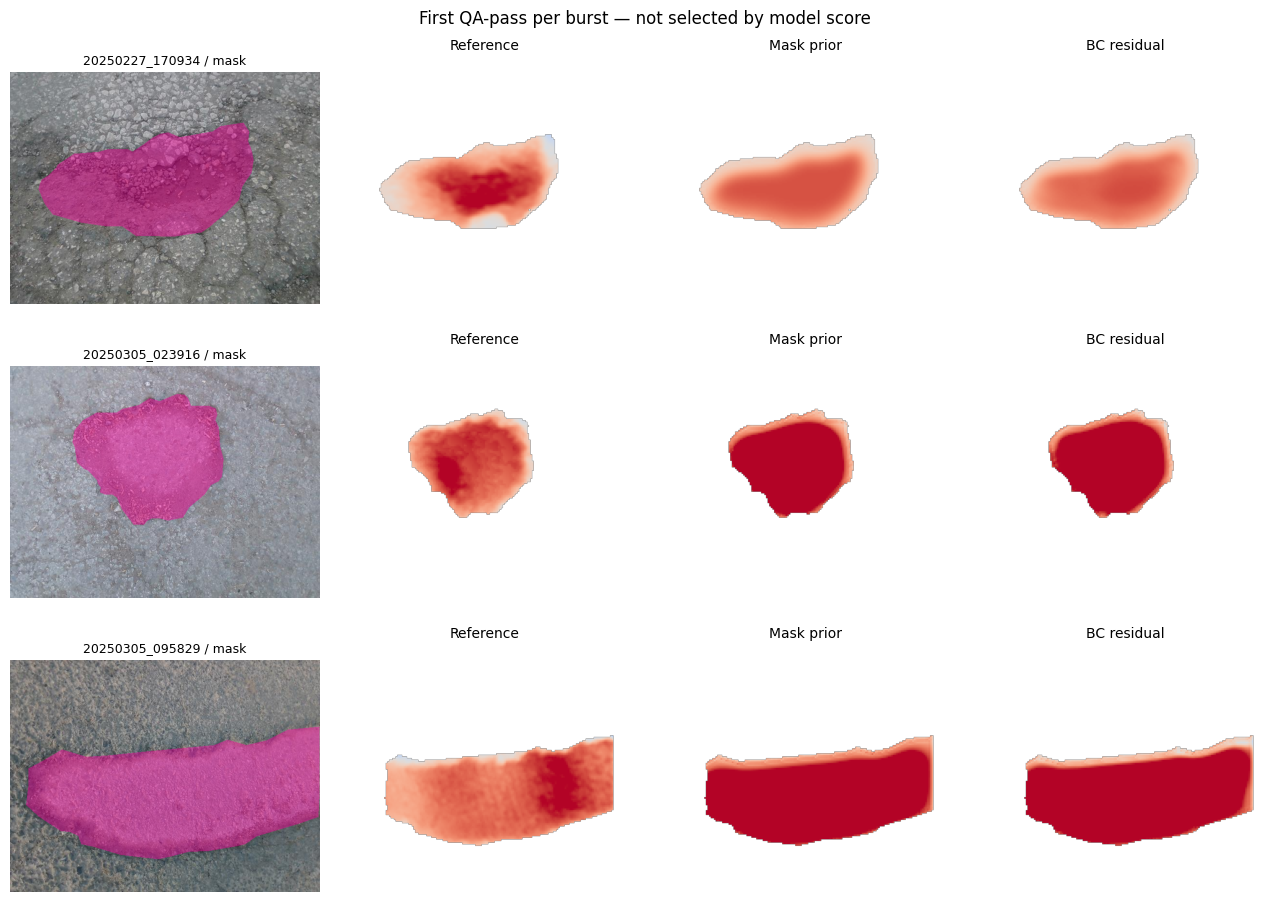


C3-06 SECTION 2 — FROZEN NEW-FILE REPLICATION
Previously unused filenames: 120
QA statuses: {'DIAGNOSTIC_FAIL': 89, 'DIAGNOSTIC_PASS': 26, 'ERROR': 5}
Scored accepted frames: 26
Minimum descriptive support passed: True
Previous model MAE: 0.22243868530942842
New BC residual MAE: 0.19511897260179886
Relative improvement (%): 12.281907110548621
Centered shape-only MAE: 0.1547182543346515 0.13440042877426514
Spatial gradient MAE: 0.021187932337992467 0.020458798318241652
Model weights changed: NO
Independent physical validation: NO
Metric depth accuracy: UNVERIFIED

Saved output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-06_section02_NEWFILE_REPLICATION_20261020T140141_065363Z


In [ ]:

# ================================================================
# C3-06 SECTION 2 — FROZEN NEW-FILENAME REPLICATION
#
# 120 precommitted, previously unused PothRGBD frames.
# Trained weights frozen. Reference QA unchanged.
# No physical metric or independent-scene claims.
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
from scipy.stats import spearmanr

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

import json
import csv
import hashlib
import sys


# ------------------------------------------------------------
# 1. SOURCE PATHS
# ------------------------------------------------------------

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

N = (
    "C3-06_section01_BOUNDARY_RESIDUAL_"
    "20261020T134808_315581Z"
)

S12 = BASE / (
    "03_splits_manifests/"
    "C3-02_section12_PothRGBD_Groups_"
    "20261020T075921_028539Z"
)

S14 = BASE / (
    "04_geometry_targets/"
    "C3-02_section14_PothRGBD_PILOT_"
    "20261020T081321_368363Z"
)

S16 = BASE / (
    "04_geometry_targets/"
    "C3-02_section16_AFFINE_EXPANSION_"
    "20261020T082927_408953Z"
)

S3 = BASE / (
    "07_evaluation/"
    "C3-03_section03_FROZEN_UNSEEN_PROBE_"
    "20261020T091805_609498Z"
)

BC = BASE / "06_model_checkpoints" / N
BR = BASE / "05_training_runs" / N

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for d in (
    S12, S14, S16, S3, BC, BR,
    DATA / "images",
    DATA / "labels",
    DATA / "depths"
):
    assert d.is_dir(), f"Missing directory: {d}"


# ------------------------------------------------------------
# 2. VERIFY PREVIOUS EXPERIMENTS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for b in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(b)

    return h.hexdigest()


def verify(folder, names):
    checks = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, name = line.split(None, 1)
        name = name.strip()

        rel = Path(name)

        assert not rel.is_absolute()
        assert ".." not in rel.parts
        assert name not in checks

        checks[name] = digest

    for name in names:
        assert name in checks
        assert (folder / name).is_file()

        assert sha(folder / name) == checks[name], (
            f"Checksum failed: {folder / name}"
        )

    return checks


h12 = verify(S12, [
    "capture_group_readiness.json",
    "pothrgbd_filename_capture_manifest.csv"
])

h14 = verify(S14, [
    "pilot_quality_report.json"
])

h16 = verify(S16, [
    "expansion_quality_report.json"
])

h3 = verify(S3, [
    "frozen_unseen_probe_report.json",
    "selected_unseen_samples.csv"
])

hbc = verify(BC, [
    "bc_residual.pt",
    "frozen_mask_prior.pt",
    "bc_residual_model.py",
    "crdl_dev_model.py",
    "smoke_test.json"
])

hbr = verify(BR, [
    "config_and_results.json",
    "train_manifest.csv"
])

p14 = json.loads(
    (S14 / "pilot_quality_report.json").read_text()
)

p16 = json.loads(
    (S16 / "expansion_quality_report.json").read_text()
)

p3 = json.loads(
    (S3 / "frozen_unseen_probe_report.json").read_text()
)

bcfg = json.loads(
    (BR / "config_and_results.json").read_text()
)

assert p14["configuration"] == p16["config"]

CFG = p14["configuration"]

assert len(p14["records"]) == 25
assert len(p16["records"]) == 100
assert len(p3["records"]) == 60

assert bcfg["train_images"] == 33

assert (
    bcfg["original_prior_checkpoint_sha256"]
    == hbc["frozen_mask_prior.pt"]
)

assert bcfg["physically_independent_test"] is False
assert bcfg["metric_units_verified"] is False


# ------------------------------------------------------------
# 3. PRESELECT 120 NEW, UNUSED FILENAMES
# ------------------------------------------------------------

with (
    S12 / "pothrgbd_filename_capture_manifest.csv"
).open(newline="") as f:

    manifest = list(csv.DictReader(f))

with (
    BR / "train_manifest.csv"
).open(newline="") as f:

    training = list(csv.DictReader(f))

train_ids = {
    x["sample_id"]
    for x in training
}

assert len(train_ids) == 33

used = {
    x["sample_id"]
    for x in (
        p14["records"]
        + p16["records"]
        + p3["records"]
    )
}

assert train_ids.issubset(used)

assert len(used) == 185, (
    "Previous selection overlap or count changed"
)

selected = []

bursts = (
    "POTHRGBD_BURST_0002",
    "POTHRGBD_BURST_0003",
    "POTHRGBD_BURST_0005"
)

for burst in bursts:

    pool = sorted(
        [
            x for x in manifest
            if (
                x["strict_pair_verified"] == "True"
                and x["provisional_burst"] == burst
                and x["sample_id"] not in used
            )
        ],
        key=lambda x: x["sample_id"]
    )

    assert len(pool) >= 40, (
        burst, len(pool)
    )

    indices = np.linspace(
        0,
        len(pool) - 1,
        40,
        dtype=int
    )

    assert len(set(indices.tolist())) == 40

    selected.extend(
        pool[int(i)]
        for i in indices
    )

    print(
        burst,
        "| eligible:", len(pool),
        "| selected:", 40
    )

selected_ids = {
    x["sample_id"]
    for x in selected
}

assert len(selected) == 120
assert len(selected_ids) == 120
assert selected_ids.isdisjoint(used)

print("\nSelection integrity: PASS")
print("New previously unused filenames:", 120)
print("Earlier 185 examples excluded: YES")
print("Independent pothole identities: UNVERIFIED")


# ------------------------------------------------------------
# 4. LOAD BOTH FROZEN MODELS
# ------------------------------------------------------------

if str(BC) not in sys.path:
    sys.path.insert(0, str(BC))

for name in (
    "crdl_dev_model",
    "bc_residual_model"
):
    sys.modules.pop(name, None)

from crdl_dev_model import (
    CRDLDevUNet,
    encode_input
)

from bc_residual_model import (
    BoundaryResidualCRDL,
    build_features
)

frozen = torch.load(
    BC / "frozen_mask_prior.pt",
    map_location="cpu",
    weights_only=True
)

correction = torch.load(
    BC / "bc_residual.pt",
    map_location="cpu",
    weights_only=True
)

assert (
    frozen["contract_version"]
    == "C3_MASK_ONLY_ABLATION_V1"
)

assert (
    correction["contract_version"]
    == "C3_BC_RESIDUAL_V1"
)

assert (
    correction["frozen_prior_sha256"]
    == hbc["frozen_mask_prior.pt"]
)

SCALE = float(
    frozen["raw_target_scale"]
)

assert np.isclose(
    SCALE,
    correction["raw_target_scale"]
)

prior = CRDLDevUNet().eval()

prior.load_state_dict(
    frozen["state_dict"],
    strict=True
)

model = BoundaryResidualCRDL().eval()

model.load_state_dict(
    correction["state_dict"],
    strict=True
)

for net in (prior, model):
    for parameter in net.parameters():
        parameter.requires_grad_(False)

try:
    torch.set_num_threads(
        min(4, torch.get_num_threads())
    )
except RuntimeError:
    pass

print("\nBoth trained models: FROZEN AND LOADED")


# ------------------------------------------------------------
# 5. COMMIT EVALUATION SELECTION BEFORE SCORING
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "07_evaluation" / (
    "C3-06_section02_NEWFILE_REPLICATION_"
    + stamp
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

selected_fields = [
    "sample_id",
    "provisional_burst",
    "rgb_filename",
    "label_filename",
    "depth_filename"
]

selection_file = (
    OUT / "precommitted_120_filenames.csv"
)

with selection_file.open(
    "w", newline=""
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=selected_fields
    )

    writer.writeheader()

    for row in selected:
        writer.writerow({
            name: row[name]
            for name in selected_fields
        })


protocol = {
    "stage": "C3-06_section02",
    "selected_n": 120,
    "selection": (
        "Deterministic linspace: 40 untouched "
        "strict triplets each from bursts "
        "0002, 0003 and 0005."
    ),
    "source_manifest_sha256":
        h12["pothrgbd_filename_capture_manifest.csv"],
    "old_examples_excluded": 185,
    "prior_checkpoint_sha256":
        hbc["frozen_mask_prior.pt"],
    "correction_checkpoint_sha256":
        hbc["bc_residual.pt"],
    "source_affine_QA": CFG,
    "selection_before_scoring": True,
    "primary_metric": (
        "Mean per-frame masked MAE: "
        "BC residual versus frozen prior"
    ),
    "secondary_metrics": [
        "Median-centered MAE",
        "Valid-neighbor gradient MAE",
        "Per-frame wins"
    ],
    "minimum_descriptive_support": 15,
    "training_weights_frozen": True,
    "physical_scene_independence_verified": False,
    "units": "UNVERIFIED_POTHRGBD_RAW",
    "severity_enabled": False
}

(
    OUT / "precommitted_protocol.json"
).write_text(
    json.dumps(protocol, indent=2)
)

print("Frozen evaluation protocol: SAVED")


# ------------------------------------------------------------
# 6. ORIGINAL YOLO POLYGON READER
# ------------------------------------------------------------

def polygon_mask(path, w, h):

    canvas = Image.new(
        "L", (w, h), 0
    )

    draw = ImageDraw.Draw(canvas)
    count = 0

    for line in path.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        arr = np.array(
            [float(v) for v in line.split()],
            dtype=np.float64
        )

        if (
            len(arr) < 7
            or (len(arr)-1) % 2
            or arr[0] != 0
            or not np.isfinite(arr).all()
        ):
            raise ValueError(
                "Invalid YOLO polygon"
            )

        xy = arr[1:].reshape(-1, 2)

        if (
            (xy < -0.001).any()
            or (xy > 1.001).any()
        ):
            raise ValueError(
                "Polygon outside image"
            )

        draw.polygon(
            [
                (
                    round(x*(w-1)),
                    round(y*(h-1))
                )
                for x, y in np.clip(xy, 0, 1)
            ],
            fill=1
        )

        count += 1

    result = np.asarray(
        canvas,
        dtype=bool
    )

    if count == 0 or not result.any():
        raise ValueError(
            "Empty polygon"
        )

    return result


# ------------------------------------------------------------
# 7. LOCKED AFFINE REFERENCE METHOD
# ------------------------------------------------------------

def basis(x, y, w, h):

    return np.column_stack([
        (x-(w-1)/2)/w,
        (y-(h-1)/2)/h,
        np.ones(len(x))
    ])


def irls(A, b):

    beta = np.linalg.lstsq(
        A, b,
        rcond=None
    )[0]

    for _ in range(
        CFG["irls_iterations"]
    ):

        e = b - A @ beta
        med = np.median(e)

        mad = 1.4826 * np.median(
            np.abs(e-med)
        )

        cutoff = max(
            1.5*mad,
            1e-6
        )

        weights = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(e-med),
                    1e-12
                )
            )
        )

        new = np.linalg.lstsq(
            A*weights[:, None],
            b*weights,
            rcond=None
        )[0]

        if np.max(
            np.abs(new-beta)
        ) < 1e-9:
            beta = new
            break

        beta = new

    return beta


def original_reference(depth, mask, sid):

    h, w = depth.shape
    finite = depth > 0

    distance = distance_transform_edt(
        ~mask
    )

    ring = (
        finite
        & (
            distance
            >= CFG["ring_min_px"]
        )
        & (
            distance
            <= CFG["ring_max_px"]
        )
    )

    ry, rx = np.nonzero(ring)

    if len(rx) < CFG["min_support_pixels"]:
        raise ValueError(
            "Insufficient healthy-road support"
        )

    rng = np.random.default_rng(
        CFG["seed"] + int(sid[-6:])
    )

    chosen = rng.choice(
        len(rx),
        min(
            CFG["max_ring_samples"],
            len(rx)
        ),
        replace=False
    )

    ry, rx = (
        ry[chosen],
        rx[chosen]
    )

    z = depth[
        ry, rx
    ].astype(np.float64)

    lo, hi = np.quantile(
        z,
        [0.001, 0.999]
    )

    keep = (
        (z >= lo)
        & (z <= hi)
    )

    ry, rx, z = (
        ry[keep],
        rx[keep],
        z[keep]
    )

    A = basis(rx, ry, w, h)
    inv = 1000.0 / z

    beta = irls(A, inv)

    fitted = A @ beta

    if (fitted <= 0).any():
        raise ValueError(
            "Invalid inverse-depth reference"
        )

    road_p95 = float(
        np.percentile(
            np.abs(
                z - 1000.0/fitted
            ),
            95
        )
    )

    # Four-sector spatial holdout,
    # matching the original locked QA.

    cy, cx = np.mean(
        np.nonzero(mask),
        axis=1
    )

    angles = np.mod(
        np.arctan2(
            ry-cy,
            rx-cx
        ) + 2*np.pi,
        2*np.pi
    )

    sectors = np.minimum(
        (
            angles / (np.pi/2)
        ).astype(int),
        3
    )

    holdouts = []

    for sector in range(4):

        test = sectors == sector
        train = ~test

        if (
            test.sum()
            < CFG["min_sector_test_pixels"]
            or train.sum()
            < CFG["min_support_pixels"]
        ):
            holdouts.append(None)
            continue

        cv_beta = irls(
            A[train],
            inv[train]
        )

        predicted = A[test] @ cv_beta

        if (predicted <= 0).any():
            holdouts.append(None)
            continue

        holdouts.append(
            float(
                np.percentile(
                    np.abs(
                        z[test]
                        - 1000.0/predicted
                    ),
                    95
                )
            )
        )

    yy, xx = np.nonzero(
        mask & finite
    )

    predicted_inv = (
        basis(xx, yy, w, h) @ beta
    )

    okay = predicted_inv > 0

    reference = np.full(
        len(predicted_inv),
        np.nan
    )

    reference[okay] = (
        1000.0/predicted_inv[okay]
    )

    observed = depth[
        yy, xx
    ].astype(np.float64)

    plausible = (
        okay
        & (
            observed
            >= CFG["sensor_ratio_min"]
            * reference
        )
        & (
            observed
            <= CFG["sensor_ratio_max"]
            * reference
        )
    )

    residual = np.full(
        (h, w),
        np.nan,
        dtype=np.float32
    )

    residual[
        yy[plausible],
        xx[plausible]
    ] = (
        observed[plausible]
        - reference[plausible]
    ).astype(np.float32)

    valid = np.isfinite(residual)
    values = residual[valid]

    if len(values) < 100:
        raise ValueError(
            "Insufficient target pixels"
        )

    coverage = float(
        valid.sum() / mask.sum()
    )

    magnitude = float(
        np.median(
            np.abs(values)
        )
    )

    positive = float(
        np.mean(values > 0)
    )

    signal = float(
        magnitude
        / max(road_p95, 1e-9)
    )

    worst = (
        max(holdouts)
        if all(
            x is not None
            for x in holdouts
        )
        else None
    )

    ratio = (
        worst / max(magnitude, 1e-9)
        if worst is not None
        else None
    )

    flags = []

    if (
        coverage
        < CFG["min_valid_target_fraction"]
    ):
        flags.append(
            "LOW_VALID_GEOMETRY"
        )

    if (
        positive
        < CFG["min_positive_fraction"]
    ):
        flags.append(
            "AMBIGUOUS_RESIDUAL_SIGN"
        )

    if (
        signal
        < CFG["min_signal_to_road_p95"]
    ):
        flags.append(
            "LOW_GEOMETRY_SIGNAL"
        )

    if worst is None:
        flags.append(
            "INCOMPLETE_SPATIAL_HOLDOUT"
        )

    elif (
        ratio
        > CFG["max_worst_holdout_to_signal"]
    ):
        flags.append(
            "WEAK_SPATIAL_HOLDOUT"
        )

    qa = {
        "coverage": coverage,
        "positive_fraction": positive,
        "road_p95_raw": road_p95,
        "signal_to_road_p95": signal,
        "holdout_to_signal": ratio,
        "flags": flags
    }

    return residual, valid, qa


# ------------------------------------------------------------
# 8. SAME TARGET PREPROCESSING AS EARLIER MODELS
# ------------------------------------------------------------

def supervision(
    rgb, mask, valid, target
):

    x, g = encode_input(
        rgb,
        mask,
        confidence=1.0,
        size=160
    )

    nh, nw = g["resized_hw"]
    top = g["pad_top"]
    left = g["pad_left"]

    valid_small = F.interpolate(
        torch.from_numpy(
            valid.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(
            np.where(
                valid, target, 0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    weight = (
        (valid_small >= 0.90).float()
        * x[
            3,
            top:top+nh,
            left:left+nw
        ][None, None]
    )

    target_small = torch.where(
        weight > 0,
        (
            numerator
            / valid_small.clamp_min(1e-8)
        ) / SCALE,
        torch.zeros_like(numerator)
    )

    padding = (
        left,
        160-nw-left,
        top,
        160-nh-top
    )

    y = F.pad(
        target_small, padding
    )[0, 0].numpy()

    m = (
        F.pad(weight, padding)
        [0, 0].numpy() > 0
    )

    return x, y, m


# ------------------------------------------------------------
# 9. SPATIAL GRADIENT EVALUATION
# ------------------------------------------------------------

def gradient_mae(y, prediction, valid):

    valid_x = (
        valid[:, 1:]
        & valid[:, :-1]
    )

    valid_y = (
        valid[1:, :]
        & valid[:-1, :]
    )

    n = int(
        valid_x.sum()
        + valid_y.sum()
    )

    if n == 0:
        return None

    error_x = np.abs(
        (
            prediction[:, 1:]
            - prediction[:, :-1]
        )
        -
        (
            y[:, 1:]
            - y[:, :-1]
        )
    )

    error_y = np.abs(
        (
            prediction[1:, :]
            - prediction[:-1, :]
        )
        -
        (
            y[1:, :]
            - y[:-1, :]
        )
    )

    return float(
        (
            error_x[valid_x].sum()
            + error_y[valid_y].sum()
        ) / n
    )


# ------------------------------------------------------------
# 10. EVALUATE ALL 120 WITHOUT RETRAINING
# ------------------------------------------------------------

records = []
previews = {}

for i, row in enumerate(selected, 1):

    sid = row["sample_id"]
    burst = row["provisional_burst"]

    record = {
        "sample_id": sid,
        "burst": burst,
        "status": "ERROR",
        "flags": [],
        "model_trained_on_filename": False,
        "independent_scene_verified": False
    }

    try:

        paths = {
            kind: DATA / folder / row[field]
            for kind, folder, field in [
                ("rgb", "images", "rgb_filename"),
                ("label", "labels", "label_filename"),
                ("depth", "depths", "depth_filename")
            ]
        }

        for path in paths.values():
            assert (
                path.is_file()
                and not path.is_symlink()
            )

        with Image.open(paths["rgb"]) as im:
            rgb = np.array(
                im.convert("RGB"),
                copy=True
            )

        depth = np.load(
            paths["depth"],
            allow_pickle=False
        )

        assert depth.dtype == np.uint16
        assert depth.ndim == 2
        assert depth.shape == rgb.shape[:2]

        mask = polygon_mask(
            paths["label"],
            depth.shape[1],
            depth.shape[0]
        )

        target, valid, qa = (
            original_reference(
                depth, mask, sid
            )
        )

        record.update(qa)

        record["status"] = (
            "DIAGNOSTIC_FAIL"
            if qa["flags"]
            else "DIAGNOSTIC_PASS"
        )

        if record["status"] == "DIAGNOSTIC_PASS":

            x, y, m = supervision(
                rgb, mask, valid, target
            )

            if m.sum() <= 5:
                raise ValueError(
                    "Insufficient resized QA pixels"
                )

            with torch.inference_mode():

                mask_input = x.clone()
                mask_input[:3] = 0

                prior_map = prior(
                    mask_input[None]
                )[0]

                features, _ = build_features(
                    rgb,
                    mask,
                    prior_map
                )

                refined, _ = model(
                    features[None]
                )

                old_prediction = (
                    prior_map[0].numpy()
                )

                new_prediction = (
                    refined[0, 0].numpy()
                )

            for label, prediction in (
                ("prior", old_prediction),
                ("new", new_prediction)
            ):

                record[
                    f"{label}_mae_norm"
                ] = float(
                    np.abs(
                        y[m] - prediction[m]
                    ).mean()
                )

                # Shape diagnostic after removing
                # the median of each map.
                # Not a deployable calibrated score.

                centered_target = (
                    y[m] - np.median(y[m])
                )

                centered_prediction = (
                    prediction[m]
                    - np.median(prediction[m])
                )

                record[
                    f"{label}_centered_mae_norm"
                ] = float(
                    np.abs(
                        centered_target
                        - centered_prediction
                    ).mean()
                )

                record[
                    f"{label}_gradient_mae_norm"
                ] = gradient_mae(
                    y, prediction, m
                )

                rho = spearmanr(
                    y[m],
                    prediction[m]
                ).statistic

                record[
                    f"{label}_spatial_rank_rho"
                ] = (
                    float(rho)
                    if np.isfinite(rho)
                    else None
                )

            record["new_beats_prior"] = bool(
                record["new_mae_norm"]
                < record["prior_mae_norm"]
            )

            record["new_beats_prior_centered"] = bool(
                record["new_centered_mae_norm"]
                < record["prior_centered_mae_norm"]
            )

            record["new_beats_prior_gradient"] = bool(
                record["new_gradient_mae_norm"]
                < record["prior_gradient_mae_norm"]
            )

            record["valid_resized_pixels"] = int(
                m.sum()
            )

            # First accepted sample in each burst.
            # This is not based on which model wins.
            if burst not in previews:

                previews[burst] = (
                    sid,
                    rgb,
                    mask,
                    y.copy(),
                    old_prediction.copy(),
                    new_prediction.copy(),
                    m.copy()
                )

    except Exception as exc:

        record["status"] = "ERROR"

        record["flags"] = [
            f"{type(exc).__name__}: {exc}"
        ]

    records.append(record)

    if i % 20 == 0:

        counts = dict(
            Counter(
                r["status"]
                for r in records
            )
        )

        print(f"{i}/120 | {counts}")


# ------------------------------------------------------------
# 11. CALCULATE FROZEN REPLICATION RESULTS
# ------------------------------------------------------------

accepted = [
    r for r in records
    if (
        r["status"] == "DIAGNOSTIC_PASS"
        and "new_mae_norm" in r
    )
]


def avg(key):
    if not accepted:
        return None

    return float(
        np.mean([
            r[key] for r in accepted
        ])
    )


old_mean = avg("prior_mae_norm")
new_mean = avg("new_mae_norm")

summary = {
    "selected_filenames": len(records),
    "status_counts": dict(
        Counter(
            r["status"] for r in records
        )
    ),
    "scored_qa_passing_frames": len(accepted),
    "minimum_descriptive_support": 15,
    "minimum_frame_gate_passed": (
        len(accepted) >= 15
    ),
    "mean_prior_mae_norm": old_mean,
    "mean_new_mae_norm": new_mean,
    "mean_prior_centered_mae_norm":
        avg("prior_centered_mae_norm"),
    "mean_new_centered_mae_norm":
        avg("new_centered_mae_norm"),
    "mean_prior_gradient_mae_norm":
        avg("prior_gradient_mae_norm"),
    "mean_new_gradient_mae_norm":
        avg("new_gradient_mae_norm"),
    "new_wins_mae": sum(
        r["new_beats_prior"]
        for r in accepted
    ),
    "new_wins_centered": sum(
        r["new_beats_prior_centered"]
        for r in accepted
    ),
    "new_wins_gradient": sum(
        r["new_beats_prior_gradient"]
        for r in accepted
    ),
    "relative_mean_mae_improvement_pct": (
        100 * (old_mean-new_mean) / old_mean
        if accepted
        else None
    ),
    "physical_scene_independence_verified": False,
    "metric_units_certified": False,
    "severity_authorized": False,
    "model_training_performed": False
}


# ------------------------------------------------------------
# 12. SAVE FULL PER-IMAGE EVIDENCE
# ------------------------------------------------------------

with (
    OUT / "all_120_statuses.csv"
).open("w", newline="") as f:

    columns = list(
        dict.fromkeys(
            k
            for rec in records
            for k in rec
        )
    )

    writer = csv.DictWriter(
        f,
        fieldnames=columns
    )

    writer.writeheader()

    for rec in records:

        writer.writerow({
            k: (
                json.dumps(v)
                if isinstance(v, (list, dict))
                else v
            )
            for k, v in rec.items()
        })


report = {
    "stage": "C3-06_section02",
    "selection_sha256": sha(selection_file),
    "frozen_prior_sha256":
        hbc["frozen_mask_prior.pt"],
    "frozen_correction_sha256":
        hbc["bc_residual.pt"],
    "earlier_development_examples_excluded": True,
    "reference_QA_unchanged": True,
    "summary": summary,
    "per_image": records
}

(
    OUT / "frozen_newfile_replication_report.json"
).write_text(
    json.dumps(report, indent=2)
)


# ------------------------------------------------------------
# 13. ERROR COMPARISON CHART
# ------------------------------------------------------------

if accepted:

    fig, ax = plt.subplots(
        figsize=(8, 4)
    )

    values = [
        avg("prior_mae_norm"),
        avg("new_mae_norm"),
        avg("prior_centered_mae_norm"),
        avg("new_centered_mae_norm")
    ]

    labels = [
        "Prior MAE",
        "New MAE",
        "Prior centered",
        "New centered"
    ]

    ax.bar(labels, values)

    for j, value in enumerate(values):

        ax.text(
            j,
            value + 0.003,
            f"{value:.4f}",
            ha="center"
        )

    ax.set_ylim(
        0,
        max(values)*1.23
    )

    ax.set_ylabel(
        "Mean per-frame error "
        "(normalized raw units)"
    )

    ax.set_title(
        "Frozen new-file replication — "
        "NOT independent validation"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / "newfile_mae_and_structure.png",
        dpi=140
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 14. FIXED-ORDER SPATIAL PREVIEWS
# ------------------------------------------------------------

if previews:

    fig, axes = plt.subplots(
        len(previews),
        4,
        figsize=(13, 3.1*len(previews)),
        squeeze=False
    )

    for i, (burst, item) in enumerate(
        sorted(previews.items())
    ):

        sid, rgb, mask, y, p, q, m = item

        overlay = rgb.copy()

        overlay[mask] = (
            0.55*overlay[mask]
            + 0.45*np.array([255, 0, 160])
        ).astype(np.uint8)

        axes[i, 0].imshow(overlay)

        axes[i, 0].set_title(
            f"{sid} / mask",
            fontsize=9
        )

        limit = max(
            0.15,
            float(
                np.percentile(
                    np.abs(y[m]), 95
                )
            )
        )

        images = [
            (y, "Reference"),
            (p, "Mask prior"),
            (q, "BC residual")
        ]

        for j, (arr, title) in enumerate(
            images, 1
        ):

            axes[i, j].imshow(
                np.ma.masked_invalid(
                    np.where(m, arr, np.nan)
                ),
                cmap="coolwarm",
                vmin=-limit,
                vmax=limit
            )

            axes[i, j].set_title(
                title,
                fontsize=10
            )

        for axis in axes[i]:
            axis.axis("off")

    fig.suptitle(
        "First QA-pass per burst — "
        "not selected by model score"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / "fixed_order_newfile_previews.png",
        dpi=140
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 15. SAVE FINAL CHECKSUMS
# ------------------------------------------------------------

lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):

        lines.append(
            f"{sha(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 16. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*65)
print("C3-06 SECTION 2 — FROZEN NEW-FILE REPLICATION")
print("="*65)

print("Previously unused filenames:", len(records))

print(
    "QA statuses:",
    summary["status_counts"]
)

print(
    "Scored accepted frames:",
    len(accepted)
)

print(
    "Minimum descriptive support passed:",
    summary["minimum_frame_gate_passed"]
)

print(
    "Previous model MAE:",
    summary["mean_prior_mae_norm"]
)

print(
    "New BC residual MAE:",
    summary["mean_new_mae_norm"]
)

print(
    "Relative improvement (%):",
    summary["relative_mean_mae_improvement_pct"]
)

print(
    "Centered shape-only MAE:",
    summary["mean_prior_centered_mae_norm"],
    summary["mean_new_centered_mae_norm"]
)

print(
    "Spatial gradient MAE:",
    summary["mean_prior_gradient_mae_norm"],
    summary["mean_new_gradient_mae_norm"]
)

print("Model weights changed: NO")
print("Independent physical validation: NO")
print("Metric depth accuracy: UNVERIFIED")

print("\nSaved output:", OUT)
print("="*65)


Provenance: PASS
Training: 33
Reserved replication set: 120
Accepted comparisons: 26
Matched training tensors: PASS
Frozen prior training MAE: 0.22963

Training matched no-RGB model on: cpu
Epoch 01/24 | NO-RGB train MAE: 0.22946
Epoch 02/24 | NO-RGB train MAE: 0.22779
Epoch 03/24 | NO-RGB train MAE: 0.22623
Epoch 04/24 | NO-RGB train MAE: 0.22785
Epoch 05/24 | NO-RGB train MAE: 0.22528
Epoch 06/24 | NO-RGB train MAE: 0.22430
Epoch 07/24 | NO-RGB train MAE: 0.22336
Epoch 08/24 | NO-RGB train MAE: 0.22216
Epoch 09/24 | NO-RGB train MAE: 0.22395
Epoch 10/24 | NO-RGB train MAE: 0.22480
Epoch 11/24 | NO-RGB train MAE: 0.22342
Epoch 12/24 | NO-RGB train MAE: 0.22267
Epoch 13/24 | NO-RGB train MAE: 0.22367
Epoch 14/24 | NO-RGB train MAE: 0.22152
Epoch 15/24 | NO-RGB train MAE: 0.22068
Epoch 16/24 | NO-RGB train MAE: 0.22028
Epoch 17/24 | NO-RGB train MAE: 0.21965
Epoch 18/24 | NO-RGB train MAE: 0.22251
Epoch 19/24 | NO-RGB train MAE: 0.22225
Epoch 20/24 | NO-RGB train MAE: 0.22054
Epoch 21/2

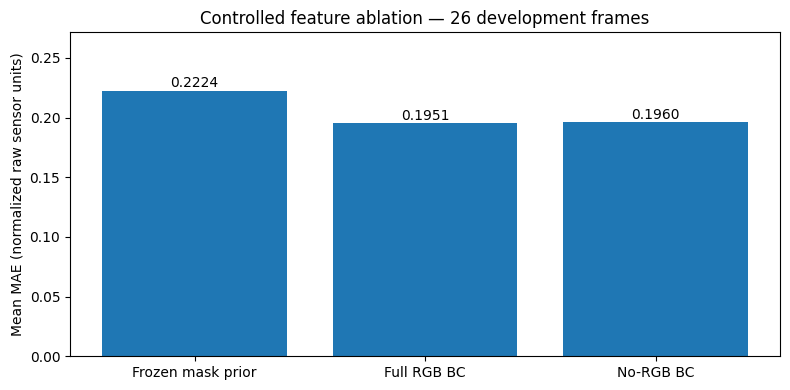


C3-06 SECTION 3 — MATCHED NO-RGB ABLATION
Full RGB correction MAE: 0.19512
No-RGB correction MAE: 0.19598
Full RGB wins: 11 /26
No-RGB wins: 15 /26
Full / No-RGB centered MAE: 0.1344 0.13029
Full / No-RGB gradient MAE: 0.02046 0.01977
Checkpoint reload: PASS
Standalone inference: PASS
Independent scene validation: NO
Metric depth certification: NO

Training: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-06_section03_NO_RGB_CORRECTION_ABLATION_20261020T141700_403065Z
Checkpoint: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-06_section03_NO_RGB_CORRECTION_ABLATION_20261020T141700_403065Z
Evaluation: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-06_section03_NO_RGB_CORRECTION_ABLATION_20261020T141700_403065Z


In [ ]:

# ============================================================
# C3-06 SECTION 3 — MATCHED NO-RGB CORRECTION ABLATION
# One self-contained Colab cell; no file upload needed.
#
# TRAIN: same 33 provisional target examples.
# EVALUATE: same 26 previously QA-passing examples.
# Full RGB model and frozen prior remain unchanged.
#
# NO metric scale or independent validation claims.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import csv, json, hashlib, sys, random, shutil

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)
DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

N = (
    "C3-06_section01_BOUNDARY_RESIDUAL_"
    "20261020T134808_315581Z"
)
E = (
    "C3-06_section02_NEWFILE_REPLICATION_"
    "20261020T140141_065363Z"
)

S14 = BASE / "04_geometry_targets" / (
    "C3-02_section14_PothRGBD_PILOT_"
    "20261020T081321_368363Z"
)
S16 = BASE / "04_geometry_targets" / (
    "C3-02_section16_AFFINE_EXPANSION_"
    "20261020T082927_408953Z"
)

TRAIN = BASE / "05_training_runs" / N
CK = BASE / "06_model_checkpoints" / N
REPL = BASE / "07_evaluation" / E

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for d in (
    S14, S16, TRAIN, CK, REPL,
    DATA / "images",
    DATA / "labels",
    DATA / "depths"
):
    assert d.is_dir(), f"Missing: {d}"


# ------------------------------------------------------------
# 1. VERIFY SAVED EXPERIMENTS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024*1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


def check(root, names):
    lines = (
        root / "checksums.sha256"
    ).read_text().splitlines()

    expected = {}

    for line in lines:
        if not line.strip():
            continue

        hash_, name = line.split(None, 1)
        name = name.strip()
        rel = Path(name)

        assert not rel.is_absolute()
        assert ".." not in rel.parts
        assert name not in expected

        expected[name] = hash_

    for name in names:
        assert name in expected
        assert (root / name).is_file()
        assert sha(root / name) == expected[name], name

    return expected


h14 = check(S14, ["pilot_quality_report.json"])
h16 = check(S16, ["expansion_quality_report.json"])

ht = check(TRAIN, [
    "train_manifest.csv",
    "config_and_results.json"
])

hc = check(CK, [
    "frozen_mask_prior.pt",
    "bc_residual.pt",
    "crdl_dev_model.py",
    "bc_residual_model.py"
])

he = check(REPL, [
    "frozen_newfile_replication_report.json",
    "precommitted_120_filenames.csv",
    "precommitted_protocol.json"
])

p14 = json.loads(
    (S14 / "pilot_quality_report.json").read_text()
)
p16 = json.loads(
    (S16 / "expansion_quality_report.json").read_text()
)

assert p14["configuration"] == p16["config"]
CFG = p14["configuration"]

oldcfg = json.loads(
    (TRAIN / "config_and_results.json").read_text()
)
prev = json.loads(
    (REPL / "frozen_newfile_replication_report.json").read_text()
)

assert oldcfg["train_images"] == 33
assert oldcfg["epochs"] == 24

assert prev["summary"]["selected_filenames"] == 120
assert prev["summary"]["scored_qa_passing_frames"] == 26

assert (
    prev["frozen_prior_sha256"]
    == hc["frozen_mask_prior.pt"]
)
assert (
    prev["frozen_correction_sha256"]
    == hc["bc_residual.pt"]
)

with (TRAIN / "train_manifest.csv").open(
    newline=""
) as f:
    train = list(csv.DictReader(f))

with (
    REPL / "precommitted_120_filenames.csv"
).open(newline="") as f:
    selected = {
        r["sample_id"]: r
        for r in csv.DictReader(f)
    }

passed = {
    r["sample_id"]: r
    for r in prev["per_image"]
    if r["status"] == "DIAGNOSTIC_PASS"
}

assert len(train) == 33
assert len(selected) == 120
assert len(passed) == 26

assert len({
    r["sample_id"] for r in train
}) == 33

assert {
    r["sample_id"] for r in train
}.isdisjoint(selected)

assert set(passed).issubset(selected)

print("Provenance: PASS")
print("Training:", len(train))
print("Reserved replication set:", len(selected))
print("Accepted comparisons:", len(passed))


# ------------------------------------------------------------
# 2. LOAD THE ORIGINAL FROZEN MODELS
# ------------------------------------------------------------

sys.path.insert(0, str(CK))

for name in (
    "crdl_dev_model",
    "bc_residual_model"
):
    sys.modules.pop(name, None)

from crdl_dev_model import (
    CRDLDevUNet,
    encode_input
)
from bc_residual_model import (
    BoundaryResidualCRDL,
    build_features
)

priorpack = torch.load(
    CK / "frozen_mask_prior.pt",
    map_location="cpu",
    weights_only=True
)

fullpack = torch.load(
    CK / "bc_residual.pt",
    map_location="cpu",
    weights_only=True
)

assert (
    priorpack["contract_version"]
    == "C3_MASK_ONLY_ABLATION_V1"
)

assert (
    fullpack["contract_version"]
    == "C3_BC_RESIDUAL_V1"
)

assert (
    fullpack["frozen_prior_sha256"]
    == hc["frozen_mask_prior.pt"]
)

SCALE = float(priorpack["raw_target_scale"])

assert np.isclose(
    SCALE,
    float(fullpack["raw_target_scale"])
)

PRIOR = CRDLDevUNet().eval()
PRIOR.load_state_dict(
    priorpack["state_dict"],
    strict=True
)

FULL = BoundaryResidualCRDL().eval()
FULL.load_state_dict(
    fullpack["state_dict"],
    strict=True
)

for module in (PRIOR, FULL):
    for parameter in module.parameters():
        parameter.requires_grad_(False)


# ------------------------------------------------------------
# 3. MATCH THE ORIGINAL TARGET PREPROCESSING
# ------------------------------------------------------------

def encode_supervision(rgb, mask, target, valid):

    x, g = encode_input(
        np.array(rgb, copy=True),
        mask,
        confidence=1.0,
        size=160
    )

    nh, nw = g["resized_hw"]
    top = g["pad_top"]
    left = g["pad_left"]

    v = F.interpolate(
        torch.from_numpy(
            valid.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    t = F.interpolate(
        torch.from_numpy(
            np.where(
                valid, target, 0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    weight = (
        (v >= 0.90).float()
        * x[
            3,
            top:top+nh,
            left:left+nw
        ][None, None]
    )

    value = torch.where(
        weight > 0,
        t / v.clamp_min(1e-8) / SCALE,
        torch.zeros_like(t)
    )

    padding = (
        left,
        160-nw-left,
        top,
        160-nh-top
    )

    return (
        x,
        F.pad(value, padding)[0],
        F.pad(weight, padding)[0]
    )


def tensor_features(rgb, mask):

    x, _ = encode_input(
        np.array(rgb, copy=True),
        mask,
        confidence=1.0,
        size=160
    )

    x_mask = x.clone()
    x_mask[:3] = 0

    with torch.inference_mode():
        p = PRIOR(x_mask[None])[0]

    features, _ = build_features(
        rgb, mask, p
    )

    assert features.shape == (8, 160, 160)
    return features


def no_rgb(features):

    f = features.clone()

    # Disable R, G, B and derived texture.
    # Preserve mask, radial distance,
    # boundary gate and frozen prior.
    f[:3] = 0
    f[7:8] = 0

    assert torch.equal(
        f[3:7],
        features[3:7]
    )

    return f


# ------------------------------------------------------------
# 4. REBUILD IDENTICAL 33-EXAMPLE TRAINING DATA
# ------------------------------------------------------------

X, Y, W = [], [], []

for row in train:

    assert row["source_stage"] in (
        S14.name, S16.name
    )

    source = (
        S14
        if row["source_stage"] == S14.name
        else S16
    )

    hashes = h14 if source == S14 else h16

    rel = row["npz_relative"]
    npz = source / rel

    assert rel in hashes
    assert sha(npz) == hashes[rel]
    assert sha(npz) == row["npz_sha256"]

    imagefile = DATA / "images" / row["rgb_filename"]

    assert sha(imagefile) == row["rgb_sha256"]

    with Image.open(imagefile) as im:
        rgb = np.array(
            im.convert("RGB"),
            copy=True
        )

    with np.load(npz, allow_pickle=False) as z:

        mask = z["damage_mask"].astype(bool)

        target = z[
            "signed_axial_raw"
        ].astype(np.float32)

        valid = z[
            "valid_target_mask"
        ].astype(bool)

    assert (
        rgb.shape[:2]
        == mask.shape
        == target.shape
        == valid.shape
    )

    assert np.array_equal(
        np.isfinite(target),
        valid
    )

    x, y, w = encode_supervision(
        rgb, mask, target, valid
    )

    features = tensor_features(rgb, mask)

    assert torch.allclose(
        features[:3],
        x[:3],
        atol=1e-7
    )

    X.append(no_rgb(features))
    Y.append(y)
    W.append(w)


X = torch.stack(X)
Y = torch.stack(Y)
W = torch.stack(W)

assert X.shape == (33, 8, 160, 160)
assert Y.shape == (33, 1, 160, 160)
assert W.shape == (33, 1, 160, 160)

assert torch.count_nonzero(X[:, :3]).item() == 0
assert torch.count_nonzero(X[:, 7:8]).item() == 0

with torch.inference_mode():

    prior_mae = float(
        (
            (X[:, 6:7] - Y).abs() * W
        ).sum() / W.sum()
    )

assert abs(
    prior_mae
    - oldcfg["frozen_prior_train_mae_norm"]
) < 2e-4

print("Matched training tensors: PASS")
print("Frozen prior training MAE:", round(prior_mae, 5))


# ------------------------------------------------------------
# 5. SAVE FIXED EVALUATION PROTOCOL
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

NAME = (
    "C3-06_section03_NO_RGB_CORRECTION_ABLATION_"
    + stamp
)

OUTRUN = BASE / "05_training_runs" / NAME
OUTCK = BASE / "06_model_checkpoints" / NAME
OUTEV = BASE / "07_evaluation" / NAME

for folder in (OUTRUN, OUTCK, OUTEV):
    folder.mkdir(
        parents=True,
        exist_ok=False
    )

for file in (
    "crdl_dev_model.py",
    "bc_residual_model.py"
):
    shutil.copy2(CK / file, OUTCK / file)

shutil.copy2(
    CK / "frozen_mask_prior.pt",
    OUTCK / "frozen_mask_prior.pt"
)

shutil.copy2(
    TRAIN / "train_manifest.csv",
    OUTRUN / "train_manifest.csv"
)

protocol = {
    "stage": "C3-06_section03",
    "experiment": (
        "Train a matched boundary-residual network "
        "with RGB and derived texture disabled."
    ),
    "training_count": 33,
    "comparison_count": 26,
    "comparison_selection_sha256":
        he["precommitted_120_filenames.csv"],
    "full_model_sha256":
        hc["bc_residual.pt"],
    "frozen_prior_sha256":
        hc["frozen_mask_prior.pt"],
    "model_selected_using_training_only": True,
    "comparison_pool_previously_consulted": True,
    "independent_scene_validation": False,
    "metric_units_verified": False
}

(OUTEV / "evaluation_protocol.json").write_text(
    json.dumps(protocol, indent=2)
)


# ------------------------------------------------------------
# 6. ORIGINAL GEOMETRY-AWARE LOSS
# ------------------------------------------------------------

def loss_fn(pred, corr, y, w):

    pixel = (
        F.smooth_l1_loss(
            pred, y,
            reduction="none",
            beta=0.2
        ) * w
    ).sum() / w.sum().clamp_min(1)

    wx = (
        w[:, :, :, 1:]
        * w[:, :, :, :-1]
    )

    wy = (
        w[:, :, 1:, :]
        * w[:, :, :-1, :]
    )

    dx = (
        (
            pred[:, :, :, 1:]
            - pred[:, :, :, :-1]
        )
        -
        (
            y[:, :, :, 1:]
            - y[:, :, :, :-1]
        )
    ).abs()

    dy = (
        (
            pred[:, :, 1:, :]
            - pred[:, :, :-1, :]
        )
        -
        (
            y[:, :, 1:, :]
            - y[:, :, :-1, :]
        )
    ).abs()

    gx = (
        (dx*wx).sum()
        / wx.sum().clamp_min(1)
    )

    gy = (
        (dy*wy).sum()
        / wy.sum().clamp_min(1)
    )

    regularization = (
        (corr.square()*w).sum()
        / w.sum().clamp_min(1)
    )

    return (
        pixel
        + 0.12*(gx+gy)/2
        + 0.01*regularization
    )


# ------------------------------------------------------------
# 7. TRAIN MATCHED NO-RGB CORRECTION MODEL
# ------------------------------------------------------------

SEED = 20261020

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    torch.set_num_threads(
        min(4, torch.get_num_threads())
    )
except RuntimeError:
    pass

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ABL = BoundaryResidualCRDL().to(DEVICE)

optimizer = torch.optim.AdamW(
    ABL.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

best = float("inf")
best_epoch = None
history = []

print("\nTraining matched no-RGB model on:", DEVICE)

for epoch in range(1, 25):

    ABL.train()

    order = torch.randperm(
        33,
        generator=(
            torch.Generator().manual_seed(
                SEED + epoch
            )
        )
    )

    for ids in order.split(4):

        xb = X[ids].to(DEVICE)
        yb = Y[ids].to(DEVICE)
        wb = W[ids].to(DEVICE)

        optimizer.zero_grad(
            set_to_none=True
        )

        prediction, correction = ABL(xb)

        loss = loss_fn(
            prediction,
            correction,
            yb,
            wb
        )

        assert torch.isfinite(loss)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            ABL.parameters(),
            1.0
        )

        optimizer.step()

    # Training-only checkpoint selection.
    ABL.eval()

    total = 0.0

    with torch.inference_mode():

        for ids in torch.arange(33).split(4):

            prediction, _ = ABL(
                X[ids].to(DEVICE)
            )

            total += float(
                (
                    (prediction.cpu()-Y[ids]).abs()
                    * W[ids]
                ).sum()
            )

    mae = total / float(W.sum())

    history.append({
        "epoch": epoch,
        "train_mae_norm": mae
    })

    if mae < best:

        best = mae
        best_epoch = epoch

        torch.save({
            "contract_version":
                "C3_NO_RGB_BC_ABLATION_V1",
            "state_dict": {
                k: v.detach().cpu()
                for k, v in ABL.state_dict().items()
            },
            "prior_sha256":
                hc["frozen_mask_prior.pt"],
            "raw_target_scale": SCALE,
            "best_train_epoch": epoch,
            "rgb_and_texture_disabled": True,
            "metric_units_verified": False
        }, OUTCK / "no_rgb_bc_residual.pt")

    print(
        f"Epoch {epoch:02d}/24 | "
        f"NO-RGB train MAE: {mae:.5f}"
    )


# ------------------------------------------------------------
# 8. RELOAD CHECKPOINT
# ------------------------------------------------------------

package = torch.load(
    OUTCK / "no_rgb_bc_residual.pt",
    map_location="cpu",
    weights_only=True
)

NO_RGB = BoundaryResidualCRDL().eval()

NO_RGB.load_state_dict(
    package["state_dict"],
    strict=True
)

FULL.eval()

print("\nNo-RGB checkpoint reload: PASS")


# ------------------------------------------------------------
# 9. REBUILD THE LOCKED REFERENCE ON 26 ACCEPTED FRAMES
# ------------------------------------------------------------

def polygon(path, width, height):

    image = Image.new(
        "L", (width, height), 0
    )
    draw = ImageDraw.Draw(image)

    count = 0

    for line in path.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        values = np.array(
            [float(v) for v in line.split()],
            dtype=np.float64
        )

        assert len(values) >= 7
        assert (len(values)-1) % 2 == 0
        assert values[0] == 0
        assert np.isfinite(values).all()

        pts = values[1:].reshape(-1, 2)

        assert (pts >= -0.001).all()
        assert (pts <= 1.001).all()

        draw.polygon(
            [
                (
                    round(a*(width-1)),
                    round(b*(height-1))
                )
                for a, b in np.clip(pts, 0, 1)
            ],
            fill=1
        )

        count += 1

    mask = np.asarray(
        image,
        dtype=bool
    )

    assert count > 0 and mask.any()
    return mask


def basis(xx, yy, width, height):

    return np.column_stack([
        (xx-(width-1)/2)/width,
        (yy-(height-1)/2)/height,
        np.ones(len(xx))
    ])


def irls(A, b):

    beta = np.linalg.lstsq(
        A, b,
        rcond=None
    )[0]

    for _ in range(CFG["irls_iterations"]):

        error = b - A @ beta
        median = np.median(error)

        mad = 1.4826 * np.median(
            np.abs(error-median)
        )

        cutoff = max(
            1.5*mad, 1e-6
        )

        weight = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(error-median),
                    1e-12
                )
            )
        )

        newer = np.linalg.lstsq(
            A*weight[:, None],
            b*weight,
            rcond=None
        )[0]

        if np.max(
            np.abs(newer-beta)
        ) < 1e-9:

            beta = newer
            break

        beta = newer

    return beta


def pseudo_target(depth, mask, sid):

    height, width = depth.shape

    distance = distance_transform_edt(~mask)

    ring = (
        (depth > 0)
        & (distance >= CFG["ring_min_px"])
        & (distance <= CFG["ring_max_px"])
    )

    ry, rx = np.nonzero(ring)

    assert len(rx) >= CFG["min_support_pixels"]

    rng = np.random.default_rng(
        CFG["seed"] + int(sid[-6:])
    )

    inds = rng.choice(
        len(rx),
        min(
            CFG["max_ring_samples"],
            len(rx)
        ),
        replace=False
    )

    ry, rx = ry[inds], rx[inds]

    z = depth[
        ry, rx
    ].astype(np.float64)

    low, high = np.quantile(
        z,
        [0.001, 0.999]
    )

    keep = (
        (z >= low)
        & (z <= high)
    )

    ry, rx, z = (
        ry[keep],
        rx[keep],
        z[keep]
    )

    A = basis(
        rx, ry,
        width, height
    )

    beta = irls(
        A,
        1000.0/z
    )

    fitted = A @ beta

    assert (fitted > 0).all()

    road_p95 = float(
        np.percentile(
            np.abs(
                z - 1000.0/fitted
            ),
            95
        )
    )

    yy, xx = np.nonzero(
        mask & (depth > 0)
    )

    inverse = (
        basis(xx, yy, width, height) @ beta
    )

    good = inverse > 0

    reference = np.full(
        len(inverse),
        np.nan
    )

    reference[good] = (
        1000.0/inverse[good]
    )

    observed = depth[
        yy, xx
    ].astype(np.float64)

    good = (
        good
        & (
            observed
            >= CFG["sensor_ratio_min"]*reference
        )
        & (
            observed
            <= CFG["sensor_ratio_max"]*reference
        )
    )

    target = np.full(
        (height, width),
        np.nan,
        dtype=np.float32
    )

    target[
        yy[good],
        xx[good]
    ] = (
        observed[good]
        - reference[good]
    ).astype(np.float32)

    return (
        target,
        np.isfinite(target),
        road_p95
    )


# ------------------------------------------------------------
# 10. THREE MATCHED EVALUATION METRICS
# ------------------------------------------------------------

def centered_mae(target, prediction, valid):

    a = target[valid]
    b = prediction[valid]

    return float(
        np.mean(
            np.abs(
                (a-np.median(a))
                - (b-np.median(b))
            )
        )
    )


def gradient_mae(target, prediction, valid):

    vx = (
        valid[:, 1:]
        & valid[:, :-1]
    )

    vy = (
        valid[1:, :]
        & valid[:-1, :]
    )

    error_x = np.abs(
        (
            prediction[:, 1:]
            - prediction[:, :-1]
        )
        -
        (
            target[:, 1:]
            - target[:, :-1]
        )
    )

    error_y = np.abs(
        (
            prediction[1:, :]
            - prediction[:-1, :]
        )
        -
        (
            target[1:, :]
            - target[:-1, :]
        )
    )

    return float(
        (
            error_x[vx].sum()
            + error_y[vy].sum()
        )
        / (vx.sum() + vy.sum())
    )


# ------------------------------------------------------------
# 11. COMPARE FULL RGB AND NO-RGB ON IDENTICAL IMAGES
# ------------------------------------------------------------

rows = []

for i, sid in enumerate(
    sorted(passed),
    1
):

    old = passed[sid]
    record = selected[sid]

    paths = {
        kind: DATA / folder / record[field]
        for kind, folder, field in [
            ("rgb", "images", "rgb_filename"),
            ("label", "labels", "label_filename"),
            ("depth", "depths", "depth_filename")
        ]
    }

    for path in paths.values():
        assert path.is_file()
        assert not path.is_symlink()

    with Image.open(paths["rgb"]) as im:
        rgb = np.array(
            im.convert("RGB"),
            copy=True
        )

    depth = np.load(
        paths["depth"],
        allow_pickle=False
    )

    assert depth.dtype == np.uint16
    assert depth.shape == rgb.shape[:2]

    mask = polygon(
        paths["label"],
        depth.shape[1],
        depth.shape[0]
    )

    target, valid, road = pseudo_target(
        depth, mask, sid
    )

    assert abs(
        road - old["road_p95_raw"]
    ) < 2e-4

    x, y, weight = encode_supervision(
        rgb, mask, target, valid
    )

    features = tensor_features(rgb, mask)

    features_no_rgb = no_rgb(features)

    good = (
        weight[0].numpy() > 0
    )

    truth = y[0].numpy()

    with torch.inference_mode():

        prior_prediction = (
            features[6].numpy()
        )

        full_output, _ = FULL(
            features[None]
        )

        no_rgb_output, _ = NO_RGB(
            features_no_rgb[None]
        )

        full_prediction = (
            full_output[0, 0].numpy()
        )

        no_rgb_prediction = (
            no_rgb_output[0, 0].numpy()
        )

    scores = {}

    for name, prediction in [
        ("prior", prior_prediction),
        ("full", full_prediction),
        ("no_rgb", no_rgb_prediction)
    ]:

        scores[f"{name}_mae_norm"] = float(
            np.mean(
                np.abs(
                    truth[good]
                    - prediction[good]
                )
            )
        )

        scores[
            f"{name}_centered_mae_norm"
        ] = centered_mae(
            truth, prediction, good
        )

        scores[
            f"{name}_gradient_mae_norm"
        ] = gradient_mae(
            truth, prediction, good
        )

    # Reproduce previously saved full-model and
    # frozen-prior scores before interpreting ablation.
    for name in ("prior", "new"):

        mapped = (
            "full" if name == "new"
            else "prior"
        )

        for metric in (
            "mae_norm",
            "centered_mae_norm",
            "gradient_mae_norm"
        ):

            assert abs(
                scores[f"{mapped}_{metric}"]
                - old[f"{name}_{metric}"]
            ) < 2e-5, (
                sid, name, metric
            )

    rows.append({
        "sample_id": sid,
        "burst": old["burst"],
        **scores
    })

    print(
        f"{i:02d}/26 | {sid} | "
        f"Full RGB: {scores['full_mae_norm']:.4f} | "
        f"No RGB: {scores['no_rgb_mae_norm']:.4f}"
    )


# ------------------------------------------------------------
# 12. EVALUATION SUMMARY
# ------------------------------------------------------------

assert len(rows) == 26


def mean(key):
    return float(
        np.mean([
            r[key] for r in rows
        ])
    )


summary = {
    "compared_frames": 26,
    "training_count": 33,

    "mean_prior_mae_norm":
        mean("prior_mae_norm"),

    "mean_full_mae_norm":
        mean("full_mae_norm"),

    "mean_no_rgb_mae_norm":
        mean("no_rgb_mae_norm"),

    "mean_full_centered":
        mean("full_centered_mae_norm"),

    "mean_no_rgb_centered":
        mean("no_rgb_centered_mae_norm"),

    "mean_full_gradient":
        mean("full_gradient_mae_norm"),

    "mean_no_rgb_gradient":
        mean("no_rgb_gradient_mae_norm"),

    "full_rgb_wins": sum(
        r["full_mae_norm"]
        < r["no_rgb_mae_norm"]
        for r in rows
    ),

    "no_rgb_wins": sum(
        r["no_rgb_mae_norm"]
        < r["full_mae_norm"]
        for r in rows
    ),

    "no_rgb_best_training_epoch":
        best_epoch,

    "no_rgb_best_training_mae_norm":
        best,

    "physical_scale_verified": False,
    "independent_test": False,
    "evaluation_pool_previously_consulted": True
}

assert abs(
    summary["mean_prior_mae_norm"]
    - prev["summary"]["mean_prior_mae_norm"]
) < 2e-5

assert abs(
    summary["mean_full_mae_norm"]
    - prev["summary"]["mean_new_mae_norm"]
) < 2e-5

print("\nPrevious model scores reproduced: PASS")


# ------------------------------------------------------------
# 13. SAVE VERSIONED REPORTS
# ------------------------------------------------------------

with (
    OUTEV / "matched_feature_ablation.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(rows[0])
    )

    writer.writeheader()
    writer.writerows(rows)


(
    OUTEV / "matched_feature_ablation_report.json"
).write_text(
    json.dumps({
        "summary": summary,
        "per_image": rows,
        "interpretation_scope": (
            "Exploratory matched feature ablation. "
            "Not independent physical validation."
        )
    }, indent=2)
)


with (
    OUTRUN / "epoch_metrics.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(history[0])
    )

    writer.writeheader()
    writer.writerows(history)


(
    OUTRUN / "training_config.json"
).write_text(
    json.dumps({
        "stage": "C3-06_section03",
        "training_images": 33,
        "seed": SEED,
        "epochs": 24,
        "batch_size": 4,
        "learning_rate": 5e-4,
        "weight_decay": 1e-4,

        "loss": (
            "Masked SmoothL1 beta=0.2 "
            "+ 0.12 gradient "
            "+ 0.01 correction L2"
        ),

        "feature_ablation": (
            "Disable RGB channels 0–2 "
            "and derived texture channel 7. "
            "Preserve mask, distance, gate, "
            "and frozen prior."
        ),

        "original_prior_sha256":
            hc["frozen_mask_prior.pt"],

        "original_full_sha256":
            hc["bc_residual.pt"],

        "best_training_epoch":
            best_epoch,

        "best_training_mae":
            best,

        "metric_units_certified": False,
        "independent_validation": False,

        "torch_version":
            torch.__version__
    }, indent=2)
)


# ------------------------------------------------------------
# 14. SAVE FULL STANDALONE INFERENCE IMPLEMENTATION
# ------------------------------------------------------------

INFER_CODE = r'''
from pathlib import Path
import sys
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path(__file__).resolve().parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from crdl_dev_model import (
    CRDLDevUNet,
    encode_input
)

from bc_residual_model import (
    BoundaryResidualCRDL,
    build_features
)


def predict(rgb, mask, checkpoint_dir):

    root = Path(checkpoint_dir)

    prior_pkg = torch.load(
        root / "frozen_mask_prior.pt",
        map_location="cpu",
        weights_only=True
    )

    correction_pkg = torch.load(
        root / "no_rgb_bc_residual.pt",
        map_location="cpu",
        weights_only=True
    )

    assert (
        prior_pkg["contract_version"]
        == "C3_MASK_ONLY_ABLATION_V1"
    )

    assert (
        correction_pkg["contract_version"]
        == "C3_NO_RGB_BC_ABLATION_V1"
    )

    assert np.isclose(
        float(prior_pkg["raw_target_scale"]),
        float(correction_pkg["raw_target_scale"])
    )

    prior = CRDLDevUNet().eval()

    prior.load_state_dict(
        prior_pkg["state_dict"],
        strict=True
    )

    model = BoundaryResidualCRDL().eval()

    model.load_state_dict(
        correction_pkg["state_dict"],
        strict=True
    )

    rgb = np.array(rgb, copy=True)
    mask = np.asarray(mask, dtype=bool)

    assert rgb.ndim == 3
    assert rgb.shape[2] == 3
    assert rgb.shape[:2] == mask.shape

    with torch.inference_mode():

        x, g = encode_input(
            rgb, mask,
            confidence=1.0,
            size=160
        )

        xm = x.clone()
        xm[:3] = 0

        prior_prediction = prior(
            xm[None]
        )[0]

        features, _ = build_features(
            rgb,
            mask,
            prior_prediction
        )

        features[:3] = 0
        features[7:8] = 0

        output, _ = model(
            features[None]
        )

        top = g["pad_top"]
        left = g["pad_left"]

        nh, nw = g["resized_hw"]
        h, w = g["original_hw"]

        cropped = output[
            ...,
            top:top+nh,
            left:left+nw
        ]

        enlarged = F.interpolate(
            cropped,
            size=(h, w),
            mode="bilinear",
            align_corners=False
        )

        result = (
            enlarged[0, 0]
            .numpy()
            .astype(np.float32)
        )

        result *= float(
            correction_pkg["raw_target_scale"]
        )

    result[~mask] = np.nan

    return {
        "signed_axial_residual_raw": result,
        "units": "UNVERIFIED_POTHRGBD_RAW",
        "model": "C3_NO_RGB_BC_ABLATION_V1",
        "severity_authorized": False
    }
'''

(
    OUTCK / "no_rgb_infer.py"
).write_text(INFER_CODE)


(
    OUTCK / "api_contract.json"
).write_text(
    json.dumps({
        "version": "C3_NO_RGB_BC_ABLATION_V1",

        "purpose": (
            "Matched mask-conditioned correction "
            "ablation for research comparison"
        ),

        "inputs": (
            "RGB uint8 (dimensions only), "
            "binary pothole mask, "
            "fixed confidence=1.0"
        ),

        "output": (
            "Nonmetric road-relative sensor "
            "residual map, NaN outside mask"
        ),

        "rgb_used_for_prediction": False,
        "physical_units_verified": False,
        "backend_release_authorized": False
    }, indent=2)
)


# ------------------------------------------------------------
# 15. STANDALONE LOAD AND INFERENCE SMOKE TEST
# ------------------------------------------------------------

sys.path.insert(0, str(OUTCK))

from no_rgb_infer import (
    predict as no_rgb_predict
)

first = train[0]

first_source = (
    S14 if first["source_stage"] == S14.name
    else S16
)

with Image.open(
    DATA / "images" / first["rgb_filename"]
) as im:

    demo_rgb = np.array(
        im.convert("RGB"),
        copy=True
    )

with np.load(
    first_source / first["npz_relative"],
    allow_pickle=False
) as z:

    demo_mask = z["damage_mask"].astype(bool)


smoke = no_rgb_predict(
    demo_rgb,
    demo_mask,
    OUTCK
)

output = smoke[
    "signed_axial_residual_raw"
]

assert output.shape == demo_mask.shape

assert np.isfinite(
    output[demo_mask]
).all()

assert np.isnan(
    output[~demo_mask]
).all()

(
    OUTCK / "smoke_test.json"
).write_text(
    json.dumps({
        "fresh_checkpoint_reload": "PASS",
        "standalone_inference": "PASS",
        "smoke_source": "TRAIN_ONLY",
        "physical_validation": False
    }, indent=2)
)

print("Standalone inference smoke test: PASS")


# ------------------------------------------------------------
# 16. COMPARISON CHART
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 4)
)

values = [
    mean("prior_mae_norm"),
    mean("full_mae_norm"),
    mean("no_rgb_mae_norm")
]

labels = [
    "Frozen mask prior",
    "Full RGB BC",
    "No-RGB BC"
]

ax.bar(labels, values)

for i, value in enumerate(values):
    ax.text(
        i,
        value + 0.003,
        f"{value:.4f}",
        ha="center"
    )

ax.set_ylim(
    0,
    max(values)*1.22
)

ax.set_ylabel(
    "Mean MAE (normalized raw sensor units)"
)

ax.set_title(
    "Controlled feature ablation — "
    "26 development frames"
)

fig.tight_layout()

fig.savefig(
    OUTEV / "feature_ablation_mae.png",
    dpi=145
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 17. EXPORT CHECKSUMS
# ------------------------------------------------------------

for root in (OUTRUN, OUTCK, OUTEV):

    hashes = []

    for path in sorted(root.rglob("*")):

        if (
            path.is_file()
            and path.name != "checksums.sha256"
            and "__pycache__" not in path.parts
        ):

            relative = (
                path.relative_to(root).as_posix()
            )

            hashes.append(
                f"{sha(path)}  {relative}"
            )

    (
        root / "checksums.sha256"
    ).write_text(
        "\n".join(hashes) + "\n"
    )


# ------------------------------------------------------------
# 18. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*65)
print("C3-06 SECTION 3 — MATCHED NO-RGB ABLATION")
print("="*65)

print(
    "Full RGB correction MAE:",
    round(summary["mean_full_mae_norm"], 5)
)

print(
    "No-RGB correction MAE:",
    round(summary["mean_no_rgb_mae_norm"], 5)
)

print(
    "Full RGB wins:",
    summary["full_rgb_wins"], "/26"
)

print(
    "No-RGB wins:",
    summary["no_rgb_wins"], "/26"
)

print(
    "Full / No-RGB centered MAE:",
    round(summary["mean_full_centered"], 5),
    round(summary["mean_no_rgb_centered"], 5)
)

print(
    "Full / No-RGB gradient MAE:",
    round(summary["mean_full_gradient"], 5),
    round(summary["mean_no_rgb_gradient"], 5)
)

print("Checkpoint reload: PASS")
print("Standalone inference: PASS")
print("Independent scene validation: NO")
print("Metric depth certification: NO")

print("\nTraining:", OUTRUN)
print("Checkpoint:", OUTCK)
print("Evaluation:", OUTEV)

print("="*65)


This suggests that much of our improvement comes from the learned residual refinement of a mask-derived geometric prior, not from discovering individual pothole depth through RGB textures.

That's useful experimentally, but it exposes a limitation: two potholes with similar masks could have very different true depths. A model that doesn't use their appearance or measured 3D information cannot reliably distinguish them.


In [ ]:

# ============================================================
# C3-07 SECTION 1 — ENGINEERING-ONLY COMPONENT 3 API PACKAGE
#
# Potholes: trained nonmetric boundary-residual geometry.
# Cracks: approximate pixel-space geometry.
#
# No physical calibration; severity withheld.
# Direct Google Drive paths; one Colab cell.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import torch
import hashlib
import json
import csv
import shutil
import sys
from PIL import Image, ImageDraw

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)

SRCNAME = (
    "C3-06_section03_NO_RGB_CORRECTION_ABLATION_"
    "20261020T141700_403065Z"
)

TRAINNAME = (
    "C3-06_section01_BOUNDARY_RESIDUAL_"
    "20261020T134808_315581Z"
)

SRC = BASE / "06_model_checkpoints" / SRCNAME
SRC_RUN = BASE / "05_training_runs" / SRCNAME
PREV_RUN = BASE / "05_training_runs" / TRAINNAME

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for root in (
    SRC, SRC_RUN, PREV_RUN, DATA / "images"
):
    assert root.is_dir(), f"Missing folder: {root}"


# ------------------------------------------------------------
# 1. VERIFY ORIGINAL MODEL ARTIFACTS
# ------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def verify(root, names):
    checks = {}

    path = root / "checksums.sha256"

    assert path.is_file(), (
        f"Missing checksums: {root}"
    )

    for line in path.read_text().splitlines():

        if not line.strip():
            continue

        digest, rel = line.split(None, 1)
        rel = rel.strip()

        rp = Path(rel)

        assert not rp.is_absolute()
        assert ".." not in rp.parts

        checks[rel] = digest

    for name in names:

        assert name in checks
        assert (root / name).is_file()

        assert sha256(root / name) == checks[name], (
            f"Checksum mismatch: {name}"
        )

    return checks


SOURCE_FILES = [
    "crdl_dev_model.py",
    "bc_residual_model.py",
    "no_rgb_infer.py",
    "frozen_mask_prior.pt",
    "no_rgb_bc_residual.pt",
    "api_contract.json",
    "smoke_test.json"
]

hsrc = verify(SRC, SOURCE_FILES)

verify(
    SRC_RUN,
    ["training_config.json"]
)

verify(
    PREV_RUN,
    ["train_manifest.csv"]
)

meta = json.loads(
    (
        SRC_RUN / "training_config.json"
    ).read_text()
)

assert meta["training_images"] == 33
assert not meta["metric_units_certified"]

pack = torch.load(
    SRC / "no_rgb_bc_residual.pt",
    map_location="cpu",
    weights_only=True
)

prior_pack = torch.load(
    SRC / "frozen_mask_prior.pt",
    map_location="cpu",
    weights_only=True
)

assert (
    pack["contract_version"]
    == "C3_NO_RGB_BC_ABLATION_V1"
)

assert (
    prior_pack["contract_version"]
    == "C3_MASK_ONLY_ABLATION_V1"
)

assert pack["rgb_and_texture_disabled"] is True

SCALE = float(
    pack["raw_target_scale"]
)

assert SCALE > 0

assert np.isclose(
    SCALE,
    float(prior_pack["raw_target_scale"])
)

print(
    "Original checkpoints and source integrity: PASS"
)


# ------------------------------------------------------------
# 2. CREATE VERSIONED ENGINEERING PACKAGE
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = (
    BASE / "08_backend_release"
    / (
        "C3-07_section01_ENGINEERING_ONLY_"
        + stamp
    )
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

for name in SOURCE_FILES[:5]:
    shutil.copy2(
        SRC / name,
        OUT / name
    )


# ------------------------------------------------------------
# 3. CREATE THE GEOMETRY AND MEASUREMENT ENGINE
# ------------------------------------------------------------

ENGINE = r'''
"""CRDL Component 3: engineering-only geometry interface."""

from pathlib import Path

import numpy as np
from scipy.ndimage import distance_transform_edt
from skimage.morphology import skeletonize
from functools import lru_cache

from no_rgb_infer import predict as predict_raw


HERE = Path(__file__).resolve().parent

VERSION = "C3_ENGINEERING_NONMETRIC_V1"


def _inputs(rgb, defect_mask):

    rgb = np.asarray(rgb)
    mask = np.asarray(defect_mask)

    if (
        rgb.ndim != 3
        or rgb.shape[2] != 3
        or rgb.dtype != np.uint8
    ):
        raise ValueError(
            "RGB input must be HxWx3 uint8"
        )

    if (
        mask.ndim != 2
        or mask.shape != rgb.shape[:2]
    ):
        raise ValueError(
            "Mask must align with RGB HxW"
        )

    if not (
        mask.dtype == bool
        or np.issubdtype(mask.dtype, np.integer)
    ):
        raise ValueError(
            "Mask must be bool or binary integer"
        )

    if not np.isin(mask, [0, 1]).all():
        raise ValueError(
            "Mask values must be binary 0/1"
        )

    mask = mask.astype(bool)

    if not mask.any():
        raise ValueError(
            "Empty defect mask"
        )

    return np.array(rgb, copy=True), mask


def _operational_flags(mask):

    h, w = mask.shape
    flags = []

    if mask.sum() < 64:
        flags.append(
            "SMALL_MASK_PIXEL_COUNT"
        )

    if mask.sum() > 0.85*h*w:
        flags.append(
            "INSUFFICIENT_ROAD_CONTEXT_POSSIBLE"
        )

    if (
        mask[0].any()
        or mask[-1].any()
        or mask[:, 0].any()
        or mask[:, -1].any()
    ):
        flags.append(
            "DEFECT_TOUCHES_IMAGE_BORDER"
        )

    return flags


def _skeleton_length_pixels(skeleton):

    s = np.asarray(
        skeleton,
        dtype=bool
    )

    horizontal = np.count_nonzero(
        s[:, 1:] & s[:, :-1]
    )

    vertical = np.count_nonzero(
        s[1:, :] & s[:-1, :]
    )

    diag1 = np.count_nonzero(
        s[1:, 1:] & s[:-1, :-1]
    )

    diag2 = np.count_nonzero(
        s[1:, :-1] & s[:-1, 1:]
    )

    return float(
        horizontal
        + vertical
        + np.sqrt(2.0)*(diag1 + diag2)
    )


@lru_cache(maxsize=1)
def _target_scale():

    import torch

    ck = torch.load(
        HERE / "no_rgb_bc_residual.pt",
        map_location="cpu",
        weights_only=True
    )

    assert (
        ck["contract_version"]
        == "C3_NO_RGB_BC_ABLATION_V1"
    )

    scale = float(
        ck["raw_target_scale"]
    )

    if (
        not np.isfinite(scale)
        or scale <= 0
    ):
        raise RuntimeError(
            "Invalid target normalizer"
        )

    return scale


def analyze(
    rgb,
    defect_mask,
    defect_type,
    confidence=1.0,
    crack_skeleton=None
):

    image, mask = _inputs(
        rgb,
        defect_mask
    )

    if float(confidence) != 1.0:
        raise ValueError(
            "Current experimental checkpoint supports "
            "fixed confidence=1.0 only"
        )

    defect_type = str(
        defect_type
    ).lower()

    if defect_type not in (
        "pothole",
        "crack"
    ):
        raise ValueError(
            "Supported defect_type: pothole or crack"
        )

    h, w = mask.shape

    result = {
        "contract_version": VERSION,
        "defect_type": defect_type,
        "image_shape_hw": [int(h), int(w)],
        "pixel_area": int(mask.sum()),
        "fraction_of_image": float(mask.mean()),
        "operational_flags": (
            _operational_flags(mask)
        ),
        "model_confidence_calibrated": False,
        "physical_scale_verified": False,
        "physical_depth_mm": None,
        "physical_area_cm2": None,
        "physical_volume_cm3": None,
        "severity": {
            "label": None,
            "status": "NOT_CALIBRATED"
        },
        "inference_status": (
            "ENGINEERING_ONLY_NOT_PHYSICALLY_VALIDATED"
        )
    }

    # --------------------------------------------------------
    # POTHOLE — TRAINED NONMETRIC GEOMETRY
    # --------------------------------------------------------

    if defect_type == "pothole":

        if crack_skeleton is not None:
            raise ValueError(
                "crack_skeleton is only for crack inputs"
            )

        out = predict_raw(
            image,
            mask,
            HERE
        )

        raw = np.asarray(
            out["signed_axial_residual_raw"],
            dtype=np.float32
        )

        if (
            raw.shape != (h, w)
            or not np.isfinite(raw[mask]).all()
        ):
            raise RuntimeError(
                "Non-finite or misaligned model output"
            )

        normalized = np.full(
            (h, w),
            np.nan,
            dtype=np.float32
        )

        normalized[mask] = (
            raw[mask] / _target_scale()
        )

        # Positive inward component only.
        # No mm or cm scale is implied.
        values = np.maximum(
            normalized[mask],
            0.0
        )

        result["geometry"] = {
            "type": (
                "MODEL_NORMALIZED_POSITIVE_AXIAL_RESIDUAL"
            ),
            "units": (
                "UNVERIFIED_CHECKPOINT_NORMALIZED_SENSOR"
            ),
            "is_physical_depth": False,
            "d50": float(
                np.percentile(values, 50)
            ),
            "d90": float(
                np.percentile(values, 90)
            ),
            "d95": float(
                np.percentile(values, 95)
            ),
            "max": float(
                np.max(values)
            ),
            "positive_pixel_fraction": float(
                np.mean(normalized[mask] > 0)
            ),
            "q75_minus_q25": float(
                np.percentile(values, 75)
                - np.percentile(values, 25)
            ),
            "spatial_reliability_established": False
        }

        return result, normalized

    # --------------------------------------------------------
    # CRACK — PIXEL-SPACE GEOMETRY
    # --------------------------------------------------------

    sk = (
        skeletonize(mask)
        if crack_skeleton is None
        else np.asarray(crack_skeleton)
    )

    if (
        sk.shape != mask.shape
        or not np.isin(sk, [0, 1]).all()
    ):
        raise ValueError(
            "Crack skeleton must be binary and aligned HxW"
        )

    sk = sk.astype(bool)

    if (
        np.any(sk & ~mask)
        or not sk.any()
    ):
        raise ValueError(
            "Crack skeleton must be nonempty "
            "and inside crack mask"
        )

    distance = distance_transform_edt(mask)

    widths = (
        2.0*distance[sk]
    )

    result["geometry"] = {
        "type": "PIXEL_SPACE_CRACK_GEOMETRY",
        "units": "pixels_only",
        "area_px2": int(mask.sum()),
        "skeleton_pixels": int(sk.sum()),
        "length_px_approx": (
            _skeleton_length_pixels(sk)
        ),
        "median_width_px_approx": float(
            np.median(widths)
        ),
        "p95_width_px_approx": float(
            np.percentile(widths, 95)
        ),
        "metric_width_or_length_supported": False,
        "skeleton_source": (
            "derived_from_mask"
            if crack_skeleton is None
            else "provided"
        )
    }

    return result, None
'''

(
    OUT / "component3_engine.py"
).write_text(ENGINE)


# ------------------------------------------------------------
# 4. CREATE THE BACKEND INPUT/OUTPUT CONTRACT
# ------------------------------------------------------------

API = {
    "contract_version": (
        "C3_ENGINEERING_NONMETRIC_V1"
    ),

    "status": (
        "ENGINEERING_ONLY_NOT_APPROVED_"
        "FOR_PHYSICAL_SEVERITY"
    ),

    "inputs": {
        "rgb": "H x W x 3 uint8 RGB",
        "defect_mask": (
            "H x W binary aligned mask "
            "from teammate segmentation"
        ),
        "defect_type": [
            "pothole",
            "crack"
        ],
        "confidence": (
            "Scalar 1.0 required by current "
            "experimental model"
        ),
        "crack_skeleton": (
            "Optional H x W aligned binary "
            "skeleton for cracks"
        )
    },

    "outputs": {
        "json_report": (
            "Serializable object from "
            "component3_engine.analyze"
        ),
        "pothole_map": (
            "float32 HxW normalized unverified "
            "sensor residual with NaN outside mask"
        ),
        "crack_map": None,
        "severity": None,
        "physical_measurements": None
    },

    "model_source": {
        "prior_sha256": (
            hsrc["frozen_mask_prior.pt"]
        ),
        "no_rgb_correction_sha256": (
            hsrc["no_rgb_bc_residual.pt"]
        ),
        "target_numeric_normalizer_raw": SCALE
    },

    "limitations": [
        "Not a physically calibrated depth estimator",
        "Operational mask checks are not model confidence",
        "Pixelwise depression is supervised by "
        "unverified sensor-unit pseudo targets",
        "No independent physical-scene validation",
        "Crack measurements are pixels, not metric distances",
        "Severity classes disabled pending validation"
    ]
}

(
    OUT / "api_schema.json"
).write_text(
    json.dumps(API, indent=2)
)


# ------------------------------------------------------------
# 5. IMPORT THE NEW PACKAGE
# ------------------------------------------------------------

sys.path.insert(0, str(OUT))

for module in (
    "crdl_dev_model",
    "bc_residual_model",
    "no_rgb_infer",
    "component3_engine"
):
    sys.modules.pop(
        module,
        None
    )

from component3_engine import analyze


# ------------------------------------------------------------
# 6. REAL POTHOLE INFERENCE SMOKE TEST
# Uses a TRAINING-ONLY example, not evaluation.
# ------------------------------------------------------------

with (
    PREV_RUN / "train_manifest.csv"
).open(newline="") as f:

    training = list(
        csv.DictReader(f)
    )

assert len(training) == 33

example = training[0]

assert example["source_stage"] in {
    (
        "C3-02_section14_PothRGBD_PILOT_"
        "20261020T081321_368363Z"
    ),
    (
        "C3-02_section16_AFFINE_EXPANSION_"
        "20261020T082927_408953Z"
    )
}

source = (
    BASE
    / "04_geometry_targets"
    / example["source_stage"]
)

image_path = (
    DATA / "images"
    / example["rgb_filename"]
)

target_path = (
    source
    / example["npz_relative"]
)

assert image_path.is_file()
assert target_path.is_file()

assert (
    sha256(image_path)
    == example["rgb_sha256"]
)

assert (
    sha256(target_path)
    == example["npz_sha256"]
)

with Image.open(image_path) as im:

    rgb = np.array(
        im.convert("RGB"),
        copy=True
    )

with np.load(
    target_path,
    allow_pickle=False
) as data:

    mask = data[
        "damage_mask"
    ].astype(bool)

assert rgb.shape[:2] == mask.shape

print(
    "Running packaged pothole inference..."
)

pothole, heatmap = analyze(
    rgb,
    mask,
    "pothole"
)

assert heatmap.shape == mask.shape

assert np.isnan(
    heatmap[~mask]
).all()

assert np.isfinite(
    heatmap[mask]
).all()

assert (
    pothole["severity"]["label"]
    is None
)

assert (
    pothole["physical_depth_mm"]
    is None
)

print("Pothole inference smoke: PASS")


# ------------------------------------------------------------
# 7. RGB-INVARIANCE CHECK
# The no-RGB model must not use image colors.
# ------------------------------------------------------------

black_image = np.zeros_like(
    rgb
)

_, black_heatmap = analyze(
    black_image,
    mask,
    "pothole"
)

assert np.allclose(
    heatmap[mask],
    black_heatmap[mask],
    atol=1e-6
)

print(
    "No-RGB prediction invariance: PASS"
)


# ------------------------------------------------------------
# 8. SYNTHETIC CRACK-MEASUREMENT SMOKE TEST
# Not a scientific accuracy evaluation.
# ------------------------------------------------------------

canvas = Image.new(
    "L",
    (160, 160),
    0
)

draw = ImageDraw.Draw(canvas)

draw.line(
    [
        (20, 110),
        (55, 77),
        (91, 52),
        (138, 24)
    ],
    fill=1,
    width=7
)

crack_mask = np.asarray(
    canvas,
    dtype=bool
)

crack, no_map = analyze(
    np.zeros(
        (160, 160, 3),
        dtype=np.uint8
    ),
    crack_mask,
    "crack"
)

assert no_map is None

assert (
    crack["geometry"]["length_px_approx"]
    > 0
)

assert (
    crack["geometry"]["median_width_px_approx"]
    > 0
)

assert crack["physical_area_cm2"] is None

assert crack["severity"]["label"] is None

print(
    "Synthetic crack geometry smoke: PASS"
)


# ------------------------------------------------------------
# 9. INVALID INPUT REJECTION
# ------------------------------------------------------------

try:

    analyze(
        rgb,
        np.zeros_like(mask),
        "pothole"
    )

    raise AssertionError(
        "Empty mask was not rejected"
    )

except ValueError:
    pass

print(
    "Empty-mask rejection: PASS"
)


# ------------------------------------------------------------
# 10. SAVE EXAMPLE OUTPUTS
# ------------------------------------------------------------

np.savez_compressed(
    OUT / "training_only_pothole_heatmap.npz",
    normalized_nonmetric_map=heatmap,
    mask=mask.astype(np.uint8)
)

(
    OUT / "training_only_pothole_smoke.json"
).write_text(
    json.dumps(
        pothole,
        indent=2
    )
)

(
    OUT / "synthetic_crack_smoke.json"
).write_text(
    json.dumps(
        crack,
        indent=2
    )
)

(
    OUT / "smoke_test.json"
).write_text(
    json.dumps({
        "version": (
            "C3_ENGINEERING_NONMETRIC_V1"
        ),
        "pothole_checkpoint_reload": "PASS",
        "pothole_nonmetric_map": "PASS",
        "model_RGB_invariance": "PASS",
        "synthetic_crack_pixel_measurements": "PASS",
        "empty_mask_rejection": "PASS",
        "pothole_source_role": "TRAIN_ONLY",
        "physical_scale_verified": False,
        "metric_severity_enabled": False,
        "independent_validation_performed": False
    }, indent=2)
)

(
    OUT / "README.txt"
).write_text(
    "C3-07 Section 1 engineering-only Component 3 API.\n"
    "Import component3_engine.analyze("
    "rgb, binary_mask, defect_type, "
    "confidence=1.0, crack_skeleton=None).\n"
    "Returns (report_dict, optional "
    "float32 nonmetric pothole map).\n"
    "DO NOT label normalized numbers "
    "as mm/cm or calibrated severity.\n"
    "Pothole smoke example is TRAIN-ONLY.\n"
    "Crack smoke data is synthetic.\n"
    "Original model hashes recorded in api_schema.json.\n"
)


# ------------------------------------------------------------
# 11. EXPORT VERSIONED CHECKSUMS
# ------------------------------------------------------------

checks = []

for path in sorted(
    OUT.rglob("*")
):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
        and "__pycache__" not in path.parts
    ):

        relative = (
            path.relative_to(OUT).as_posix()
        )

        checks.append(
            f"{sha256(path)}  {relative}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(checks) + "\n"
)


# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*62)
print("C3-07 SECTION 1 — ENGINEERING GEOMETRY API")
print("="*62)

print(
    "Pothole: normalized road-relative geometry"
)

print(
    "Crack: pixel-space geometry"
)

print(
    "Physical depth/area/volume: DISABLED"
)

print(
    "Severity: NOT CALIBRATED"
)

print(
    "Independent physical validation: NO"
)

print(
    "Backend-approved metric release: NO"
)

print(
    "Model loading and smoke tests: PASS"
)

print(
    "\nSaved:",
    OUT
)

print("="*62)


Original checkpoints and source integrity: PASS
Running packaged pothole inference...
Pothole inference smoke: PASS
No-RGB prediction invariance: PASS
Synthetic crack geometry smoke: PASS
Empty-mask rejection: PASS

C3-07 SECTION 1 — ENGINEERING GEOMETRY API
Pothole: normalized road-relative geometry
Crack: pixel-space geometry
Physical depth/area/volume: DISABLED
Severity: NOT CALIBRATED
Independent physical validation: NO
Backend-approved metric release: NO
Model loading and smoke tests: PASS

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/08_backend_release/C3-07_section01_ENGINEERING_ONLY_20261020T142909_403552Z


Real crack-mask evaluation and geometry

Backend package integrity: PASS
SUT-Crack length labels: 130
Synthetic skeleton-length tests: PASS
01/12 | Sample 1 | MEASURED | Graph length (px): 5721.806850423158 | Dataset label (cm): 117.0
02/12 | Sample 13 | MEASURED | Graph length (px): 3231.1841251215724 | Dataset label (cm): 65.0
03/12 | Sample 25 | MEASURED | Graph length (px): 3296.230806315798 | Dataset label (cm): 69.0
04/12 | Sample 37 | MEASURED | Graph length (px): 5394.616808115925 | Dataset label (cm): 110.0
05/12 | Sample 49 | MEASURED | Graph length (px): 4808.254326381661 | Dataset label (cm): 83.0
06/12 | Sample 61 | MEASURED | Graph length (px): 4332.430949890798 | Dataset label (cm): 81.0
07/12 | Sample 73 | MEASURED | Graph length (px): 5186.741699796952 | Dataset label (cm): 82.0
08/12 | Sample 85 | MEASURED | Graph length (px): 5163.714354586482 | Dataset label (cm): 104.0
09/12 | Sample 97 | MEASURED | Graph length (px): 6600.910673016875 | Dataset label (cm): 124.0
10/12 | Sample 109 | MEASURED | Graph leng

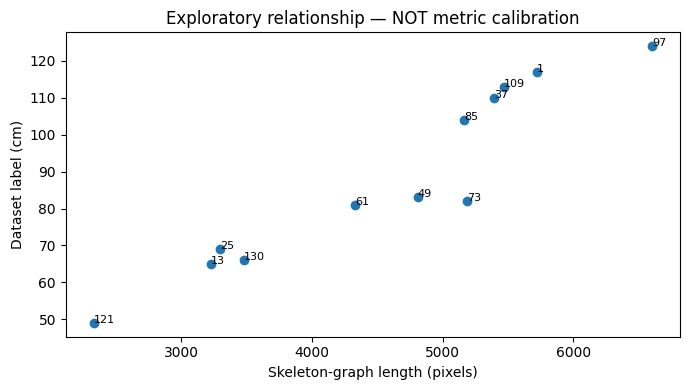

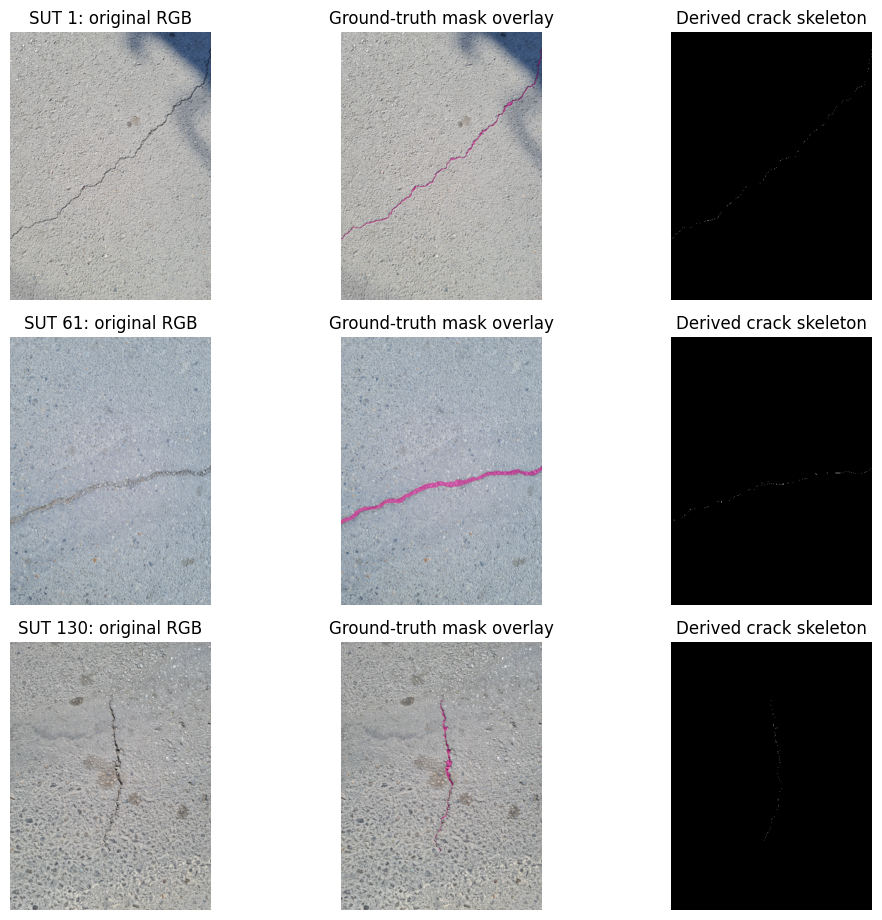


C3-07 SECTION 2 — REAL SUT-CRACK PILOT
Real crack samples attempted: 12
Successfully measured: 12
Errors: 0
Exploratory pixel-length / labeled-cm Spearman: 0.9720279720279721
Physical scale verified: NO
Metric crack accuracy validated: NO
Pothole severity authorized: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-07_section02_SUT_CRACK_PILOT_20261020T144129_346340Z


In [ ]:

# ============================================================
# C3-07 SECTION 2 — REAL SUT-CRACK GEOMETRY PILOT
#
# 12 fixed real samples from the SUT-Crack dataset.
# Real binary segmentation masks and length annotations.
# Corrects EXIF photo orientation before alignment.
#
# Engineering evaluation only.
# NO automatic pixel-to-cm conversion.
# NO physical severity classification.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageOps
from scipy.ndimage import (
    label,
    generate_binary_structure
)
from scipy.stats import spearmanr

import numpy as np
import matplotlib.pyplot as plt
import csv
import json
import hashlib
import sys


# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

SUT = Path(
    "/content/drive/MyDrive/manushi_research_data/SUT-Crack"
)

PKG = BASE / (
    "08_backend_release/"
    "C3-07_section01_ENGINEERING_ONLY_"
    "20261020T142909_403552Z"
)

IMAGES = SUT / "1-Segmentation/Original Image"
MASKS = SUT / "1-Segmentation/Ground Truth"

LENGTHS = (
    SUT / "4-Crack Length/Crack Length.txt"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for p in (PKG, IMAGES, MASKS):
    assert p.is_dir(), f"Missing: {p}"

assert LENGTHS.is_file(), (
    f"Missing crack length annotations: {LENGTHS}"
)


# ------------------------------------------------------------
# 2. VERIFY EXISTING BACKEND PACKAGE
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


hashes = {}

for line in (
    PKG / "checksums.sha256"
).read_text().splitlines():

    if not line.strip():
        continue

    digest, relative = line.split(None, 1)

    hashes[relative.strip()] = digest


required = [
    "component3_engine.py",
    "no_rgb_infer.py",
    "frozen_mask_prior.pt",
    "no_rgb_bc_residual.pt",
    "api_schema.json"
]

for relative in required:

    assert relative in hashes

    assert sha(
        PKG / relative
    ) == hashes[relative], (
        f"Package integrity failed: {relative}"
    )


# ------------------------------------------------------------
# 3. LOAD SUT-CRACK REFERENCE LENGTHS
# ------------------------------------------------------------

with LENGTHS.open(
    encoding="utf-8-sig",
    newline=""
) as f:

    length_labels = {
        int(row["filename"]):
            float(row["Crack Length (cm)"])
        for row in csv.DictReader(
            f, delimiter="\t"
        )
    }

assert len(length_labels) == 130

assert set(length_labels) == set(
    range(1, 131)
)

assert all(
    np.isfinite(v) and v > 0
    for v in length_labels.values()
)

print("Backend package integrity: PASS")
print(
    "SUT-Crack length labels:",
    len(length_labels)
)


# ------------------------------------------------------------
# 4. FREEZE SAMPLE SELECTION BEFORE ANALYSIS
# ------------------------------------------------------------

SELECTED = [
    1, 13, 25, 37,
    49, 61, 73, 85,
    97, 109, 121, 130
]

assert len(SELECTED) == 12
assert len(set(SELECTED)) == 12

for sample_id in SELECTED:

    assert (
        IMAGES / f"{sample_id}.jpg"
    ).is_file()

    assert (
        MASKS / f"{sample_id}.png"
    ).is_file()


stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = (
    BASE / "07_evaluation"
    / f"C3-07_section02_SUT_CRACK_PILOT_{stamp}"
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

with (
    OUT / "precommitted_sample_selection.csv"
).open("w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "sample_id",
        "reference_length_cm",
        "rgb_file",
        "mask_file"
    ])

    for sample_id in SELECTED:

        writer.writerow([
            sample_id,
            length_labels[sample_id],
            f"{sample_id}.jpg",
            f"{sample_id}.png"
        ])


# ------------------------------------------------------------
# 5. IMPROVED SKELETON GRAPH LENGTH ESTIMATOR
# ------------------------------------------------------------

def length_graph(skeleton):

    s = np.asarray(
        skeleton, dtype=bool
    )

    # Orthogonal links counted once.
    horizontal = np.count_nonzero(
        s[:, :-1] & s[:, 1:]
    )

    vertical = np.count_nonzero(
        s[:-1, :] & s[1:, :]
    )

    # Exclude a diagonal when an orthogonal
    # intermediate pixel already connects it.
    diagonal_1 = np.count_nonzero(
        s[:-1, :-1]
        & s[1:, 1:]
        & ~s[:-1, 1:]
        & ~s[1:, :-1]
    )

    diagonal_2 = np.count_nonzero(
        s[:-1, 1:]
        & s[1:, :-1]
        & ~s[:-1, :-1]
        & ~s[1:, 1:]
    )

    return float(
        horizontal
        + vertical
        + np.sqrt(2) * (
            diagonal_1 + diagonal_2
        )
    )


# ------------------------------------------------------------
# 6. SYNTHETIC NUMERICAL TESTS
# ------------------------------------------------------------

straight = np.zeros(
    (20, 20), dtype=bool
)
straight[10, 3:13] = True

diagonal = np.zeros(
    (20, 20), dtype=bool
)
diagonal[
    np.arange(3, 10),
    np.arange(3, 10)
] = True

corner = np.zeros(
    (20, 20), dtype=bool
)
corner[5, 5:7] = True
corner[6, 6] = True

assert np.isclose(
    length_graph(straight), 9
)

assert np.isclose(
    length_graph(diagonal),
    6 * np.sqrt(2)
)

assert np.isclose(
    length_graph(corner), 2
)

print(
    "Synthetic skeleton-length tests: PASS"
)


# ------------------------------------------------------------
# 7. DECODE THE ORIGINAL SEGMENTATION MASK
# ------------------------------------------------------------

def decode_mask(path):

    with Image.open(path) as im:

        array = np.asarray(
            im.convert("RGB"),
            dtype=np.uint8
        )

    # Estimate the predominant boundary color,
    # rather than assuming black or white cracks.
    boundary = np.concatenate([
        array[0],
        array[-1],
        array[:, 0],
        array[:, -1]
    ], axis=0)

    background = np.median(
        boundary, axis=0
    ).astype(np.int16)

    difference = np.max(
        np.abs(
            array.astype(np.int16)
            - background
        ),
        axis=2
    )

    mask = difference >= 40

    coverage = float(
        mask.mean()
    )

    # Reject ambiguous foreground/background
    # interpretation; do not guess silently.
    if not 0.00001 < coverage < 0.40:

        raise ValueError(
            "Ambiguous mask polarity or coverage: "
            f"{coverage:.6f}"
        )

    return (
        mask,
        coverage,
        background.tolist()
    )


# ------------------------------------------------------------
# 8. IMPORT EXISTING COMPONENT 3 ENGINE
# ------------------------------------------------------------

sys.path.insert(
    0, str(PKG)
)

for name in (
    "component3_engine",
    "no_rgb_infer",
    "crdl_dev_model",
    "bc_residual_model"
):
    sys.modules.pop(
        name, None
    )

from component3_engine import analyze

from skimage.morphology import skeletonize


# ------------------------------------------------------------
# 9. MEASURE THE REAL CRACK SAMPLES
# ------------------------------------------------------------

records = []
previews = []

for index, sample_id in enumerate(
    SELECTED, 1
):

    rgb_path = (
        IMAGES / f"{sample_id}.jpg"
    )

    mask_path = (
        MASKS / f"{sample_id}.png"
    )

    record = {
        "sample_id": sample_id,
        "reference_length_cm":
            length_labels[sample_id],
        "status": "ERROR",
        "rgb_sha256": sha(rgb_path),
        "mask_sha256": sha(mask_path)
    }

    try:

        mask, coverage, background = (
            decode_mask(mask_path)
        )

        with Image.open(rgb_path) as im:

            # Essential: respect original
            # smartphone EXIF orientation.
            corrected = ImageOps.exif_transpose(
                im
            )

            if corrected.size != (
                mask.shape[1],
                mask.shape[0]
            ):

                raise ValueError(
                    "RGB/mask size mismatch after "
                    "EXIF correction: "
                    f"{corrected.size} vs {mask.shape}"
                )

            rgb = np.array(
                corrected.convert("RGB"),
                copy=True
            )

        # Existing Component 3 crack branch.
        report, unused_map = analyze(
            rgb,
            mask,
            defect_type="crack",
            confidence=1.0
        )

        assert unused_map is None

        geometry = report["geometry"]

        # Independently check its skeleton.
        skeleton = skeletonize(mask)

        graph_length = length_graph(
            skeleton
        )

        components = int(
            label(
                mask,
                generate_binary_structure(2, 2)
            )[1]
        )

        assert graph_length > 0
        assert (
            geometry["length_px_approx"] > 0
        )

        record.update({
            "status": "MEASURED",
            "shape_hw": list(mask.shape),
            "mask_coverage": coverage,
            "background_rgb": background,
            "mask_components": components,
            "existing_engine_length_px":
                float(
                    geometry["length_px_approx"]
                ),
            "graph_length_px":
                graph_length,
            "median_width_px_approx":
                float(
                    geometry["median_width_px_approx"]
                ),
            "area_px2":
                int(geometry["area_px2"]),
            "operational_flags":
                report["operational_flags"]
        })

        # Preselected visual examples.
        # Do not choose them by model score.
        if sample_id in (1, 61, 130):

            previews.append((
                sample_id,
                rgb,
                mask,
                skeleton
            ))

    except Exception as exc:

        record.update({
            "status": "ERROR",
            "error": (
                f"{type(exc).__name__}: {exc}"
            )
        })

    records.append(record)

    print(
        f"{index:02d}/12 | "
        f"Sample {sample_id} | "
        f"{record['status']} | "
        f"Graph length (px): "
        f"{record.get('graph_length_px')} | "
        f"Dataset label (cm): "
        f"{record['reference_length_cm']}"
    )


# ------------------------------------------------------------
# 10. SAVE ALL MEASUREMENTS AND ERRORS
# ------------------------------------------------------------

with (
    OUT / "all_sample_results.csv"
).open("w", newline="") as f:

    columns = list(
        dict.fromkeys(
            key
            for record in records
            for key in record
        )
    )

    writer = csv.DictWriter(
        f,
        fieldnames=columns
    )

    writer.writeheader()

    for record in records:

        writer.writerow({
            key: (
                json.dumps(value)
                if isinstance(value, (list, dict))
                else value
            )
            for key, value in record.items()
        })


# ------------------------------------------------------------
# 11. EXPLORATORY PIXEL LENGTH VS CM LABELS
# ------------------------------------------------------------

accepted = [
    record
    for record in records
    if record["status"] == "MEASURED"
]

if len(accepted) >= 4:

    lengths_cm = np.array([
        record["reference_length_cm"]
        for record in accepted
    ])

    lengths_px = np.array([
        record["graph_length_px"]
        for record in accepted
    ])

    rho = spearmanr(
        lengths_px,
        lengths_cm
    ).statistic

    rho = (
        float(rho)
        if np.isfinite(rho)
        else None
    )

else:
    rho = None


summary = {
    "selected": len(SELECTED),
    "successfully_measured": len(accepted),
    "errors": len(records) - len(accepted),
    "exploratory_pixel_vs_labeled_cm_spearman":
        rho,
    "geometry_units": "PIXELS_ONLY",
    "dataset_length_labels": (
        "CENTIMETRES_WITH_UNVERIFIED_"
        "MEASUREMENT_PROTOCOL"
    ),
    "pixel_to_cm_calibration_performed": False,
    "independent_physical_validation": False,
    "severity_prediction": "DISABLED"
}


(
    OUT / "crack_pilot_report.json"
).write_text(
    json.dumps({
        "summary": summary,
        "per_image": records,
        "label_file_sha256":
            sha(LENGTHS),
        "component3_engine_sha256":
            hashes["component3_engine.py"]
    }, indent=2)
)


# ------------------------------------------------------------
# 12. PLOT PIXEL LENGTH VS REFERENCE LABEL
# ------------------------------------------------------------

if accepted:

    fig, ax = plt.subplots(
        figsize=(7, 4)
    )

    ax.scatter(
        [
            r["graph_length_px"]
            for r in accepted
        ],
        [
            r["reference_length_cm"]
            for r in accepted
        ]
    )

    for r in accepted:

        ax.annotate(
            str(r["sample_id"]),
            (
                r["graph_length_px"],
                r["reference_length_cm"]
            ),
            fontsize=8
        )

    ax.set_xlabel(
        "Skeleton-graph length (pixels)"
    )

    ax.set_ylabel(
        "Dataset label (cm)"
    )

    ax.set_title(
        "Exploratory relationship — "
        "NOT metric calibration"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / "pixel_vs_labeled_cm.png",
        dpi=140
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 13. VISUALIZE REAL RGB / MASK / SKELETON
# ------------------------------------------------------------

if previews:

    fig, axes = plt.subplots(
        len(previews),
        3,
        figsize=(11, 3.1 * len(previews)),
        squeeze=False
    )

    for j, (
        sample_id, rgb, mask, skeleton
    ) in enumerate(previews):

        h, w = mask.shape

        display_width = min(
            w, 450
        )

        display_height = max(
            1,
            round(
                h * display_width / w
            )
        )

        rgb_small = np.array(
            Image.fromarray(rgb).resize(
                (
                    display_width,
                    display_height
                )
            )
        )

        mask_small = np.array(
            Image.fromarray(
                mask.astype("uint8") * 255
            ).resize(
                (
                    display_width,
                    display_height
                ),
                resample=Image.Resampling.NEAREST
            )
        ) > 0

        skeleton_small = np.array(
            Image.fromarray(
                skeleton.astype("uint8") * 255
            ).resize(
                (
                    display_width,
                    display_height
                ),
                resample=Image.Resampling.NEAREST
            )
        ) > 0

        overlay = rgb_small.copy()

        overlay[mask_small] = (
            0.55 * overlay[mask_small]
            + 0.45 * np.array([255, 0, 160])
        ).astype(np.uint8)

        axes[j, 0].imshow(rgb_small)
        axes[j, 0].set_title(
            f"SUT {sample_id}: original RGB"
        )

        axes[j, 1].imshow(overlay)
        axes[j, 1].set_title(
            "Ground-truth mask overlay"
        )

        axes[j, 2].imshow(
            skeleton_small,
            cmap="gray"
        )

        axes[j, 2].set_title(
            "Derived crack skeleton"
        )

        for ax in axes[j]:
            ax.axis("off")

    fig.tight_layout()

    fig.savefig(
        OUT / "real_crack_previews.png",
        dpi=130
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 14. SAVE CHECKSUMS
# ------------------------------------------------------------

checksum_lines = []

for path in sorted(
    OUT.iterdir()
):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):

        checksum_lines.append(
            f"{sha(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(checksum_lines) + "\n"
)


# ------------------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-07 SECTION 2 — REAL SUT-CRACK PILOT")
print("=" * 65)

print(
    "Real crack samples attempted:",
    len(records)
)

print(
    "Successfully measured:",
    len(accepted)
)

print(
    "Errors:",
    len(records) - len(accepted)
)

print(
    "Exploratory pixel-length / "
    "labeled-cm Spearman:",
    rho
)

print(
    "Physical scale verified: NO"
)

print(
    "Metric crack accuracy validated: NO"
)

print(
    "Pothole severity authorized: NO"
)

print("\nSaved:", OUT)

print("=" * 65)


Package and pilot integrity: PASS
Original RGB files: 130
Original segmentation masks: 130
Length labels: 130
001/130 | {'MEASURED': 1}
010/130 | {'MEASURED': 10}
020/130 | {'MEASURED': 20}
030/130 | {'MEASURED': 30}
040/130 | {'MEASURED': 40}
050/130 | {'MEASURED': 50}
060/130 | {'MEASURED': 60}
070/130 | {'MEASURED': 70}
080/130 | {'MEASURED': 80}
090/130 | {'MEASURED': 90}
100/130 | {'MEASURED': 100}
110/130 | {'MEASURED': 110}
120/130 | {'MEASURED': 120}
130/130 | {'MEASURED': 130}


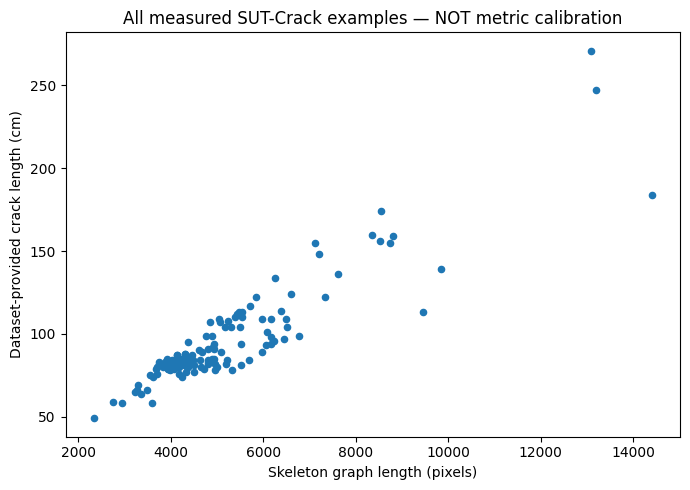

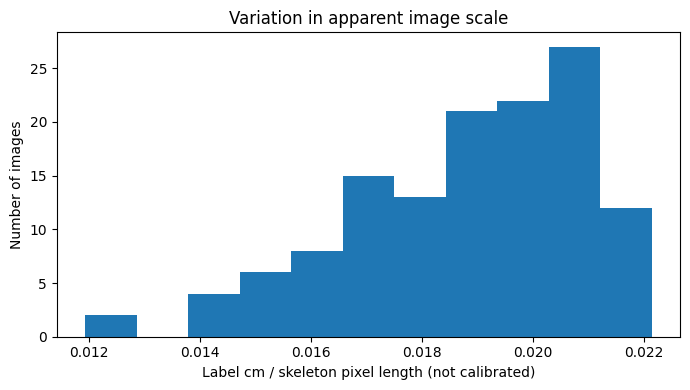


C3-07 SECTION 3 — ALL 130 REAL CRACKS
Measured: 130 | Errors: 0
Previous 12 lengths reproduced: True
Spearman pixel vs labelled cm: 0.8350617779353049
Implied scale coefficient of variation: 0.11277807569539818
Median backend length overcount (%): 1.5365157662902806
Physical scale certified: NO
Severity authorized: NO

Saved output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-07_section03_SUT_FULL130_20261020T145153_432660Z


In [ ]:

# ============================================================
# C3-07 SECTION 3 — FULL SUT-CRACK EVALUATION
# 130 original images, masks, and labelled lengths.
# Physical scale and severity remain UNVERIFIED.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from PIL import Image, ImageOps
from scipy.ndimage import label, convolve
from scipy.stats import spearmanr, pearsonr
from skimage.morphology import skeletonize

import numpy as np
import matplotlib.pyplot as plt
import hashlib, json, csv, sys, gc

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

SUT = Path(
    "/content/drive/MyDrive/manushi_research_data/SUT-Crack"
)

PKG = BASE / (
    "08_backend_release/"
    "C3-07_section01_ENGINEERING_ONLY_"
    "20261020T142909_403552Z"
)

PILOT = BASE / (
    "07_evaluation/"
    "C3-07_section02_SUT_CRACK_PILOT_"
    "20261020T144129_346340Z"
)

RGB_DIR = SUT / "1-Segmentation/Original Image"
MASK_DIR = SUT / "1-Segmentation/Ground Truth"
LENGTH_FILE = SUT / "4-Crack Length/Crack Length.txt"

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for folder in [PKG, PILOT, RGB_DIR, MASK_DIR]:
    assert folder.is_dir(), f"Missing: {folder}"

assert LENGTH_FILE.is_file()


# ------------------------------------------------------------
# 1. SOURCE INTEGRITY
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


def verify(folder, required):
    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, name = line.split(None, 1)
        name = name.strip()
        rel = Path(name)

        assert not rel.is_absolute()
        assert ".." not in rel.parts
        assert name not in expected

        expected[name] = digest

    for name in required:
        assert name in expected
        assert (folder / name).is_file()
        assert sha(folder / name) == expected[name], name

    return expected


h_pkg = verify(PKG, [
    "component3_engine.py",
    "no_rgb_infer.py",
    "api_schema.json"
])

h_pilot = verify(PILOT, [
    "crack_pilot_report.json",
    "precommitted_sample_selection.csv"
])

previous = json.loads(
    (PILOT / "crack_pilot_report.json").read_text()
)

assert previous["summary"]["selected"] == 12
assert previous["summary"]["successfully_measured"] == 12
assert previous["label_file_sha256"] == sha(LENGTH_FILE)

pilot_records = {
    int(r["sample_id"]): r
    for r in previous["per_image"]
    if r["status"] == "MEASURED"
}

assert len(pilot_records) == 12


# ------------------------------------------------------------
# 2. VERIFY ALL 130 SOURCE LABELS AND FILES
# ------------------------------------------------------------

with LENGTH_FILE.open(
    encoding="utf-8-sig",
    newline=""
) as f:

    labels = {
        int(r["filename"]):
            float(r["Crack Length (cm)"])
        for r in csv.DictReader(
            f, delimiter="\t"
        )
    }

assert set(labels) == set(range(1, 131))

assert all(
    np.isfinite(v) and v > 0
    for v in labels.values()
)

for sample_id in range(1, 131):

    assert (
        RGB_DIR / f"{sample_id}.jpg"
    ).is_file()

    assert (
        MASK_DIR / f"{sample_id}.png"
    ).is_file()

print("Package and pilot integrity: PASS")
print("Original RGB files:", 130)
print("Original segmentation masks:", 130)
print("Length labels:", len(labels))


# ------------------------------------------------------------
# 3. IMPORT THE EXISTING COMPONENT 3 CRACK ENGINE
# ------------------------------------------------------------

sys.path.insert(0, str(PKG))

for name in (
    "component3_engine",
    "no_rgb_infer",
    "crdl_dev_model",
    "bc_residual_model"
):
    sys.modules.pop(name, None)

from component3_engine import analyze


# ------------------------------------------------------------
# 4. LOCK THE SECTION 2 GRAPH-LENGTH METHOD
# ------------------------------------------------------------

def length_graph(skeleton):

    s = np.asarray(
        skeleton, dtype=bool
    )

    horizontal = np.count_nonzero(
        s[:, :-1] & s[:, 1:]
    )

    vertical = np.count_nonzero(
        s[:-1, :] & s[1:, :]
    )

    diagonal_1 = np.count_nonzero(
        s[:-1, :-1]
        & s[1:, 1:]
        & ~s[:-1, 1:]
        & ~s[1:, :-1]
    )

    diagonal_2 = np.count_nonzero(
        s[:-1, 1:]
        & s[1:, :-1]
        & ~s[:-1, :-1]
        & ~s[1:, 1:]
    )

    return float(
        horizontal
        + vertical
        + np.sqrt(2) * (
            diagonal_1 + diagonal_2
        )
    )


# ------------------------------------------------------------
# 5. BINARY MASK DECODING
# ------------------------------------------------------------

def read_crack_mask(path):

    with Image.open(path) as im:

        pixels = np.asarray(
            im.convert("L"),
            dtype=np.uint8
        )

        source_mode = im.mode

    unique = np.unique(pixels)

    if len(unique) != 2:
        raise ValueError(
            "Expected binary segmentation mask"
        )

    threshold = (
        int(unique[0])
        + int(unique[-1])
    ) / 2.0

    mask = pixels > threshold

    border = np.concatenate([
        mask[0],
        mask[-1],
        mask[:, 0],
        mask[:, -1]
    ])

    border_fraction = float(border.mean())

    if 0.40 <= border_fraction <= 0.60:
        raise ValueError(
            "Ambiguous foreground polarity"
        )

    inverted = border_fraction > 0.60

    if inverted:
        mask = ~mask

    coverage = float(mask.mean())

    if not 1e-5 < coverage < 0.40:
        raise ValueError(
            f"Unusual crack mask coverage: {coverage}"
        )

    return (
        mask,
        source_mode,
        inverted,
        coverage
    )


# ------------------------------------------------------------
# 6. SAVE PRECOMMITTED ANALYSIS PROTOCOL
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "07_evaluation" / (
    f"C3-07_section03_SUT_FULL130_{stamp}"
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

with (
    OUT / "frozen_selection.csv"
).open("w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "sample_id",
        "rgb_file",
        "mask_file",
        "label_length_cm"
    ])

    for i in range(1, 131):

        writer.writerow([
            i,
            f"{i}.jpg",
            f"{i}.png",
            labels[i]
        ])


protocol = {
    "stage": "C3-07_section03",
    "selected_ids": list(range(1, 131)),
    "methods": [
        "Original backend skeleton length",
        "Locked Section 2 graph length"
    ],
    "previously_reviewed_pilot_ids":
        sorted(pilot_records),
    "ground_truth_masks_used": True,
    "model_predicted_segmentation_tested": False,
    "independent_test": False,
    "pixel_to_cm_calibration_authorized": False,
    "severity_authorized": False,
    "reference_labels_sha256": sha(LENGTH_FILE),
    "engine_sha256":
        h_pkg["component3_engine.py"],
    "pilot_sha256":
        h_pilot["crack_pilot_report.json"]
}

(
    OUT / "precommitted_protocol.json"
).write_text(
    json.dumps(protocol, indent=2)
)


# ------------------------------------------------------------
# 7. PROCESS ALL 130 REAL CRACKS
# ------------------------------------------------------------

records = []

journal_path = (
    OUT / "incremental_records.jsonl"
)

with journal_path.open(
    "w",
    encoding="utf-8"
) as journal:

    for sample_id in range(1, 131):

        rgb_path = RGB_DIR / f"{sample_id}.jpg"
        mask_path = MASK_DIR / f"{sample_id}.png"

        record = {
            "sample_id": sample_id,
            "status": "ERROR",
            "reference_length_cm": labels[sample_id],
            "previously_reviewed_pilot":
                sample_id in pilot_records
        }

        try:

            record["rgb_sha256"] = sha(rgb_path)
            record["mask_sha256"] = sha(mask_path)

            if sample_id in pilot_records:

                old = pilot_records[sample_id]

                assert (
                    record["rgb_sha256"]
                    == old["rgb_sha256"]
                )

                assert (
                    record["mask_sha256"]
                    == old["mask_sha256"]
                )

            mask, mode, inverted, coverage = (
                read_crack_mask(mask_path)
            )

            with Image.open(rgb_path) as im:

                orientation = int(
                    im.getexif().get(274, 1)
                )

                camera = str(
                    im.getexif().get(272, "")
                )[:80]

                corrected = ImageOps.exif_transpose(im)

                if corrected.size != (
                    mask.shape[1],
                    mask.shape[0]
                ):
                    raise ValueError(
                        "RGB/mask alignment failed "
                        "after EXIF correction"
                    )

                rgb = np.array(
                    corrected.convert("RGB"),
                    copy=True
                )

            skeleton = skeletonize(mask)

            graph_length = length_graph(
                skeleton
            )

            result, unused_map = analyze(
                rgb,
                mask,
                "crack",
                crack_skeleton=skeleton
            )

            assert unused_map is None

            geometry = result["geometry"]

            assert geometry["area_px2"] == int(
                mask.sum()
            )

            assert graph_length > 0
            assert np.isfinite(graph_length)

            # Skeleton connected components.
            component_ids, n_components = label(
                skeleton,
                structure=np.ones(
                    (3, 3), dtype=np.uint8
                )
            )

            counts = np.bincount(
                component_ids[skeleton],
                minlength=n_components + 1
            )

            largest_fraction = (
                float(
                    counts[1:].max()
                    / skeleton.sum()
                )
                if n_components
                else 0.0
            )

            # Approximate endpoint/junction diagnostics.
            neighbours = convolve(
                skeleton.astype(np.uint8),
                np.array([
                    [1, 1, 1],
                    [1, 0, 1],
                    [1, 1, 1]
                ], dtype=np.uint8),
                mode="constant",
                cval=0
            )

            endpoints = int(
                np.count_nonzero(
                    skeleton & (neighbours == 1)
                )
            )

            junctions = int(
                np.count_nonzero(
                    skeleton & (neighbours >= 3)
                )
            )

            backend_length = float(
                geometry["length_px_approx"]
            )

            record.update({
                "status": "MEASURED",
                "image_height": int(mask.shape[0]),
                "image_width": int(mask.shape[1]),
                "exif_orientation": orientation,
                "camera_model_exif": camera,
                "mask_mode": mode,
                "mask_inverted": inverted,
                "mask_coverage": coverage,
                "area_px2": int(mask.sum()),
                "skeleton_pixels": int(skeleton.sum()),
                "skeleton_components": int(n_components),
                "largest_component_fraction":
                    largest_fraction,
                "endpoints": endpoints,
                "junction_pixels": junctions,
                "backend_length_px": backend_length,
                "graph_length_px": graph_length,
                "backend_extra_length_pct": float(
                    100 * (
                        backend_length / graph_length - 1
                    )
                ),
                "median_width_px": float(
                    geometry["median_width_px_approx"]
                ),
                "p95_width_px": float(
                    geometry["p95_width_px_approx"]
                ),
                "implied_label_cm_per_pixel": float(
                    labels[sample_id] / graph_length
                ),
                "flags": result["operational_flags"]
            })

            # Confirm the 12 earlier measurements
            # reproduce exactly.
            if sample_id in pilot_records:

                previous_length = float(
                    pilot_records[sample_id][
                        "graph_length_px"
                    ]
                )

                assert abs(
                    graph_length - previous_length
                ) < 1e-4

                record[
                    "section02_length_reproduced"
                ] = True

        except Exception as error:

            record["status"] = "ERROR"

            record["error"] = (
                f"{type(error).__name__}: {error}"
            )

        records.append(record)

        # Save each completed result immediately.
        # Partial evidence remains if Colab disconnects.
        journal.write(
            json.dumps(record) + "\n"
        )

        journal.flush()

        if (
            sample_id % 10 == 0
            or sample_id == 1
        ):

            counts = dict(Counter(
                r["status"] for r in records
            ))

            print(
                f"{sample_id:03d}/130 | {counts}"
            )

        if sample_id % 20 == 0:
            gc.collect()


# ------------------------------------------------------------
# 8. SAVE PER-IMAGE RESULTS
# ------------------------------------------------------------

with (
    OUT / "all_130_results.csv"
).open("w", newline="") as f:

    fields = list(dict.fromkeys(
        key
        for r in records
        for key in r
    ))

    writer = csv.DictWriter(
        f,
        fieldnames=fields
    )

    writer.writeheader()

    for record in records:

        writer.writerow({
            key: (
                json.dumps(value)
                if isinstance(value, (list, dict))
                else value
            )
            for key, value in record.items()
        })


# ------------------------------------------------------------
# 9. FULL-DATASET STATISTICS
# ------------------------------------------------------------

accepted = [
    r for r in records
    if r["status"] == "MEASURED"
]

pilot_reproduced = (
    len([
        r for r in accepted
        if r["sample_id"] in pilot_records
    ]) == 12
    and all(
        r.get(
            "section02_length_reproduced", False
        )
        for r in accepted
        if r["sample_id"] in pilot_records
    )
)

summary = {
    "attempted": 130,
    "measured": len(accepted),
    "errors": 130 - len(accepted),
    "previous_12_reproduced": pilot_reproduced,
    "ground_truth_masks": True,
    "independent_test": False,
    "physical_scale_verified": False,
    "physical_severity_authorized": False
}

if len(accepted) >= 4:

    pixel_lengths = np.array([
        r["graph_length_px"]
        for r in accepted
    ])

    labelled_lengths = np.array([
        r["reference_length_cm"]
        for r in accepted
    ])

    implied_scales = (
        labelled_lengths / pixel_lengths
    )

    summary.update({
        "spearman_px_vs_labeled_cm": float(
            spearmanr(
                pixel_lengths,
                labelled_lengths
            ).statistic
        ),
        "pearson_px_vs_labeled_cm": float(
            pearsonr(
                pixel_lengths,
                labelled_lengths
            ).statistic
        ),
        "implied_cm_per_pixel_median": float(
            np.median(implied_scales)
        ),
        "implied_cm_per_pixel_p10": float(
            np.percentile(implied_scales, 10)
        ),
        "implied_cm_per_pixel_p90": float(
            np.percentile(implied_scales, 90)
        ),
        "implied_scale_coefficient_of_variation":
            float(
                np.std(implied_scales, ddof=1)
                / np.mean(implied_scales)
            ),
        "backend_extra_length_median_pct": float(
            np.median([
                r["backend_extra_length_pct"]
                for r in accepted
            ])
        ),
        "fragmented_skeleton_count": int(
            sum(
                r["skeleton_components"] > 1
                for r in accepted
            )
        ),
        "image_resolution_counts": dict(Counter(
            f'{r["image_width"]}x{r["image_height"]}'
            for r in accepted
        )),
        "exif_orientation_counts": dict(Counter(
            str(r["exif_orientation"])
            for r in accepted
        ))
    })


# ------------------------------------------------------------
# 10. VISUALIZE PIXEL LENGTH VS LENGTH LABEL
# ------------------------------------------------------------

if len(accepted) >= 4:

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(
        pixel_lengths,
        labelled_lengths,
        s=20
    )

    ax.set_xlabel(
        "Skeleton graph length (pixels)"
    )

    ax.set_ylabel(
        "Dataset-provided crack length (cm)"
    )

    ax.set_title(
        "All measured SUT-Crack examples — "
        "NOT metric calibration"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / "all130_pixel_vs_labeled_cm.png",
        dpi=150
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 11. VISUALIZE IMPLIED SCALE VARIABILITY
# ------------------------------------------------------------

if len(accepted) >= 4:

    fig, ax = plt.subplots(figsize=(7, 4))

    bins = min(
        18,
        max(
            5,
            int(np.sqrt(len(implied_scales)))
        )
    )

    ax.hist(
        implied_scales,
        bins=bins
    )

    ax.set_xlabel(
        "Label cm / skeleton pixel length "
        "(not calibrated)"
    )

    ax.set_ylabel("Number of images")

    ax.set_title(
        "Variation in apparent image scale"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / "implied_scale_variability.png",
        dpi=150
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 12. REPORT AND CHECKSUMS
# ------------------------------------------------------------

(
    OUT / "full130_report.json"
).write_text(
    json.dumps({
        "summary": summary,
        "per_image": records
    }, indent=2)
)

lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):

        lines.append(
            f"{sha(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 13. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-07 SECTION 3 — ALL 130 REAL CRACKS")
print("=" * 65)

print(
    "Measured:", summary["measured"],
    "| Errors:", summary["errors"]
)

print(
    "Previous 12 lengths reproduced:",
    summary["previous_12_reproduced"]
)

print(
    "Spearman pixel vs labelled cm:",
    summary.get("spearman_px_vs_labeled_cm")
)

print(
    "Implied scale coefficient of variation:",
    summary.get(
        "implied_scale_coefficient_of_variation"
    )
)

print(
    "Median backend length overcount (%):",
    summary.get(
        "backend_extra_length_median_pct"
    )
)

print("Physical scale certified: NO")
print("Severity authorized: NO")

print("\nSaved output:", OUT)
print("=" * 65)


In [ ]:

# ==========================================================
# C3-07 SECTION 4 — SAFE STRUCTURAL PROFILE V3
# Uses existing 130 successful measurements.
# No image processing or full-resolution skeletons.
# CPU / LOW-RAM COMPATIBLE
# ==========================================================

from pathlib import Path
from datetime import datetime, timezone
from bisect import bisect_left, bisect_right
import hashlib
import json
import csv
import math

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

SOURCE = BASE / "07_evaluation" / (
    "C3-07_section03_SUT_FULL130_"
    "20261020T145153_432660Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

assert SOURCE.is_dir()

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


# 1. Verify the previous completed experiment.

expected = {}

for line in (
    SOURCE / "checksums.sha256"
).read_text().splitlines():

    if line.strip():
        digest, name = line.split(None, 1)
        expected[name.strip()] = digest

report_file = SOURCE / "full130_report.json"

assert sha(report_file) == expected[
    "full130_report.json"
]

original = json.loads(
    report_file.read_text()
)

assert original["summary"]["measured"] == 130
assert original["summary"]["errors"] == 0

records = original["per_image"]

assert len(records) == 130
assert all(
    r["status"] == "MEASURED"
    for r in records
)

print("Original 130-image dataset: VERIFIED")


# 2. Extract already available morphology features.

profiles = []

for r in records:

    h = int(r["image_height"])
    w = int(r["image_width"])

    diagonal = math.hypot(h, w)

    length = float(r["graph_length_px"])
    median_width = float(r["median_width_px"])
    p95_width = float(r["p95_width_px"])

    assert length > 0
    assert median_width > 0
    assert diagonal > 0

    components = int(
        r["skeleton_components"]
    )

    junction_pixels = int(
        r["junction_pixels"]
    )

    endpoints = int(
        r["endpoints"]
    )

    flags = list(
        r.get("flags", [])
    )

    profiles.append({
        "sample_id": int(r["sample_id"]),

        "visible_length_px": length,

        "visible_length_per_image_diagonal":
            length / diagonal,

        "mask_area_px2":
            int(r["area_px2"]),

        "mask_fraction":
            float(r["mask_coverage"]),

        "median_width_px": median_width,

        "p95_width_px": p95_width,

        "p95_width_per_image_diagonal":
            p95_width / diagonal,

        "width_irregularity_ratio":
            p95_width / median_width,

        "skeleton_components":
            components,

        "largest_component_fraction":
            float(
                r["largest_component_fraction"]
            ),

        "fragmented_skeleton":
            components > 1,

        # NOTE: These are counts of graph
        # pixels, NOT distinct intersections.
        "junction_pixels": junction_pixels,

        "junction_pixels_per_1000px":
            1000 * junction_pixels / length,

        "endpoints": endpoints,

        "endpoints_per_1000px":
            1000 * endpoints / length,

        "backend_extra_length_pct":
            float(
                r["backend_extra_length_pct"]
            ),

        "touches_image_border":
            any(
                "BORDER" in str(flag)
                for flag in flags
            ),

        "reference_length_cm":
            float(r["reference_length_cm"]),

        "physical_scale_verified": False,
        "validated_severity": None
    })

assert len(profiles) == 130

print("Structural profiles extracted: 130")


# 3. Calculate descriptive within-dataset rankings.
# These are NOT calibrated severity scores.

GROUPS = {
    "extent": [
        "visible_length_per_image_diagonal",
        "mask_fraction"
    ],
    "width": [
        "p95_width_per_image_diagonal",
        "width_irregularity_ratio"
    ],
    "network_proxy": [
        "junction_pixels_per_1000px",
        "endpoints_per_1000px"
    ]
}

def percentile(value, values):

    ordered = sorted(values)

    left = bisect_left(ordered, value)
    right = bisect_right(ordered, value)

    return (left + right) / (2 * len(ordered))


for group, feature_names in GROUPS.items():

    feature_percentiles = []

    for feature in feature_names:

        values = [
            p[feature]
            for p in profiles
        ]

        feature_percentiles.append([
            percentile(v, values)
            for v in values
        ])

    for i, profile in enumerate(profiles):

        profile[
            "cohort_" + group + "_percentile"
        ] = sum(
            feature[i]
            for feature in feature_percentiles
        ) / len(feature_percentiles)


# This is an exploratory inspection ranking,
# NOT Low/Medium/High engineering severity.

raw_scores = []

for p in profiles:

    raw_scores.append(
        sum([
            p["cohort_extent_percentile"],
            p["cohort_width_percentile"],
            p["cohort_network_proxy_percentile"]
        ]) / 3
    )

for p, score in zip(profiles, raw_scores):

    p["unvalidated_inspection_percentile"] = (
        percentile(score, raw_scores)
    )

    reliability = []

    if p["touches_image_border"]:
        reliability.append(
            "VISIBLE_EXTENT_TRUNCATED"
        )

    if p["fragmented_skeleton"]:
        reliability.append(
            "MULTIPLE_SKELETON_COMPONENTS"
        )

    reliability.append(
        "NO_VERIFIED_PHYSICAL_SCALE"
    )

    p["reliability_flags"] = reliability


# 4. Create versioned outputs.

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "07_evaluation" / (
    f"C3-07_section04_SAFE_PROFILE_{stamp}"
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

with (
    OUT / "all130_structural_profiles.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(profiles[0])
    )

    writer.writeheader()

    for p in profiles:

        writer.writerow({
            k: (
                json.dumps(v)
                if isinstance(v, list)
                else v
            )
            for k, v in p.items()
        })


summary = {
    "stage": "C3-07_section04_SAFE_PROFILE_V3",
    "processed": 130,
    "errors": 0,
    "source_report_sha256": sha(report_file),

    "fragmented_masks": sum(
        p["fragmented_skeleton"]
        for p in profiles
    ),

    "border_truncated_masks": sum(
        p["touches_image_border"]
        for p in profiles
    ),

    "profile_groups": GROUPS,

    "topology_note": (
        "Junction pixels are only proxies. "
        "Distinct branch clusters have not "
        "been calculated in this stage."
    ),

    "inspection_percentile_note": (
        "Unvalidated within-cohort ranking, "
        "not calibrated severity."
    ),

    "physical_scale_verified": False,
    "severity_validated": False
}

(
    OUT / "research_report.json"
).write_text(
    json.dumps({
        "summary": summary,
        "profiles": profiles
    }, indent=2)
)

(
    OUT / "api_contract.json"
).write_text(
    json.dumps({
        "version": "C3_CRACK_STRUCTURAL_PROFILE_V3",
        "source": "SUT_Crack_130_existing_measurements",
        "outputs": [
            "length and coverage",
            "width distribution",
            "junction pixel density",
            "endpoint density",
            "skeleton fragmentation",
            "reliability flags",
            "experimental cohort-relative profile"
        ],
        "distinct_branches_calculated": False,
        "severity_label": None,
        "physical_units_certified": False,
        "backend_metric_release": False
    }, indent=2)
)

lines = []

for p in sorted(OUT.iterdir()):

    if p.is_file():

        lines.append(
            f"{sha(p)}  {p.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# 5. Final summary.

print("\n" + "=" * 60)
print("C3-07 SECTION 4 — SAFE PROFILE V3")
print("=" * 60)

print("Existing real crack records:", len(profiles))

print(
    "Fragmented skeletons:",
    summary["fragmented_masks"]
)

print(
    "Border-truncated masks:",
    summary["border_truncated_masks"]
)

print("Structural feature profiles: PASS")
print("Severity calibrated: NO")
print("Distinct branch clusters: PENDING")

print("\nSaved:", OUT)
print("=" * 60)


Original 130-image dataset: VERIFIED
Structural profiles extracted: 130

C3-07 SECTION 4 — SAFE PROFILE V3
Existing real crack records: 130
Fragmented skeletons: 19
Border-truncated masks: 127
Structural feature profiles: PASS
Severity calibrated: NO
Distinct branch clusters: PENDING

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-07_section04_SAFE_PROFILE_20261020T153954_792654Z


In [ ]:

# ============================================================
# C3-07 SECTION 5 — SAFE TOPOLOGY PILOT
# Five real SUT-Crack masks; two reduced resolutions.
# Incremental, restart-safe Google Drive outputs.
# NO calibrated severity or metric measurement.
# ============================================================

from pathlib import Path
import json, hashlib, gc, math, time
import numpy as np
from PIL import Image
from scipy.ndimage import label
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from skimage.morphology import skeletonize

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

MASKS = Path(
    "/content/drive/MyDrive/"
    "manushi_research_data/SUT-Crack/"
    "1-Segmentation/Ground Truth"
)

S3 = BASE / "07_evaluation" / (
    "C3-07_section03_SUT_FULL130_"
    "20261020T145153_432660Z"
)

S4 = BASE / "07_evaluation" / (
    "C3-07_section04_SAFE_PROFILE_"
    "20261020T153954_792654Z"
)

OUT = BASE / "07_evaluation" / (
    "C3-07_section05_TOPOLOGY_SCALE_PILOT_V1"
)

IDS = [1, 61, 97, 121, 130]
FACTORS = [4, 8]

# Numerical artifact-filtering heuristic.
# Original-image pixels, NOT physical units.
MIN_BRANCH_ORIGINAL_PX = 32

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")


# ------------------------------------------------------------
# 1. VERIFY COMPLETED SOURCE REPORTS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def verify(folder, filename):

    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():
            digest, name = line.split(None, 1)
            expected[name.strip()] = digest

    assert filename in expected

    assert (
        sha(folder / filename)
        == expected[filename]
    )

    return expected[filename]


source_sha = verify(
    S3, "full130_report.json"
)

safe_sha = verify(
    S4, "research_report.json"
)

original = json.loads(
    (S3 / "full130_report.json").read_text()
)

safe = json.loads(
    (S4 / "research_report.json").read_text()
)

assert original["summary"]["measured"] == 130
assert safe["summary"]["processed"] == 130

assert (
    safe["summary"]["source_report_sha256"]
    == source_sha
)

source = {
    int(r["sample_id"]): r
    for r in original["per_image"]
}

print("Existing 130-image reports: VERIFIED")


# ------------------------------------------------------------
# 2. DOWNSAMPLE BY ANY-FOREGROUND POOLING
# ------------------------------------------------------------

def compress_mask(mask, factor):

    h, w = mask.shape

    pad_h = (-h) % factor
    pad_w = (-w) % factor

    if pad_h or pad_w:
        mask = np.pad(
            mask,
            ((0, pad_h), (0, pad_w)),
            constant_values=False
        )

    return mask.reshape(
        mask.shape[0] // factor,
        factor,
        mask.shape[1] // factor,
        factor
    ).any(axis=(1, 3))


# ------------------------------------------------------------
# 3. BUILD THE REDUCED SKELETON GRAPH
# ------------------------------------------------------------

def topology(mask, factor):

    skeleton = skeletonize(mask)

    h, w = skeleton.shape

    ys, xs = np.nonzero(skeleton)
    n = len(xs)

    if n < 3:
        raise ValueError(
            "Skeleton too short after downsampling"
        )

    index = np.full(
        (h, w), -1,
        dtype=np.int32
    )

    index[ys, xs] = np.arange(
        n, dtype=np.int32
    )

    edges_u = []
    edges_v = []
    edges_weight = []
    directional_lengths = []

    # Four unique directions.
    # Reverse edges are added later.
    # Diagonal shortcuts through a corner
    # are excluded.
    for dy, dx in [
        (0, 1),
        (1, 0),
        (1, 1),
        (1, -1)
    ]:

        if dy == 0:

            selection = (
                skeleton[:, :-1]
                & skeleton[:, 1:]
            )

        elif dx == 0:

            selection = (
                skeleton[:-1, :]
                & skeleton[1:, :]
            )

        elif dx == 1:

            selection = (
                skeleton[:-1, :-1]
                & skeleton[1:, 1:]
                & ~skeleton[:-1, 1:]
                & ~skeleton[1:, :-1]
            )

        else:

            selection = (
                skeleton[:-1, 1:]
                & skeleton[1:, :-1]
                & ~skeleton[:-1, :-1]
                & ~skeleton[1:, 1:]
            )

        y, x = np.nonzero(selection)

        if dx == -1:
            x = x + 1

        weight = (
            float(math.sqrt(2))
            if dy and dx
            else 1.0
        )

        edges_u.append(index[y, x])
        edges_v.append(
            index[y + dy, x + dx]
        )

        edges_weight.append(
            np.full(
                len(x),
                weight,
                dtype=np.float32
            )
        )

        directional_lengths.append(
            float(len(x) * weight)
        )

        del selection, y, x

    u = np.concatenate(edges_u)
    v = np.concatenate(edges_v)

    weights = np.concatenate(
        edges_weight
    )

    if len(u) == 0:
        raise ValueError(
            "Skeleton graph has no edges"
        )

    graph = csr_matrix(
        (
            np.concatenate([
                weights, weights
            ]),
            (
                np.concatenate([u, v]),
                np.concatenate([v, u])
            )
        ),
        shape=(n, n)
    )

    # --------------------------------------------------------
    # 4. COMPONENTS AND DISTINCT JUNCTION CLUSTERS
    # --------------------------------------------------------

    components, classes = connected_components(
        graph,
        directed=False
    )

    sizes = np.bincount(classes)

    degree = np.diff(
        graph.indptr
    )

    junction = degree >= 3

    junction_image = np.zeros(
        (h, w),
        dtype=bool
    )

    junction_image[
        ys[junction],
        xs[junction]
    ] = True

    _, cluster_count = label(
        junction_image,
        structure=np.ones(
            (3, 3), dtype=np.uint8
        )
    )

    # --------------------------------------------------------
    # 5. COUNT LEAF-TO-JUNCTION BRANCHES
    # --------------------------------------------------------

    tip_ids = np.flatnonzero(
        degree == 1
    )

    leaf_lengths = []

    for tip in tip_ids:

        previous = -1
        current = int(tip)
        total = 0.0

        for _ in range(n):

            if (
                current != tip
                and degree[current] != 2
            ):
                break

            section = slice(
                graph.indptr[current],
                graph.indptr[current + 1]
            )

            neighbours = graph.indices[
                section
            ]

            distances = graph.data[
                section
            ]

            candidates = np.flatnonzero(
                neighbours != previous
            )

            if len(candidates) != 1:
                break

            j = int(candidates[0])

            nxt = int(
                neighbours[j]
            )

            total += float(
                distances[j]
            )

            previous, current = (
                current, nxt
            )

        # Count only branches ending at
        # a junction, not isolated lines.
        if degree[current] >= 3:

            leaf_lengths.append(
                total * factor
            )

    significant = sum(
        length >= MIN_BRANCH_ORIGINAL_PX
        for length in leaf_lengths
    )

    # --------------------------------------------------------
    # 6. SPATIAL SPREAD AND ORIENTATION
    # --------------------------------------------------------

    tile_y = np.minimum(
        3,
        ys * 4 // h
    )

    tile_x = np.minimum(
        3,
        xs * 4 // w
    )

    tiles = np.bincount(
        tile_y * 4 + tile_x,
        minlength=16
    )

    probabilities = (
        tiles[tiles > 0] / float(n)
    )

    spatial_entropy = float(
        -(
            probabilities
            * np.log(probabilities)
        ).sum() / np.log(16)
    )

    directions = np.array(
        directional_lengths,
        dtype=np.float64
    )

    directions = (
        directions[directions > 0]
        / max(
            sum(directional_lengths),
            1.0
        )
    )

    orientation_entropy = float(
        -(
            directions
            * np.log(directions)
        ).sum() / np.log(4)
    )

    reduced_length = float(
        weights.sum()
    )

    return {
        "factor": factor,
        "downsample_shape_hw": [h, w],

        "skeleton_pixels": n,

        "approx_original_length_px":
            reduced_length * factor,

        "connected_components":
            int(components),

        "largest_component_fraction":
            float(sizes.max() / n),

        "junction_pixels_reduced":
            int(junction.sum()),

        "distinct_junction_clusters":
            int(cluster_count),

        "endpoint_nodes":
            int(len(tip_ids)),

        "leaf_to_junction_branches_all":
            int(len(leaf_lengths)),

        "leaf_to_junction_branches_ge_32_original_px":
            int(significant),

        "occupied_grid_cells_4x4":
            int((tiles > 0).sum()),

        "spatial_entropy_4x4":
            spatial_entropy,

        "orientation_entropy_4dir":
            orientation_entropy,

        "bbox_fraction": float(
            (
                xs.max() - xs.min() + 1
            )
            * (
                ys.max() - ys.min() + 1
            ) / (h * w)
        ),

        "visible_mask_fraction_reduced":
            float(mask.mean()),

        "graph_cycle_rank_approx":
            int(len(u) - n + components),

        "scale_note": (
            "Downsampling can alter connectivity. "
            "Diagnostic topology only."
        )
    }


# ------------------------------------------------------------
# 7. PRECOMMIT PILOT CONFIGURATION
# ------------------------------------------------------------

OUT.mkdir(
    parents=True,
    exist_ok=True
)

protocol = {
    "stage": "C3-07_section05_TOPOLOGY_SCALE_PILOT_V1",
    "sample_ids": IDS,
    "factors": FACTORS,
    "min_branch_original_px":
        MIN_BRANCH_ORIGINAL_PX,

    "source_full130_sha256":
        source_sha,

    "source_safeprofile_sha256":
        safe_sha,

    "algorithm": (
        "OR-pool, skeletonize, "
        "corner-suppressed weighted "
        "8-neighbor graph"
    ),

    "physical_severity_verified": False,
    "independent_validation": False
}

protocol_path = (
    OUT / "locked_protocol.json"
)

if protocol_path.exists():

    assert json.loads(
        protocol_path.read_text()
    ) == protocol

else:

    protocol_path.write_text(
        json.dumps(protocol, indent=2)
    )

SAMPLES = OUT / "samples"
SAMPLES.mkdir(exist_ok=True)


# ------------------------------------------------------------
# 8. PROCESS FIVE MASKS WITH RESTART-SAFE OUTPUTS
# ------------------------------------------------------------

results = []

for sample_id in IDS:

    result_path = (
        SAMPLES / f"{sample_id}.json"
    )

    # Skip images already processed.
    if result_path.exists():

        result = json.loads(
            result_path.read_text()
        )

        assert (
            result["mask_sha256"]
            == source[sample_id]["mask_sha256"]
        )

        print(
            "REUSED:", sample_id,
            flush=True
        )

        results.append(result)
        continue

    mask_path = (
        MASKS / f"{sample_id}.png"
    )

    assert sha(mask_path) == (
        source[sample_id]["mask_sha256"]
    )

    started = time.perf_counter()

    with Image.open(mask_path) as im:

        assert im.size == (
            int(source[sample_id]["image_width"]),
            int(source[sample_id]["image_height"])
        )

        grayscale = np.asarray(
            im.convert("L"),
            dtype=np.uint8
        )

        unique = np.unique(
            grayscale
        )

        assert len(unique) == 2

        threshold = (
            int(unique[0])
            + int(unique[-1])
        ) / 2

        mask = grayscale > threshold

        # Match the verified foreground area.
        if int(mask.sum()) != int(
            source[sample_id]["area_px2"]
        ):
            mask = ~mask

        mask = np.array(
            mask,
            dtype=bool,
            copy=True
        )

        del grayscale

    assert int(mask.sum()) == int(
        source[sample_id]["area_px2"]
    )

    result = {
        "sample_id": sample_id,

        "mask_sha256":
            source[sample_id]["mask_sha256"],

        "original_graph_length_px":
            float(
                source[sample_id]["graph_length_px"]
            ),

        "scales": []
    }

    for factor in FACTORS:

        small = compress_mask(
            mask, factor
        )

        result["scales"].append(
            topology(small, factor)
        )

        del small
        gc.collect()

    del mask
    gc.collect()

    four, eight = result["scales"]

    a = four[
        "distinct_junction_clusters"
    ]

    b = eight[
        "distinct_junction_clusters"
    ]

    difference = (
        abs(a-b)
        / max(1, a, b)
    )

    result[
        "junction_cluster_relative_difference"
    ] = difference

    # Heuristic consistency flag.
    # This is NOT calibrated reliability.
    result[
        "junction_scale_stable_heuristic"
    ] = bool(difference <= 0.35)

    result["elapsed_seconds"] = round(
        time.perf_counter() - started,
        2
    )

    # Write one completed sample atomically.
    temporary = result_path.with_suffix(
        ".tmp"
    )

    temporary.write_text(
        json.dumps(result, indent=2)
    )

    temporary.replace(
        result_path
    )

    results.append(result)

    print(
        f"Sample {sample_id}: "
        f"junction clusters 4x={a}, 8x={b} | "
        f"meaningful branches "
        f"4x={four['leaf_to_junction_branches_ge_32_original_px']}, "
        f"8x={eight['leaf_to_junction_branches_ge_32_original_px']} | "
        f"{result['elapsed_seconds']} s",
        flush=True
    )


# ------------------------------------------------------------
# 9. SAVE FINAL PILOT REPORT
# ------------------------------------------------------------

report = {
    "stage": protocol["stage"],
    "samples": results,
    "n": len(results),
    "all_5_complete": len(results) == 5,

    "scale_stable_heuristic_count":
        sum(
            r["junction_scale_stable_heuristic"]
            for r in results
        ),

    "limitations": [
        "Downsampled graph differs from original",
        "Junction count is not physical severity",
        "No calibrated scale or severity labels"
    ]
}

(
    OUT / "topology_pilot_report.json"
).write_text(
    json.dumps(report, indent=2)
)

lines = []

for path in sorted(
    OUT.rglob("*")
):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):

        relative = (
            path.relative_to(OUT).as_posix()
        )

        lines.append(
            f"{sha(path)}  {relative}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*60)
print("C3-07 SECTION 5 — TOPOLOGY SCALE PILOT")
print("="*60)

print("Processed:", len(results), "/5")

print(
    "Junction-count stable across scales:",
    report["scale_stable_heuristic_count"],
    "/5"
)

print("Metric severity validated: NO")
print("Original model checkpoints changed: NO")

print("\nSaved:", OUT)

print("="*60)


Existing 130-image reports: VERIFIED
Sample 1: junction clusters 4x=4, 8x=0 | meaningful branches 4x=2, 8x=0 | 1.07 s
Sample 61: junction clusters 4x=0, 8x=0 | meaningful branches 4x=0, 8x=0 | 1.03 s
Sample 97: junction clusters 4x=2, 8x=1 | meaningful branches 4x=3, 8x=3 | 1.01 s
Sample 121: junction clusters 4x=2, 8x=0 | meaningful branches 4x=1, 8x=0 | 1.02 s
Sample 130: junction clusters 4x=12, 8x=5 | meaningful branches 4x=7, 8x=5 | 0.98 s

C3-07 SECTION 5 — TOPOLOGY SCALE PILOT
Processed: 5 /5
Junction-count stable across scales: 1 /5
Metric severity validated: NO
Original model checkpoints changed: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-07_section05_TOPOLOGY_SCALE_PILOT_V1


In [ ]:

from pathlib import Path
import json, hashlib, math, gc, time
import numpy as np
from PIL import Image
from skimage.morphology import skeletonize
from scipy.ndimage import label
from scipy.sparse import csr_matrix

# C3-07 SECTION 6 — TRI-SCALE TOPOLOGY PERSISTENCE
BASE = Path("/content/drive/MyDrive/crdl_experiments/component3_fresh_v1")
MASKDIR = Path("/content/drive/MyDrive/manushi_research_data/SUT-Crack/1-Segmentation/Ground Truth")
S3 = BASE / "07_evaluation/C3-07_section03_SUT_FULL130_20261020T145153_432660Z"
S5 = BASE / "07_evaluation/C3-07_section05_TOPOLOGY_SCALE_PILOT_V1"
OUT = BASE / "07_evaluation/C3-07_section06_TRISCALE_PERSISTENCE_V1"

IDS = [1, 61, 97, 121, 130]
FACTORS = [4, 6, 8]
MATCH_PX = 40
BRANCH_THRESHOLDS = [32, 64, 128]

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def verified(folder, filename):
    checks = {}
    for line in (folder / "checksums.sha256").read_text().splitlines():
        if line.strip():
            digest, name = line.split(None, 1)
            checks[name.strip()] = digest
    assert filename in checks
    assert sha(folder / filename) == checks[filename]
    return checks[filename]

assert MASKDIR.is_dir() and S3.is_dir() and S5.is_dir()

sha3 = verified(S3, "full130_report.json")
sha5 = verified(S5, "topology_pilot_report.json")

old = json.loads((S3 / "full130_report.json").read_text())
pilot = json.loads((S5 / "topology_pilot_report.json").read_text())

assert old["summary"]["measured"] == 130
assert pilot["all_5_complete"]

source = {int(r["sample_id"]): r for r in old["per_image"]}
previous = {int(r["sample_id"]): r for r in pilot["samples"]}
assert set(previous) == set(IDS)

print("Original crack reports: VERIFIED", flush=True)

# ---------------------------------------------------------
# 1. LOW-MEMORY BINARY MAX POOLING
# ---------------------------------------------------------

def shrink(mask, factor):
    h, w = mask.shape
    padded = np.pad(
        mask,
        ((0, (-h) % factor), (0, (-w) % factor)),
        constant_values=False
    )
    return padded.reshape(
        padded.shape[0] // factor, factor,
        padded.shape[1] // factor, factor
    ).any(axis=(1, 3))

# ---------------------------------------------------------
# 2. EXTRACT JUNCTION LOCATIONS AND TERMINAL BRANCHES
# ---------------------------------------------------------

def extract(small, factor):
    sk = skeletonize(small)
    yy, xx = np.nonzero(sk)
    n = len(xx)

    if n < 3:
        raise ValueError("Skeleton too small")

    node = np.full(sk.shape, -1, dtype=np.int32)
    node[yy, xx] = np.arange(n, dtype=np.int32)

    uu, vv, ww = [], [], []

    for dy, dx in [(0,1), (1,0), (1,1), (1,-1)]:
        if dy == 0:
            use = sk[:, :-1] & sk[:, 1:]
        elif dx == 0:
            use = sk[:-1, :] & sk[1:, :]
        elif dx == 1:
            use = (
                sk[:-1, :-1] & sk[1:, 1:]
                & ~sk[:-1, 1:] & ~sk[1:, :-1]
            )
        else:
            use = (
                sk[:-1, 1:] & sk[1:, :-1]
                & ~sk[:-1, :-1] & ~sk[1:, 1:]
            )

        y, x = np.nonzero(use)
        if dx == -1:
            x += 1

        uu.append(node[y, x])
        vv.append(node[y+dy, x+dx])
        ww.append(np.full(
            len(x),
            math.sqrt(2) if dy and dx else 1,
            dtype=np.float32
        ))

    u = np.concatenate(uu)
    v = np.concatenate(vv)
    weights = np.concatenate(ww)

    graph = csr_matrix(
        (
            np.r_[weights, weights],
            (np.r_[u, v], np.r_[v, u])
        ),
        shape=(n, n)
    )

    degree = np.diff(graph.indptr)
    junction = degree >= 3

    junction_image = np.zeros(sk.shape, dtype=bool)
    junction_image[yy[junction], xx[junction]] = True

    labelled, count = label(
        junction_image,
        structure=np.ones((3, 3), dtype=np.uint8)
    )

    # Centroids mapped back to original pixel coordinates.
    junction_points = []

    if count:
        cy, cx = np.nonzero(labelled)
        ids = labelled[cy, cx]

        sx = np.bincount(ids, weights=cx, minlength=count+1)
        sy = np.bincount(ids, weights=cy, minlength=count+1)
        sizes = np.bincount(ids, minlength=count+1)

        for j in range(1, count+1):
            junction_points.append([
                float((sx[j] / sizes[j] + 0.5) * factor),
                float((sy[j] / sizes[j] + 0.5) * factor)
            ])

    # Trace degree-1 endpoints until an intersection is reached.
    paths = []

    for tip in np.flatnonzero(degree == 1):
        prev = -1
        current = int(tip)
        distance = 0.0

        for _ in range(n):
            if current != tip and degree[current] != 2:
                break

            start = graph.indptr[current]
            end = graph.indptr[current+1]

            neighbors = graph.indices[start:end]
            lengths = graph.data[start:end]

            choices = np.flatnonzero(neighbors != prev)

            if len(choices) != 1:
                break

            choice = int(choices[0])
            nxt = int(neighbors[choice])

            distance += float(lengths[choice])
            prev, current = current, nxt

        if degree[current] >= 3:
            paths.append({
                "original_length_px": distance * factor,
                "tip_xy_original": [
                    (float(xx[tip]) + 0.5) * factor,
                    (float(yy[tip]) + 0.5) * factor
                ]
            })

    return {
        "factor": factor,
        "junction_clusters": int(count),
        "junction_centroids_original_xy": junction_points,
        "terminal_branches": paths,
        "terminal_branch_counts": {
            str(threshold): sum(
                p["original_length_px"] >= threshold
                for p in paths
            )
            for threshold in BRANCH_THRESHOLDS
        },
        "visible_graph_length_approx_px":
            float(weights.sum() * factor)
    }

# ---------------------------------------------------------
# 3. THREE-SCALE LOCATION MATCHING
# ---------------------------------------------------------

def match_three(a, b, c, radius, key=None):
    if key is not None:
        a = [x[key] for x in a]
        b = [x[key] for x in b]
        c = [x[key] for x in c]

    used_b, used_c = set(), set()
    matches = []

    for point in a:
        near_b = sorted(
            (math.dist(point, q), j)
            for j, q in enumerate(b)
            if j not in used_b
        )
        near_c = sorted(
            (math.dist(point, q), k)
            for k, q in enumerate(c)
            if k not in used_c
        )

        if (
            near_b and near_c
            and near_b[0][0] <= radius
            and near_c[0][0] <= radius
        ):
            dist_b, j = near_b[0]
            dist_c, k = near_c[0]

            used_b.add(j)
            used_c.add(k)

            matches.append({
                "location_xy_original": point,
                "distance_4to6_px": dist_b,
                "distance_4to8_px": dist_c
            })

    return matches

# ---------------------------------------------------------
# 4. SYNTHETIC SANITY CHECK
# ---------------------------------------------------------

synthetic = np.zeros((128, 128), dtype=bool)
synthetic[16:110, 62:66] = True
synthetic[55:60, 26:99] = True

for factor in FACTORS:
    result = extract(shrink(synthetic, factor), factor)
    assert result["visible_graph_length_approx_px"] > 0
    assert result["junction_clusters"] >= 1

print("Tri-scale synthetic graph test: PASS", flush=True)

# ---------------------------------------------------------
# 5. RESTART-SAFE OUTPUT AND LOCKED PROTOCOL
# ---------------------------------------------------------

OUT.mkdir(parents=True, exist_ok=True)
(OUT / "samples").mkdir(exist_ok=True)

config = {
    "stage": "C3_07_SECTION06_TRISCALE_V1",
    "sample_ids": IDS,
    "factors": FACTORS,
    "matching_tolerance_original_pixels": MATCH_PX,
    "terminal_branch_thresholds_original_pixels":
        BRANCH_THRESHOLDS,
    "original_report_sha256": sha3,
    "previous_pilot_sha256": sha5,
    "metric_severity": False,
    "independent_validation": False
}

protocol = OUT / "locked_protocol.json"

if protocol.exists():
    assert json.loads(protocol.read_text()) == config
else:
    protocol.write_text(json.dumps(config, indent=2))

# ---------------------------------------------------------
# 6. EVALUATE FIVE REAL CRACKS
# ---------------------------------------------------------

records = []

for sample_id in IDS:
    path = OUT / "samples" / f"{sample_id}.json"

    if path.exists():
        record = json.loads(path.read_text())
        assert record["mask_sha256"] == source[sample_id]["mask_sha256"]
        records.append(record)
        print("REUSED:", sample_id, flush=True)
        continue

    start = time.perf_counter()
    mask_path = MASKDIR / f"{sample_id}.png"

    assert sha(mask_path) == source[sample_id]["mask_sha256"]

    with Image.open(mask_path) as im:
        assert im.mode == "1"
        mask = np.array(im, dtype=bool, copy=True)

    expected_area = int(source[sample_id]["area_px2"])

    if int(mask.sum()) != expected_area:
        mask = ~mask

    assert int(mask.sum()) == expected_area

    measurements = {}

    for factor in FACTORS:
        reduced = shrink(mask, factor)
        measurements[factor] = extract(reduced, factor)
        del reduced
        gc.collect()

    del mask
    gc.collect()

    # Reproduce the existing 4x and 8x topology pilot.
    for previous_scale in previous[sample_id]["scales"]:
        factor = previous_scale["factor"]

        assert measurements[factor]["junction_clusters"] == (
            previous_scale["distinct_junction_clusters"]
        )

        assert measurements[factor]["terminal_branch_counts"]["32"] == (
            previous_scale[
                "leaf_to_junction_branches_ge_32_original_px"
            ]
        )

    # Persisted junctions at matching original-image locations.
    persistent_junctions = match_three(
        *[
            measurements[f]["junction_centroids_original_xy"]
            for f in FACTORS
        ],
        MATCH_PX
    )

    persistent_branches = {}

    for threshold in BRANCH_THRESHOLDS:
        candidates = [
            [
                p for p in measurements[f]["terminal_branches"]
                if p["original_length_px"] >= threshold
            ]
            for f in FACTORS
        ]

        persistent_branches[str(threshold)] = match_three(
            *candidates,
            MATCH_PX,
            key="tip_xy_original"
        )

    record = {
        "sample_id": sample_id,
        "mask_sha256": source[sample_id]["mask_sha256"],
        "scales": {
            str(f): measurements[f]
            for f in FACTORS
        },
        "persistent_junctions_count": len(persistent_junctions),
        "persistent_junctions": persistent_junctions,
        "persistent_terminal_branch_counts": {
            threshold: len(matches)
            for threshold, matches in persistent_branches.items()
        },
        "persistent_terminal_branches": persistent_branches,
        "elapsed_seconds": round(time.perf_counter()-start, 2),
        "physical_severity_validated": False
    }

    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(record, indent=2))
    temp.replace(path)

    records.append(record)

    print(
        f"Image {sample_id} | "
        f"Junctions 4x/6x/8x: "
        f"{[measurements[f]['junction_clusters'] for f in FACTORS]} | "
        f"Persistent junctions: {len(persistent_junctions)} | "
        f"Persistent branches >=64px: "
        f"{len(persistent_branches['64'])} | "
        f"{record['elapsed_seconds']}s",
        flush=True
    )

# ---------------------------------------------------------
# 7. SAVE FINAL VERSIONED REPORT AND CHECKSUMS
# ---------------------------------------------------------

summary = {
    "processed": len(records),
    "images_with_persistent_junctions": sum(
        r["persistent_junctions_count"] > 0
        for r in records
    ),
    "images_with_persistent_64px_branches": sum(
        r["persistent_terminal_branch_counts"]["64"] > 0
        for r in records
    ),
    "physical_scale_certified": False,
    "severity_calibrated": False
}

(OUT / "persistence_report.json").write_text(
    json.dumps({
        "summary": summary,
        "records": records
    }, indent=2)
)

lines = []

for file in sorted(OUT.rglob("*")):
    if file.is_file() and file.name != "checksums.sha256":
        lines.append(
            f"{sha(file)}  {file.relative_to(OUT).as_posix()}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n"
)

print("\n" + "=" * 60)
print("C3-07 SECTION 6 — TRI-SCALE PERSISTENCE")
print("=" * 60)
print(summary)
print("Physical severity validation: NOT PERFORMED")
print("Saved:", OUT)
print("=" * 60)


Original crack reports: VERIFIED
Tri-scale synthetic graph test: PASS
Image 1 | Junctions 4x/6x/8x: [4, 3, 0] | Persistent junctions: 0 | Persistent branches >=64px: 0 | 0.88s
Image 61 | Junctions 4x/6x/8x: [0, 0, 0] | Persistent junctions: 0 | Persistent branches >=64px: 0 | 1.22s
Image 97 | Junctions 4x/6x/8x: [2, 2, 1] | Persistent junctions: 1 | Persistent branches >=64px: 2 | 1.31s
Image 121 | Junctions 4x/6x/8x: [2, 1, 0] | Persistent junctions: 0 | Persistent branches >=64px: 0 | 1.54s
Image 130 | Junctions 4x/6x/8x: [12, 9, 5] | Persistent junctions: 4 | Persistent branches >=64px: 4 | 1.57s

C3-07 SECTION 6 — TRI-SCALE PERSISTENCE
{'processed': 5, 'images_with_persistent_junctions': 2, 'images_with_persistent_64px_branches': 2, 'physical_scale_certified': False, 'severity_calibrated': False}
Physical severity validation: NOT PERFORMED
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-07_section06_TRISCALE_PERSISTENCE_V1


In [ ]:

# ============================================================
# C3-07 SECTION 7 — RESUMABLE TRI-SCALE CRACK PROFILING
# First run: 10 images. Resume later without losing progress.
# Structural features only; severity remains uncalibrated.
# ============================================================

from pathlib import Path
from collections import Counter
from PIL import Image
from scipy.sparse import csr_matrix
from scipy.ndimage import label
from skimage.morphology import skeletonize
import numpy as np
import math, csv, json, hashlib, gc, time
import importlib.util

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

MASKDIR = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "SUT-Crack/1-Segmentation/Ground Truth"
)

S3 = BASE / "07_evaluation" / (
    "C3-07_section03_SUT_FULL130_"
    "20261020T145153_432660Z"
)
S4 = BASE / "07_evaluation" / (
    "C3-07_section04_SAFE_PROFILE_"
    "20261020T153954_792654Z"
)
S6 = BASE / "07_evaluation" / (
    "C3-07_section06_TRISCALE_PERSISTENCE_V1"
)

OUT = BASE / "07_evaluation" / (
    "C3-07_section07_FULL130_TRISCALE_V1"
)

BATCH_SIZE = 10

FACTORS = [4, 6, 8]
RADII = [20, 40, 80]
THRESHOLDS = [32, 64, 128]
PILOT_IDS = [1, 61, 97, 121, 130]

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")


# ------------------------------------------------------------
# 1. VERIFY PREVIOUS RESEARCH
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


def verified(folder, name):
    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():
            digest, rel = line.split(None, 1)
            rel = rel.strip()
            p = Path(rel)

            assert not p.is_absolute()
            assert ".." not in p.parts

            expected[rel] = digest

    assert name in expected
    assert sha(folder / name) == expected[name]

    return expected[name]


sha3 = verified(S3, "full130_report.json")
sha4 = verified(S4, "research_report.json")
sha6 = verified(S6, "persistence_report.json")

p3 = json.loads(
    (S3 / "full130_report.json").read_text()
)
p4 = json.loads(
    (S4 / "research_report.json").read_text()
)
p6 = json.loads(
    (S6 / "persistence_report.json").read_text()
)

assert p3["summary"]["measured"] == 130
assert p4["summary"]["processed"] == 130
assert p6["summary"]["processed"] == 5

assert (
    p4["summary"]["source_report_sha256"]
    == sha3
)

old = {
    int(r["sample_id"]): r
    for r in p3["per_image"]
}

profile = {
    int(r["sample_id"]): r
    for r in p4["profiles"]
}

pilot = {
    int(r["sample_id"]): r
    for r in p6["records"]
}

assert set(old) == set(profile) == set(range(1, 131))
assert set(pilot) == set(PILOT_IDS)

print("Previous research integrity: PASS")


# ------------------------------------------------------------
# 2. SAVE THE REUSABLE TOPOLOGY ALGORITHM
# ------------------------------------------------------------

CODE = r'''
import numpy as np
import math
from scipy.ndimage import label
from scipy.sparse import csr_matrix
from skimage.morphology import skeletonize


def shrink(mask, factor):

    h, w = mask.shape

    padded = np.pad(
        mask,
        (
            (0, (-h) % factor),
            (0, (-w) % factor)
        ),
        constant_values=False
    )

    return padded.reshape(
        padded.shape[0] // factor,
        factor,
        padded.shape[1] // factor,
        factor
    ).any(axis=(1, 3))


def extract(small, factor, thresholds=(32,64,128)):

    sk = skeletonize(small)
    yy, xx = np.nonzero(sk)
    n = len(xx)

    if n < 3:
        raise ValueError("Skeleton too short")

    node = np.full(
        sk.shape, -1, dtype=np.int32
    )

    node[yy, xx] = np.arange(n, dtype=np.int32)

    us, vs, ws = [], [], []

    for dy, dx in [
        (0, 1), (1, 0), (1, 1), (1, -1)
    ]:

        if dy == 0:
            use = sk[:, :-1] & sk[:, 1:]

        elif dx == 0:
            use = sk[:-1, :] & sk[1:, :]

        elif dx == 1:
            use = (
                sk[:-1, :-1]
                & sk[1:, 1:]
                & ~sk[:-1, 1:]
                & ~sk[1:, :-1]
            )

        else:
            use = (
                sk[:-1, 1:]
                & sk[1:, :-1]
                & ~sk[:-1, :-1]
                & ~sk[1:, 1:]
            )

        y, x = np.nonzero(use)

        if dx == -1:
            x = x + 1

        us.append(node[y, x])
        vs.append(node[y + dy, x + dx])

        ws.append(
            np.full(
                len(x),
                math.sqrt(2) if dy and dx else 1,
                dtype=np.float32
            )
        )

    u = np.concatenate(us)
    v = np.concatenate(vs)
    weights = np.concatenate(ws)

    if not len(u):
        raise ValueError("No skeleton graph edges")

    graph = csr_matrix(
        (
            np.r_[weights, weights],
            (np.r_[u, v], np.r_[v, u])
        ),
        shape=(n, n)
    )

    degree = np.diff(graph.indptr)

    junction_image = np.zeros(
        sk.shape, dtype=bool
    )

    junction_image[
        yy[degree >= 3],
        xx[degree >= 3]
    ] = True

    labelled, count = label(
        junction_image,
        structure=np.ones(
            (3, 3), dtype=np.uint8
        )
    )

    centroids = []

    if count:

        cy, cx = np.nonzero(labelled)
        ids = labelled[cy, cx]

        sx = np.bincount(
            ids, weights=cx,
            minlength=count + 1
        )

        sy = np.bincount(
            ids, weights=cy,
            minlength=count + 1
        )

        sizes = np.bincount(
            ids, minlength=count + 1
        )

        for j in range(1, count + 1):

            centroids.append([
                float(
                    (
                        sx[j] / sizes[j] + 0.5
                    ) * factor
                ),
                float(
                    (
                        sy[j] / sizes[j] + 0.5
                    ) * factor
                )
            ])

    branches = []

    for tip in np.flatnonzero(degree == 1):

        previous = -1
        current = int(tip)
        distance = 0.0

        for _ in range(n):

            if (
                current != tip
                and degree[current] != 2
            ):
                break

            start = graph.indptr[current]
            end = graph.indptr[current + 1]

            neighbors = graph.indices[
                start:end
            ]

            lengths = graph.data[
                start:end
            ]

            choices = np.flatnonzero(
                neighbors != previous
            )

            if len(choices) != 1:
                break

            choice = int(choices[0])
            nxt = int(neighbors[choice])

            distance += float(lengths[choice])

            previous, current = current, nxt

        if degree[current] >= 3:

            branches.append({
                "original_length_px":
                    distance * factor,

                "tip_xy_original": [
                    (float(xx[tip]) + 0.5) * factor,
                    (float(yy[tip]) + 0.5) * factor
                ]
            })

    return {
        "factor": factor,

        "junction_clusters": int(count),

        "junction_centroids_original_xy":
            centroids,

        "terminal_branches": branches,

        "terminal_branch_counts": {
            str(t): sum(
                p["original_length_px"] >= t
                for p in branches
            )
            for t in thresholds
        },

        "visible_graph_length_approx_px":
            float(weights.sum() * factor)
    }


def match_three(a, b, c, radius, key=None):

    if key is not None:
        a = [x[key] for x in a]
        b = [x[key] for x in b]
        c = [x[key] for x in c]

    used_b = set()
    used_c = set()
    matches = []

    for point in a:

        near_b = sorted(
            (
                math.dist(point, q), j
            )
            for j, q in enumerate(b)
            if j not in used_b
        )

        near_c = sorted(
            (
                math.dist(point, q), k
            )
            for k, q in enumerate(c)
            if k not in used_c
        )

        if (
            near_b
            and near_c
            and near_b[0][0] <= radius
            and near_c[0][0] <= radius
        ):

            db, j = near_b[0]
            dc, k = near_c[0]

            used_b.add(j)
            used_c.add(k)

            matches.append({
                "location_xy_original": point,
                "distance_4to6_px": db,
                "distance_4to8_px": dc
            })

    return matches
'''


# ------------------------------------------------------------
# 3. CREATE RESTART-SAFE OUTPUT
# ------------------------------------------------------------

OUT.mkdir(
    parents=True,
    exist_ok=True
)

SAMPLES = OUT / "samples"
SAMPLES.mkdir(exist_ok=True)

source_file = OUT / "topology_multiscale.py"

if source_file.exists():

    assert source_file.read_text() == CODE, (
        "Existing source differs. "
        "Do not mix experiment versions."
    )

else:
    source_file.write_text(CODE)


config = {
    "stage": "C3-07_SECTION07_TRISCALE_FULL130_V1",
    "samples": list(range(1, 131)),
    "pilot_ids": PILOT_IDS,
    "factors": FACTORS,
    "radii_original_pixels": RADII,
    "branch_thresholds_original_pixels":
        THRESHOLDS,
    "source_report_sha256": sha3,
    "source_safeprofile_sha256": sha4,
    "pilot_report_sha256": sha6,
    "source_code_sha256": sha(source_file),
    "processing": (
        "Binary max-pooling followed by "
        "skeleton-graph analysis"
    ),
    "severity_validated": False,
    "physical_scale_verified": False
}

protocol_path = OUT / "locked_protocol.json"

if protocol_path.exists():

    assert json.loads(
        protocol_path.read_text()
    ) == config

else:
    protocol_path.write_text(
        json.dumps(config, indent=2)
    )


# ------------------------------------------------------------
# 4. IMPORT SAVED ALGORITHM
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "c307_multiscale_full130",
    source_file
)

mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)


# ------------------------------------------------------------
# 5. SYNTHETIC BRANCHING TEST
# ------------------------------------------------------------

synthetic = np.zeros(
    (128, 128), dtype=bool
)

synthetic[16:110, 62:66] = True
synthetic[55:60, 26:99] = True

for factor in FACTORS:

    q = mod.extract(
        mod.shrink(synthetic, factor),
        factor
    )

    assert q["junction_clusters"] >= 1

print("Synthetic topology tests: PASS")


# ------------------------------------------------------------
# 6. DETERMINE ALREADY COMPLETED SAMPLES
# ------------------------------------------------------------

def completed(sid):

    path = SAMPLES / f"{sid:03d}.json"

    if not path.exists():
        return False

    result = json.loads(
        path.read_text()
    )

    if result.get("status") != "MEASURED":
        return False

    assert result["sample_id"] == sid

    assert (
        result["mask_sha256"]
        == old[sid]["mask_sha256"]
    )

    return True


remaining = [
    sid for sid in range(1, 131)
    if not completed(sid)
]

print(
    "Already completed:",
    130 - len(remaining),
    "/130"
)

print(
    "New samples this run:",
    min(BATCH_SIZE, len(remaining))
)


# ------------------------------------------------------------
# 7. PROCESS THE NEXT BATCH
# ------------------------------------------------------------

for sid in remaining[:BATCH_SIZE]:

    started = time.perf_counter()

    result_path = (
        SAMPLES / f"{sid:03d}.json"
    )

    mask_path = (
        MASKDIR / f"{sid}.png"
    )

    result = {
        "sample_id": sid,
        "status": "ERROR",
        "mask_sha256": sha(mask_path)
    }

    try:

        assert (
            result["mask_sha256"]
            == old[sid]["mask_sha256"]
        )

        with Image.open(mask_path) as im:

            assert im.mode == "1"

            assert im.size == (
                int(old[sid]["image_width"]),
                int(old[sid]["image_height"])
            )

            mask = np.array(
                im,
                dtype=bool,
                copy=True
            )

        if int(mask.sum()) != int(
            old[sid]["area_px2"]
        ):
            mask = ~mask

        assert int(mask.sum()) == int(
            old[sid]["area_px2"]
        )

        measurements = {}

        for factor in FACTORS:

            small = mod.shrink(
                mask, factor
            )

            measurements[str(factor)] = (
                mod.extract(
                    small, factor
                )
            )

            del small

        del mask

        # Three-scale matching at three fixed
        # original-image-pixel tolerances.
        sensitivity = {}

        for radius in RADII:

            junctions = mod.match_three(
                *[
                    measurements[str(f)][
                        "junction_centroids_original_xy"
                    ]
                    for f in FACTORS
                ],
                radius
            )

            branches = {}

            for threshold in THRESHOLDS:

                candidates = [
                    [
                        p for p in
                        measurements[str(f)][
                            "terminal_branches"
                        ]
                        if (
                            p["original_length_px"]
                            >= threshold
                        )
                    ]
                    for f in FACTORS
                ]

                branches[str(threshold)] = len(
                    mod.match_three(
                        *candidates,
                        radius,
                        key="tip_xy_original"
                    )
                )

            sensitivity[str(radius)] = {
                "junctions": len(junctions),
                "branches": branches
            }

        # Reproduce the original five-image pilot.
        if sid in PILOT_IDS:

            assert (
                sensitivity["40"]["junctions"]
                == pilot[sid][
                    "persistent_junctions_count"
                ]
            )

            assert (
                sensitivity["40"]["branches"]
                == pilot[sid][
                    "persistent_terminal_branch_counts"
                ]
            )

            for factor in FACTORS:

                assert (
                    measurements[str(f)][
                        "junction_clusters"
                    ]
                    == pilot[sid]["scales"][str(f)][
                        "junction_clusters"
                    ]
                )

        result.update({
            "status": "MEASURED",
            "scales": measurements,
            "persistent_junctions_count":
                sensitivity["40"]["junctions"],
            "persistent_terminal_branch_counts":
                sensitivity["40"]["branches"],
            "matching_sensitivity":
                sensitivity
        })

    except Exception as error:

        result["error"] = (
            f"{type(error).__name__}: {error}"
        )

    result["elapsed_seconds"] = round(
        time.perf_counter() - started,
        2
    )

    # Atomic individual-sample save.
    temp = result_path.with_suffix(".tmp")

    temp.write_text(
        json.dumps(result, indent=2)
    )

    temp.replace(result_path)

    print(
        f"{sid:03d}/130 | "
        f"{result['status']} | "
        f"persistent junctions: "
        f"{result.get('persistent_junctions_count', '?')} | "
        f"{result['elapsed_seconds']}s",
        flush=True
    )

    gc.collect()


# ------------------------------------------------------------
# 8. FINALIZE ONLY WHEN ALL 130 PASS
# ------------------------------------------------------------

ready = [
    sid for sid in range(1, 131)
    if completed(sid)
]

if len(ready) < 130:

    print("\n" + "=" * 62)
    print("C3-07 SECTION 7 — BATCH SAVED")
    print("=" * 62)

    print(
        "Completed:",
        len(ready),
        "/130"
    )

    print(
        "Rerun this same cell to continue."
    )

    print(
        "Saved:",
        OUT
    )

else:

    rows = []

    for sid in range(1, 131):

        record = json.loads(
            (
                SAMPLES / f"{sid:03d}.json"
            ).read_text()
        )

        counts = [
            int(
                record["scales"][str(f)][
                    "junction_clusters"
                ]
            )
            for f in FACTORS
        ]

        persistent = int(
            record[
                "persistent_junctions_count"
            ]
        )

        branches64 = int(
            record[
                "persistent_terminal_branch_counts"
            ]["64"]
        )

        if counts == [0, 0, 0]:

            category = (
                "CONSISTENTLY_NO_DETECTED_JUNCTIONS"
            )

        elif persistent > 0:

            category = (
                "PERSISTENT_JUNCTION_CANDIDATES"
            )

        else:

            category = (
                "SCALE_SENSITIVE_JUNCTIONS"
            )

        flags = []

        if profile[sid][
            "touches_image_border"
        ]:

            flags.append(
                "VISIBLE_EXTENT_TRUNCATED"
            )

        if profile[sid][
            "fragmented_skeleton"
        ]:

            flags.append(
                "FRAGMENTED_SKELETON"
            )

        if len(set(counts)) > 1:

            flags.append(
                "JUNCTION_COUNT_SCALE_DEPENDENT"
            )

        rows.append({
            "sample_id": sid,
            "topology_category": category,

            "junctions_4x": counts[0],
            "junctions_6x": counts[1],
            "junctions_8x": counts[2],

            "persistent_junctions_40px":
                persistent,

            "persistent_branches_ge64px":
                branches64,

            "junction_matches_20px":
                record[
                    "matching_sensitivity"
                ]["20"]["junctions"],

            "junction_matches_80px":
                record[
                    "matching_sensitivity"
                ]["80"]["junctions"],

            "length_px":
                float(
                    profile[sid][
                        "visible_length_px"
                    ]
                ),

            "width_p95_px":
                float(
                    profile[sid][
                        "p95_width_px"
                    ]
                ),

            "mask_fraction":
                float(
                    profile[sid][
                        "mask_fraction"
                    ]
                ),

            "research_inspection_percentile":
                float(
                    profile[sid][
                        "unvalidated_inspection_percentile"
                    ]
                ),

            "reliability_flags": flags,

            "physical_severity": None
        })


    # Save backend-readable feature table.
    with (
        OUT / "all130_topology_profiles.csv"
    ).open("w", newline="") as f:

        fields = list(rows[0])

        writer = csv.DictWriter(
            f,
            fieldnames=fields
        )

        writer.writeheader()

        for row in rows:

            writer.writerow({
                key: (
                    json.dumps(value)
                    if isinstance(value, list)
                    else value
                )
                for key, value in row.items()
            })


    categories = dict(Counter(
        r["topology_category"]
        for r in rows
    ))

    summary = {
        "processed": 130,

        "topology_categories": categories,

        "images_with_persistent_junctions":
            sum(
                r["persistent_junctions_40px"] > 0
                for r in rows
            ),

        "images_with_persistent_64px_branches":
            sum(
                r["persistent_branches_ge64px"] > 0
                for r in rows
            ),

        "pilot_results_reproduced": 5,

        "physical_metric_scale_certified": False,

        "severity_validated": False,

        "independent_physical_validation": False
    }

    (
        OUT / "full130_topology_report.json"
    ).write_text(
        json.dumps({
            "summary": summary,
            "per_image": rows
        }, indent=2)
    )

    # Checksums include every individual result.
    files = [
        p for p in sorted(OUT.rglob("*"))
        if (
            p.is_file()
            and p.name != "checksums.sha256"
        )
    ]

    (
        OUT / "checksums.sha256"
    ).write_text(
        "\n".join(
            f"{sha(p)}  "
            f"{p.relative_to(OUT).as_posix()}"
            for p in files
        ) + "\n"
    )

    print("\n" + "=" * 62)
    print("C3-07 SECTION 7 — COMPLETE")
    print("=" * 62)

    print(
        json.dumps(
            summary,
            indent=2
        )
    )

    print("\nSaved:", OUT)
    print("=" * 62)


Previous research integrity: PASS
Synthetic topology tests: PASS
Already completed: 125 /130
New samples this run: 5
001/130 | ERROR | persistent junctions: ? | 0.26s
061/130 | ERROR | persistent junctions: ? | 0.27s
097/130 | ERROR | persistent junctions: ? | 0.27s
121/130 | ERROR | persistent junctions: ? | 0.25s
130/130 | ERROR | persistent junctions: ? | 0.25s

C3-07 SECTION 7 — BATCH SAVED
Completed: 125 /130
Rerun this same cell to continue.
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-07_section07_FULL130_TRISCALE_V1


In [ ]:

# ============================================================
# C3-07 SECTION 7 — REPAIR FIVE PILOT ERRORS + FINALIZE
#
# Preserve 125 successful results.
# Reuse five VERIFIED Section 6 pilot measurements.
# Recalculate matching tolerance comparisons.
# Generate final 130-image CSV, JSON, and checksums.
#
# No images or models are reprocessed.
# ============================================================

from pathlib import Path
from collections import Counter
import json, csv, hashlib, math

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

S3 = BASE / "07_evaluation" / (
    "C3-07_section03_SUT_FULL130_"
    "20261020T145153_432660Z"
)

S4 = BASE / "07_evaluation" / (
    "C3-07_section04_SAFE_PROFILE_"
    "20261020T153954_792654Z"
)

S6 = BASE / "07_evaluation" / (
    "C3-07_section06_TRISCALE_PERSISTENCE_V1"
)

OUT = BASE / "07_evaluation" / (
    "C3-07_section07_FULL130_TRISCALE_V1"
)

PILOT_IDS = [1, 61, 97, 121, 130]
FACTORS = [4, 6, 8]
RADII = [20, 40, 80]
THRESHOLDS = [32, 64, 128]

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")


# ------------------------------------------------------------
# 1. VERIFY ORIGINAL EXPERIMENTS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as file:
        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def verified(folder, filename):

    checks = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, relative = line.split(None, 1)
        relative = relative.strip()

        path = Path(relative)

        assert not path.is_absolute()
        assert ".." not in path.parts

        checks[relative] = digest

    assert filename in checks
    assert sha(folder / filename) == checks[filename]

    return checks[filename]


sha3 = verified(S3, "full130_report.json")
sha4 = verified(S4, "research_report.json")
sha6 = verified(S6, "persistence_report.json")

p3 = json.loads(
    (S3 / "full130_report.json").read_text()
)

p4 = json.loads(
    (S4 / "research_report.json").read_text()
)

p6 = json.loads(
    (S6 / "persistence_report.json").read_text()
)

protocol = json.loads(
    (OUT / "locked_protocol.json").read_text()
)

assert p3["summary"]["measured"] == 130
assert p4["summary"]["processed"] == 130
assert p6["summary"]["processed"] == 5

assert protocol["source_report_sha256"] == sha3
assert protocol["source_safeprofile_sha256"] == sha4
assert protocol["pilot_report_sha256"] == sha6

assert sha(
    OUT / "topology_multiscale.py"
) == protocol["source_code_sha256"]

assert protocol["factors"] == FACTORS
assert protocol["radii_original_pixels"] == RADII
assert (
    protocol["branch_thresholds_original_pixels"]
    == THRESHOLDS
)

source = {
    int(r["sample_id"]): r
    for r in p3["per_image"]
}

profiles = {
    int(r["sample_id"]): r
    for r in p4["profiles"]
}

pilots = {
    int(r["sample_id"]): r
    for r in p6["records"]
}

assert set(source) == set(profiles) == set(
    range(1, 131)
)

assert set(pilots) == set(PILOT_IDS)

print("Previous research integrity: PASS")


# ------------------------------------------------------------
# 2. VERIFY THE 125 SUCCESSFUL RECORDS
# ------------------------------------------------------------

SAMPLES = OUT / "samples"
assert SAMPLES.is_dir()

old_errors = {}

for sid in range(1, 131):

    path = SAMPLES / f"{sid:03d}.json"

    assert path.is_file(), (
        f"Missing record {sid}"
    )

    record = json.loads(
        path.read_text()
    )

    assert record["sample_id"] == sid

    assert (
        record["mask_sha256"]
        == source[sid]["mask_sha256"]
    )

    if sid in PILOT_IDS:

        if record["status"] == "ERROR":

            assert "TextIOWrapper" in (
                record.get("error", "")
            )

            old_errors[str(sid)] = record

        else:

            assert record["status"] == "MEASURED"

            assert (
                record.get(
                    "repaired_from_section06_pilot"
                ) is True
            )

    else:

        assert (
            record["status"] == "MEASURED"
        ), sid

        assert set(record["scales"]) == {
            "4", "6", "8"
        }

        assert set(
            record["matching_sensitivity"]
        ) == {
            "20", "40", "80"
        }

print(
    "Previous 125 successful records: VERIFIED"
)

print(
    "Pilot records requiring repair:",
    len(old_errors)
)


# ------------------------------------------------------------
# 3. REPRODUCE ORIGINAL THREE-SCALE MATCHING
# ------------------------------------------------------------

def match_three(a, b, c, radius, key=None):

    if key is not None:

        a = [item[key] for item in a]
        b = [item[key] for item in b]
        c = [item[key] for item in c]

    used_b = set()
    used_c = set()

    matches = []

    for point in a:

        near_b = sorted(
            (
                math.dist(point, q), j
            )
            for j, q in enumerate(b)
            if j not in used_b
        )

        near_c = sorted(
            (
                math.dist(point, q), k
            )
            for k, q in enumerate(c)
            if k not in used_c
        )

        if (
            near_b
            and near_c
            and near_b[0][0] <= radius
            and near_c[0][0] <= radius
        ):

            db, j = near_b[0]
            dc, k = near_c[0]

            used_b.add(j)
            used_c.add(k)

            matches.append(
                (point, db, dc)
            )

    return matches


# ------------------------------------------------------------
# 4. RECONSTRUCT FIVE RESULTS FROM VERIFIED PILOT
# ------------------------------------------------------------

repairs = {}

for sid in PILOT_IDS:

    pilot = pilots[sid]

    assert (
        pilot["mask_sha256"]
        == source[sid]["mask_sha256"]
    )

    scales = pilot["scales"]

    assert set(scales) == {
        "4", "6", "8"
    }

    sensitivity = {}

    for radius in RADII:

        matched_junctions = match_three(
            *[
                scales[str(f)][
                    "junction_centroids_original_xy"
                ]
                for f in FACTORS
            ],
            radius
        )

        branches = {}

        for threshold in THRESHOLDS:

            candidates = [
                [
                    branch
                    for branch in scales[str(f)][
                        "terminal_branches"
                    ]
                    if (
                        branch["original_length_px"]
                        >= threshold
                    )
                ]
                for f in FACTORS
            ]

            branches[str(threshold)] = len(
                match_three(
                    *candidates,
                    radius,
                    key="tip_xy_original"
                )
            )

        sensitivity[str(radius)] = {
            "junctions": len(matched_junctions),
            "branches": branches
        }

    # Exact reproduction of Section 6 pilot.
    assert (
        sensitivity["40"]["junctions"]
        == pilot["persistent_junctions_count"]
    )

    assert (
        sensitivity["40"]["branches"]
        == pilot[
            "persistent_terminal_branch_counts"
        ]
    )

    repairs[sid] = {
        "sample_id": sid,
        "status": "MEASURED",
        "mask_sha256": pilot["mask_sha256"],
        "scales": scales,

        "persistent_junctions_count":
            sensitivity["40"]["junctions"],

        "persistent_terminal_branch_counts":
            sensitivity["40"]["branches"],

        "matching_sensitivity": sensitivity,

        "elapsed_seconds":
            pilot["elapsed_seconds"],

        "repaired_from_section06_pilot": True,
        "pilot_report_sha256": sha6
    }

print("Five pilot results reproduced: PASS")


# ------------------------------------------------------------
# 5. ARCHIVE ERRORS, THEN REPAIR ONLY FIVE FILES
# ------------------------------------------------------------

archive = (
    OUT / "five_pilot_errors_before_repair.json"
)

if not archive.exists():

    archive.write_text(
        json.dumps(
            old_errors,
            indent=2
        )
    )

for sid in PILOT_IDS:

    path = SAMPLES / f"{sid:03d}.json"

    current = json.loads(
        path.read_text()
    )

    if current["status"] == "MEASURED":

        assert current == repairs[sid]

        print(
            f"{sid:03d} | ALREADY REPAIRED"
        )

        continue

    assert current["status"] == "ERROR"

    temp = path.with_suffix(
        ".repair_tmp"
    )

    temp.write_text(
        json.dumps(
            repairs[sid],
            indent=2
        )
    )

    temp.replace(path)

    print(
        f"{sid:03d} | REPAIRED FROM SECTION 6"
    )


# ------------------------------------------------------------
# 6. CREATE COMPLETE 130-IMAGE FEATURE TABLE
# ------------------------------------------------------------

rows = []

for sid in range(1, 131):

    record = json.loads(
        (
            SAMPLES / f"{sid:03d}.json"
        ).read_text()
    )

    assert record["status"] == "MEASURED"

    counts = [
        int(
            record["scales"][str(f)][
                "junction_clusters"
            ]
        )
        for f in FACTORS
    ]

    persistent = int(
        record["persistent_junctions_count"]
    )

    branch_count = int(
        record[
            "persistent_terminal_branch_counts"
        ]["64"]
    )

    if counts == [0, 0, 0]:

        category = (
            "CONSISTENTLY_NO_DETECTED_JUNCTIONS"
        )

    elif persistent > 0:

        category = (
            "PERSISTENT_JUNCTION_CANDIDATES"
        )

    else:

        category = (
            "SCALE_SENSITIVE_JUNCTIONS"
        )

    p = profiles[sid]

    flags = []

    if p["touches_image_border"]:
        flags.append(
            "VISIBLE_EXTENT_TRUNCATED"
        )

    if p["fragmented_skeleton"]:
        flags.append(
            "FRAGMENTED_SKELETON"
        )

    if len(set(counts)) > 1:
        flags.append(
            "JUNCTION_COUNT_SCALE_DEPENDENT"
        )

    rows.append({
        "sample_id": sid,

        "topology_category": category,

        "junctions_4x": counts[0],
        "junctions_6x": counts[1],
        "junctions_8x": counts[2],

        "persistent_junctions_40px":
            persistent,

        "persistent_branches_ge64px":
            branch_count,

        "junction_matches_20px":
            record["matching_sensitivity"][
                "20"
            ]["junctions"],

        "junction_matches_80px":
            record["matching_sensitivity"][
                "80"
            ]["junctions"],

        "length_px": float(
            p["visible_length_px"]
        ),

        "width_p95_px": float(
            p["p95_width_px"]
        ),

        "mask_fraction": float(
            p["mask_fraction"]
        ),

        "research_inspection_percentile":
            float(
                p[
                    "unvalidated_inspection_percentile"
                ]
            ),

        "reliability_flags": flags,

        "physical_severity": None
    })

assert len(rows) == 130


# ------------------------------------------------------------
# 7. SAVE FINAL CSV AND JSON REPORT
# ------------------------------------------------------------

with (
    OUT / "all130_topology_profiles.csv"
).open("w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(rows[0])
    )

    writer.writeheader()

    for row in rows:

        writer.writerow({
            key: (
                json.dumps(value)
                if isinstance(value, list)
                else value
            )
            for key, value in row.items()
        })


categories = dict(
    Counter(
        r["topology_category"]
        for r in rows
    )
)

summary = {
    "processed": 130,

    "topology_categories": categories,

    "images_with_persistent_junctions": sum(
        r["persistent_junctions_40px"] > 0
        for r in rows
    ),

    "images_with_persistent_64px_branches": sum(
        r["persistent_branches_ge64px"] > 0
        for r in rows
    ),

    "pilot_results_reproduced": 5,

    "reused_previous_successful_records": 125,

    "pilot_repair_reason": (
        "Section 7 pilot regression used "
        "str(f) instead of str(factor)"
    ),

    "physical_metric_scale_certified": False,
    "severity_validated": False,
    "independent_physical_validation": False
}

(
    OUT / "full130_topology_report.json"
).write_text(
    json.dumps({
        "summary": summary,
        "per_image": rows
    }, indent=2)
)


# ------------------------------------------------------------
# 8. FINAL CHECKSUMS
# ------------------------------------------------------------

checks = []

for path in sorted(
    OUT.rglob("*")
):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
        and path.suffix != ".pyc"
        and "__pycache__" not in path.parts
    ):

        checks.append(
            f"{sha(path)}  "
            f"{path.relative_to(OUT).as_posix()}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(checks) + "\n"
)


# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*65)
print("C3-07 SECTION 7 — RECOVERY COMPLETE")
print("="*65)

print(
    json.dumps(
        summary,
        indent=2
    )
)

print("Original model checkpoints changed: NO")
print("Physical severity validation: NO")

print("\nSaved:", OUT)
print("="*65)


Previous research integrity: PASS
Previous 125 successful records: VERIFIED
Pilot records requiring repair: 0
Five pilot results reproduced: PASS
001 | ALREADY REPAIRED
061 | ALREADY REPAIRED
097 | ALREADY REPAIRED
121 | ALREADY REPAIRED
130 | ALREADY REPAIRED

C3-07 SECTION 7 — RECOVERY COMPLETE
{
  "processed": 130,
  "topology_categories": {
    "SCALE_SENSITIVE_JUNCTIONS": 36,
    "PERSISTENT_JUNCTION_CANDIDATES": 82,
    "CONSISTENTLY_NO_DETECTED_JUNCTIONS": 12
  },
  "images_with_persistent_junctions": 82,
  "images_with_persistent_64px_branches": 87,
  "pilot_results_reproduced": 5,
  "reused_previous_successful_records": 125,
  "pilot_repair_reason": "Section 7 pilot regression used str(f) instead of str(factor)",
  "physical_metric_scale_certified": false,
  "severity_validated": false,
  "independent_physical_validation": false
}
Original model checkpoints changed: NO
Physical severity validation: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evalu

130-image source and per-image integrity: PASS


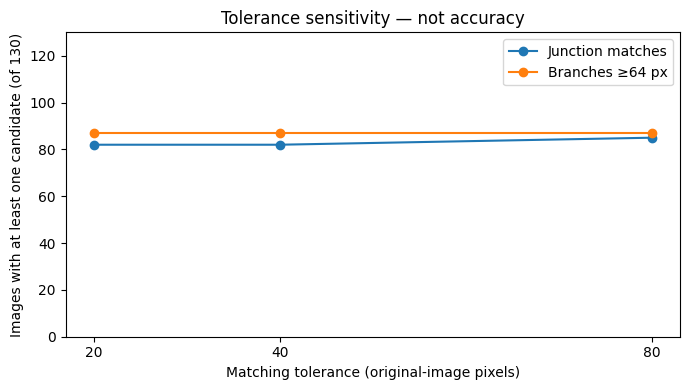

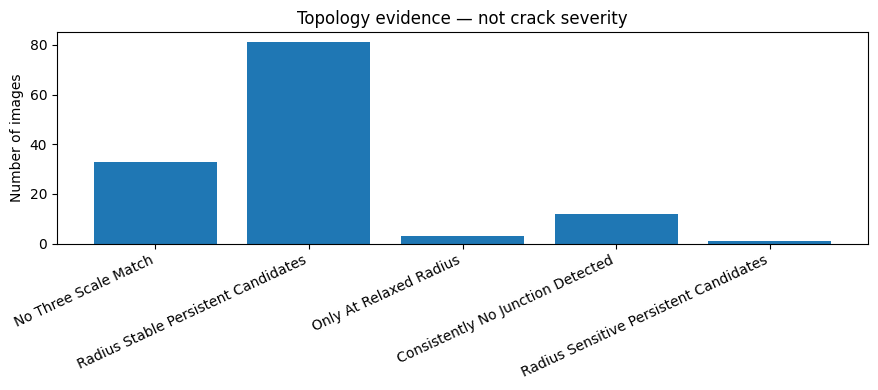


C3-07 SECTION 8 — TOPOLOGY RELIABILITY AUDIT
{
  "stage": "C3-07_SECTION08_TOPOLOGY_RELIABILITY_V1",
  "total": 130,
  "evidence_categories": {
    "NO_THREE_SCALE_MATCH": 33,
    "RADIUS_STABLE_PERSISTENT_CANDIDATES": 81,
    "ONLY_AT_RELAXED_RADIUS": 3,
    "CONSISTENTLY_NO_JUNCTION_DETECTED": 12,
    "RADIUS_SENSITIVE_PERSISTENT_CANDIDATES": 1
  },
  "radius20_junction_images": 82,
  "radius40_junction_images": 82,
  "radius80_junction_images": 85,
  "radius20_branch64_images": 87,
  "radius40_branch64_images": 87,
  "radius80_branch64_images": 87,
  "junction_match_radius_stable_images": 126,
  "branch_match_radius_stable_images": 121,
  "branch_endpoint_matches_without_matched_junction": 7,
  "nonmonotone_greedy_matches": 0,
  "truncated_images": 127,
  "fragmented_images": 19,
  "severity_ground_truth_available": false,
  "physical_scale_verified": false,
  "independent_scene_validation": false
}

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C

In [ ]:

# ============================================================
# C3-07 SECTION 8 — TOPOLOGY RELIABILITY AUDIT
# Existing 130-image results only. Low memory.
# No physical severity or calibrated scale claims.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import hashlib, json, csv
import numpy as np
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

S4 = BASE / "07_evaluation" / (
    "C3-07_section04_SAFE_PROFILE_"
    "20261020T153954_792654Z"
)

S7 = BASE / "07_evaluation" / (
    "C3-07_section07_FULL130_TRISCALE_V1"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

assert S4.is_dir() and S7.is_dir()


# ------------------------------------------------------------
# 1. VERIFY EXISTING RESEARCH ARTIFACTS
# ------------------------------------------------------------

def digest(path):
    h = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def verify(folder, required):

    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        hexdigest, relative = line.split(None, 1)
        relative = relative.strip()
        p = Path(relative)

        assert not p.is_absolute()
        assert ".." not in p.parts
        assert relative not in expected

        expected[relative] = hexdigest

    for name in required:

        assert name in expected, name

        assert (
            digest(folder / name)
            == expected[name]
        ), ("Changed input", name)

    return expected


hs4 = verify(
    S4, ["research_report.json"]
)

required7 = [
    "full130_topology_report.json",
    "all130_topology_profiles.csv",
    "locked_protocol.json"
] + [
    f"samples/{i:03d}.json"
    for i in range(1, 131)
]

hs7 = verify(S7, required7)

p4 = json.loads(
    (S4 / "research_report.json").read_text()
)

p7 = json.loads(
    (S7 / "full130_topology_report.json").read_text()
)

assert p4["summary"]["processed"] == 130
assert p7["summary"]["processed"] == 130

assert (
    p7["summary"][
        "images_with_persistent_junctions"
    ] == 82
)

assert (
    p7["summary"][
        "images_with_persistent_64px_branches"
    ] == 87
)

assert (
    p7["summary"]["pilot_results_reproduced"]
    == 5
)

source_profiles = {
    int(r["sample_id"]): r
    for r in p4["profiles"]
}

source_topology = {
    int(r["sample_id"]): r
    for r in p7["per_image"]
}

assert (
    set(source_profiles)
    == set(source_topology)
    == set(range(1, 131))
)

protocol = json.loads(
    (S7 / "locked_protocol.json").read_text()
)

assert (
    protocol["radii_original_pixels"]
    == [20, 40, 80]
)

assert (
    protocol["branch_thresholds_original_pixels"]
    == [32, 64, 128]
)

assert protocol["factors"] == [4, 6, 8]

print(
    "130-image source and per-image integrity: PASS"
)


# ------------------------------------------------------------
# 2. COMBINE CRACK FEATURES AND TOPOLOGY RELIABILITY
# ------------------------------------------------------------

rows = []

for sid in range(1, 131):

    sample = json.loads(
        (
            S7 / "samples" / f"{sid:03d}.json"
        ).read_text()
    )

    old = source_topology[sid]
    profile = source_profiles[sid]

    assert sample["status"] == "MEASURED"
    assert sample["sample_id"] == sid

    sensitivity = sample["matching_sensitivity"]

    assert set(sensitivity) == {
        "20", "40", "80"
    }

    junctions = [
        int(
            sensitivity[str(radius)]["junctions"]
        )
        for radius in [20, 40, 80]
    ]

    branches = [
        int(
            sensitivity[str(radius)]["branches"]["64"]
        )
        for radius in [20, 40, 80]
    ]

    counts = [
        int(
            sample["scales"][str(factor)][
                "junction_clusters"
            ]
        )
        for factor in [4, 6, 8]
    ]

    # Verify reproduction of Section 7.
    assert (
        junctions[1]
        == sample["persistent_junctions_count"]
        == old["persistent_junctions_40px"]
    )

    assert (
        branches[1]
        == sample[
            "persistent_terminal_branch_counts"
        ]["64"]
        == old["persistent_branches_ge64px"]
    )

    assert (
        junctions[0]
        == old["junction_matches_20px"]
    )

    assert (
        junctions[2]
        == old["junction_matches_80px"]
    )

    # ----------------------------------------
    # Evidence category, NOT severity.
    # ----------------------------------------

    if counts == [0, 0, 0]:

        category = (
            "CONSISTENTLY_NO_JUNCTION_DETECTED"
        )

    elif (
        junctions[0] > 0
        and junctions[0]
        == junctions[1]
        == junctions[2]
    ):

        category = (
            "RADIUS_STABLE_PERSISTENT_CANDIDATES"
        )

    elif junctions[1] > 0:

        category = (
            "RADIUS_SENSITIVE_PERSISTENT_CANDIDATES"
        )

    elif junctions[2] > 0:

        category = "ONLY_AT_RELAXED_RADIUS"

    else:

        category = "NO_THREE_SCALE_MATCH"

    # ----------------------------------------
    # Explicit reliability and limitation flags.
    # ----------------------------------------

    flags = []

    if profile["touches_image_border"]:
        flags.append(
            "VISIBLE_EXTENT_TRUNCATED"
        )

    if profile["fragmented_skeleton"]:
        flags.append(
            "MULTIPLE_SKELETON_COMPONENTS"
        )

    if len(set(counts)) > 1:
        flags.append(
            "JUNCTION_COUNT_SCALE_DEPENDENT"
        )

    if len(set(junctions)) > 1:
        flags.append(
            "JUNCTION_MATCH_RADIUS_SENSITIVE"
        )

    if len(set(branches)) > 1:
        flags.append(
            "BRANCH_MATCH_RADIUS_SENSITIVE"
        )

    if branches[1] > 0 and junctions[1] == 0:
        flags.append(
            "MATCHED_BRANCH_ENDPOINT_WITHOUT_MATCHED_JUNCTION"
        )

    # Greedy matching is not guaranteed to
    # be monotonic as tolerance increases.
    if (
        not (
            junctions[0]
            <= junctions[1]
            <= junctions[2]
        )
        or not (
            branches[0]
            <= branches[1]
            <= branches[2]
        )
    ):
        flags.append(
            "GREEDY_MATCH_NONMONOTONE"
        )

    rows.append({
        "sample_id": sid,

        "evidence_category": category,

        "junctions_4x": counts[0],
        "junctions_6x": counts[1],
        "junctions_8x": counts[2],

        "junction_match_20px": junctions[0],
        "junction_match_40px": junctions[1],
        "junction_match_80px": junctions[2],

        "branch_64px_match_20px": branches[0],
        "branch_64px_match_40px": branches[1],
        "branch_64px_match_80px": branches[2],

        "junction_radius_stable":
            junctions[0] == junctions[1] == junctions[2],

        "branch_radius_stable":
            branches[0] == branches[1] == branches[2],

        "width_p95_px":
            float(profile["p95_width_px"]),

        "width_irregularity_ratio":
            float(profile["width_irregularity_ratio"]),

        "visible_length_px":
            float(profile["visible_length_px"]),

        "mask_fraction":
            float(profile["mask_fraction"]),

        "fragmented_skeleton":
            bool(profile["fragmented_skeleton"]),

        "touches_image_border":
            bool(profile["touches_image_border"]),

        "research_inspection_percentile_unvalidated":
            float(
                profile[
                    "unvalidated_inspection_percentile"
                ]
            ),

        "reliability_flags": flags,

        "severity_label": None,
        "physical_scale_certified": False
    })


# ------------------------------------------------------------
# 3. CHECK THE AGGREGATED EVIDENCE
# ------------------------------------------------------------

assert len(rows) == 130

assert sum(
    r["junction_match_40px"] > 0
    for r in rows
) == 82

assert sum(
    r["branch_64px_match_40px"] > 0
    for r in rows
) == 87

assert sum(
    r["touches_image_border"]
    for r in rows
) == 127

assert sum(
    r["fragmented_skeleton"]
    for r in rows
) == 19


summary = {
    "stage": (
        "C3-07_SECTION08_TOPOLOGY_RELIABILITY_V1"
    ),

    "total": 130,

    "evidence_categories": dict(
        Counter(
            r["evidence_category"]
            for r in rows
        )
    ),

    "radius20_junction_images": sum(
        r["junction_match_20px"] > 0
        for r in rows
    ),

    "radius40_junction_images": sum(
        r["junction_match_40px"] > 0
        for r in rows
    ),

    "radius80_junction_images": sum(
        r["junction_match_80px"] > 0
        for r in rows
    ),

    "radius20_branch64_images": sum(
        r["branch_64px_match_20px"] > 0
        for r in rows
    ),

    "radius40_branch64_images": sum(
        r["branch_64px_match_40px"] > 0
        for r in rows
    ),

    "radius80_branch64_images": sum(
        r["branch_64px_match_80px"] > 0
        for r in rows
    ),

    "junction_match_radius_stable_images": sum(
        r["junction_radius_stable"]
        for r in rows
    ),

    "branch_match_radius_stable_images": sum(
        r["branch_radius_stable"]
        for r in rows
    ),

    "branch_endpoint_matches_without_matched_junction":
        sum(
            "MATCHED_BRANCH_ENDPOINT_WITHOUT_MATCHED_JUNCTION"
            in r["reliability_flags"]
            for r in rows
        ),

    "nonmonotone_greedy_matches": sum(
        "GREEDY_MATCH_NONMONOTONE"
        in r["reliability_flags"]
        for r in rows
    ),

    "truncated_images": 127,
    "fragmented_images": 19,

    "severity_ground_truth_available": False,
    "physical_scale_verified": False,
    "independent_scene_validation": False
}


# ------------------------------------------------------------
# 4. SAVE VERSIONED PROFILE AND API CONTRACT
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "07_evaluation" / (
    f"C3-07_section08_RELIABILITY_AUDIT_{stamp}"
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)


with (
    OUT / "all130_reliability_profiles.csv"
).open("w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(rows[0])
    )

    writer.writeheader()

    for row in rows:

        writer.writerow({
            key: (
                json.dumps(value)
                if isinstance(value, (list, dict))
                else value
            )
            for key, value in row.items()
        })


(
    OUT / "reliability_report.json"
).write_text(
    json.dumps({
        "summary": summary,
        "records": rows,

        "source_hashes": {
            "C3-07-S4":
                hs4["research_report.json"],

            "C3-07-S7":
                hs7["full130_topology_report.json"]
        }
    }, indent=2)
)


(
    OUT / "api_contract.json"
).write_text(
    json.dumps({
        "version": (
            "C3_CRACK_TOPOLOGY_RELIABILITY_V1"
        ),

        "input": (
            "Existing 130-image morphology and "
            "tri-scale observation records"
        ),

        "outputs": [
            "Length, width, coverage",
            "Three-scale junction counts",
            "Persistent branch endpoint candidates",
            "Location tolerance sensitivity",
            "Topology reliability flags"
        ],

        "severity_label": None,
        "physical_units_certified": False,

        "interpretation": (
            "Image-derived structural feature audit, "
            "not a calibrated distress severity rating"
        ),

        "limitations": [
            "Ground-truth segmentation masks used",
            "Physical scene independence unverified",
            "Greedy matcher, no independently annotated junction ground truth",
            "No expert crack severity labels"
        ]
    }, indent=2)
)


# ------------------------------------------------------------
# 5. VISUALIZE TOLERANCE SENSITIVITY
# ------------------------------------------------------------

radii = [20, 40, 80]

junction_counts = [
    summary[f"radius{r}_junction_images"]
    for r in radii
]

branch_counts = [
    summary[f"radius{r}_branch64_images"]
    for r in radii
]

fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.plot(
    radii,
    junction_counts,
    marker="o",
    label="Junction matches"
)

ax.plot(
    radii,
    branch_counts,
    marker="o",
    label="Branches ≥64 px"
)

ax.set_xlabel(
    "Matching tolerance (original-image pixels)"
)

ax.set_ylabel(
    "Images with at least one candidate (of 130)"
)

ax.set_ylim(0, 130)
ax.set_xticks(radii)
ax.legend()

ax.set_title(
    "Tolerance sensitivity — not accuracy"
)

fig.tight_layout()

fig.savefig(
    OUT / "radius_sensitivity.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 6. TOPOLOGY EVIDENCE DISTRIBUTION
# ------------------------------------------------------------

names = list(
    summary["evidence_categories"]
)

values = [
    summary["evidence_categories"][name]
    for name in names
]

fig, ax = plt.subplots(
    figsize=(9, 4)
)

ax.bar(
    range(len(names)),
    values
)

ax.set_xticks(
    range(len(names)),
    [
        name.replace("_", " ").title()
        for name in names
    ],
    rotation=25,
    ha="right"
)

ax.set_ylabel(
    "Number of images"
)

ax.set_title(
    "Topology evidence — not crack severity"
)

fig.tight_layout()

fig.savefig(
    OUT / "topology_evidence_categories.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 7. CHECKSUMS
# ------------------------------------------------------------

lines = []

for path in sorted(
    OUT.iterdir()
):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        lines.append(
            f"{digest(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*62)
print("C3-07 SECTION 8 — TOPOLOGY RELIABILITY AUDIT")
print("="*62)

print(
    json.dumps(
        summary,
        indent=2
    )
)

print("\nSaved:", OUT)
print("="*62)


Research source integrity: PASS
Training observations: 130
Predetermined development folds: 5
Physical scene independence: UNVERIFIED
length_linear        | Blocked-CV MAE: 9.004 label-cm
morph_ridge          | Blocked-CV MAE: 7.771 label-cm
tmer_ridge           | Blocked-CV MAE: 8.177 label-cm
tmer_random_forest   | Blocked-CV MAE: 9.604 label-cm
All four checkpoint reload tests: PASS
Standalone inference smoke tests: PASS
Two blank severity-label templates: SAVED


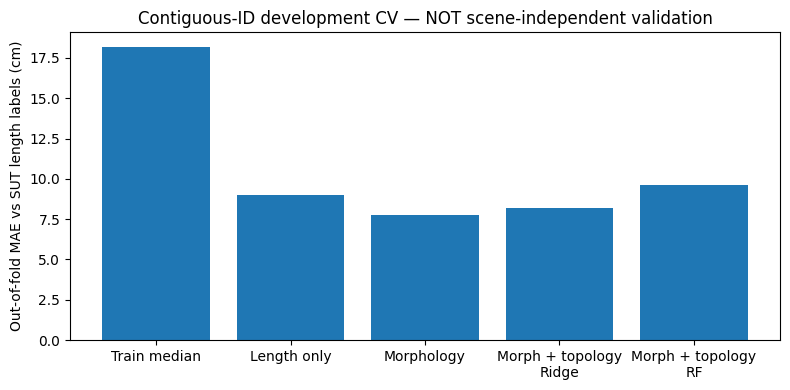


C3-07 SECTION 9 — SUPERVISED CRACK-LENGTH DEVELOPMENT
training_median_baseline MAE label-cm: 18.177
length_linear MAE label-cm: 9.004
morph_ridge MAE label-cm: 7.771
tmer_ridge MAE label-cm: 8.177
tmer_random_forest MAE label-cm: 9.604
Topology Ridge better than morphology Ridge: False
Checkpoint reload and inference: PASS
Independent scene validation: NO
Physical severity training: NOT AUTHORIZED

Evaluation: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-07_section09_SUPERVISED_LENGTH_ABLATION_20261020T164116_613524Z
Checkpoints: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-07_section09_SUPERVISED_LENGTH_ABLATION_20261020T164116_613524Z


In [ ]:

# ==============================================================
# C3-07 SECTION 9 — SUPERVISED CRACK-LENGTH ABLATION
# Existing 130-image saved profiles only; CPU-friendly.
# NO validated crack severity; not mobile-camera calibration.
# ==============================================================

from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
import json, csv, hashlib, shutil
import joblib, sklearn, importlib.util

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import spearmanr

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)

S3 = BASE / "07_evaluation" / (
    "C3-07_section03_SUT_FULL130_"
    "20261020T145153_432660Z"
)

S8 = BASE / "07_evaluation" / (
    "C3-07_section08_RELIABILITY_AUDIT_"
    "20261020T162725_970547Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")


# ------------------------------------------------------------
# 1. VERIFY PREVIOUS DATA AND REPORTS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as fp:
        for part in iter(
            lambda: fp.read(1024*1024), b""
        ):
            h.update(part)
    return h.hexdigest()


def verify(folder, filenames):

    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, name = line.split(None, 1)
        name = name.strip()
        rel = Path(name)

        assert not rel.is_absolute()
        assert ".." not in rel.parts
        assert name not in expected

        expected[name] = digest

    for name in filenames:
        assert name in expected
        assert (folder / name).is_file()
        assert sha(folder / name) == expected[name], name

    return expected


h3 = verify(S3, [
    "full130_report.json"
])

h8 = verify(S8, [
    "reliability_report.json",
    "all130_reliability_profiles.csv"
])

p3 = json.loads(
    (S3 / "full130_report.json").read_text()
)

p8 = json.loads(
    (S8 / "reliability_report.json").read_text()
)

assert p3["summary"]["measured"] == 130
assert p8["summary"]["total"] == 130

assert (
    p8["summary"]["severity_ground_truth_available"]
    is False
)

original = {
    int(r["sample_id"]): r
    for r in p3["per_image"]
}

profile = {
    int(r["sample_id"]): r
    for r in p8["records"]
}

assert set(original) == set(profile) == set(
    range(1, 131)
)

print("Research source integrity: PASS")


# ------------------------------------------------------------
# 2. DEFINE THREE FIXED FEATURE SETS
# ------------------------------------------------------------

LENGTH = [
    "visible_length_px"
]

MORPH = LENGTH + [
    "width_p95_px",
    "width_irregularity_ratio",
    "mask_fraction",
    "fragmented_skeleton",
    "touches_image_border"
]

TMER = MORPH + [
    "stable_junction_evidence",
    "stable_anchored_branch_evidence",
    "junction_scale_range",
    "junction_tolerance_sensitive"
]

records = []

for sid in range(1, 131):

    p = profile[sid]

    j = [
        int(p[f"junction_match_{r}px"])
        for r in (20, 40, 80)
    ]

    b = [
        int(p[f"branch_64px_match_{r}px"])
        for r in (20, 40, 80)
    ]

    jscale = [
        int(p[f"junctions_{f}x"])
        for f in (4, 6, 8)
    ]

    label = float(
        original[sid]["reference_length_cm"]
    )

    assert np.isfinite(label) and label > 0

    item = {
        "sample_id": sid,
        "blocked_fold": (sid-1)//26,
        "dataset_label_length_cm": label,

        "visible_length_px":
            float(p["visible_length_px"]),

        "width_p95_px":
            float(p["width_p95_px"]),

        "width_irregularity_ratio":
            float(p["width_irregularity_ratio"]),

        "mask_fraction":
            float(p["mask_fraction"]),

        "fragmented_skeleton":
            float(bool(p["fragmented_skeleton"])),

        "touches_image_border":
            float(bool(p["touches_image_border"])),

        # Require matched junctions to remain
        # stable at all three location tolerances.
        "stable_junction_evidence": float(
            j[0]
            if j[0] > 0 and len(set(j)) == 1
            else 0
        ),

        # Suppress endpoint-only evidence
        # without a matched junction candidate.
        "stable_anchored_branch_evidence": float(
            b[0]
            if (
                b[0] > 0
                and len(set(b)) == 1
                and j[0] > 0
            )
            else 0
        ),

        "junction_scale_range":
            float(max(jscale)-min(jscale)),

        "junction_tolerance_sensitive":
            float(len(set(j)) > 1)
    }

    assert all(
        np.isfinite(item[x])
        for x in TMER
    )

    records.append(item)


IDs = np.array([
    r["sample_id"]
    for r in records
], dtype=int)

Y = np.array([
    r["dataset_label_length_cm"]
    for r in records
], dtype=float)

folds = np.array([
    r["blocked_fold"]
    for r in records
], dtype=int)

assert list(np.bincount(folds)) == [26]*5

print("Training observations:", len(records))
print("Predetermined development folds:", 5)
print("Physical scene independence: UNVERIFIED")


# ------------------------------------------------------------
# 3. FIXED MODEL DEFINITIONS
# ------------------------------------------------------------

MODEL_SPECS = {
    "length_linear": (
        LENGTH,
        lambda: LinearRegression()
    ),

    "morph_ridge": (
        MORPH,
        lambda: make_pipeline(
            StandardScaler(),
            Ridge(alpha=10.0)
        )
    ),

    "tmer_ridge": (
        TMER,
        lambda: make_pipeline(
            StandardScaler(),
            Ridge(alpha=10.0)
        )
    ),

    "tmer_random_forest": (
        TMER,
        lambda: RandomForestRegressor(
            n_estimators=180,
            min_samples_leaf=4,
            max_features=0.8,
            random_state=20261020,
            n_jobs=1
        )
    )
}


# ------------------------------------------------------------
# 4. CREATE VERSIONED EXPERIMENT FOLD MANIFEST
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

NAME = (
    "C3-07_section09_SUPERVISED_LENGTH_ABLATION_"
    + stamp
)

OUT = BASE / "07_evaluation" / NAME
CK = BASE / "06_model_checkpoints" / NAME

OUT.mkdir(
    parents=True,
    exist_ok=False
)

CK.mkdir(
    parents=True,
    exist_ok=False
)

with (
    OUT / "frozen_130_id_block_folds.csv"
).open("w", newline="") as fp:

    writer = csv.writer(fp)

    writer.writerow([
        "sample_id",
        "fold_id",
        "role_note"
    ])

    for r in records:
        writer.writerow([
            r["sample_id"],
            r["blocked_fold"],
            "Development cross-validation only"
        ])


protocol = {
    "stage": (
        "C3-07_SECTION09_SUPERVISED_"
        "ANNOTATED_LENGTH_V1"
    ),

    "source_s3_sha256":
        h3["full130_report.json"],

    "source_s8_sha256":
        h8["reliability_report.json"],

    "fold_rule": (
        "5 deterministic contiguous ID blocks: "
        "1-26, 27-52, 53-78, 79-104, 105-130"
    ),

    "crack_scene_independence_verified": False,

    "metric_capture_calibration_verified": False,

    "training_labels": (
        "SUT-Crack dataset-provided crack "
        "length in centimetres; measurement "
        "protocol unverified"
    ),

    "not_severity_labels": True,

    "no_severity_prediction": True,

    "feature_sets": {
        "length_only": LENGTH,
        "morphology": MORPH,
        "morphology_plus_topology": TMER
    },

    "models": {
        "length_linear": "LinearRegression",
        "morph_ridge": (
            "StandardScaler + Ridge(alpha=10)"
        ),
        "tmer_ridge": (
            "StandardScaler + Ridge(alpha=10)"
        ),
        "tmer_random_forest": (
            "RandomForestRegressor("
            "180 trees, min_samples_leaf=4, "
            "max_features=0.8)"
        )
    },

    "exclusions": [
        "sample_id",
        "fold_id",
        "reference label",
        "cohort inspection percentiles"
    ],

    "checkpoint_selection": (
        "Exploratory cross-validation; "
        "selection bias possible"
    ),

    "severity_backend_release_authorized": False
}

(
    OUT / "precommitted_protocol.json"
).write_text(
    json.dumps(protocol, indent=2)
)


# ------------------------------------------------------------
# 5. FIVE-FOLD SUPERVISED MODEL TRAINING
# ------------------------------------------------------------

allpred = {}
metrics = {}

for name, (features, factory) in MODEL_SPECS.items():

    X = np.array([
        [r[f] for f in features]
        for r in records
    ], dtype=float)

    assert X.shape == (
        130, len(features)
    )

    predictions = np.full(
        130, np.nan
    )

    per_fold = []

    for k in range(5):

        train = folds != k
        test = folds == k

        assert int(test.sum()) == 26
        assert int(train.sum()) == 104

        model = factory()

        model.fit(
            X[train],
            Y[train]
        )

        predictions[test] = model.predict(
            X[test]
        )

        fold_mae = float(
            mean_absolute_error(
                Y[test],
                predictions[test]
            )
        )

        per_fold.append({
            "fold_id": k,
            "n": 26,
            "mae_cm": fold_mae
        })

    assert np.isfinite(
        predictions
    ).all()

    allpred[name] = predictions

    metrics[name] = {
        "MAE_cm_development_CV": float(
            mean_absolute_error(
                Y, predictions
            )
        ),

        "RMSE_cm_development_CV": float(
            np.sqrt(
                mean_squared_error(
                    Y, predictions
                )
            )
        ),

        "Spearman_development_CV": float(
            spearmanr(
                Y, predictions
            ).statistic
        ),

        "per_fold": per_fold,
        "features": features
    }

    print(
        f"{name:20s} | "
        f"Blocked-CV MAE: "
        f"{metrics[name]['MAE_cm_development_CV']:.3f} "
        "label-cm",
        flush=True
    )


# ------------------------------------------------------------
# 6. TRAINING-MEDIAN BASELINE
# ------------------------------------------------------------

median_preds = np.full(
    130, np.nan
)

for k in range(5):
    median_preds[folds == k] = np.median(
        Y[folds != k]
    )

metrics["training_median_baseline"] = {
    "MAE_cm_development_CV": float(
        mean_absolute_error(
            Y, median_preds
        )
    ),

    "RMSE_cm_development_CV": float(
        np.sqrt(
            mean_squared_error(
                Y, median_preds
            )
        )
    )
}


# ------------------------------------------------------------
# 7. SAVE OUT-OF-FOLD PREDICTIONS
# ------------------------------------------------------------

with (
    OUT / "out_of_fold_predictions.csv"
).open("w", newline="") as fp:

    columns = [
        "sample_id",
        "fold",
        "reference_label_cm",
        "training_median"
    ] + list(MODEL_SPECS)

    writer = csv.DictWriter(
        fp,
        fieldnames=columns
    )

    writer.writeheader()

    for i, sid in enumerate(IDs):

        writer.writerow({
            "sample_id": int(sid),
            "fold": int(folds[i]),
            "reference_label_cm": Y[i],
            "training_median": median_preds[i],

            **{
                name: float(pred[i])
                for name, pred in allpred.items()
            }
        })


# ------------------------------------------------------------
# 8. TRAIN AND SAVE DEVELOPMENT CHECKPOINTS
# ------------------------------------------------------------

load_tests = {}

for name, (features, factory) in MODEL_SPECS.items():

    X = np.array([
        [r[f] for f in features]
        for r in records
    ], dtype=float)

    estimator = factory()

    estimator.fit(X, Y)

    path = CK / f"{name}.joblib"

    joblib.dump({
        "estimator": estimator,

        "input_features": features,

        "contract": (
            "C3_SUT_CRACK_ANNOTATED_LENGTH_DEV_V1"
        ),

        "trained_on": 130,

        "deployment_authorized": False,

        "label_definition": (
            "SUT-Crack dataset-provided length (cm)"
        )
    }, path)

    restored = joblib.load(path)

    a = estimator.predict(
        X[:3]
    )

    b = restored[
        "estimator"
    ].predict(X[:3])

    assert np.allclose(
        a, b,
        atol=1e-9
    )

    load_tests[name] = "PASS"

print("All four checkpoint reload tests: PASS")


# ------------------------------------------------------------
# 9. STANDALONE DEVELOPMENT INFERENCE
# ------------------------------------------------------------

INFERENCE = '''
from pathlib import Path
import numpy as np
import joblib

def predict_dataset_label_cm(feature_record, model_path):

    bundle = joblib.load(Path(model_path))

    assert bundle["contract"] == (
        "C3_SUT_CRACK_ANNOTATED_LENGTH_DEV_V1"
    )

    names = bundle["input_features"]

    x = np.array([[
        float(feature_record[k])
        for k in names
    ]], dtype=float)

    if not np.isfinite(x).all():
        raise ValueError("Nonfinite feature")

    result = float(
        bundle["estimator"].predict(x)[0]
    )

    return {
        "predicted_dataset_length_label_cm": result,
        "deployment_authorized": False,
        "severity_label": None,
        "note": (
            "Experimental same-dataset learned estimate, "
            "NOT calibrated cross-phone measurement"
        )
    }
'''

(
    CK / "development_length_inference.py"
).write_text(INFERENCE)


spec = importlib.util.spec_from_file_location(
    "crack_length_dev_api",
    CK / "development_length_inference.py"
)

api = importlib.util.module_from_spec(spec)
spec.loader.exec_module(api)

for name, (features, _) in MODEL_SPECS.items():

    sample_result = api.predict_dataset_label_cm(
        records[0],
        CK / f"{name}.joblib"
    )

    assert np.isfinite(
        sample_result[
            "predicted_dataset_length_label_cm"
        ]
    )

    assert (
        sample_result["severity_label"]
        is None
    )

print("Standalone inference smoke tests: PASS")


# ------------------------------------------------------------
# 10. SAVE ARCHITECTURE AND PREPROCESSING CONTRACT
# ------------------------------------------------------------

(
    CK / "model_architecture_and_preprocessing.json"
).write_text(
    json.dumps({
        "contract": (
            "C3_SUT_CRACK_ANNOTATED_LENGTH_DEV_V1"
        ),

        "candidate_feature_lists": {
            k: value[0]
            for k, value in MODEL_SPECS.items()
        },

        "fixed_fold_rule":
            protocol["fold_rule"],

        "normalization": (
            "StandardScaler fitted separately "
            "on each training fold for Ridge; "
            "no global feature normalization"
        ),

        "severity_enabled": False,

        "physical_scale_certified": False,

        "ground_truth_type": (
            "SUT-Crack centimetre length labels; "
            "capture and measurement protocol "
            "not verified"
        )
    }, indent=2)
)


# ------------------------------------------------------------
# 11. PREPARE BLANK EXPERT SEVERITY LABEL SHEETS
# ------------------------------------------------------------

for rater in ("A", "B"):

    with (
        OUT / f"expert_{rater}_blank_severity_annotation.csv"
    ).open("w", newline="") as fp:

        writer = csv.writer(fp)

        writer.writerow([
            "sample_id",
            "image_relative_path",
            "rater_id",
            "rating_standard_and_version",
            "distress_type",
            "severity_low_medium_high",
            "spalling",
            "branching_visible",
            "image_sufficient_for_rating",
            "reason_if_unassessable",
            "notes"
        ])

        for sid in range(1, 131):

            writer.writerow([
                sid,
                (
                    "SUT-Crack/1-Segmentation/"
                    f"Original Image/{sid}.jpg"
                ),
                rater,
                "", "", "", "", "", "", "", ""
            ])

print("Two blank severity-label templates: SAVED")


# ------------------------------------------------------------
# 12. CREATE MODEL-ABLATION CHART
# ------------------------------------------------------------

order = [
    "training_median_baseline"
] + list(MODEL_SPECS)

values = [
    metrics[k]["MAE_cm_development_CV"]
    for k in order
]

fig, ax = plt.subplots(
    figsize=(8, 4)
)

ax.bar(
    range(len(order)),
    values
)

ax.set_xticks(
    range(len(order)),
    [
        "Train median",
        "Length only",
        "Morphology",
        "Morph + topology\nRidge",
        "Morph + topology\nRF"
    ]
)

ax.set_ylabel(
    "Out-of-fold MAE vs SUT length labels (cm)"
)

ax.set_title(
    "Contiguous-ID development CV — "
    "NOT scene-independent validation"
)

fig.tight_layout()

fig.savefig(
    OUT / "blocked_cv_model_ablation.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 13. FINAL RESEARCH REPORT
# ------------------------------------------------------------

improvement = (
    metrics["morph_ridge"]["MAE_cm_development_CV"]
    -
    metrics["tmer_ridge"]["MAE_cm_development_CV"]
)

report = {
    "stage": protocol["stage"],

    "training_examples": 130,

    "cross_validation": (
        "Five contiguous-ID development blocks; "
        "physical scene leakage unknown"
    ),

    "metrics": metrics,

    "added_topology_reduces_Ridge_MAE_on_dev_CV":
        bool(improvement > 0),

    "topology_Ridge_minus_morph_Ridge_MAE_cm":
        float(-improvement),

    "checkpoint_reload_smoke": load_tests,

    "all_candidate_models_fitted_on_all_130_after_CV":
        True,

    "expert_severity_labels_provided": False,

    "physical_camera_calibration_verified": False,

    "metric_severity_authorized": False,

    "model_selection_bias_possible": True
}

(
    OUT / "supervised_length_ablation_report.json"
).write_text(
    json.dumps(
        report,
        indent=2
    )
)


# ------------------------------------------------------------
# 14. SAVE OUTPUT CHECKSUMS
# ------------------------------------------------------------

for folder in (OUT, CK):

    lines = []

    for path in sorted(
        folder.iterdir()
    ):

        if (
            path.is_file()
            and path.name != "checksums.sha256"
        ):

            lines.append(
                f"{sha(path)}  {path.name}"
            )

    (
        folder / "checksums.sha256"
    ).write_text(
        "\n".join(lines) + "\n"
    )


# ------------------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*64)

print(
    "C3-07 SECTION 9 — SUPERVISED "
    "CRACK-LENGTH DEVELOPMENT"
)

print("="*64)

for name in order:

    print(
        name,
        "MAE label-cm:",
        round(
            metrics[name]["MAE_cm_development_CV"],
            3
        )
    )

print(
    "Topology Ridge better than morphology Ridge:",
    improvement > 0
)

print("Checkpoint reload and inference: PASS")
print("Independent scene validation: NO")
print("Physical severity training: NOT AUTHORIZED")

print("\nEvaluation:", OUT)
print("Checkpoints:", CK)

print("="*64)


In [ ]:

# ============================================================
# C3-07 SECTION 10 — BLINDED VISUAL DISTRESS PILOT
# 30 original photographs, two independent reviewer forms.
# No fabricated engineering severity labels.
# ============================================================

from pathlib import Path
from collections import Counter
from PIL import Image, ImageOps, ImageDraw
import hashlib, json, csv, gc
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

SUT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "SUT-Crack/1-Segmentation/Original Image"
)

S8 = BASE / "07_evaluation" / (
    "C3-07_section08_RELIABILITY_AUDIT_"
    "20261020T162725_970547Z"
)

S9 = BASE / "07_evaluation" / (
    "C3-07_section09_SUPERVISED_LENGTH_ABLATION_"
    "20261020T164116_613524Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

assert SUT.is_dir() and S8.is_dir() and S9.is_dir()


# ------------------------------------------------------------
# 1. VERIFY COMPLETED RESEARCH
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def verify(folder, filename):
    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():
            digest, name = line.split(None, 1)
            expected[name.strip()] = digest

    assert filename in expected
    assert sha(folder / filename) == expected[filename]

    return expected[filename]


sha8 = verify(S8, "reliability_report.json")

sha9 = verify(
    S9, "supervised_length_ablation_report.json"
)

p8 = json.loads(
    (S8 / "reliability_report.json").read_text()
)

p9 = json.loads(
    (
        S9 / "supervised_length_ablation_report.json"
    ).read_text()
)

assert p8["summary"]["total"] == 130
assert p9["training_examples"] == 130
assert p9["expert_severity_labels_provided"] is False

by_id = {
    int(r["sample_id"]): r
    for r in p8["records"]
}

assert set(by_id) == set(range(1, 131))

print("Source reports verified: PASS")


# ------------------------------------------------------------
# 2. PRECOMMITTED, DIVERSE 30-IMAGE SELECTION
# ------------------------------------------------------------

# This is a stratified DEVELOPMENT pilot.
# It is NOT an unbiased independent test sample.

QUOTAS = {
    "RADIUS_STABLE_PERSISTENT_CANDIDATES": 13,
    "NO_THREE_SCALE_MATCH": 8,
    "CONSISTENTLY_NO_JUNCTION_DETECTED": 5,
    "ONLY_AT_RELAXED_RADIUS": 3,
    "RADIUS_SENSITIVE_PERSISTENT_CANDIDATES": 1
}

assert sum(QUOTAS.values()) == 30

selected = []

for category, quota in QUOTAS.items():

    candidates = [
        r for r in by_id.values()
        if r["evidence_category"] == category
    ]

    # Cover the category's observed width range.
    # This is NOT severity-based sampling.
    candidates.sort(
        key=lambda r: (
            float(r["width_p95_px"]),
            int(r["sample_id"])
        )
    )

    assert len(candidates) >= quota

    indices = np.linspace(
        0,
        len(candidates) - 1,
        quota,
        dtype=int
    )

    assert len(set(indices.tolist())) == quota

    selected.extend(
        int(candidates[i]["sample_id"])
        for i in indices
    )

assert len(set(selected)) == 30

rng = np.random.default_rng(20261020)

review_order = [
    int(x)
    for x in rng.permutation(selected)
]


# ------------------------------------------------------------
# 3. CREATE RESTART-SAFE OUTPUT FOLDER
# ------------------------------------------------------------

OUT = BASE / "07_evaluation" / (
    "C3-07_section10_VISUAL_ANNOTATION_PILOT_V1"
)

OUT.mkdir(parents=True, exist_ok=True)

IMAGES = OUT / "review_images"
SHEETS = OUT / "contact_sheets"

IMAGES.mkdir(exist_ok=True)
SHEETS.mkdir(exist_ok=True)

protocol = {
    "stage": "C3-07_SECTION10_VISUAL_PILOT_V1",
    "sample_count": 30,
    "reviewers": 2,
    "sampling_quotas": QUOTAS,
    "randomization_seed": 20261020,
    "section08_sha256": sha8,
    "section09_sha256": sha9,
    "stratified_development_sample": True,
    "independent_test": False,
    "severity_ground_truth_created": False,
    "metric_scale_verified": False
}

locked = OUT / "locked_protocol.json"

if locked.exists():

    assert json.loads(
        locked.read_text()
    ) == protocol

else:

    locked.write_text(
        json.dumps(protocol, indent=2)
    )


# ------------------------------------------------------------
# 4. SAVE PRIVATE SAMPLING MANIFEST
# ------------------------------------------------------------

manifest_path = (
    OUT / "selection_manifest_RESEARCH_ONLY.csv"
)

if manifest_path.exists():

    with manifest_path.open(newline="") as file:
        saved = list(csv.DictReader(file))

    assert [
        int(row["sample_id"])
        for row in saved
    ] == review_order

else:

    with manifest_path.open(
        "w", newline=""
    ) as file:

        writer = csv.writer(file)

        writer.writerow([
            "review_order",
            "sample_id",
            "topology_stratum",
            "width_p95_px",
            "source_sha256"
        ])

        for position, sid in enumerate(
            review_order, 1
        ):

            writer.writerow([
                position,
                sid,
                by_id[sid]["evidence_category"],
                by_id[sid]["width_p95_px"],
                sha(SUT / f"{sid}.jpg")
            ])


# ------------------------------------------------------------
# 5. CREATE ORIENTATION-CORRECTED REVIEW IMAGES
# ------------------------------------------------------------

# JPEG draft decoding reduces RAM consumption.
# Original full-resolution photos are unchanged.

image_hashes = {}

for position, sid in enumerate(
    review_order, 1
):

    source = SUT / f"{sid}.jpg"

    target = IMAGES / f"sut_{sid:03d}.jpg"

    assert source.is_file()

    if not target.exists():

        with Image.open(source) as image:

            image.draft(
                "RGB", (1800, 1800)
            )

            oriented = ImageOps.exif_transpose(
                image
            )

            oriented.thumbnail(
                (1800, 1800),
                Image.Resampling.LANCZOS
            )

            preview = oriented.convert(
                "RGB"
            ).copy()

        preview.save(
            target,
            quality=86,
            optimize=True
        )

        del preview, oriented

    with Image.open(target) as check:
        check.verify()

    image_hashes[str(sid)] = sha(target)

    if position % 10 == 0:
        print(
            f"Review images prepared: {position}/30",
            flush=True
        )

    gc.collect()


# ------------------------------------------------------------
# 6. GENERATE THREE CONTACT SHEETS
# ------------------------------------------------------------

CELL_W = 370
CELL_H = 430

for sheet_number in range(3):

    canvas = Image.new(
        "RGB",
        (CELL_W * 3, CELL_H * 4),
        "white"
    )

    drawer = ImageDraw.Draw(canvas)

    current_ids = review_order[
        sheet_number * 10:
        (sheet_number + 1) * 10
    ]

    for index, sid in enumerate(current_ids):

        column = index % 3
        row = index // 3

        x0 = column * CELL_W
        y0 = row * CELL_H

        path = IMAGES / f"sut_{sid:03d}.jpg"

        with Image.open(path) as image:

            image.thumbnail(
                (CELL_W - 18, CELL_H - 65),
                Image.Resampling.LANCZOS
            )

            thumbnail = image.copy()

        canvas.paste(
            thumbnail,
            (
                x0 + (CELL_W - thumbnail.width) // 2,
                y0 + 37
            )
        )

        drawer.text(
            (x0 + 12, y0 + 10),
            f"SUT image {sid:03d}",
            fill="black"
        )

    canvas.save(
        SHEETS / (
            f"review_sheet_{sheet_number+1}.jpg"
        ),
        quality=88
    )

    del canvas


# ------------------------------------------------------------
# 7. CREATE TWO INDEPENDENT RATING FORMS
# ------------------------------------------------------------

FIELDS = [
    "review_order",
    "sample_id",
    "rater_id",
    "rgb_review_image",
    "visual_crack_pattern",
    "visible_network_complexity",
    "visible_opening_appearance",
    "surface_spalling_appearance",
    "apparent_visible_spread",
    "image_sufficient_for_assessment",
    "visual_inspection_priority",
    "reason_if_unassessable",
    "reason_for_priority",
    "annotation_date",
    "reviewer_experience",
    "reference_standard_if_any"
]

for rater in ("A", "B"):

    file_path = (
        OUT / f"BLINDED_RATER_{rater}_BLANK.csv"
    )

    # Never overwrite a reviewer form on rerun.
    if not file_path.exists():

        with file_path.open(
            "w", newline=""
        ) as file:

            writer = csv.DictWriter(
                file,
                fieldnames=FIELDS
            )

            writer.writeheader()

            for position, sid in enumerate(
                review_order, 1
            ):

                writer.writerow({
                    "review_order": position,
                    "sample_id": sid,
                    "rater_id": rater,
                    "rgb_review_image": (
                        f"review_images/sut_{sid:03d}.jpg"
                    )
                })


# ------------------------------------------------------------
# 8. DOCUMENT THE VISUAL RATING PROTOCOL
# ------------------------------------------------------------

instructions = """
C3-07 — PROVISIONAL VISUAL CRACK ASSESSMENT

This is NOT validated engineering severity.

Two reviewers should assess independently.

Do not give reviewers:
- Topology category or sampling manifest
- Model predictions or inspection percentiles
- The other reviewer's annotations

Fields and allowed values:

visual_crack_pattern:
linear | branched | interconnected/network |
multiple/disconnected | uncertain

visible_network_complexity:
none/simple | some branches |
extensive interconnection | uncertain

visible_opening_appearance:
apparently narrow | variable |
apparently wide | uncertain

surface_spalling_appearance:
visible | not_visible | uncertain

apparent_visible_spread:
localized_within_frame |
extended_within_frame | uncertain

image_sufficient_for_assessment:
yes | no

visual_inspection_priority:
lower | moderate | higher | unassessable

Guidance:
- Lower: relatively simple visible pattern with
  no obvious deterioration requiring urgent inspection.
- Moderate: visually noticeable branching,
  widening, or deterioration meriting inspection.
- Higher: visually extensive interconnected
  cracking or substantial apparent deterioration
  meriting more immediate field inspection.
- Unassessable: insufficient visual evidence.

These are PROVISIONAL REVIEW GUIDELINES ONLY.
They are not a pavement engineering standard.

Use uncertainty where the photo cannot support
a judgment. Do not infer physical crack width
in millimetres or total road damage extent.

If a reduced review photo hides important details,
consult the corresponding original JPEG.

Almost all SUT-Crack images have visible cracking
that reaches an image boundary.

The sample was deliberately stratified for
label-development research and is not an
independent random evaluation sample.

No severity classification model is trained
until actual independent annotations exist.
"""

(
    OUT / "RATER_INSTRUCTIONS.txt"
).write_text(instructions)


# ------------------------------------------------------------
# 9. VERIFY REVIEW FORMS AND IMAGE INTEGRITY
# ------------------------------------------------------------

for rater in ("A", "B"):

    file_path = (
        OUT / f"BLINDED_RATER_{rater}_BLANK.csv"
    )

    with file_path.open(newline="") as file:
        rows = list(csv.DictReader(file))

    assert len(rows) == 30

    assert [
        int(row["sample_id"])
        for row in rows
    ] == review_order


(
    OUT / "review_image_checksums.json"
).write_text(
    json.dumps(image_hashes, indent=2)
)


# ------------------------------------------------------------
# 10. SAVE CHECKSUMS
# ------------------------------------------------------------

checksum_lines = []

for path in sorted(OUT.rglob("*")):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):

        checksum_lines.append(
            f"{sha(path)}  "
            f"{path.relative_to(OUT).as_posix()}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(checksum_lines) + "\n"
)


# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 62)
print("C3-07 SECTION 10 — VISUAL LABEL PILOT READY")
print("=" * 62)

print("Review photographs:", len(image_hashes))

print(
    "Sampling strata:",
    dict(Counter(
        by_id[sid]["evidence_category"]
        for sid in review_order
    ))
)

print("Contact sheets: 3")
print("Independent reviewer forms: 2")
print("Existing models changed: NO")
print("Engineering severity labels created: NO")
print("Metric severity authorized: NO")

print("\nSaved:", OUT)
print("=" * 62)


Source reports verified: PASS
Review images prepared: 10/30
Review images prepared: 20/30
Review images prepared: 30/30

C3-07 SECTION 10 — VISUAL LABEL PILOT READY
Review photographs: 30
Sampling strata: {'CONSISTENTLY_NO_JUNCTION_DETECTED': 5, 'RADIUS_STABLE_PERSISTENT_CANDIDATES': 13, 'NO_THREE_SCALE_MATCH': 8, 'ONLY_AT_RELAXED_RADIUS': 3, 'RADIUS_SENSITIVE_PERSISTENT_CANDIDATES': 1}
Contact sheets: 3
Independent reviewer forms: 2
Existing models changed: NO
Engineering severity labels created: NO
Metric severity authorized: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-07_section10_VISUAL_ANNOTATION_PILOT_V1
